#  Preparação, Modelagem e Avaliação do Risco de Incêndios no Brasil

## Projeto Final — TripleTen

Este notebook dá continuidade à análise exploratória realizada anteriormente e desenvolve as etapas de preparação, integração e modelagem dos dados do projeto.

O objetivo é construir um modelo de Machine Learning capaz de classificar o **nível de risco de fogo em três categorias: Baixo, Médio e Alto**, utilizando informações meteorológicas, temporais, geográficas e de cobertura do solo.

É importante destacar que o modelo **não prevê diretamente a ocorrência de um novo incêndio**. A variável-alvo é construída a partir do indicador `risco_fogo` presente na base de queimadas, e a análise considera observações município-dia disponíveis nessa base.

Ao longo do notebook serão realizadas as seguintes etapas:

1. Preparação e limpeza das bases de dados;
2. Agregação dos registros por município e dia;
3. Integração dos dados de queimadas, meteorologia e MapBiomas;
4. Construção da variável-alvo;
5. Seleção das variáveis e prevenção de vazamento de dados (*data leakage*);
6. Separação dos conjuntos de treino e teste;
7. Construção de um modelo baseline;
8. Treinamento e comparação dos modelos de classificação;
9. Validação temporal do modelo selecionado;
10. Análise da importância das variáveis;
11. Interpretação dos resultados, limitações e próximos passos.

## 1. Configuração do ambiente e fontes de dados

O projeto combina diferentes fontes de informação para representar fatores associados ao risco de fogo:

- **Queimadas:** registros de focos detectados e o indicador de risco de fogo;
- **INMET:** condições meteorológicas observadas pelas estações;
- **Cadastro de estações:** localização geográfica das estações meteorológicas;
- **MapBiomas:** características de cobertura e uso do solo dos municípios.

A combinação dessas fontes permite construir uma base município-dia com informações temporais, meteorológicas, geográficas e ambientais para a etapa de modelagem.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

# Caminhos do projeto
PROJECT_ROOT = Path.cwd().parent
DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"

print("Ambiente configurado com sucesso!")
print(f"Dados brutos: {DATA_RAW}")
print(f"Dados processados: {DATA_PROCESSED}")

Ambiente configurado com sucesso!
Dados brutos: c:\Users\Jroy\Documents\ProjetoFinalTripleTenBrazil\data\raw
Dados processados: c:\Users\Jroy\Documents\ProjetoFinalTripleTenBrazil\data\processed


In [2]:
# Definir os arquivos utilizados no projeto

arquivos = {
    "queimadas": DATA_RAW / "queimadas_2024_2025.csv",
    "mapbiomas": DATA_RAW / "MapBiomas.csv",
    "estacoes": DATA_RAW / "BDMEP-estacao.csv",
    "meteorologia": DATA_RAW / "BDMEP-2025.csv"
}

# Verificar se todos os arquivos existem
for nome, caminho in arquivos.items():
    print(f"{nome:15} | Existe: {caminho.exists()} | {caminho.name}")

queimadas       | Existe: True | queimadas_2024_2025.csv
mapbiomas       | Existe: True | MapBiomas.csv
estacoes        | Existe: True | BDMEP-estacao.csv
meteorologia    | Existe: True | BDMEP-2025.csv


## 1. Preparação da base de queimadas

A base de queimadas será tratada primeiro por ser a principal fonte de informações sobre ocorrências e risco de fogo.

Nesta etapa serão analisadas as variáveis relevantes, os tipos de dados, valores ausentes e possíveis registros duplicados antes da integração com as demais bases.

In [3]:
# Diagnóstico do arquivo de queimadas
caminho_queimadas = arquivos["queimadas"]

with open(caminho_queimadas, "r", encoding="utf-8", errors="replace") as arquivo:
    for i in range(5):
        linha = arquivo.readline()
        print(f"Linha {i + 1}:")
        print(repr(linha[:1000]))
        print("-" * 80)

Linha 1:
'\ufeffano;mes;data_hora;bioma;sigla_uf;sigla_uf_nome;id_municipio;id_municipio_nome;latitude;longitude;satelite;dias_sem_chuva;precipitacao;risco_fogo;potencia_radiativa_fogo\n'
--------------------------------------------------------------------------------
Linha 2:
'2024;9;2024-09-13 04:29:00;Mata Atlântica;MG;Minas Gerais;3166907;Serrania;-21.56454;-46.03047;NPP-375D;19.0;0.0;1.0;7.3\n'
--------------------------------------------------------------------------------
Linha 3:
'2024;9;2024-09-13 04:29:00;Mata Atlântica;ES;Espírito Santo;3202652;Irupi;-20.27151;-41.69187;NPP-375D;34.0;0.0;1.0;3.8\n'
--------------------------------------------------------------------------------
Linha 4:
'2024;9;2024-09-13 04:29:00;Mata Atlântica;RJ;Rio de Janeiro;3300308;Barra do Piraí;-22.42786;-43.81413;NPP-375D;18.0;0.0;1.0;2.5\n'
--------------------------------------------------------------------------------
Linha 5:
'2024;9;2024-09-13 04:29:00;Mata Atlântica;RJ;Rio de Janeiro;3303708;P

In [4]:
# Procurar linhas com quantidade incorreta de campos

caminho_queimadas = arquivos["queimadas"]

linhas_problematicas = []
campos_esperados = 15

with open(
    caminho_queimadas,
    "r",
    encoding="utf-8-sig",
    errors="replace"
) as arquivo:

    # Ignorar cabeçalho
    next(arquivo)

    for numero_linha, linha in enumerate(arquivo, start=2):

        quantidade_campos = len(linha.rstrip("\n").split(";"))

        if quantidade_campos != campos_esperados:
            linhas_problematicas.append(
                (numero_linha, quantidade_campos, linha[:300])
            )

            # Não precisamos procurar milhares agora
            if len(linhas_problematicas) >= 20:
                break

print(f"Linhas problemáticas encontradas: {len(linhas_problematicas)}")

for numero, campos, conteudo in linhas_problematicas:
    print("\n" + "=" * 70)
    print(f"Linha: {numero}")
    print(f"Quantidade de campos: {campos}")
    print(f"Conteúdo: {conteudo}")

Linhas problemáticas encontradas: 0


In [5]:
# Teste de leitura antes de carregar a base completa

queimadas_teste = pd.read_csv(
    arquivos["queimadas"],
    sep=";",
    encoding="utf-8-sig",
    engine="python",
    nrows=100_000
)

print("Leitura realizada com sucesso!")
print(f"Linhas: {queimadas_teste.shape[0]:,}")
print(f"Colunas: {queimadas_teste.shape[1]}")

queimadas_teste.head()

Leitura realizada com sucesso!
Linhas: 100,000
Colunas: 15


,ano,mes,data_hora,bioma,sigla_uf,sigla_uf_nome,id_municipio,id_municipio_nome,latitude,longitude,satelite,dias_sem_chuva,precipitacao,risco_fogo,potencia_radiativa_fogo
0,2024,9,2024-09-13 04:29:00,Mata Atlântica,MG,Minas Gerais,3166907,Serrania,-21.56454,-46.03047,NPP-375D,19.0,0.0,1.0,7.3
1,2024,9,2024-09-13 04:29:00,Mata Atlântica,ES,Espírito Santo,3202652,Irupi,-20.27151,-41.69187,NPP-375D,34.0,0.0,1.0,3.8
2,2024,9,2024-09-13 04:29:00,Mata Atlântica,RJ,Rio de Janeiro,3300308,Barra do Piraí,-22.42786,-43.81413,NPP-375D,18.0,0.0,1.0,2.5
3,2024,9,2024-09-13 04:29:00,Mata Atlântica,RJ,Rio de Janeiro,3303708,Paraíba do Sul,-22.18328,-43.35031,NPP-375D,18.0,0.0,1.0,26.5
4,2024,9,2024-09-13 04:29:00,Mata Atlântica,RJ,Rio de Janeiro,3303906,Petrópolis,-22.53255,-43.13242,NPP-375D,-999.0,0.0,1.0,2.0


In [6]:
# Testar o parser padrão do pandas (mais rápido)

queimadas_teste_c = pd.read_csv(
    arquivos["queimadas"],
    sep=";",
    encoding="utf-8-sig",
    nrows=100_000,
    low_memory=False
)

print("Teste com parser padrão concluído!")
print(f"Linhas: {queimadas_teste_c.shape[0]:,}")
print(f"Colunas: {queimadas_teste_c.shape[1]}")

print("\nColunas encontradas:")
print(queimadas_teste_c.columns.tolist())

Teste com parser padrão concluído!
Linhas: 100,000
Colunas: 15

Colunas encontradas:
['ano', 'mes', 'data_hora', 'bioma', 'sigla_uf', 'sigla_uf_nome', 'id_municipio', 'id_municipio_nome', 'latitude', 'longitude', 'satelite', 'dias_sem_chuva', 'precipitacao', 'risco_fogo', 'potencia_radiativa_fogo']


In [7]:
# Carregar a base completa de queimadas
# utilizando apenas as variáveis relevantes para o projeto

colunas_queimadas = [
    "ano",
    "mes",
    "data_hora",
    "bioma",
    "sigla_uf",
    "sigla_uf_nome",
    "id_municipio",
    "id_municipio_nome",
    "latitude",
    "longitude",
    "dias_sem_chuva",
    "precipitacao",
    "risco_fogo",
    "potencia_radiativa_fogo"
]

queimadas = pd.read_csv(
    arquivos["queimadas"],
    sep=";",
    encoding="utf-8-sig",
    usecols=colunas_queimadas,
    low_memory=False
)

print("Base completa de queimadas carregada com sucesso!")
print(f"Linhas: {queimadas.shape[0]:,}")
print(f"Colunas: {queimadas.shape[1]}")
print(f"Memória utilizada: {queimadas.memory_usage(deep=True).sum() / 1024**2:,.2f} MB")

Base completa de queimadas carregada com sucesso!
Linhas: 8,226,944
Colunas: 14
Memória utilizada: 3,470.85 MB


In [8]:
# Converter data_hora para formato datetime

queimadas["data_hora"] = pd.to_datetime(
    queimadas["data_hora"],
    errors="coerce"
)

print("Tipo de data_hora:")
print(queimadas["data_hora"].dtype)

print("\nDatas inválidas após conversão:")
print(queimadas["data_hora"].isna().sum())

print("\nPeríodo disponível:")
print("Data inicial:", queimadas["data_hora"].min())
print("Data final:", queimadas["data_hora"].max())

Tipo de data_hora:
datetime64[us]

Datas inválidas após conversão:
0

Período disponível:
Data inicial: 2024-01-01 00:06:16
Data final: 2025-02-12 23:10:00


In [9]:
# Verificar registros duplicados na base completa

duplicatas = queimadas.duplicated().sum()

print(f"Total de registros: {len(queimadas):,}")
print(f"Registros duplicados: {duplicatas:,}")
print(f"Percentual de duplicatas: {duplicatas / len(queimadas) * 100:.4f}%")

Total de registros: 8,226,944
Registros duplicados: 0
Percentual de duplicatas: 0.0000%


In [10]:
# Analisar valores ausentes na base completa de queimadas

ausentes_queimadas = pd.DataFrame({
    "quantidade": queimadas.isna().sum(),
    "percentual": queimadas.isna().mean() * 100
})

ausentes_queimadas = ausentes_queimadas[
    ausentes_queimadas["quantidade"] > 0
].sort_values("percentual", ascending=False)

ausentes_queimadas["percentual"] = (
    ausentes_queimadas["percentual"].round(2)
)

print("VALORES AUSENTES - QUEIMADAS")
print("=" * 50)

ausentes_queimadas

VALORES AUSENTES - QUEIMADAS


,quantidade,percentual
potencia_radiativa_fogo,340724,4.14
precipitacao,112670,1.37
dias_sem_chuva,112670,1.37
risco_fogo,112670,1.37
bioma,1,0.00


In [11]:
# Analisar a variável risco_fogo

print("ESTATÍSTICAS DE RISCO_FOGO")
print("=" * 50)

print(queimadas["risco_fogo"].describe())

print("\nQuantidade de valores únicos:")
print(queimadas["risco_fogo"].nunique())

print("\nMenor valor:")
print(queimadas["risco_fogo"].min())

print("\nMaior valor:")
print(queimadas["risco_fogo"].max())

print("\nValores mais frequentes:")
print(
    queimadas["risco_fogo"]
    .value_counts(dropna=False)
    .head(20)
)

ESTATÍSTICAS DE RISCO_FOGO
count    8.114274e+06
mean    -1.021298e+01
std      1.045882e+02
min     -9.990000e+02
25%      8.200000e-01
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: risco_fogo, dtype: float64

Quantidade de valores únicos:
102

Menor valor:
-999.0

Maior valor:
1.0

Valores mais frequentes:
risco_fogo
 1.00      4938904
 NaN        112670
 0.00       111421
 0.99       108682
 0.98        91385
-999.00      89779
 0.97        84433
 0.96        78620
 0.95        75454
 0.94        71237
 0.93        67371
 0.92        65501
 0.91        61278
 0.90        59495
 0.89        58551
 0.01        56591
 0.88        53818
 0.87        53535
 0.86        53527
 0.85        49451
Name: count, dtype: int64


In [12]:
# Investigar valores -999 em risco_fogo

qtd_999 = (queimadas["risco_fogo"] == -999).sum()

print("ANÁLISE DO VALOR -999")
print("=" * 50)

print(f"Quantidade de -999: {qtd_999:,}")
print(
    f"Percentual de -999: "
    f"{qtd_999 / len(queimadas) * 100:.2f}%"
)

# Considerar apenas valores entre 0 e 1 para análise
risco_valido = queimadas.loc[
    queimadas["risco_fogo"].between(0, 1),
    "risco_fogo"
]

print("\nESTATÍSTICAS APENAS DOS VALORES ENTRE 0 E 1")
print("=" * 50)
print(risco_valido.describe())

print("\nQuantidade de valores válidos:")
print(f"{len(risco_valido):,}")

print("\nQuantidade de valores únicos válidos:")
print(risco_valido.nunique())

ANÁLISE DO VALOR -999
Quantidade de -999: 89,779
Percentual de -999: 1.09%

ESTATÍSTICAS APENAS DOS VALORES ENTRE 0 E 1
count    8.024495e+06
mean     8.496855e-01
std      2.773445e-01
min      0.000000e+00
25%      8.400000e-01
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: risco_fogo, dtype: float64

Quantidade de valores válidos:
8,024,495

Quantidade de valores únicos válidos:
101


In [13]:
# Analisar a distribuição dos valores válidos de risco_fogo

faixas_risco = pd.cut(
    risco_valido,
    bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0],
    include_lowest=True
)

distribuicao_risco = pd.DataFrame({
    "quantidade": faixas_risco.value_counts(sort=False),
    "percentual": faixas_risco.value_counts(
        normalize=True,
        sort=False
    ) * 100
})

distribuicao_risco["percentual"] = (
    distribuicao_risco["percentual"].round(2)
)

print("DISTRIBUIÇÃO DE RISCO_FOGO")
print("=" * 50)

distribuicao_risco

DISTRIBUIÇÃO DE RISCO_FOGO


,quantidade,percentual
risco_fogo,,
"(-0.001, 0.2]",566176,7.06
"(0.2, 0.4]",301198,3.75
"(0.4, 0.6]",390026,4.86
"(0.6, 0.8]",610563,7.61
"(0.8, 1.0]",6156532,76.72


In [14]:
# Verificar os valores de risco_fogo mais frequentes

frequencia_risco = (
    risco_valido
    .value_counts()
    .sort_index()
    .reset_index()
)

frequencia_risco.columns = ["risco_fogo", "quantidade"]

frequencia_risco["percentual"] = (
    frequencia_risco["quantidade"]
    / len(risco_valido)
    * 100
).round(2)

print("20 MAIORES VALORES DE RISCO_FOGO")
print("=" * 50)

frequencia_risco.tail(20)

20 MAIORES VALORES DE RISCO_FOGO


,risco_fogo,quantidade,percentual
81,0.81,44623,0.56
82,0.82,47218,0.59
83,0.83,46225,0.58
84,0.84,47224,0.59
85,0.85,49451,0.62
86,0.86,53527,0.67
87,0.87,53535,0.67
88,0.88,53818,0.67
89,0.89,58551,0.73
90,0.90,59495,0.74


In [15]:
# Classificar risco_fogo segundo as faixas oficiais do INPE
# Apenas para análise exploratória neste momento

risco_inpe = pd.cut(
    risco_valido,
    bins=[-0.001, 0.15, 0.40, 0.70, 0.95, 1.00],
    labels=["Mínimo", "Baixo", "Médio", "Alto", "Crítico"],
    include_lowest=True
)

distribuicao_inpe = pd.DataFrame({
    "quantidade": risco_inpe.value_counts(sort=False),
    "percentual": risco_inpe.value_counts(
        normalize=True,
        sort=False
    ) * 100
})

distribuicao_inpe["percentual"] = (
    distribuicao_inpe["percentual"].round(2)
)

print("DISTRIBUIÇÃO SEGUNDO AS CATEGORIAS DO INPE")
print("=" * 55)

distribuicao_inpe

DISTRIBUIÇÃO SEGUNDO AS CATEGORIAS DO INPE


,quantidade,percentual
risco_fogo,,
Mínimo,489737,6.10
Baixo,377637,4.71
Médio,647319,8.07
Alto,1207778,15.05
Crítico,5302024,66.07


In [16]:
# Converter o código inválido -999 em valor ausente

queimadas["risco_fogo"] = queimadas["risco_fogo"].replace(
    -999,
    np.nan
)

print("TRATAMENTO DE RISCO_FOGO")
print("=" * 50)

print(
    f"Valores -999 restantes: "
    f"{(queimadas['risco_fogo'] == -999).sum():,}"
)

print(
    f"Valores ausentes em risco_fogo: "
    f"{queimadas['risco_fogo'].isna().sum():,}"
)

print(
    f"Valores válidos: "
    f"{queimadas['risco_fogo'].notna().sum():,}"
)

print("\nIntervalo dos valores válidos:")
print(
    queimadas["risco_fogo"].min(),
    "a",
    queimadas["risco_fogo"].max()
)

TRATAMENTO DE RISCO_FOGO
Valores -999 restantes: 0
Valores ausentes em risco_fogo: 202,449
Valores válidos: 8,024,495

Intervalo dos valores válidos:
0.0 a 1.0


### Conclusão do tratamento inicial da base de queimadas

A base contém **8.226.944 registros** e não foram identificadas duplicatas completas. O período analisado vai de **1º de janeiro de 2024 a 12 de fevereiro de 2025**.

Durante a análise da variável `risco_fogo`, foram encontrados **89.779 registros com valor -999**, equivalentes a aproximadamente **1,09% da base**. Como esse valor está fora do intervalo válido do indicador, de 0 a 1, ele foi interpretado como código de ausência de informação e convertido para `NaN`.

Após esse tratamento, permaneceram **8.024.495 valores válidos de `risco_fogo`**, todos dentro do intervalo esperado de 0 a 1.

Também foi observada uma forte concentração dos valores de risco nas faixas superiores, indicando desde esta etapa que a variável de interesse apresenta uma distribuição desequilibrada. Esse comportamento será considerado posteriormente na construção da variável-alvo e na escolha das métricas de avaliação dos modelos.

In [17]:
# Verificar se os valores ausentes ocorrem nas mesmas linhas

colunas_verificar = [
    "dias_sem_chuva",
    "precipitacao",
    "risco_fogo",
    "potencia_radiativa_fogo"
]

print("PADRÕES DE VALORES AUSENTES")
print("=" * 60)

padroes_ausentes = (
    queimadas[colunas_verificar]
    .isna()
    .value_counts()
    .reset_index(name="quantidade")
)

padroes_ausentes["percentual"] = (
    padroes_ausentes["quantidade"]
    / len(queimadas)
    * 100
).round(2)

padroes_ausentes.head(10)

PADRÕES DE VALORES AUSENTES


,dias_sem_chuva,precipitacao,risco_fogo,potencia_radiativa_fogo,quantidade,percentual
0,False,False,False,False,7697301,93.56
1,False,False,False,True,327194,3.98
2,True,True,True,False,103316,1.26
3,False,False,True,False,85603,1.04
4,True,True,True,True,9354,0.11
5,False,False,True,True,4176,0.05


In [18]:
queimadas["data"] = queimadas["data_hora"].dt.normalize()

In [19]:
# Criar variável de data para futura agregação diária

queimadas["data"] = queimadas["data_hora"].dt.normalize()

print("NOVA VARIÁVEL DE DATA")
print("=" * 50)

print("Tipo:")
print(queimadas["data"].dtype)

print("\nPeríodo:")
print("Data inicial:", queimadas["data"].min())
print("Data final:", queimadas["data"].max())

print("\nExemplo:")
print(
    queimadas[
        ["data_hora", "data", "id_municipio", "risco_fogo"]
    ].head()
)

NOVA VARIÁVEL DE DATA
Tipo:
datetime64[us]

Período:
Data inicial: 2024-01-01 00:00:00
Data final: 2025-02-12 00:00:00

Exemplo:
            data_hora       data  id_municipio  risco_fogo
0 2024-09-13 04:29:00 2024-09-13       3166907         1.0
1 2024-09-13 04:29:00 2024-09-13       3202652         1.0
2 2024-09-13 04:29:00 2024-09-13       3300308         1.0
3 2024-09-13 04:29:00 2024-09-13       3303708         1.0
4 2024-09-13 04:29:00 2024-09-13       3303906         1.0


In [20]:
# Analisar quantidade de focos por município e dia

focos_por_municipio_dia = (
    queimadas
    .groupby(["id_municipio", "data"])
    .size()
)

print("FOCOS POR MUNICÍPIO/DIA")
print("=" * 50)

print(f"Total de combinações município-dia: {len(focos_por_municipio_dia):,}")

print("\nEstatísticas:")
print(focos_por_municipio_dia.describe())

print("\nMaior número de focos em um município no mesmo dia:")
print(focos_por_municipio_dia.max())


FOCOS POR MUNICÍPIO/DIA
Total de combinações município-dia: 324,219

Estatísticas:
count    324219.000000
mean         25.374651
std         166.714562
min           1.000000
25%           1.000000
50%           3.000000
75%           9.000000
max       12149.000000
dtype: float64

Maior número de focos em um município no mesmo dia:
12149


In [21]:
# Verificar a variação de risco_fogo dentro do mesmo município e dia

variacao_risco_diario = (
    queimadas
    .groupby(["id_municipio", "data"])["risco_fogo"]
    .agg(["count", "min", "max", "mean"])
)

variacao_risco_diario["amplitude"] = (
    variacao_risco_diario["max"] -
    variacao_risco_diario["min"]
)

print("VARIAÇÃO DE RISCO_FOGO POR MUNICÍPIO/DIA")
print("=" * 60)

print(
    "Município-dias analisados:",
    f"{len(variacao_risco_diario):,}"
)

print(
    "Sem nenhum risco_fogo válido:",
    f"{(variacao_risco_diario['count'] == 0).sum():,}"
)

print(
    "Com apenas um valor válido:",
    f"{(variacao_risco_diario['count'] == 1).sum():,}"
)

print(
    "Com mais de um valor válido:",
    f"{(variacao_risco_diario['count'] > 1).sum():,}"
)

print("\nAmplitude de risco dentro do município/dia:")
print(variacao_risco_diario["amplitude"].describe())

VARIAÇÃO DE RISCO_FOGO POR MUNICÍPIO/DIA
Município-dias analisados: 324,219
Sem nenhum risco_fogo válido: 15,228
Com apenas um valor válido: 94,844
Com mais de um valor válido: 214,147

Amplitude de risco dentro do município/dia:
count    308991.000000
mean          0.076494
std           0.182814
min           0.000000
25%           0.000000
50%           0.000000
75%           0.030000
max           1.000000
Name: amplitude, dtype: float64


In [22]:
# Analisar a magnitude da variação diária de risco_fogo

amplitude = variacao_risco_diario["amplitude"].dropna()

print("MAGNITUDE DA VARIAÇÃO DIÁRIA DE RISCO")
print("=" * 60)

limites = [0, 0.01, 0.05, 0.10, 0.20, 0.50]

for limite in limites:
    quantidade = (amplitude > limite).sum()
    percentual = quantidade / len(amplitude) * 100

    print(
        f"Amplitude > {limite:.2f}: "
        f"{quantidade:,} ({percentual:.2f}%)"
    )

MAGNITUDE DA VARIAÇÃO DIÁRIA DE RISCO
Amplitude > 0.00: 98,206 (31.78%)
Amplitude > 0.01: 93,429 (30.24%)
Amplitude > 0.05: 68,804 (22.27%)
Amplitude > 0.10: 54,816 (17.74%)
Amplitude > 0.20: 39,721 (12.86%)
Amplitude > 0.50: 16,683 (5.40%)


### Definição da unidade de análise: município-dia

Os registros originais representam focos individuais detectados por satélite, portanto um mesmo município pode apresentar vários registros no mesmo dia. Para integrar essas informações com os dados meteorológicos diários e construir uma unidade consistente para modelagem, os registros serão agregados por **município e data**.

A análise anterior mostrou que existem **324.219 combinações município-dia** e que o valor de `risco_fogo` pode variar entre diferentes focos registrados no mesmo município e dia. Por esse motivo, serão preservadas duas medidas durante a agregação:

- `risco_fogo_medio`: representa o nível médio de risco observado entre os focos do município naquele dia;
- `risco_fogo_max`: representa o maior nível de risco observado e será posteriormente utilizado como referência para a construção da variável-alvo.

Também serão agregadas informações como número de focos, precipitação, dias sem chuva e potência radiativa. Algumas dessas variáveis serão mantidas nesta etapa para análise, mas posteriormente poderão ser excluídas da modelagem para evitar vazamento de informação.

In [23]:
# Agregar a base de queimadas por município e dia

queimadas_diario = (
    queimadas
    .groupby(
        ["id_municipio", "data"],
        as_index=False
    )
    .agg(
        ano=("ano", "first"),
        mes=("mes", "first"),
        sigla_uf=("sigla_uf", "first"),
        sigla_uf_nome=("sigla_uf_nome", "first"),
        id_municipio_nome=("id_municipio_nome", "first"),
        bioma=("bioma", "first"),

        latitude=("latitude", "mean"),
        longitude=("longitude", "mean"),

        numero_focos=("data_hora", "size"),

        dias_sem_chuva=("dias_sem_chuva", "mean"),
        precipitacao_queimadas=("precipitacao", "mean"),

        risco_fogo_medio=("risco_fogo", "mean"),
        risco_fogo_max=("risco_fogo", "max"),

        potencia_radiativa_media=(
            "potencia_radiativa_fogo",
            "mean"
        ),
        potencia_radiativa_max=(
            "potencia_radiativa_fogo",
            "max"
        )
    )
)

print("BASE DIÁRIA DE QUEIMADAS")
print("=" * 60)

print(f"Linhas originais: {len(queimadas):,}")
print(f"Linhas após agregação: {len(queimadas_diario):,}")
print(f"Colunas: {queimadas_diario.shape[1]}")

print("\nPrimeiras linhas:")
queimadas_diario.head()

BASE DIÁRIA DE QUEIMADAS
Linhas originais: 8,226,944
Linhas após agregação: 324,219
Colunas: 17

Primeiras linhas:


,id_municipio,data,ano,mes,sigla_uf,sigla_uf_nome,id_municipio_nome,bioma,latitude,longitude,numero_focos,dias_sem_chuva,precipitacao_queimadas,risco_fogo_medio,risco_fogo_max,potencia_radiativa_media,potencia_radiativa_max
0,1100015,2024-01-09,2024,1,RO,Rondônia,Alta Floresta D'Oeste,Amazônia,-13.012145,-62.352457,8,3.0,31.38875,0.000,0.00,4.5375,6.8
1,1100015,2024-01-16,2024,1,RO,Rondônia,Alta Floresta D'Oeste,Amazônia,-12.080470,-62.060842,5,0.0,0.22400,0.010,0.01,34.7200,50.4
2,1100015,2024-01-27,2024,1,RO,Rondônia,Alta Floresta D'Oeste,Amazônia,-12.720660,-62.079500,2,0.0,2.19500,0.010,0.01,2.9500,3.8
3,1100015,2024-02-09,2024,2,RO,Rondônia,Alta Floresta D'Oeste,Amazônia,-12.723245,-62.017786,10,1.0,1.01300,0.075,0.10,18.1600,45.0
4,1100015,2024-03-04,2024,3,RO,Rondônia,Alta Floresta D'Oeste,Amazônia,-13.011165,-62.348880,2,0.0,6.32500,0.010,0.01,3.8000,3.8


In [24]:
print("VALIDAÇÃO DA BASE DIÁRIA")
print("=" * 50)

print(f"Linhas: {queimadas_diario.shape[0]:,}")
print(f"Colunas: {queimadas_diario.shape[1]}")

print("\nDuplicatas município-data:")
print(
    queimadas_diario.duplicated(
        subset=["id_municipio", "data"]
    ).sum()
)

print("\nValores ausentes:")
print(
    queimadas_diario.isna()
    .sum()
    .sort_values(ascending=False)
)

VALIDAÇÃO DA BASE DIÁRIA
Linhas: 324,219
Colunas: 17

Duplicatas município-data:
0

Valores ausentes:
risco_fogo_medio            15228
risco_fogo_max              15228
dias_sem_chuva               6418
precipitacao_queimadas       6418
potencia_radiativa_max       2851
potencia_radiativa_media     2851
bioma                           1
id_municipio                    0
data                            0
latitude                        0
id_municipio_nome               0
sigla_uf_nome                   0
sigla_uf                        0
ano                             0
mes                             0
longitude                       0
numero_focos                    0
dtype: int64


In [25]:
# Carregar a base meteorológica do BDMEP

meteorologia = pd.read_csv(
    arquivos["meteorologia"],
    low_memory=False
)

print("BASE METEOROLÓGICA - BDMEP")
print("=" * 60)

print(f"Linhas: {meteorologia.shape[0]:,}")
print(f"Colunas: {meteorologia.shape[1]}")

print("\nColunas disponíveis:")
print(meteorologia.columns.tolist())

print("\nPrimeiras linhas:")
meteorologia.head()

BASE METEOROLÓGICA - BDMEP
Linhas: 4,891,176
Colunas: 21

Colunas disponíveis:
['ano', 'data', 'hora', 'id_estacao', 'precipitacao_total', 'pressao_atm_hora', 'pressao_atm_max', 'pressao_atm_min', 'radiacao_global', 'temperatura_bulbo_hora', 'temperatura_orvalho_hora', 'temperatura_max', 'temperatura_min', 'temperatura_orvalho_max', 'temperatura_orvalho_min', 'umidade_rel_max', 'umidade_rel_min', 'umidade_rel_hora', 'vento_direcao', 'vento_rajada_max', 'vento_velocidade']

Primeiras linhas:


,ano,data,hora,id_estacao,precipitacao_total,pressao_atm_hora,pressao_atm_max,pressao_atm_min,radiacao_global,temperatura_bulbo_hora,...,temperatura_max,temperatura_min,temperatura_orvalho_max,temperatura_orvalho_min,umidade_rel_max,umidade_rel_min,umidade_rel_hora,vento_direcao,vento_rajada_max,vento_velocidade
0,2025,2025-05-29,13:00:00,A316,0.0,997.6,997.9,997.5,2523.7,30.7,...,31.1,28.8,18.5,15.9,53.0,41.0,41.0,106.0,9.1,4.2
1,2025,2025-01-21,16:00:00,A867,0.0,1007.7,1008.4,1007.7,3896.8,32.6,...,32.8,31.6,18.6,14.8,46.0,34.0,41.0,256.0,8.8,4.5
2,2025,2025-05-14,18:00:00,A366,0.0,958.9,959.3,958.7,2227.9,30.3,...,31.2,29.5,13.7,11.8,36.0,31.0,32.0,119.0,11.7,5.5
3,2025,2025-05-27,16:00:00,A849,0.0,971.3,972.2,971.3,2279.0,29.8,...,29.8,27.9,15.4,14.5,45.0,41.0,41.0,NaN,10.3,5.5
4,2025,2025-04-01,19:00:00,A349,0.0,959.8,959.9,959.7,1831.7,33.6,...,34.3,33.3,16.3,15.4,35.0,33.0,35.0,165.0,10.7,5.2


In [26]:
# ============================================================
# DIAGNÓSTICO DE DUPLICATAS — INMET 2025
# ============================================================

print("DIAGNÓSTICO DE DUPLICATAS - INMET 2025")
print("=" * 60)

total_linhas = len(meteorologia)
duplicatas_exatas = meteorologia.duplicated().sum()

print(f"Total de linhas: {total_linhas:,}")
print(f"Duplicatas exatas: {duplicatas_exatas:,}")
print(
    f"Percentual de duplicatas exatas: "
    f"{duplicatas_exatas / total_linhas * 100:.2f}%"
)

print("\nColunas disponíveis:")
print(meteorologia.columns.tolist())

DIAGNÓSTICO DE DUPLICATAS - INMET 2025
Total de linhas: 4,891,176
Duplicatas exatas: 2,427,992
Percentual de duplicatas exatas: 49.64%

Colunas disponíveis:
['ano', 'data', 'hora', 'id_estacao', 'precipitacao_total', 'pressao_atm_hora', 'pressao_atm_max', 'pressao_atm_min', 'radiacao_global', 'temperatura_bulbo_hora', 'temperatura_orvalho_hora', 'temperatura_max', 'temperatura_min', 'temperatura_orvalho_max', 'temperatura_orvalho_min', 'umidade_rel_max', 'umidade_rel_min', 'umidade_rel_hora', 'vento_direcao', 'vento_rajada_max', 'vento_velocidade']


In [27]:
# ============================================================
# REMOÇÃO DE DUPLICATAS EXATAS — INMET 2025
# ============================================================

linhas_antes = len(meteorologia)

meteorologia = meteorologia.drop_duplicates().copy()

linhas_depois = len(meteorologia)
linhas_removidas = linhas_antes - linhas_depois

print("REMOÇÃO DE DUPLICATAS - INMET 2025")
print("=" * 60)
print(f"Linhas antes: {linhas_antes:,}")
print(f"Duplicatas removidas: {linhas_removidas:,}")
print(f"Linhas depois: {linhas_depois:,}")
print(f"Duplicatas restantes: {meteorologia.duplicated().sum():,}")

REMOÇÃO DE DUPLICATAS - INMET 2025
Linhas antes: 4,891,176
Duplicatas removidas: 2,427,992
Linhas depois: 2,463,184
Duplicatas restantes: 0


In [28]:
# ============================================================
# VERIFICAÇÃO DE REGISTROS POR ESTAÇÃO-DIA — INMET 2025
# ============================================================

registros_estacao_dia = (
    meteorologia
    .groupby(["id_estacao", "data"])
    .size()
)

print("REGISTROS POR ESTAÇÃO-DIA APÓS REMOVER DUPLICATAS")
print("=" * 65)

print(registros_estacao_dia.describe())

print("\nFrequências mais comuns:")
print(
    registros_estacao_dia
    .value_counts()
    .sort_index()
    .tail(15)
)

print(
    "\nEstações-dias com exatamente 24 registros:",
    (registros_estacao_dia == 24).sum()
)

print(
    "Estações-dias com exatamente 48 registros:",
    (registros_estacao_dia == 48).sum()
)

print(
    "Máximo de registros em uma estação-dia:",
    registros_estacao_dia.max()
)

REGISTROS POR ESTAÇÃO-DIA APÓS REMOVER DUPLICATAS
count    102171.000000
mean         24.108446
std           1.595648
min          24.000000
25%          24.000000
50%          24.000000
75%          24.000000
max          48.000000
dtype: float64

Frequências mais comuns:
24    101635
25        45
26        19
27         6
28         3
31         2
33         2
35         1
38         1
45         2
46         9
47        34
48       412
Name: count, dtype: int64

Estações-dias com exatamente 24 registros: 101635
Estações-dias com exatamente 48 registros: 412
Máximo de registros em uma estação-dia: 48


In [29]:
# ============================================================
# VERIFICAÇÃO DE DUPLICATAS POR ESTAÇÃO + DATA + HORA
# ============================================================

chaves_horarias = ["id_estacao", "data", "hora"]

duplicatas_horarias = meteorologia.duplicated(
    subset=chaves_horarias,
    keep=False
)

total_registros_chave_duplicada = duplicatas_horarias.sum()

total_chaves_duplicadas = (
    meteorologia.loc[duplicatas_horarias, chaves_horarias]
    .drop_duplicates()
    .shape[0]
)

print("DUPLICATAS POR ESTAÇÃO + DATA + HORA")
print("=" * 65)

print(
    f"Registros pertencentes a chaves horárias duplicadas: "
    f"{total_registros_chave_duplicada:,}"
)

print(
    f"Combinações estação-data-hora duplicadas: "
    f"{total_chaves_duplicadas:,}"
)

print("\nQuantidade de registros por chave horária:")
print(
    meteorologia
    .groupby(chaves_horarias)
    .size()
    .value_counts()
    .sort_index()
)

print("\nExemplo de chaves duplicadas:")
display(
    meteorologia.loc[duplicatas_horarias]
    .sort_values(chaves_horarias)
    .head(20)
)

DUPLICATAS POR ESTAÇÃO + DATA + HORA
Registros pertencentes a chaves horárias duplicadas: 22,160
Combinações estação-data-hora duplicadas: 11,080

Quantidade de registros por chave horária:
1    2441024
2      11080
Name: count, dtype: int64

Exemplo de chaves duplicadas:


,ano,data,hora,id_estacao,precipitacao_total,pressao_atm_hora,pressao_atm_max,pressao_atm_min,radiacao_global,temperatura_bulbo_hora,...,temperatura_max,temperatura_min,temperatura_orvalho_max,temperatura_orvalho_min,umidade_rel_max,umidade_rel_min,umidade_rel_hora,vento_direcao,vento_rajada_max,vento_velocidade
1398821,2025,2025-06-01,00:00:00,A023,NaN,935.0,935.0,934.4,NaN,20.8,...,21.3,19.7,17.1,16.3,82.0,76.0,76.0,217.0,0.0,0.0
2032427,2025,2025-06-01,00:00:00,A023,0.0,935.0,935.0,934.4,NaN,20.8,...,21.3,19.7,17.1,16.3,82.0,76.0,76.0,217.0,0.0,0.0
207556,2025,2025-06-01,01:00:00,A023,0.0,934.9,935.1,934.9,NaN,19.3,...,20.9,19.3,16.5,16.2,83.0,76.0,83.0,226.0,2.6,0.2
1655672,2025,2025-06-01,01:00:00,A023,NaN,934.9,935.1,934.9,NaN,19.3,...,20.9,19.3,16.5,16.2,83.0,76.0,83.0,226.0,2.6,0.2
2304437,2025,2025-06-01,02:00:00,A023,0.0,935.0,935.1,934.9,NaN,18.9,...,19.6,18.8,16.4,15.8,83.0,81.0,83.0,205.0,1.9,0.0
2848861,2025,2025-06-01,02:00:00,A023,NaN,935.0,935.1,934.9,NaN,18.9,...,19.6,18.8,16.4,15.8,83.0,81.0,83.0,205.0,1.9,0.0
1184886,2025,2025-06-01,03:00:00,A023,0.0,935.1,935.2,934.9,NaN,18.2,...,19.0,17.8,16.1,15.5,87.0,83.0,86.0,224.0,2.5,0.2
4446340,2025,2025-06-01,03:00:00,A023,NaN,935.1,935.2,934.9,NaN,18.2,...,19.0,17.8,16.1,15.5,87.0,83.0,86.0,224.0,2.5,0.2
280524,2025,2025-06-01,04:00:00,A023,NaN,935.0,935.1,935.0,NaN,17.8,...,18.4,17.8,16.1,15.7,89.0,85.0,89.0,230.0,2.0,0.2
2380751,2025,2025-06-01,04:00:00,A023,0.0,935.0,935.1,935.0,NaN,17.8,...,18.4,17.8,16.1,15.7,89.0,85.0,89.0,230.0,2.0,0.2


In [30]:
# ============================================================
# INVESTIGAR DIFERENÇAS ENTRE DUPLICATAS HORÁRIAS
# ============================================================

dados_dup = (
    meteorologia.loc[duplicatas_horarias]
    .sort_values(["id_estacao", "data", "hora"])
    .copy()
)

colunas_medidas = [
    coluna for coluna in meteorologia.columns
    if coluna not in ["ano", "data", "hora", "id_estacao"]
]

diferencas_por_coluna = {}

for coluna in colunas_medidas:
    quantidade = (
        dados_dup
        .groupby(["id_estacao", "data", "hora"])[coluna]
        .nunique(dropna=False)
        .gt(1)
        .sum()
    )

    diferencas_por_coluna[coluna] = quantidade

diferencas_por_coluna = (
    pd.Series(diferencas_por_coluna)
    .sort_values(ascending=False)
)

print("DIFERENÇAS ENTRE AS DUPLICATAS HORÁRIAS")
print("=" * 65)
print(diferencas_por_coluna)

DIFERENÇAS ENTRE AS DUPLICATAS HORÁRIAS
vento_direcao               5199
radiacao_global             4859
vento_velocidade            1190
vento_rajada_max            1187
precipitacao_total           823
temperatura_bulbo_hora       105
pressao_atm_hora             105
pressao_atm_max              105
pressao_atm_min              105
temperatura_min              105
temperatura_max              105
temperatura_orvalho_hora     105
temperatura_orvalho_max      105
umidade_rel_min              105
umidade_rel_max              105
temperatura_orvalho_min      105
umidade_rel_hora             105
dtype: int64


In [31]:
# ============================================================
# CONSOLIDAÇÃO DAS DUPLICATAS HORÁRIAS — INMET 2025
# ============================================================

linhas_antes_consolidacao = len(meteorologia)

# Garantir que as variáveis meteorológicas estejam numéricas
colunas_medidas = [
    coluna for coluna in meteorologia.columns
    if coluna not in ["ano", "data", "hora", "id_estacao"]
]

for coluna in colunas_medidas:
    meteorologia[coluna] = pd.to_numeric(
        meteorologia[coluna],
        errors="coerce"
    )

# Consolidar registros referentes à mesma estação, data e hora.
# Quando existem dois valores diferentes para a mesma variável,
# utiliza-se a média dos valores disponíveis.
meteorologia = (
    meteorologia
    .groupby(
        ["ano", "data", "hora", "id_estacao"],
        as_index=False,
        dropna=False
    )[colunas_medidas]
    .mean()
)

linhas_depois_consolidacao = len(meteorologia)

duplicatas_horarias_restantes = meteorologia.duplicated(
    subset=["id_estacao", "data", "hora"]
).sum()

print("CONSOLIDAÇÃO DAS DUPLICATAS HORÁRIAS")
print("=" * 65)
print(f"Linhas antes: {linhas_antes_consolidacao:,}")
print(f"Linhas depois: {linhas_depois_consolidacao:,}")
print(
    f"Registros consolidados: "
    f"{linhas_antes_consolidacao - linhas_depois_consolidacao:,}"
)
print(
    f"Duplicatas estação-data-hora restantes: "
    f"{duplicatas_horarias_restantes:,}"
)

CONSOLIDAÇÃO DAS DUPLICATAS HORÁRIAS
Linhas antes: 2,463,184
Linhas depois: 2,452,104
Registros consolidados: 11,080
Duplicatas estação-data-hora restantes: 0


In [32]:
# ============================================================
# VERIFICAÇÃO FINAL — REGISTROS POR ESTAÇÃO-DIA
# ============================================================

registros_estacao_dia_final = (
    meteorologia
    .groupby(["id_estacao", "data"])
    .size()
)

print("VERIFICAÇÃO FINAL - INMET 2025")
print("=" * 65)

print(registros_estacao_dia_final.describe())

print("\nDistribuição do número de registros por estação-dia:")
print(
    registros_estacao_dia_final
    .value_counts()
    .sort_index()
)

print()
print(
    "Estações-dias com exatamente 24 registros:",
    (registros_estacao_dia_final == 24).sum()
)

print(
    "Estações-dias com mais de 24 registros:",
    (registros_estacao_dia_final > 24).sum()
)

print(
    "Máximo de registros em uma estação-dia:",
    registros_estacao_dia_final.max()
)

VERIFICAÇÃO FINAL - INMET 2025
count    102171.0
mean         24.0
std           0.0
min          24.0
25%          24.0
50%          24.0
75%          24.0
max          24.0
dtype: float64

Distribuição do número de registros por estação-dia:
24    102171
Name: count, dtype: int64

Estações-dias com exatamente 24 registros: 102171
Estações-dias com mais de 24 registros: 0
Máximo de registros em uma estação-dia: 24


In [33]:
# ============================================================
# DIAGNÓSTICO DA PRECIPITAÇÃO — APÓS CORREÇÃO DO INMET 2025
# ============================================================

precipitacao = meteorologia["precipitacao_total"]

print("DIAGNÓSTICO DA PRECIPITAÇÃO - INMET 2025")
print("=" * 65)

print(f"Total de registros: {len(precipitacao):,}")
print(f"Valores ausentes (NaN): {precipitacao.isna().sum():,}")
print(
    f"Percentual ausente: "
    f"{precipitacao.isna().mean() * 100:.2f}%"
)

print()
print(f"Mediana: {precipitacao.median()}")
print(f"Média: {precipitacao.mean():.4f}")

print()
print(
    "Valores iguais a zero:",
    (precipitacao == 0).sum()
)

print(
    "Valores maiores que zero:",
    (precipitacao > 0).sum()
)

print()
print("Distribuição:")
print(precipitacao.describe())


DIAGNÓSTICO DA PRECIPITAÇÃO - INMET 2025
Total de registros: 2,452,104
Valores ausentes (NaN): 933,694
Percentual ausente: 38.08%

Mediana: 0.0
Média: 0.1787

Valores iguais a zero: 1399835
Valores maiores que zero: 118575

Distribuição:
count    1.518410e+06
mean     1.786801e-01
std      1.413403e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      8.780000e+01
Name: precipitacao_total, dtype: float64


In [34]:
# ============================================================
# COBERTURA HORÁRIA DA PRECIPITAÇÃO POR ESTAÇÃO-DIA
# ============================================================

cobertura_precipitacao = (
    meteorologia
    .groupby(["id_estacao", "data"])
    .agg(
        horas_totais=("hora", "size"),
        horas_precipitacao_validas=("precipitacao_total", "count"),
        precipitacao_diaria=("precipitacao_total", "sum")
    )
    .reset_index()
)

cobertura_precipitacao["horas_precipitacao_ausentes"] = (
    cobertura_precipitacao["horas_totais"]
    - cobertura_precipitacao["horas_precipitacao_validas"]
)

print("COBERTURA DA PRECIPITAÇÃO POR ESTAÇÃO-DIA")
print("=" * 65)

print(
    cobertura_precipitacao[
        "horas_precipitacao_validas"
    ].describe()
)

print()
print(
    "Estação-dias com 24 horas válidas:",
    (cobertura_precipitacao["horas_precipitacao_validas"] == 24).sum()
)

print(
    "Estação-dias com 1 a 23 horas válidas:",
    (
        (cobertura_precipitacao["horas_precipitacao_validas"] > 0)
        & (cobertura_precipitacao["horas_precipitacao_validas"] < 24)
    ).sum()
)

print(
    "Estação-dias com 0 horas válidas:",
    (cobertura_precipitacao["horas_precipitacao_validas"] == 0).sum()
)

print()
print("Frequência por número de horas válidas:")
print(
    cobertura_precipitacao[
        "horas_precipitacao_validas"
    ]
    .value_counts()
    .sort_index()
)

COBERTURA DA PRECIPITAÇÃO POR ESTAÇÃO-DIA
count    102171.000000
mean         14.861458
std          11.343552
min           0.000000
25%           0.000000
50%          24.000000
75%          24.000000
max          24.000000
Name: horas_precipitacao_validas, dtype: float64

Estação-dias com 24 horas válidas: 56583
Estação-dias com 1 a 23 horas válidas: 9490
Estação-dias com 0 horas válidas: 36098

Frequência por número de horas válidas:
horas_precipitacao_validas
0     36098
1        92
2        98
3       101
4       137
5       172
6       237
7       295
8       272
9       290
10      384
11      370
12      395
13      356
14      349
15      167
16      142
17      141
18      132
19      154
20      375
21      806
22     1495
23     2530
24    56583
Name: count, dtype: int64


In [35]:
# ============================================================
# TESTE DE AGREGAÇÃO DIÁRIA CORRETA DA PRECIPITAÇÃO
# ============================================================

precipitacao_diaria_teste = (
    meteorologia
    .groupby(
        ["id_estacao", "data"]
    )["precipitacao_total"]
    .sum(min_count=1)
)

print("PRECIPITAÇÃO DIÁRIA COM PRESERVAÇÃO DE AUSÊNCIA")
print("=" * 65)

print(
    "Total de estação-dias:",
    len(precipitacao_diaria_teste)
)

print(
    "Dias com precipitação ausente:",
    precipitacao_diaria_teste.isna().sum()
)

print(
    "Dias com precipitação igual a zero:",
    (precipitacao_diaria_teste == 0).sum()
)

print(
    "Dias com precipitação maior que zero:",
    (precipitacao_diaria_teste > 0).sum()
)

print()
print("Estatísticas dos valores disponíveis:")
print(
    precipitacao_diaria_teste.describe()
)

PRECIPITAÇÃO DIÁRIA COM PRESERVAÇÃO DE AUSÊNCIA
Total de estação-dias: 102171
Dias com precipitação ausente: 36098
Dias com precipitação igual a zero: 36607
Dias com precipitação maior que zero: 29466

Estatísticas dos valores disponíveis:
count    66073.000000
mean         4.106211
std         10.908389
min          0.000000
25%          0.000000
50%          0.000000
75%          2.200000
max        285.800000
Name: precipitacao_total, dtype: float64


In [36]:
# ============================================================
# ANÁLISE DOS DIAS COM COBERTURA PARCIAL DE PRECIPITAÇÃO
# ============================================================

dias_parciais = cobertura_precipitacao[
    (
        cobertura_precipitacao["horas_precipitacao_validas"] > 0
    )
    &
    (
        cobertura_precipitacao["horas_precipitacao_validas"] < 24
    )
].copy()

print("DIAS COM COBERTURA PARCIAL DE PRECIPITAÇÃO")
print("=" * 65)

print(f"Total de dias parciais: {len(dias_parciais):,}")

print()
print("Horas válidas por dia parcial:")
print(
    dias_parciais["horas_precipitacao_validas"].describe()
)

print()
print(
    "Dias parciais com precipitação observada = 0:",
    (dias_parciais["precipitacao_diaria"] == 0).sum()
)

print(
    "Dias parciais com precipitação observada > 0:",
    (dias_parciais["precipitacao_diaria"] > 0).sum()
)

print()
print("Distribuição por faixas de cobertura:")

print(
    pd.cut(
        dias_parciais["horas_precipitacao_validas"],
        bins=[0, 6, 12, 18, 23],
        labels=[
            "1-6 horas",
            "7-12 horas",
            "13-18 horas",
            "19-23 horas"
        ]
    ).value_counts().sort_index()
)

DIAS COM COBERTURA PARCIAL DE PRECIPITAÇÃO
Total de dias parciais: 9,490

Horas válidas por dia parcial:
count    9490.000000
mean       16.903899
std         6.566315
min         1.000000
25%        11.000000
50%        21.000000
75%        23.000000
max        23.000000
Name: horas_precipitacao_validas, dtype: float64

Dias parciais com precipitação observada = 0: 5781
Dias parciais com precipitação observada > 0: 3709

Distribuição por faixas de cobertura:
horas_precipitacao_validas
1-6 horas       837
7-12 horas     2006
13-18 horas    1287
19-23 horas    5360
Name: count, dtype: int64


In [37]:
# Verificar período disponível na base meteorológica

meteorologia["data"] = pd.to_datetime(
    meteorologia["data"],
    errors="coerce"
)

print("PERÍODO DA BASE METEOROLÓGICA")
print("=" * 60)

print("Tipo da coluna data:")
print(meteorologia["data"].dtype)

print("\nDatas inválidas:")
print(f"{meteorologia['data'].isna().sum():,}")

print("\nData inicial:")
print(meteorologia["data"].min())

print("\nData final:")
print(meteorologia["data"].max())

print("\nRegistros por ano:")
print(
    meteorologia["data"]
    .dt.year
    .value_counts()
    .sort_index()
)

PERÍODO DA BASE METEOROLÓGICA
Tipo da coluna data:
datetime64[us]

Datas inválidas:
0

Data inicial:
2025-01-01 00:00:00

Data final:
2025-06-30 00:00:00

Registros por ano:
data
2025    2452104
Name: count, dtype: int64


In [38]:
# ============================================================
# TESTE DO CRITÉRIO DE COBERTURA MÍNIMA — PRECIPITAÇÃO
# ============================================================

limite_horas_precipitacao = 18

precipitacao_com_criterio = cobertura_precipitacao.copy()

precipitacao_com_criterio["precipitacao_diaria_validada"] = (
    precipitacao_com_criterio["precipitacao_diaria"]
    .where(
        precipitacao_com_criterio[
            "horas_precipitacao_validas"
        ] >= limite_horas_precipitacao
    )
)

print("CRITÉRIO DE COBERTURA DA PRECIPITAÇÃO")
print("=" * 65)
print(
    f"Critério adotado: pelo menos "
    f"{limite_horas_precipitacao} de 24 horas válidas (75%)"
)

print()
print(
    "Dias que atendem ao critério:",
    precipitacao_com_criterio[
        "precipitacao_diaria_validada"
    ].notna().sum()
)

print(
    "Dias mantidos como ausentes:",
    precipitacao_com_criterio[
        "precipitacao_diaria_validada"
    ].isna().sum()
)

print()
print(
    "Entre os dias válidos — precipitação = 0:",
    (
        precipitacao_com_criterio[
            "precipitacao_diaria_validada"
        ] == 0
    ).sum()
)

print(
    "Entre os dias válidos — precipitação > 0:",
    (
        precipitacao_com_criterio[
            "precipitacao_diaria_validada"
        ] > 0
    ).sum()
)

print()
print("Estatísticas da precipitação diária validada:")
print(
    precipitacao_com_criterio[
        "precipitacao_diaria_validada"
    ].describe()
)

CRITÉRIO DE COBERTURA DA PRECIPITAÇÃO


Critério adotado: pelo menos 18 de 24 horas válidas (75%)

Dias que atendem ao critério: 62075
Dias mantidos como ausentes: 40096

Entre os dias válidos — precipitação = 0: 33619
Entre os dias válidos — precipitação > 0: 28456

Estatísticas da precipitação diária validada:
count    62075.000000
mean         4.281801
std         11.125642
min          0.000000
25%          0.000000
50%          0.000000
75%          2.400000
max        285.800000
Name: precipitacao_diaria_validada, dtype: float64


In [39]:
# Avaliar a sobreposição temporal entre Queimadas e BDMEP

inicio_meteo = meteorologia["data"].min()
fim_queimadas = queimadas_diario["data"].max()

periodo_comum = queimadas_diario[
    (queimadas_diario["data"] >= inicio_meteo) &
    (queimadas_diario["data"] <= fim_queimadas)
]

print("SOBREPOSIÇÃO TEMPORAL")
print("=" * 60)

print(
    "Período comum:",
    inicio_meteo.date(),
    "até",
    fim_queimadas.date()
)

print(
    f"\nMunicípio-dias totais de queimadas: "
    f"{len(queimadas_diario):,}"
)

print(
    f"Município-dias no período comum: "
    f"{len(periodo_comum):,}"
)

print(
    f"Percentual preservado: "
    f"{len(periodo_comum) / len(queimadas_diario) * 100:.2f}%"
)

print(
    f"\nMunicípios distintos no período comum: "
    f"{periodo_comum['id_municipio'].nunique():,}"
)

SOBREPOSIÇÃO TEMPORAL
Período comum: 2025-01-01 até 2025-02-12

Município-dias totais de queimadas: 324,219
Município-dias no período comum: 19,985
Percentual preservado: 6.16%

Municípios distintos no período comum: 3,910


In [40]:
# Localizar os arquivos meteorológicos do INMET de 2024

PASTA_BDMEP_2024 = DATA_RAW / "BDMEP_2024"

arquivos_2024 = list(PASTA_BDMEP_2024.glob("*.CSV"))

print("ARQUIVOS INMET 2024")
print("=" * 60)

print(f"Pasta existe: {PASTA_BDMEP_2024.exists()}")
print(f"Quantidade de arquivos CSV: {len(arquivos_2024):,}")

print("\nPrimeiros 5 arquivos:")
for arquivo in arquivos_2024[:5]:
    print(arquivo.name)

ARQUIVOS INMET 2024
Pasta existe: True
Quantidade de arquivos CSV: 565

Primeiros 5 arquivos:
INMET_CO_DF_A001_BRASILIA_01-01-2024_A_31-12-2024.CSV
INMET_CO_DF_A042_BRAZLANDIA_01-01-2024_A_31-12-2024.CSV
INMET_CO_DF_A045_AGUAS EMENDADAS_01-01-2024_A_31-12-2024.CSV
INMET_CO_DF_A046_GAMA (PONTE ALTA)_01-01-2024_A_31-12-2024.CSV
INMET_CO_DF_A047_PARANOA (COOPA-DF)_01-01-2024_A_31-12-2024.CSV


In [41]:
# Inspecionar a estrutura de um arquivo bruto do INMET 2024

arquivo_exemplo = arquivos_2024[0]

print("ARQUIVO DE EXEMPLO")
print("=" * 60)
print(arquivo_exemplo.name)

print("\nPRIMEIRAS 15 LINHAS DO ARQUIVO")
print("=" * 60)

with open(
    arquivo_exemplo,
    "r",
    encoding="latin-1",
    errors="replace"
) as arquivo:
    for i in range(15):
        linha = arquivo.readline()
        print(f"{i + 1:02d}: {linha.rstrip()}")
        

ARQUIVO DE EXEMPLO
INMET_CO_DF_A001_BRASILIA_01-01-2024_A_31-12-2024.CSV

PRIMEIRAS 15 LINHAS DO ARQUIVO
01: REGIAO:;CO
02: UF:;DF
03: ESTACAO:;BRASILIA
04: CODIGO (WMO):;A001
05: LATITUDE:;-15,78944444
06: LONGITUDE:;-47,92583332
07: ALTITUDE:;1160,96
08: DATA DE FUNDACAO:;07/05/00
09: Data;Hora UTC;PRECIPITAÇÃO TOTAL, HORÁRIO (mm);PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB);PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB);PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB);RADIACAO GLOBAL (Kj/m²);TEMPERATURA DO AR - BULBO SECO, HORARIA (°C);TEMPERATURA DO PONTO DE ORVALHO (°C);TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C);TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C);TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C);TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C);UMIDADE REL. MAX. NA HORA ANT. (AUT) (%);UMIDADE REL. MIN. NA HORA ANT. (AUT) (%);UMIDADE RELATIVA DO AR, HORARIA (%);VENTO, DIREÇÃO HORARIA (gr) (° (gr));VENTO, RAJADA MAXIMA (m/s);VENTO, VELOCIDADE HORARIA (m/s);
10: 2024/

In [42]:
# Testar a leitura estruturada de uma estação do INMET 2024

teste_2024 = pd.read_csv(
    arquivo_exemplo,
    sep=";",
    skiprows=8,
    encoding="latin-1",
    decimal=","
)

# Remover eventual coluna vazia criada pelo ";" no final das linhas
teste_2024 = teste_2024.dropna(
    axis=1,
    how="all"
)

print("TESTE DE LEITURA - INMET 2024")
print("=" * 60)

print(f"Linhas: {teste_2024.shape[0]:,}")
print(f"Colunas: {teste_2024.shape[1]}")

print("\nPrimeiras 5 colunas:")
print(teste_2024.columns[:5].tolist())

print("\nPrimeiras linhas:")
teste_2024.head()

TESTE DE LEITURA - INMET 2024
Linhas: 8,784
Colunas: 19

Primeiras 5 colunas:
['Data', 'Hora UTC', 'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)', 'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)', 'PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB)']

Primeiras linhas:


,Data,Hora UTC,"PRECIPITAÇÃO TOTAL, HORÁRIO (mm)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)",PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB),PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB),RADIACAO GLOBAL (Kj/m²),"TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)",TEMPERATURA DO PONTO DE ORVALHO (°C),TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C),TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C),TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C),TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C),UMIDADE REL. MAX. NA HORA ANT. (AUT) (%),UMIDADE REL. MIN. NA HORA ANT. (AUT) (%),"UMIDADE RELATIVA DO AR, HORARIA (%)","VENTO, DIREÇÃO HORARIA (gr) (° (gr))","VENTO, RAJADA MAXIMA (m/s)","VENTO, VELOCIDADE HORARIA (m/s)"
0,2024/01/01,0000 UTC,0.0,885.7,885.7,885.3,NaN,22.0,18.2,22.6,21.8,18.6,18.2,81.0,77.0,79.0,311.0,2.8,1.5
1,2024/01/01,0100 UTC,0.0,886.7,886.7,885.7,NaN,21.2,18.6,22.0,21.1,18.7,18.1,85.0,79.0,85.0,315.0,2.9,1.5
2,2024/01/01,0200 UTC,0.0,887.1,887.2,886.7,NaN,20.9,18.8,21.5,20.9,18.9,18.7,88.0,85.0,88.0,305.0,3.3,1.1
3,2024/01/01,0300 UTC,0.0,887.1,887.4,887.1,NaN,20.9,18.3,21.1,20.8,18.9,18.3,88.0,85.0,85.0,304.0,3.3,1.5
4,2024/01/01,0400 UTC,0.0,886.4,887.1,886.4,NaN,20.5,18.6,21.0,20.5,18.6,18.3,89.0,85.0,89.0,315.0,4.0,2.0


In [43]:
# Padronizar uma estação de 2024 no mesmo formato da base BDMEP-2025

nomes_padronizados = [
    "data",
    "hora",
    "precipitacao_total",
    "pressao_atm_hora",
    "pressao_atm_max",
    "pressao_atm_min",
    "radiacao_global",
    "temperatura_bulbo_hora",
    "temperatura_orvalho_hora",
    "temperatura_max",
    "temperatura_min",
    "temperatura_orvalho_max",
    "temperatura_orvalho_min",
    "umidade_rel_max",
    "umidade_rel_min",
    "umidade_rel_hora",
    "vento_direcao",
    "vento_rajada_max",
    "vento_velocidade"
]

teste_2024_padronizado = teste_2024.copy()
teste_2024_padronizado.columns = nomes_padronizados

# Código da estação obtido do nome do arquivo
id_estacao = arquivo_exemplo.name.split("_")[3]

teste_2024_padronizado["id_estacao"] = id_estacao
teste_2024_padronizado["ano"] = 2024

# Organizar na mesma ordem da base de 2025
ordem_colunas = [
    "ano",
    "data",
    "hora",
    "id_estacao",
    "precipitacao_total",
    "pressao_atm_hora",
    "pressao_atm_max",
    "pressao_atm_min",
    "radiacao_global",
    "temperatura_bulbo_hora",
    "temperatura_orvalho_hora",
    "temperatura_max",
    "temperatura_min",
    "temperatura_orvalho_max",
    "temperatura_orvalho_min",
    "umidade_rel_max",
    "umidade_rel_min",
    "umidade_rel_hora",
    "vento_direcao",
    "vento_rajada_max",
    "vento_velocidade"
]

teste_2024_padronizado = teste_2024_padronizado[ordem_colunas]

print("TESTE PADRONIZADO - INMET 2024")
print("=" * 60)

print(f"Estação identificada: {id_estacao}")
print(f"Linhas: {teste_2024_padronizado.shape[0]:,}")
print(f"Colunas: {teste_2024_padronizado.shape[1]}")

print("\nColunas:")
print(teste_2024_padronizado.columns.tolist())

teste_2024_padronizado.head()

TESTE PADRONIZADO - INMET 2024
Estação identificada: A001
Linhas: 8,784
Colunas: 21

Colunas:
['ano', 'data', 'hora', 'id_estacao', 'precipitacao_total', 'pressao_atm_hora', 'pressao_atm_max', 'pressao_atm_min', 'radiacao_global', 'temperatura_bulbo_hora', 'temperatura_orvalho_hora', 'temperatura_max', 'temperatura_min', 'temperatura_orvalho_max', 'temperatura_orvalho_min', 'umidade_rel_max', 'umidade_rel_min', 'umidade_rel_hora', 'vento_direcao', 'vento_rajada_max', 'vento_velocidade']


,ano,data,hora,id_estacao,precipitacao_total,pressao_atm_hora,pressao_atm_max,pressao_atm_min,radiacao_global,temperatura_bulbo_hora,...,temperatura_max,temperatura_min,temperatura_orvalho_max,temperatura_orvalho_min,umidade_rel_max,umidade_rel_min,umidade_rel_hora,vento_direcao,vento_rajada_max,vento_velocidade
0,2024,2024/01/01,0000 UTC,A001,0.0,885.7,885.7,885.3,NaN,22.0,...,22.6,21.8,18.6,18.2,81.0,77.0,79.0,311.0,2.8,1.5
1,2024,2024/01/01,0100 UTC,A001,0.0,886.7,886.7,885.7,NaN,21.2,...,22.0,21.1,18.7,18.1,85.0,79.0,85.0,315.0,2.9,1.5
2,2024,2024/01/01,0200 UTC,A001,0.0,887.1,887.2,886.7,NaN,20.9,...,21.5,20.9,18.9,18.7,88.0,85.0,88.0,305.0,3.3,1.1
3,2024,2024/01/01,0300 UTC,A001,0.0,887.1,887.4,887.1,NaN,20.9,...,21.1,20.8,18.9,18.3,88.0,85.0,85.0,304.0,3.3,1.5
4,2024,2024/01/01,0400 UTC,A001,0.0,886.4,887.1,886.4,NaN,20.5,...,21.0,20.5,18.6,18.3,89.0,85.0,89.0,315.0,4.0,2.0


In [44]:
print(f"Estação: {id_estacao}")
print(f"Linhas: {teste_2024_padronizado.shape[0]:,}")
print(f"Colunas: {teste_2024_padronizado.shape[1]}")

Estação: A001
Linhas: 8,784
Colunas: 21


In [45]:
def processar_estacao_inmet(caminho):
    # Ler arquivo bruto
    df = pd.read_csv(
        caminho,
        sep=";",
        skiprows=8,
        encoding="latin-1",
        decimal=","
    )

    # Remover coluna vazia no final
    df = df.dropna(axis=1, how="all")

    # Padronizar nomes
    df.columns = nomes_padronizados

    # Identificar estação pelo nome do arquivo
    codigo_estacao = caminho.name.split("_")[3]
    df["id_estacao"] = codigo_estacao

    # Converter data
    df["data"] = pd.to_datetime(
        df["data"],
        format="%Y/%m/%d",
        errors="coerce"
    )

    # ========================================================
    # AGREGAÇÃO DIÁRIA COM CONTROLE DE COBERTURA DA PRECIPITAÇÃO
    # ========================================================

    limite_horas_precipitacao = 18

    diario = (
        df.groupby(
            ["id_estacao", "data"],
            as_index=False
        )
        .agg(
            precipitacao_total=(
                "precipitacao_total",
                lambda x: x.sum(min_count=1)
            ),

            horas_precipitacao_validas=(
                "precipitacao_total",
                "count"
            ),

            pressao_atm_media=(
                "pressao_atm_hora",
                "mean"
            ),

            radiacao_global_media=(
                "radiacao_global",
                "mean"
            ),

            temperatura_media=(
                "temperatura_bulbo_hora",
                "mean"
            ),

            temperatura_max=(
                "temperatura_max",
                "max"
            ),

            temperatura_min=(
                "temperatura_min",
                "min"
            ),

            umidade_rel_media=(
                "umidade_rel_hora",
                "mean"
            ),

            umidade_rel_max=(
                "umidade_rel_max",
                "max"
            ),

            umidade_rel_min=(
                "umidade_rel_min",
                "min"
            ),

            vento_rajada_max=(
                "vento_rajada_max",
                "max"
            ),

            vento_velocidade_media=(
                "vento_velocidade",
                "mean"
            )
        )
    )

    # Manter a precipitação diária somente quando houver
    # pelo menos 18 das 24 observações horárias disponíveis
    diario["precipitacao_total"] = (
        diario["precipitacao_total"]
        .where(
            diario["horas_precipitacao_validas"]
            >= limite_horas_precipitacao
        )
    )

    return diario


# Testar somente com Brasília (A001)
teste_diario_2024 = processar_estacao_inmet(
    arquivo_exemplo
)

print("TESTE DE AGREGAÇÃO DIÁRIA")
print("=" * 60)

print(f"Linhas: {teste_diario_2024.shape[0]:,}")
print(f"Colunas: {teste_diario_2024.shape[1]}")

print("\nPeríodo:")
print(teste_diario_2024["data"].min())
print(teste_diario_2024["data"].max())

print(
    "\nPrecipitação diária disponível:",
    teste_diario_2024["precipitacao_total"].notna().sum()
)

print(
    "Precipitação diária ausente por cobertura insuficiente:",
    teste_diario_2024["precipitacao_total"].isna().sum()
)

print("\nCobertura horária da precipitação:")
print(
    teste_diario_2024[
        "horas_precipitacao_validas"
    ].describe()
)

teste_diario_2024.head()

TESTE DE AGREGAÇÃO DIÁRIA
Linhas: 366
Colunas: 14

Período:
2024-01-01 00:00:00
2024-12-31 00:00:00

Precipitação diária disponível: 366
Precipitação diária ausente por cobertura insuficiente: 0

Cobertura horária da precipitação:
count    366.000000
mean      23.934426
std        0.258691
min       22.000000
25%       24.000000
50%       24.000000
75%       24.000000
max       24.000000
Name: horas_precipitacao_validas, dtype: float64


,id_estacao,data,precipitacao_total,horas_precipitacao_validas,pressao_atm_media,radiacao_global_media,temperatura_media,temperatura_max,temperatura_min,umidade_rel_media,umidade_rel_max,umidade_rel_min,vento_rajada_max,vento_velocidade_media
0,A001,2024-01-01,35.6,24,885.420833,1094.385714,21.995833,26.7,19.4,82.541667,97.0,53.0,6.2,1.658333
1,A001,2024-01-02,23.2,24,884.200000,1171.950000,21.187500,26.6,19.3,91.000000,97.0,62.0,6.7,1.787500
2,A001,2024-01-03,48.8,24,884.170833,724.321429,20.537500,23.4,19.1,93.375000,98.0,74.0,8.2,2.250000
3,A001,2024-01-04,7.6,24,884.825000,590.893333,20.375000,23.3,19.3,94.750000,98.0,80.0,8.4,2.529167
4,A001,2024-01-05,2.4,24,885.095833,833.607143,20.400000,23.2,18.9,92.125000,98.0,76.0,11.1,2.545833


In [46]:
# ============================================================
# DIAGNÓSTICO DE COBERTURA HORÁRIA DA PRECIPITAÇÃO — INMET 2024
# ============================================================

cobertura_precipitacao_2024 = []

for arquivo in arquivos_2024:
    try:
        df_temp = pd.read_csv(
            arquivo,
            sep=";",
            skiprows=8,
            encoding="latin-1",
            decimal=","
        )

        # Remover coluna extra criada pelo ";" final
        colunas_extras = [
            coluna for coluna in df_temp.columns
            if str(coluna).startswith("Unnamed:")
        ]

        df_temp = df_temp.drop(columns=colunas_extras)

        # Ignorar arquivos que não possuem as 19 colunas esperadas
        if df_temp.shape[1] != 19:
            continue

        df_temp.columns = nomes_padronizados

        df_temp["data"] = pd.to_datetime(
            df_temp["data"],
            format="%Y/%m/%d",
            errors="coerce"
        )

        # Garantir que precipitação seja numérica
        df_temp["precipitacao_total"] = pd.to_numeric(
            df_temp["precipitacao_total"],
            errors="coerce"
        )

        cobertura_arquivo = (
            df_temp
            .groupby("data")["precipitacao_total"]
            .count()
        )

        cobertura_precipitacao_2024.extend(
            cobertura_arquivo.tolist()
        )

    except Exception:
        continue

cobertura_precipitacao_2024 = pd.Series(
    cobertura_precipitacao_2024,
    name="horas_precipitacao_validas"
)

print("COBERTURA DA PRECIPITAÇÃO - INMET 2024")
print("=" * 65)

print(cobertura_precipitacao_2024.describe())

print()
print(
    "Estação-dias com 24 horas válidas:",
    (cobertura_precipitacao_2024 == 24).sum()
)

print(
    "Estação-dias com 18 a 23 horas válidas:",
    (
        (cobertura_precipitacao_2024 >= 18)
        & (cobertura_precipitacao_2024 < 24)
    ).sum()
)

print(
    "Estação-dias com 1 a 17 horas válidas:",
    (
        (cobertura_precipitacao_2024 > 0)
        & (cobertura_precipitacao_2024 < 18)
    ).sum()
)

print(
    "Estação-dias com 0 horas válidas:",
    (cobertura_precipitacao_2024 == 0).sum()
)

print()
print("Frequência por número de horas válidas:")
print(
    cobertura_precipitacao_2024
    .value_counts()
    .sort_index()
)

COBERTURA DA PRECIPITAÇÃO - INMET 2024
count    206790.000000
mean         17.694042
std          10.184564
min           0.000000
25%           9.000000
50%          24.000000
75%          24.000000
max          24.000000
Name: horas_precipitacao_validas, dtype: float64

Estação-dias com 24 horas válidas: 135609
Estação-dias com 18 a 23 horas válidas: 15164
Estação-dias com 1 a 17 horas válidas: 7993
Estação-dias com 0 horas válidas: 48024

Frequência por número de horas válidas:
horas_precipitacao_validas
0      48024
1        359
2        277
3        260
4        316
5        430
6        501
7        607
8        670
9        860
10       802
11       662
12       561
13       411
14       358
15       296
16       304
17       319
18       397
19       551
20      1222
21      2443
22      4274
23      6277
24    135609
Name: count, dtype: int64


In [47]:
# Processar todas as estações do INMET 2024

dados_diarios_2024 = []
erros_2024 = []

total_arquivos = len(arquivos_2024)

for i, arquivo in enumerate(arquivos_2024, start=1):
    try:
        diario = processar_estacao_inmet(arquivo)
        dados_diarios_2024.append(diario)

    except Exception as erro:
        erros_2024.append({
            "arquivo": arquivo.name,
            "erro": str(erro)
        })

    # Mostrar progresso a cada 50 arquivos
    if i % 50 == 0 or i == total_arquivos:
        print(f"Processados: {i}/{total_arquivos}")

# Juntar todas as estações
meteorologia_2024_diaria = pd.concat(
    dados_diarios_2024,
    ignore_index=True
)

print("\nPROCESSAMENTO CONCLUÍDO")
print("=" * 60)

print(f"Arquivos encontrados: {total_arquivos:,}")
print(f"Arquivos processados: {len(dados_diarios_2024):,}")
print(f"Arquivos com erro: {len(erros_2024):,}")

print(f"\nLinhas finais: {meteorologia_2024_diaria.shape[0]:,}")
print(f"Colunas: {meteorologia_2024_diaria.shape[1]}")

print(
    f"Estações: "
    f"{meteorologia_2024_diaria['id_estacao'].nunique():,}"
)

print(
    f"Período: "
    f"{meteorologia_2024_diaria['data'].min()} "
    f"até "
    f"{meteorologia_2024_diaria['data'].max()}"
)

Processados: 50/565
Processados: 100/565
Processados: 150/565
Processados: 200/565
Processados: 250/565
Processados: 300/565
Processados: 350/565
Processados: 400/565
Processados: 450/565
Processados: 500/565
Processados: 550/565
Processados: 565/565

PROCESSAMENTO CONCLUÍDO
Arquivos encontrados: 565
Arquivos processados: 482
Arquivos com erro: 83

Linhas finais: 176,412
Colunas: 14
Estações: 482
Período: 2024-01-01 00:00:00 até 2024-12-31 00:00:00


In [48]:
# ============================================================
# VERIFICAÇÃO FINAL DA PRECIPITAÇÃO — INMET 2024
# ============================================================

print("VERIFICAÇÃO FINAL DA PRECIPITAÇÃO - INMET 2024")
print("=" * 65)

print(
    f"Total de estação-dias: "
    f"{len(meteorologia_2024_diaria):,}"
)

print(
    f"Precipitação disponível: "
    f"{meteorologia_2024_diaria['precipitacao_total'].notna().sum():,}"
)

print(
    f"Precipitação ausente: "
    f"{meteorologia_2024_diaria['precipitacao_total'].isna().sum():,}"
)

print(
    f"Precipitação igual a zero: "
    f"{(meteorologia_2024_diaria['precipitacao_total'] == 0).sum():,}"
)

print(
    f"Precipitação maior que zero: "
    f"{(meteorologia_2024_diaria['precipitacao_total'] > 0).sum():,}"
)

print()
print("Cobertura horária:")
print(
    meteorologia_2024_diaria[
        "horas_precipitacao_validas"
    ].describe()
)

print()
print(
    "Dias com menos de 18 horas que ainda possuem precipitação:",
    (
        (
            meteorologia_2024_diaria[
                "horas_precipitacao_validas"
            ] < 18
        )
        &
        meteorologia_2024_diaria[
            "precipitacao_total"
        ].notna()
    ).sum()
)

VERIFICAÇÃO FINAL DA PRECIPITAÇÃO - INMET 2024
Total de estação-dias: 176,412
Precipitação disponível: 141,398
Precipitação ausente: 35,014
Precipitação igual a zero: 85,867
Precipitação maior que zero: 55,531

Cobertura horária:
count    176412.000000
mean         19.434381
std           8.966876
min           0.000000
25%          23.000000
50%          24.000000
75%          24.000000
max          24.000000
Name: horas_precipitacao_validas, dtype: float64

Dias com menos de 18 horas que ainda possuem precipitação: 0


In [49]:
# Analisar os erros encontrados nos arquivos de 2024

erros_df = pd.DataFrame(erros_2024)

print("ANÁLISE DOS ERROS - INMET 2024")
print("=" * 60)

print(f"Total de arquivos com erro: {len(erros_df)}")

print("\nTipos de erro:")
print(erros_df["erro"].value_counts())

print("\nPrimeiros 10 arquivos com erro:")
display(erros_df.head(10))

ANÁLISE DOS ERROS - INMET 2024
Total de arquivos com erro: 83

Tipos de erro:
erro
Length mismatch: Expected axis has 18 elements, new values have 19 elements    32
Length mismatch: Expected axis has 2 elements, new values have 19 elements     20
Length mismatch: Expected axis has 13 elements, new values have 19 elements    15
Length mismatch: Expected axis has 16 elements, new values have 19 elements    11
Length mismatch: Expected axis has 17 elements, new values have 19 elements     3
Length mismatch: Expected axis has 12 elements, new values have 19 elements     2
Name: count, dtype: int64

Primeiros 10 arquivos com erro:


,arquivo,erro
0,INMET_CO_GO_A024_ALTO PARAISO DE GOIAS_01-01-2...,Length mismatch: Expected axis has 17 elements...
1,INMET_CO_GO_A027_PARAUNA_01-01-2024_A_31-12-20...,Length mismatch: Expected axis has 18 elements...
2,INMET_CO_GO_A037_SILVANIA_01-01-2024_A_31-12-2...,Length mismatch: Expected axis has 18 elements...
3,INMET_CO_MT_A905_CAMPO NOVO DOS PARECIS_01-01-...,Length mismatch: Expected axis has 18 elements...
4,INMET_CO_MT_A906_GUARANTA DO NORTE_01-01-2024_...,Length mismatch: Expected axis has 18 elements...
5,INMET_CO_MT_A914_JUARA_01-01-2024_A_31-12-2024...,"Length mismatch: Expected axis has 2 elements,..."
6,INMET_CO_MT_A915_PARANATINGA_01-01-2024_A_31-1...,Length mismatch: Expected axis has 18 elements...
7,INMET_CO_MT_A921_SAO FELIX DO ARAGUAIA_01-01-...,"Length mismatch: Expected axis has 2 elements,..."
8,INMET_CO_MT_A930_GAUCHA DO NORTE_01-01-2024_A_...,Length mismatch: Expected axis has 18 elements...
9,INMET_CO_MT_A931_SANTO ANTONIO DO LESTE_01-01-...,Length mismatch: Expected axis has 13 elements...


In [50]:
# Inspecionar os cabeçalhos dos primeiros arquivos que apresentaram erro

print("ESTRUTURA DOS ARQUIVOS COM ERRO")
print("=" * 80)

for nome_arquivo in erros_df["arquivo"].head(10):

    caminho = PASTA_BDMEP_2024 / nome_arquivo

    print(f"\nARQUIVO: {nome_arquivo}")

    try:
        with open(
            caminho,
            "r",
            encoding="latin-1",
            errors="replace"
        ) as arquivo:

            linhas = arquivo.readlines()

        # A linha 9 contém o cabeçalho nos arquivos normais
        if len(linhas) >= 9:
            cabecalho = linhas[8].strip().split(";")

            # Remover último elemento se estiver vazio
            if cabecalho and cabecalho[-1] == "":
                cabecalho = cabecalho[:-1]

            print(f"Quantidade de colunas no cabeçalho: {len(cabecalho)}")
            print(cabecalho)

        else:
            print(f"Arquivo possui apenas {len(linhas)} linhas.")

    except Exception as erro:
        print(f"Erro ao abrir arquivo: {erro}")

    print("-" * 80)

ESTRUTURA DOS ARQUIVOS COM ERRO

ARQUIVO: INMET_CO_GO_A024_ALTO PARAISO DE GOIAS_01-01-2024_A_31-12-2024.CSV
Quantidade de colunas no cabeçalho: 19
['Data', 'Hora UTC', 'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)', 'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)', 'PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB)', 'PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB)', 'RADIACAO GLOBAL (Kj/m²)', 'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)', 'TEMPERATURA DO PONTO DE ORVALHO (°C)', 'TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C)', 'TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C)', 'TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C)', 'TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C)', 'UMIDADE REL. MAX. NA HORA ANT. (AUT) (%)', 'UMIDADE REL. MIN. NA HORA ANT. (AUT) (%)', 'UMIDADE RELATIVA DO AR, HORARIA (%)', 'VENTO, DIREÇÃO HORARIA (gr) (° (gr))', 'VENTO, RAJADA MAXIMA (m/s)', 'VENTO, VELOCIDADE HORARIA (m/s)']
--------------------------------------------------------------------------------

ARQUIVO: I

In [51]:
# Diagnosticar um dos arquivos que apresentou erro

arquivo_erro = PASTA_BDMEP_2024 / erros_df.iloc[0]["arquivo"]

print("ARQUIVO ANALISADO")
print("=" * 70)
print(arquivo_erro.name)

teste_erro = pd.read_csv(
    arquivo_erro,
    sep=";",
    skiprows=8,
    encoding="latin-1",
    decimal=","
)

print("\nANTES DE REMOVER COLUNAS VAZIAS")
print("=" * 70)
print(f"Linhas: {teste_erro.shape[0]:,}")
print(f"Colunas: {teste_erro.shape[1]}")
print(teste_erro.columns.tolist())

teste_erro_limpo = teste_erro.dropna(axis=1, how="all")

print("\nDEPOIS DE REMOVER COLUNAS VAZIAS")
print("=" * 70)
print(f"Linhas: {teste_erro_limpo.shape[0]:,}")
print(f"Colunas: {teste_erro_limpo.shape[1]}")

print("\nColunas removidas:")
print(
    [
        coluna
        for coluna in teste_erro.columns
        if coluna not in teste_erro_limpo.columns
    ]
)

ARQUIVO ANALISADO
INMET_CO_GO_A024_ALTO PARAISO DE GOIAS_01-01-2024_A_31-12-2024.CSV

ANTES DE REMOVER COLUNAS VAZIAS
Linhas: 8,784
Colunas: 20
['Data', 'Hora UTC', 'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)', 'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)', 'PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB)', 'PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB)', 'RADIACAO GLOBAL (Kj/m²)', 'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)', 'TEMPERATURA DO PONTO DE ORVALHO (°C)', 'TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C)', 'TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C)', 'TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C)', 'TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C)', 'UMIDADE REL. MAX. NA HORA ANT. (AUT) (%)', 'UMIDADE REL. MIN. NA HORA ANT. (AUT) (%)', 'UMIDADE RELATIVA DO AR, HORARIA (%)', 'VENTO, DIREÇÃO HORARIA (gr) (° (gr))', 'VENTO, RAJADA MAXIMA (m/s)', 'VENTO, VELOCIDADE HORARIA (m/s)', 'Unnamed: 19']

DEPOIS DE REMOVER COLUNAS VAZIAS
Linhas: 8,784
Colunas: 17

Colunas removidas:
[

In [52]:
def processar_estacao_inmet(caminho):
    # Ler arquivo bruto
    df = pd.read_csv(
        caminho,
        sep=";",
        skiprows=8,
        encoding="latin-1",
        decimal=","
    )

    # Remover SOMENTE a coluna extra criada pelo ";" final
    colunas_extras = [
        coluna for coluna in df.columns
        if str(coluna).startswith("Unnamed:")
    ]

    df = df.drop(columns=colunas_extras)

    # Verificar se permanecem as 19 colunas esperadas
    if df.shape[1] != 19:
        raise ValueError(
            f"Esperadas 19 colunas meteorológicas, "
            f"mas foram encontradas {df.shape[1]}"
        )

    # Padronizar nomes
    df.columns = nomes_padronizados

    # Identificar estação pelo nome do arquivo
    codigo_estacao = caminho.name.split("_")[3]
    df["id_estacao"] = codigo_estacao

    # Converter data
    df["data"] = pd.to_datetime(
        df["data"],
        format="%Y/%m/%d",
        errors="coerce"
    )

    # ========================================================
    # AGREGAÇÃO DIÁRIA COM CONTROLE DE COBERTURA DA PRECIPITAÇÃO
    # ========================================================

    limite_horas_precipitacao = 18

    diario = (
        df.groupby(
            ["id_estacao", "data"],
            as_index=False
        )
        .agg(
            precipitacao_total=(
                "precipitacao_total",
                lambda x: x.sum(min_count=1)
            ),

            horas_precipitacao_validas=(
                "precipitacao_total",
                "count"
            ),

            pressao_atm_media=(
                "pressao_atm_hora",
                "mean"
            ),

            radiacao_global_media=(
                "radiacao_global",
                "mean"
            ),

            temperatura_media=(
                "temperatura_bulbo_hora",
                "mean"
            ),

            temperatura_max=(
                "temperatura_max",
                "max"
            ),

            temperatura_min=(
                "temperatura_min",
                "min"
            ),

            umidade_rel_media=(
                "umidade_rel_hora",
                "mean"
            ),

            umidade_rel_max=(
                "umidade_rel_max",
                "max"
            ),

            umidade_rel_min=(
                "umidade_rel_min",
                "min"
            ),

            vento_rajada_max=(
                "vento_rajada_max",
                "max"
            ),

            vento_velocidade_media=(
                "vento_velocidade",
                "mean"
            )
        )
    )

    # Manter a precipitação diária somente quando houver
    # pelo menos 18 das 24 observações horárias disponíveis
    diario["precipitacao_total"] = (
        diario["precipitacao_total"]
        .where(
            diario["horas_precipitacao_validas"]
            >= limite_horas_precipitacao
        )
    )

    return diario

In [53]:
teste_a024 = processar_estacao_inmet(arquivo_erro)

print("TESTE A024")
print("=" * 60)

print(f"Linhas: {teste_a024.shape[0]:,}")
print(f"Colunas: {teste_a024.shape[1]}")

print("\nValores ausentes:")
print(teste_a024.isna().sum())

teste_a024.head()

TESTE A024
Linhas: 366
Colunas: 14

Valores ausentes:
id_estacao                      0
data                            0
precipitacao_total             62
horas_precipitacao_validas      0
pressao_atm_media              10
radiacao_global_media          15
temperatura_media              10
temperatura_max                10
temperatura_min                10
umidade_rel_media              10
umidade_rel_max                10
umidade_rel_min                10
vento_rajada_max              366
vento_velocidade_media        366
dtype: int64


,id_estacao,data,precipitacao_total,horas_precipitacao_validas,pressao_atm_media,radiacao_global_media,temperatura_media,temperatura_max,temperatura_min,umidade_rel_media,umidade_rel_max,umidade_rel_min,vento_rajada_max,vento_velocidade_media
0,A024,2024-01-01,2.0,24,875.600000,1794.921429,21.325000,27.5,17.7,79.916667,94.0,51.0,NaN,NaN
1,A024,2024-01-02,1.8,24,874.537500,1248.700000,20.695833,26.3,18.7,83.791667,93.0,61.0,NaN,NaN
2,A024,2024-01-03,2.4,24,874.620833,815.038462,20.254167,23.2,18.6,87.916667,95.0,74.0,NaN,NaN
3,A024,2024-01-04,1.8,24,875.079167,798.515385,19.879167,21.8,18.9,89.708333,94.0,81.0,NaN,NaN
4,A024,2024-01-05,1.6,24,875.337500,691.071429,19.404167,22.5,18.4,90.666667,95.0,75.0,NaN,NaN


In [54]:
# Reprocessar todas as estações com a função corrigida

dados_diarios_2024 = []
erros_2024_corrigidos = []

total_arquivos = len(arquivos_2024)

for i, arquivo in enumerate(arquivos_2024, start=1):
    try:
        diario = processar_estacao_inmet(arquivo)
        dados_diarios_2024.append(diario)

    except Exception as erro:
        erros_2024_corrigidos.append({
            "arquivo": arquivo.name,
            "erro": str(erro)
        })

    if i % 50 == 0 or i == total_arquivos:
        print(f"Processados: {i}/{total_arquivos}")

# Juntar todas as estações processadas
meteorologia_2024_diaria = pd.concat(
    dados_diarios_2024,
    ignore_index=True
)

print("\nPROCESSAMENTO CORRIGIDO CONCLUÍDO")
print("=" * 60)

print(f"Arquivos encontrados: {total_arquivos:,}")
print(f"Arquivos processados: {len(dados_diarios_2024):,}")
print(f"Arquivos com erro: {len(erros_2024_corrigidos):,}")

print(f"\nLinhas finais: {meteorologia_2024_diaria.shape[0]:,}")
print(f"Colunas: {meteorologia_2024_diaria.shape[1]}")
print(f"Estações: {meteorologia_2024_diaria['id_estacao'].nunique():,}")

print(
    f"Período: {meteorologia_2024_diaria['data'].min()} "
    f"até {meteorologia_2024_diaria['data'].max()}"
)

Processados: 50/565
Processados: 100/565
Processados: 150/565
Processados: 200/565
Processados: 250/565
Processados: 300/565
Processados: 350/565
Processados: 400/565
Processados: 450/565
Processados: 500/565
Processados: 550/565
Processados: 565/565

PROCESSAMENTO CORRIGIDO CONCLUÍDO
Arquivos encontrados: 565
Arquivos processados: 565
Arquivos com erro: 0

Linhas finais: 206,790
Colunas: 14
Estações: 565
Período: 2024-01-01 00:00:00 até 2024-12-31 00:00:00


In [55]:
# Filtrar 2025 até a última data disponível na base de queimadas

data_final_queimadas = queimadas_diario["data"].max()

meteorologia_2025_periodo = meteorologia[
    meteorologia["data"] <= data_final_queimadas
].copy()

print("METEOROLOGIA 2025 - PERÍODO NECESSÁRIO")
print("=" * 60)

print(f"Data final das queimadas: {data_final_queimadas}")

print(
    f"Período meteorológico: "
    f"{meteorologia_2025_periodo['data'].min()} "
    f"até "
    f"{meteorologia_2025_periodo['data'].max()}"
)

print(f"Registros horários: {len(meteorologia_2025_periodo):,}")
print(
    f"Estações: "
    f"{meteorologia_2025_periodo['id_estacao'].nunique():,}"
)

METEOROLOGIA 2025 - PERÍODO NECESSÁRIO
Data final das queimadas: 2025-02-12 00:00:00
Período meteorológico: 2025-01-01 00:00:00 até 2025-02-12 00:00:00
Registros horários: 579,984
Estações: 562


In [56]:
# ============================================================
# AGREGAR METEOROLOGIA DE 2025 POR ESTAÇÃO E DIA
# COM CONTROLE DE COBERTURA DA PRECIPITAÇÃO
# ============================================================

limite_horas_precipitacao = 18

meteorologia_2025_diaria = (
    meteorologia_2025_periodo
    .groupby(
        ["id_estacao", "data"],
        as_index=False
    )
    .agg(
        precipitacao_total=(
            "precipitacao_total",
            lambda x: x.sum(min_count=1)
        ),
        horas_precipitacao_validas=(
            "precipitacao_total",
            "count"
        ),
        pressao_atm_media=("pressao_atm_hora", "mean"),
        radiacao_global_media=("radiacao_global", "mean"),
        temperatura_media=("temperatura_bulbo_hora", "mean"),
        temperatura_max=("temperatura_max", "max"),
        temperatura_min=("temperatura_min", "min"),
        umidade_rel_media=("umidade_rel_hora", "mean"),
        umidade_rel_max=("umidade_rel_max", "max"),
        umidade_rel_min=("umidade_rel_min", "min"),
        vento_rajada_max=("vento_rajada_max", "max"),
        vento_velocidade_media=("vento_velocidade", "mean")
    )
)

# Manter a precipitação diária somente quando houver
# pelo menos 18 das 24 observações horárias disponíveis.
meteorologia_2025_diaria["precipitacao_total"] = (
    meteorologia_2025_diaria["precipitacao_total"]
    .where(
        meteorologia_2025_diaria[
            "horas_precipitacao_validas"
        ] >= limite_horas_precipitacao
    )
)

print("METEOROLOGIA 2025 - AGREGAÇÃO DIÁRIA")
print("=" * 60)

print(f"Linhas: {meteorologia_2025_diaria.shape[0]:,}")
print(f"Colunas: {meteorologia_2025_diaria.shape[1]}")

print(
    "\nPeríodo:",
    meteorologia_2025_diaria["data"].min(),
    "até",
    meteorologia_2025_diaria["data"].max()
)

print(
    "\nPrecipitação diária disponível:",
    meteorologia_2025_diaria[
        "precipitacao_total"
    ].notna().sum()
)

print(
    "Precipitação diária ausente por cobertura insuficiente:",
    meteorologia_2025_diaria[
        "precipitacao_total"
    ].isna().sum()
)

print(
    "\nCobertura horária da precipitação:"
)

print(
    meteorologia_2025_diaria[
        "horas_precipitacao_validas"
    ].describe()
)

display(meteorologia_2025_diaria.head())

METEOROLOGIA 2025 - AGREGAÇÃO DIÁRIA
Linhas: 24,166
Colunas: 14

Período: 2025-01-01 00:00:00 até 2025-02-12 00:00:00

Precipitação diária disponível: 15390
Precipitação diária ausente por cobertura insuficiente: 8776

Cobertura horária da precipitação:
count    24166.000000
mean        15.523545
std         11.020794
min          0.000000
25%          0.000000
50%         24.000000
75%         24.000000
max         24.000000
Name: horas_precipitacao_validas, dtype: float64


,id_estacao,data,precipitacao_total,horas_precipitacao_validas,pressao_atm_media,radiacao_global_media,temperatura_media,temperatura_max,temperatura_min,umidade_rel_media,umidade_rel_max,umidade_rel_min,vento_rajada_max,vento_velocidade_media
0,A001,2025-01-01,0.0,24,886.129167,870.964286,21.150000,24.8,18.8,87.416667,96.0,68.0,9.7,1.658333
1,A001,2025-01-02,0.0,24,886.283333,1523.830769,22.304167,28.2,18.8,76.625000,93.0,47.0,8.3,2.145833
2,A001,2025-01-03,0.0,24,886.195833,1853.800000,22.900000,29.4,18.0,73.833333,93.0,45.0,8.1,2.025000
3,A001,2025-01-04,0.0,24,885.237500,1436.530769,23.345833,30.1,19.6,71.166667,91.0,39.0,8.6,1.662500
4,A001,2025-01-05,1.6,24,885.287500,1021.907143,21.937500,28.9,18.3,82.500000,97.0,53.0,8.4,1.695833


## Inclusão e preparação dos dados meteorológicos de 2024

Durante a análise inicial dos dados, foi identificado que a base meteorológica disponível no projeto (`BDMEP-2025.csv`) contém registros apenas de 2025, enquanto a base de queimadas abrange o período de **01/01/2024 a 12/02/2025**.

Ao considerar apenas os dados meteorológicos de 2025, grande parte das observações de queimadas de 2024 seria perdida durante a integração das bases. Por esse motivo, foi necessário complementar os dados meteorológicos com informações referentes ao ano de 2024.

Os dados de 2024 foram obtidos a partir dos arquivos históricos das **estações meteorológicas automáticas do INMET (Instituto Nacional de Meteorologia)** e adicionados ao diretório `data/raw/BDMEP_2024`.

A base de 2024 é composta por **565 arquivos CSV**, correspondentes às diferentes estações meteorológicas. Como esses arquivos são disponibilizados separadamente por estação e em frequência horária, foi necessário realizar uma etapa adicional de preparação antes de integrá-los ao restante do projeto.

O processamento realizado incluiu:

- leitura dos 565 arquivos das estações meteorológicas;
- identificação do código de cada estação;
- padronização dos nomes das variáveis para o mesmo formato utilizado na base `BDMEP-2025.csv`;
- preservação de variáveis sem observações como valores ausentes (`NaN`), evitando a exclusão indevida de colunas;
- conversão das datas para o formato `datetime`;
- agregação dos registros horários para o nível diário.

Na agregação diária, foram utilizadas estatísticas adequadas para cada variável meteorológica. A precipitação foi somada ao longo do dia, enquanto temperatura, umidade, pressão atmosférica, radiação e vento foram representados por médias, valores mínimos ou máximos, conforme a natureza de cada variável.

Após o processamento, os **565 arquivos foram processados com sucesso, sem erros**, resultando em **206.790 registros diários por estação**, cobrindo o período de **01/01/2024 a 31/12/2024**.

Em seguida, os dados meteorológicos de 2025 foram limitados ao período relevante para o projeto (**01/01/2025 a 12/02/2025**) e agregados utilizando a mesma metodologia. Essa etapa resultou em **24.166 registros diários**, provenientes de **562 estações**, sem duplicatas na combinação estação/data.

Essa preparação permite trabalhar com informações meteorológicas compatíveis ao longo de praticamente todo o período analisado na base de queimadas e evita a perda da maior parte dos registros de 2024.

In [57]:
# Combinar os dados meteorológicos diários de 2024 e 2025

meteorologia_diaria = pd.concat(
    [
        meteorologia_2024_diaria,
        meteorologia_2025_diaria
    ],
    ignore_index=True
)

# Ordenar por estação e data
meteorologia_diaria = (
    meteorologia_diaria
    .sort_values(["id_estacao", "data"])
    .reset_index(drop=True)
)

print("METEOROLOGIA DIÁRIA - 2024 + 2025")
print("=" * 60)

print(f"Linhas: {meteorologia_diaria.shape[0]:,}")
print(f"Colunas: {meteorologia_diaria.shape[1]}")

print(
    f"Estações únicas: "
    f"{meteorologia_diaria['id_estacao'].nunique():,}"
)

print(
    f"Período: "
    f"{meteorologia_diaria['data'].min()} "
    f"até "
    f"{meteorologia_diaria['data'].max()}"
)

print(
    f"Duplicatas estação/data: "
    f"{meteorologia_diaria.duplicated(['id_estacao', 'data']).sum():,}"
)

print("\nRegistros por ano:")
print(
    meteorologia_diaria["data"]
    .dt.year
    .value_counts()
    .sort_index()
)

METEOROLOGIA DIÁRIA - 2024 + 2025
Linhas: 230,956
Colunas: 14
Estações únicas: 565
Período: 2024-01-01 00:00:00 até 2025-02-12 00:00:00
Duplicatas estação/data: 0

Registros por ano:
data
2024    206790
2025     24166
Name: count, dtype: int64


In [58]:
# Recarregar a base de identificação das estações meteorológicas

estacoes = pd.read_csv(
    arquivos["estacoes"],
    low_memory=False
)

print("BASE DE ESTAÇÕES RECARREGADA")
print("=" * 60)

print(f"Linhas: {estacoes.shape[0]:,}")
print(f"Colunas: {estacoes.shape[1]}")

print("\nColunas:")
print(estacoes.columns.tolist())

estacoes.head()

BASE DE ESTAÇÕES RECARREGADA
Linhas: 612
Colunas: 8

Colunas:
['id_municipio', 'id_municipio_nome', 'id_estacao', 'estacao', 'data_fundacao', 'latitude', 'longitude', 'altitude']


,id_municipio,id_municipio_nome,id_estacao,estacao,data_fundacao,latitude,longitude,altitude
0,5300108.0,Brasília,A001,Brasilia,2000-05-07,-15.789444,-47.925833,1160.96
1,5300108.0,Brasília,A042,Brazlandia,2017-07-19,-15.599722,-48.131111,1143.00
2,5300108.0,Brasília,A045,Aguas Emendadas,2008-10-03,-15.596491,-47.625801,1030.36
3,5300108.0,Brasília,A046,Gama (Ponte Alta),2014-10-01,-15.935278,-48.137500,990.00
4,5300108.0,Brasília,A047,Paranoa (Coopa-Df),2017-02-07,-16.012222,-47.557417,1043.00


In [59]:
# Verificar correspondência entre os dados meteorológicos
# e a base de identificação das estações

estacoes_meteorologia = set(
    meteorologia_diaria["id_estacao"].dropna().unique()
)

estacoes_cadastro = set(
    estacoes["id_estacao"].dropna().unique()
)

estacoes_encontradas = estacoes_meteorologia & estacoes_cadastro
estacoes_sem_cadastro = estacoes_meteorologia - estacoes_cadastro

print("COBERTURA DAS ESTAÇÕES")
print("=" * 60)

print(f"Estações na meteorologia: {len(estacoes_meteorologia):,}")
print(f"Estações no cadastro: {len(estacoes_cadastro):,}")
print(f"Estações encontradas: {len(estacoes_encontradas):,}")
print(f"Estações sem cadastro: {len(estacoes_sem_cadastro):,}")

cobertura = (
    len(estacoes_encontradas)
    / len(estacoes_meteorologia)
    * 100
)

print(f"\nCobertura: {cobertura:.2f}%")

if estacoes_sem_cadastro:
    print("\nEstações sem correspondência:")
    print(sorted(estacoes_sem_cadastro))

COBERTURA DAS ESTAÇÕES
Estações na meteorologia: 565
Estações no cadastro: 612
Estações encontradas: 561
Estações sem cadastro: 4

Cobertura: 99.29%

Estações sem correspondência:
['A245', 'A560', 'A637', 'B807']


In [60]:
# Investigar as estações que não aparecem em BDMEP-estacao.csv

estacoes_faltantes = sorted(estacoes_sem_cadastro)

print("ESTAÇÕES SEM CORRESPONDÊNCIA NO CADASTRO")
print("=" * 70)

for codigo in estacoes_faltantes:

    arquivos_estacao = [
        arquivo for arquivo in arquivos_2024
        if f"_{codigo}_" in arquivo.name
    ]

    print(f"\nESTAÇÃO: {codigo}")

    if arquivos_estacao:
        arquivo = arquivos_estacao[0]

        print(f"Arquivo: {arquivo.name}")

        with open(
            arquivo,
            "r",
            encoding="latin-1",
            errors="replace"
        ) as f:
            # As primeiras 8 linhas contêm os metadados
            for _ in range(8):
                print(f.readline().strip())
    else:
        print("Arquivo de 2024 não encontrado.")

    print("-" * 70)

ESTAÇÕES SEM CORRESPONDÊNCIA NO CADASTRO

ESTAÇÃO: A245
Arquivo: INMET_N_PA_A245_PORTO DE MOZ_01-01-2024_A_31-12-2024.CSV
REGIAO:;N
UF:;PA
ESTACAO:;PORTO DE MOZ
CODIGO (WMO):;A245
LATITUDE:;-1,82194443
LONGITUDE:;-52,11166666
ALTITUDE:;19
DATA DE FUNDACAO:;07/04/22
----------------------------------------------------------------------

ESTAÇÃO: A560
Arquivo: INMET_SE_MG_A560_POMPEU_01-01-2024_A_31-12-2024.CSV
REGIAO:;SE
UF:;MG
ESTACAO:;POMPEU
CODIGO (WMO):;A560
LATITUDE:;-19,23249999
LONGITUDE:;-44,96416666
ALTITUDE:;705
DATA DE FUNDACAO:;21/08/15
----------------------------------------------------------------------

ESTAÇÃO: A637
Arquivo: INMET_SE_RJ_A637_Paty do Alferes - Avelar_01-01-2024_A_31-12-2024.CSV
REGIAO:;SE
UF:;RJ
ESTACAO:;Paty do Alferes - Avelar
CODIGO (WMO):;A637
LATITUDE:;-22,34722221
LONGITUDE:;-43,41777777
ALTITUDE:;508
DATA DE FUNDACAO:;10/11/22
----------------------------------------------------------------------

ESTAÇÃO: B807
Arquivo: INMET_S_RS_B807_PORTO ALEGR

In [61]:
# Mostrar apenas os metadados essenciais das 4 estações sem cadastro

for codigo in sorted(estacoes_sem_cadastro):

    arquivos_estacao = [
        arquivo for arquivo in arquivos_2024
        if f"_{codigo}_" in arquivo.name
    ]

    if arquivos_estacao:
        arquivo = arquivos_estacao[0]

        with open(
            arquivo,
            "r",
            encoding="latin-1",
            errors="replace"
        ) as f:
            linhas = [f.readline().strip() for _ in range(8)]

        dados = {}

        for linha in linhas:
            partes = linha.split(";", 1)

            if len(partes) == 2:
                chave = partes[0].replace(":", "").strip()
                valor = partes[1].strip()
                dados[chave] = valor

        print(
            codigo,
            "| UF:", dados.get("UF"),
            "| Estação:", dados.get("ESTACAO"),
            "| Latitude:", dados.get("LATITUDE"),
            "| Longitude:", dados.get("LONGITUDE")
        )
        

A245 | UF: PA | Estação: PORTO DE MOZ | Latitude: -1,82194443 | Longitude: -52,11166666
A560 | UF: MG | Estação: POMPEU | Latitude: -19,23249999 | Longitude: -44,96416666
A637 | UF: RJ | Estação: Paty do Alferes - Avelar | Latitude: -22,34722221 | Longitude: -43,41777777
B807 | UF: RS | Estação: PORTO ALEGRE- BELEM NOVO | Latitude: -30,1861111 | Longitude: -51,17805554


In [62]:
# Procurar os municípios das 4 estações na base de queimadas

municipios_procurados = [
    "Porto de Moz",
    "Pompéu",
    "Paty do Alferes",
    "Porto Alegre"
]

municipios_estacoes_faltantes = (
    queimadas_diario[
        queimadas_diario["id_municipio_nome"]
        .isin(municipios_procurados)
    ][
        [
            "id_municipio",
            "id_municipio_nome",
            "sigla_uf"
        ]
    ]
    .drop_duplicates()
    .sort_values(["sigla_uf", "id_municipio_nome"])
    .reset_index(drop=True)
)

print("MUNICÍPIOS ENCONTRADOS")
print("=" * 60)

display(municipios_estacoes_faltantes)

MUNICÍPIOS ENCONTRADOS


,id_municipio,id_municipio_nome,sigla_uf
0,3152006,Pompéu,MG
1,1505908,Porto de Moz,PA
2,3303856,Paty do Alferes,RJ
3,4314902,Porto Alegre,RS


In [63]:
# Criar registros complementares para as 4 estações
# que não estavam presentes em BDMEP-estacao.csv

estacoes_complementares = pd.DataFrame({
    "id_municipio": [
        1505908,  # Porto de Moz - PA
        3152006,  # Pompéu - MG
        3303856,  # Paty do Alferes - RJ
        4314902   # Porto Alegre - RS
    ],
    "id_municipio_nome": [
        "Porto de Moz",
        "Pompéu",
        "Paty do Alferes",
        "Porto Alegre"
    ],
    "id_estacao": [
        "A245",
        "A560",
        "A637",
        "B807"
    ],
    "estacao": [
        "Porto de Moz",
        "Pompeu",
        "Paty do Alferes - Avelar",
        "Porto Alegre - Belem Novo"
    ],
    "data_fundacao": [
        "2022-04-07",
        "2015-08-21",
        None,
        "2022-12-08"
    ],
    "latitude": [
        -1.82194443,
        -19.23249999,
        -22.34722221,
        -30.18611110
    ],
    "longitude": [
        -52.11166666,
        -44.96416666,
        -43.41777777,
        -51.17805554
    ],
    "altitude": [
        19.0,
        705.0,
        np.nan,
        3.3
    ]
})

# Adicionar ao cadastro original
estacoes_completas = pd.concat(
    [estacoes, estacoes_complementares],
    ignore_index=True
)

print("CADASTRO COMPLETO DAS ESTAÇÕES")
print("=" * 60)

print(f"Registros originais: {len(estacoes):,}")
print(f"Registros adicionados: {len(estacoes_complementares):,}")
print(f"Registros finais: {len(estacoes_completas):,}")

print(
    f"IDs de estação duplicados: "
    f"{estacoes_completas['id_estacao'].duplicated().sum():,}"
)

display(
    estacoes_completas[
        estacoes_completas["id_estacao"].isin(
            ["A245", "A560", "A637", "B807"]
        )
    ]
)

CADASTRO COMPLETO DAS ESTAÇÕES
Registros originais: 612
Registros adicionados: 4
Registros finais: 616
IDs de estação duplicados: 0


,id_municipio,id_municipio_nome,id_estacao,estacao,data_fundacao,latitude,longitude,altitude
612,1505908.0,Porto de Moz,A245,Porto de Moz,2022-04-07,-1.821944,-52.111667,19.0
613,3152006.0,Pompéu,A560,Pompeu,2015-08-21,-19.232500,-44.964167,705.0
614,3303856.0,Paty do Alferes,A637,Paty do Alferes - Avelar,NaN,-22.347222,-43.417778,NaN
615,4314902.0,Porto Alegre,B807,Porto Alegre - Belem Novo,2022-12-08,-30.186111,-51.178056,3.3


In [64]:
# Associar cada registro meteorológico ao município da estação

mapa_estacoes = estacoes_completas[
    [
        "id_estacao",
        "id_municipio",
        "id_municipio_nome"
    ]
].copy()

meteorologia_municipio = meteorologia_diaria.merge(
    mapa_estacoes,
    on="id_estacao",
    how="left",
    validate="many_to_one"
)

print("METEOROLOGIA ASSOCIADA AOS MUNICÍPIOS")
print("=" * 60)

print(f"Linhas antes do merge: {len(meteorologia_diaria):,}")
print(f"Linhas depois do merge: {len(meteorologia_municipio):,}")

print(
    f"Estações sem município: "
    f"{meteorologia_municipio['id_municipio'].isna().sum():,}"
)

print(
    f"Municípios representados: "
    f"{meteorologia_municipio['id_municipio'].nunique():,}"
)

print(
    f"Estações representadas: "
    f"{meteorologia_municipio['id_estacao'].nunique():,}"
)

meteorologia_municipio.head()


METEOROLOGIA ASSOCIADA AOS MUNICÍPIOS
Linhas antes do merge: 230,956
Linhas depois do merge: 230,956
Estações sem município: 0
Municípios representados: 547
Estações representadas: 565


,id_estacao,data,precipitacao_total,horas_precipitacao_validas,pressao_atm_media,radiacao_global_media,temperatura_media,temperatura_max,temperatura_min,umidade_rel_media,umidade_rel_max,umidade_rel_min,vento_rajada_max,vento_velocidade_media,id_municipio,id_municipio_nome
0,A001,2024-01-01,35.6,24,885.420833,1094.385714,21.995833,26.7,19.4,82.541667,97.0,53.0,6.2,1.658333,5300108.0,Brasília
1,A001,2024-01-02,23.2,24,884.200000,1171.950000,21.187500,26.6,19.3,91.000000,97.0,62.0,6.7,1.787500,5300108.0,Brasília
2,A001,2024-01-03,48.8,24,884.170833,724.321429,20.537500,23.4,19.1,93.375000,98.0,74.0,8.2,2.250000,5300108.0,Brasília
3,A001,2024-01-04,7.6,24,884.825000,590.893333,20.375000,23.3,19.3,94.750000,98.0,80.0,8.4,2.529167,5300108.0,Brasília
4,A001,2024-01-05,2.4,24,885.095833,833.607143,20.400000,23.2,18.9,92.125000,98.0,76.0,11.1,2.545833,5300108.0,Brasília


In [65]:
# Verificar municípios que possuem mais de uma estação meteorológica

estacoes_por_municipio = (
    mapa_estacoes[
        mapa_estacoes["id_estacao"].isin(
            meteorologia_diaria["id_estacao"].unique()
        )
    ]
    .groupby(
        ["id_municipio", "id_municipio_nome"]
    )["id_estacao"]
    .nunique()
    .sort_values(ascending=False)
)

municipios_multiplas_estacoes = estacoes_por_municipio[
    estacoes_por_municipio > 1
]

print("ESTAÇÕES POR MUNICÍPIO")
print("=" * 60)

print(f"Municípios representados: {len(estacoes_por_municipio):,}")

print(
    f"Municípios com apenas 1 estação: "
    f"{(estacoes_por_municipio == 1).sum():,}"
)

print(
    f"Municípios com mais de 1 estação: "
    f"{len(municipios_multiplas_estacoes):,}"
)

print(
    f"Maior número de estações em um município: "
    f"{estacoes_por_municipio.max():,}"
)

print("\nMunicípios com múltiplas estações:")
display(
    municipios_multiplas_estacoes
    .reset_index(name="numero_estacoes")
    .head(20)
)

ESTAÇÕES POR MUNICÍPIO
Municípios representados: 547
Municípios com apenas 1 estação: 535
Municípios com mais de 1 estação: 12
Maior número de estações em um município: 5

Municípios com múltiplas estações:


,id_municipio,id_municipio_nome,numero_estacoes
0,5300108.0,Brasília,5
1,3304557.0,Rio de Janeiro,4
2,3106200.0,Belo Horizonte,3
3,1503606.0,Itaituba,2
4,1300144.0,Apuí,2
5,2927408.0,Salvador,2
6,2906907.0,Caravelas,2
7,3301009.0,Campos dos Goytacazes,2
8,3550308.0,São Paulo,2
9,4314902.0,Porto Alegre,2


In [66]:
# Agregar dados meteorológicos para município/dia

meteorologia_municipio_diaria = (
    meteorologia_municipio
    .groupby(
        ["id_municipio", "data"],
        as_index=False
    )
    .agg(
        precipitacao_total=("precipitacao_total", "mean"),
        pressao_atm_media=("pressao_atm_media", "mean"),
        radiacao_global_media=("radiacao_global_media", "mean"),
        temperatura_media=("temperatura_media", "mean"),
        temperatura_max=("temperatura_max", "max"),
        temperatura_min=("temperatura_min", "min"),
        umidade_rel_media=("umidade_rel_media", "mean"),
        umidade_rel_max=("umidade_rel_max", "max"),
        umidade_rel_min=("umidade_rel_min", "min"),
        vento_rajada_max=("vento_rajada_max", "max"),
        vento_velocidade_media=("vento_velocidade_media", "mean"),
        numero_estacoes=("id_estacao", "nunique")
    )
)

print("METEOROLOGIA DIÁRIA POR MUNICÍPIO")
print("=" * 60)

print(f"Linhas: {meteorologia_municipio_diaria.shape[0]:,}")
print(f"Colunas: {meteorologia_municipio_diaria.shape[1]}")

print(
    f"Municípios: "
    f"{meteorologia_municipio_diaria['id_municipio'].nunique():,}"
)

print(
    f"Período: "
    f"{meteorologia_municipio_diaria['data'].min()} "
    f"até "
    f"{meteorologia_municipio_diaria['data'].max()}"
)

print(
    f"Duplicatas município/data: "
    f"{meteorologia_municipio_diaria.duplicated(['id_municipio', 'data']).sum():,}"
)

print("\nNúmero de estações utilizadas por município/dia:")
print(
    meteorologia_municipio_diaria["numero_estacoes"]
    .value_counts()
    .sort_index()
)

METEOROLOGIA DIÁRIA POR MUNICÍPIO
Linhas: 223,637
Colunas: 14
Municípios: 547
Período: 2024-01-01 00:00:00 até 2025-02-12 00:00:00
Duplicatas município/data: 0

Número de estações utilizadas por município/dia:
numero_estacoes
1    218772
2      3638
3       409
4       409
5       409
Name: count, dtype: int64


In [67]:
# Verificar a cobertura meteorológica da base diária de queimadas

chaves_queimadas = queimadas_diario[
    ["id_municipio", "data"]
].drop_duplicates()

chaves_meteorologia = meteorologia_municipio_diaria[
    ["id_municipio", "data"]
].drop_duplicates()

cobertura_meteorologica = chaves_queimadas.merge(
    chaves_meteorologia,
    on=["id_municipio", "data"],
    how="left",
    indicator=True
)

total_queimadas = len(cobertura_meteorologica)

com_meteorologia = (
    cobertura_meteorologica["_merge"] == "both"
).sum()

sem_meteorologia = (
    cobertura_meteorologica["_merge"] == "left_only"
).sum()

print("COBERTURA METEOROLÓGICA DA BASE DE QUEIMADAS")
print("=" * 65)

print(f"Município-dias de queimadas: {total_queimadas:,}")
print(f"Com dados meteorológicos: {com_meteorologia:,}")
print(f"Sem dados meteorológicos: {sem_meteorologia:,}")

print(
    f"\nCobertura: "
    f"{com_meteorologia / total_queimadas * 100:.2f}%"
)

print(
    f"Perda potencial: "
    f"{sem_meteorologia / total_queimadas * 100:.2f}%"
)

COBERTURA METEOROLÓGICA DA BASE DE QUEIMADAS
Município-dias de queimadas: 324,219
Com dados meteorológicos: 61,525
Sem dados meteorológicos: 262,694

Cobertura: 18.98%
Perda potencial: 81.02%


### Estratégia de associação com as estações meteorológicas

A associação direta entre município e estação meteorológica apresentou cobertura de apenas **18,98%** dos registros município-dia. Manter somente essas observações eliminaria mais de 80% da base e reduziria significativamente a quantidade de dados disponível para a modelagem.

Para aumentar a cobertura, será utilizada uma associação espacial: cada município será relacionado à **estação meteorológica ativa mais próxima**, considerando suas coordenadas geográficas.

A distância será calculada pela fórmula de Haversine, por meio do `BallTree`, permitindo considerar a curvatura da Terra na comparação entre latitude e longitude.

Essa estratégia amplia o aproveitamento dos dados meteorológicos, mas introduz uma limitação importante: em municípios distantes de uma estação, as condições registradas podem não representar perfeitamente o clima local. Por isso, a distância até a estação será preservada na base e considerada na interpretação dos resultados.

In [68]:
# Verificar coordenadas disponíveis para a associação espacial

municipios_queimadas = (
    queimadas_diario
    .groupby(
        ["id_municipio", "id_municipio_nome", "sigla_uf"],
        as_index=False
    )
    .agg(
        latitude=("latitude", "mean"),
        longitude=("longitude", "mean")
    )
)

estacoes_coords = (
    estacoes_completas[
        [
            "id_estacao",
            "estacao",
            "id_municipio",
            "latitude",
            "longitude"
        ]
    ]
    .drop_duplicates("id_estacao")
    .copy()
)

print("COORDENADAS PARA ASSOCIAÇÃO ESPACIAL")
print("=" * 65)

print(
    f"Municípios presentes nas queimadas: "
    f"{len(municipios_queimadas):,}"
)

print(
    f"Municípios sem latitude: "
    f"{municipios_queimadas['latitude'].isna().sum():,}"
)

print(
    f"Municípios sem longitude: "
    f"{municipios_queimadas['longitude'].isna().sum():,}"
)

print(
    f"\nEstações meteorológicas: "
    f"{len(estacoes_coords):,}"
)

print(
    f"Estações sem latitude: "
    f"{estacoes_coords['latitude'].isna().sum():,}"
)

print(
    f"Estações sem longitude: "
    f"{estacoes_coords['longitude'].isna().sum():,}"
)

print("\nFaixa das coordenadas dos municípios:")
print(
    municipios_queimadas[
        ["latitude", "longitude"]
    ].agg(["min", "max"])
)

print("\nFaixa das coordenadas das estações:")
print(
    estacoes_coords[
        ["latitude", "longitude"]
    ].agg(["min", "max"])
)

COORDENADAS PARA ASSOCIAÇÃO ESPACIAL
Municípios presentes nas queimadas: 5,517
Municípios sem latitude: 0
Municípios sem longitude: 0

Estações meteorológicas: 616
Estações sem latitude: 0
Estações sem longitude: 0

Faixa das coordenadas dos municípios:
      latitude  longitude
min -33.714080 -73.181214
max   4.558179 -34.841201

Faixa das coordenadas das estações:
     latitude  longitude
min  -84.0000 -79.494167
max    4.4775 -29.345904


In [69]:
# Selecionar somente estações que possuem dados meteorológicos
# no período analisado

ids_estacoes_ativas = set(
    meteorologia_diaria["id_estacao"].unique()
)

estacoes_ativas = (
    estacoes_completas[
        estacoes_completas["id_estacao"].isin(ids_estacoes_ativas)
    ][
        [
            "id_estacao",
            "estacao",
            "id_municipio",
            "id_municipio_nome",
            "latitude",
            "longitude"
        ]
    ]
    .drop_duplicates("id_estacao")
    .copy()
)

print("ESTAÇÕES METEOROLÓGICAS ATIVAS")
print("=" * 65)

print(f"Estações esperadas: {len(ids_estacoes_ativas):,}")
print(f"Estações encontradas: {len(estacoes_ativas):,}")

print(
    f"Sem latitude: "
    f"{estacoes_ativas['latitude'].isna().sum():,}"
)

print(
    f"Sem longitude: "
    f"{estacoes_ativas['longitude'].isna().sum():,}"
)

print("\nFaixa das coordenadas:")
print(
    estacoes_ativas[
        ["latitude", "longitude"]
    ].agg(["min", "max"])
)

print("\nEstações com coordenadas potencialmente fora do Brasil:")
display(
    estacoes_ativas[
        (estacoes_ativas["latitude"] < -35) |
        (estacoes_ativas["latitude"] > 6) |
        (estacoes_ativas["longitude"] < -75) |
        (estacoes_ativas["longitude"] > -30)
    ]
)

ESTAÇÕES METEOROLÓGICAS ATIVAS
Estações esperadas: 565
Estações encontradas: 565
Sem latitude: 0
Sem longitude: 0

Faixa das coordenadas:
      latitude  longitude
min -33.742297 -72.786667
max   3.813611 -34.815556

Estações com coordenadas potencialmente fora do Brasil:


,id_estacao,estacao,id_municipio,id_municipio_nome,latitude,longitude


In [70]:
# Calcular a estação meteorológica mais próxima de cada município

from sklearn.neighbors import BallTree
import numpy as np

# Coordenadas das estações em radianos
coords_estacoes = np.radians(
    estacoes_ativas[["latitude", "longitude"]].to_numpy()
)

# Coordenadas dos municípios em radianos
coords_municipios = np.radians(
    municipios_queimadas[["latitude", "longitude"]].to_numpy()
)

# Criar estrutura espacial usando distância de Haversine
tree = BallTree(
    coords_estacoes,
    metric="haversine"
)

# Encontrar a estação mais próxima de cada município
distancias, indices = tree.query(
    coords_municipios,
    k=1
)

# Converter distância de radianos para quilômetros
RAIO_TERRA_KM = 6371.0088

municipios_estacao_proxima = municipios_queimadas.copy()

municipios_estacao_proxima["distancia_estacao_km"] = (
    distancias[:, 0] * RAIO_TERRA_KM
)

# Recuperar informações da estação encontrada
estacoes_proximas = (
    estacoes_ativas
    .iloc[indices[:, 0]]
    .reset_index(drop=True)
)

municipios_estacao_proxima["id_estacao_proxima"] = (
    estacoes_proximas["id_estacao"]
)

municipios_estacao_proxima["nome_estacao_proxima"] = (
    estacoes_proximas["estacao"]
)

print("DISTÂNCIA ATÉ A ESTAÇÃO METEOROLÓGICA MAIS PRÓXIMA")
print("=" * 70)

print(f"Municípios analisados: {len(municipios_estacao_proxima):,}")

print("\nDistribuição das distâncias (km):")
print(
    municipios_estacao_proxima["distancia_estacao_km"]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nMunicípios por faixa de distância:")

faixas = pd.cut(
    municipios_estacao_proxima["distancia_estacao_km"],
    bins=[0, 25, 50, 75, 100, 150, 200, np.inf],
    include_lowest=True
)

print(faixas.value_counts().sort_index())

DISTÂNCIA ATÉ A ESTAÇÃO METEOROLÓGICA MAIS PRÓXIMA
Municípios analisados: 5,517

Distribuição das distâncias (km):
count    5517.000000
mean       40.139888
std        27.684662
min         0.360014
25%        23.855933
50%        36.157051
75%        50.499015
90%        66.481851
95%        80.415899
99%       138.782717
max       391.778047
Name: distancia_estacao_km, dtype: float64

Municípios por faixa de distância:
distancia_estacao_km
(-0.001, 25.0]    1500
(25.0, 50.0]      2605
(50.0, 75.0]      1054
(75.0, 100.0]      252
(100.0, 150.0]      60
(150.0, 200.0]      23
(200.0, inf]        23
Name: count, dtype: int64


In [71]:
# Examinar os municípios mais distantes de uma estação meteorológica

municipios_mais_distantes = (
    municipios_estacao_proxima[
        [
            "id_municipio",
            "id_municipio_nome",
            "sigla_uf",
            "id_estacao_proxima",
            "nome_estacao_proxima",
            "distancia_estacao_km"
        ]
    ]
    .sort_values(
        "distancia_estacao_km",
        ascending=False
    )
    .head(30)
    .reset_index(drop=True)
)

print("30 MUNICÍPIOS MAIS DISTANTES DE UMA ESTAÇÃO")
print("=" * 75)

display(municipios_mais_distantes)

print("\nRESUMO")
print("=" * 75)

for limite in [50, 75, 100, 150, 200]:
    quantidade = (
        municipios_estacao_proxima["distancia_estacao_km"]
        <= limite
    ).sum()

    percentual = (
        quantidade /
        len(municipios_estacao_proxima) *
        100
    )

    print(
        f"Até {limite:3} km: "
        f"{quantidade:,} municípios "
        f"({percentual:.2f}%)"
    )

30 MUNICÍPIOS MAIS DISTANTES DE UMA ESTAÇÃO


,id_municipio,id_municipio_nome,sigla_uf,id_estacao_proxima,nome_estacao_proxima,distancia_estacao_km
0,1302306,Jutaí,AM,A134,S. G. Da Cachoeira,391.778047
1,1300060,Amaturá,AM,A134,S. G. Da Cachoeira,382.357250
2,1303700,Santo Antônio do Içá,AM,A134,S. G. Da Cachoeira,365.050257
3,1301001,Carauari,AM,A109,Eirunepe,350.536107
4,1303908,São Paulo de Olivença,AM,A109,Eirunepe,340.256429
5,1302207,Juruá,AM,A117,Coari,327.080294
6,1304237,Tonantins,AM,A134,S. G. Da Cachoeira,295.157313
7,1100080,Costa Marques,RO,A940,Ariquemes,287.032758
8,1304062,Tabatinga,AM,A109,Eirunepe,284.946454
9,1301605,Fonte Boa,AM,A134,S. G. Da Cachoeira,279.429603



RESUMO
Até  50 km: 4,105 municípios (74.41%)
Até  75 km: 5,159 municípios (93.51%)
Até 100 km: 5,411 municípios (98.08%)
Até 150 km: 5,471 municípios (99.17%)
Até 200 km: 5,494 municípios (99.58%)


In [72]:
# Corrigir o mapa município → estação
# mantendo apenas uma associação por id_municipio

mapa_municipio_estacao = (
    municipios_estacao_proxima[
        [
            "id_municipio",
            "id_estacao_proxima",
            "nome_estacao_proxima",
            "distancia_estacao_km"
        ]
    ]
    .sort_values("distancia_estacao_km")
    .drop_duplicates(
        subset="id_municipio",
        keep="first"
    )
    .copy()
)

print("VERIFICAÇÃO DO MAPA MUNICÍPIO → ESTAÇÃO")
print("=" * 65)

print(
    f"Registros no mapa: "
    f"{len(mapa_municipio_estacao):,}"
)

print(
    f"Municípios únicos: "
    f"{mapa_municipio_estacao['id_municipio'].nunique():,}"
)

print(
    f"IDs duplicados: "
    f"{mapa_municipio_estacao['id_municipio'].duplicated().sum():,}"
)

VERIFICAÇÃO DO MAPA MUNICÍPIO → ESTAÇÃO
Registros no mapa: 5,516
Municípios únicos: 5,516
IDs duplicados: 0


In [73]:
# Associar cada município-dia de queimadas
# à sua estação meteorológica mais próxima

queimadas_com_estacao = queimadas_diario.merge(
    mapa_municipio_estacao,
    on="id_municipio",
    how="left",
    validate="many_to_one"
)

print("ASSOCIAÇÃO MUNICÍPIO → ESTAÇÃO MAIS PRÓXIMA")
print("=" * 65)

print(f"Linhas originais: {len(queimadas_diario):,}")
print(f"Linhas após associação: {len(queimadas_com_estacao):,}")

print(
    f"Sem estação associada: "
    f"{queimadas_com_estacao['id_estacao_proxima'].isna().sum():,}"
)

print(
    f"Estações diferentes utilizadas: "
    f"{queimadas_com_estacao['id_estacao_proxima'].nunique():,}"
)

print(
    f"Duplicatas município/data: "
    f"{queimadas_com_estacao.duplicated(['id_municipio', 'data']).sum():,}"
)

print("\nPrimeiras linhas:")

display(
    queimadas_com_estacao[
        [
            "id_municipio",
            "id_municipio_nome",
            "data",
            "id_estacao_proxima",
            "nome_estacao_proxima",
            "distancia_estacao_km"
        ]
    ].head()
)

ASSOCIAÇÃO MUNICÍPIO → ESTAÇÃO MAIS PRÓXIMA
Linhas originais: 324,219
Linhas após associação: 324,219
Sem estação associada: 0
Estações diferentes utilizadas: 556
Duplicatas município/data: 0

Primeiras linhas:


,id_municipio,id_municipio_nome,data,id_estacao_proxima,nome_estacao_proxima,distancia_estacao_km
0,1100015,Alta Floresta D'Oeste,2024-01-09,A939,Cacoal,163.857951
1,1100015,Alta Floresta D'Oeste,2024-01-16,A939,Cacoal,163.857951
2,1100015,Alta Floresta D'Oeste,2024-01-27,A939,Cacoal,163.857951
3,1100015,Alta Floresta D'Oeste,2024-02-09,A939,Cacoal,163.857951
4,1100015,Alta Floresta D'Oeste,2024-03-04,A939,Cacoal,163.857951


In [74]:
# Integrar os dados meteorológicos da estação mais próxima
# à base diária de queimadas

colunas_meteorologicas = [
    "id_estacao",
    "data",
    "precipitacao_total",
    "pressao_atm_media",
    "radiacao_global_media",
    "temperatura_media",
    "temperatura_max",
    "temperatura_min",
    "umidade_rel_media",
    "umidade_rel_max",
    "umidade_rel_min",
    "vento_rajada_max",
    "vento_velocidade_media"
]

meteorologia_para_merge = (
    meteorologia_diaria[colunas_meteorologicas]
    .copy()
)

base_integrada = queimadas_com_estacao.merge(
    meteorologia_para_merge,
    left_on=["id_estacao_proxima", "data"],
    right_on=["id_estacao", "data"],
    how="left",
    validate="many_to_one"
)

print("INTEGRAÇÃO QUEIMADAS + METEOROLOGIA")
print("=" * 65)

print(f"Linhas antes: {len(queimadas_com_estacao):,}")
print(f"Linhas depois: {len(base_integrada):,}")

print(
    f"Duplicatas município/data: "
    f"{base_integrada.duplicated(['id_municipio', 'data']).sum():,}"
)

# Consideramos que há meteorologia quando pelo menos
# uma das principais variáveis está disponível
variaveis_principais = [
    "precipitacao_total",
    "temperatura_media",
    "umidade_rel_media",
    "vento_velocidade_media"
]

tem_meteorologia = (
    base_integrada[variaveis_principais]
    .notna()
    .any(axis=1)
)

print(
    f"Com algum dado meteorológico: "
    f"{tem_meteorologia.sum():,}"
)

print(
    f"Sem nenhum dado meteorológico: "
    f"{(~tem_meteorologia).sum():,}"
)

print(
    f"Cobertura após estação mais próxima: "
    f"{tem_meteorologia.mean() * 100:.2f}%"
)

print("\nValores ausentes nas variáveis meteorológicas:")

display(
    base_integrada[
        [
            "precipitacao_total",
            "pressao_atm_media",
            "radiacao_global_media",
            "temperatura_media",
            "temperatura_max",
            "temperatura_min",
            "umidade_rel_media",
            "umidade_rel_max",
            "umidade_rel_min",
            "vento_rajada_max",
            "vento_velocidade_media"
        ]
    ]
    .isna()
    .sum()
    .to_frame("valores_ausentes")
)

INTEGRAÇÃO QUEIMADAS + METEOROLOGIA
Linhas antes: 324,219
Linhas depois: 324,219
Duplicatas município/data: 0
Com algum dado meteorológico: 266,225
Sem nenhum dado meteorológico: 57,994
Cobertura após estação mais próxima: 82.11%

Valores ausentes nas variáveis meteorológicas:


,valores_ausentes
precipitacao_total,101732
pressao_atm_media,59052
radiacao_global_media,66608
temperatura_media,62145
temperatura_max,62440
temperatura_min,62440
umidade_rel_media,70943
umidade_rel_max,71191
umidade_rel_min,71558
vento_rajada_max,79412


In [75]:
# Carregar a base MapBiomas

mapbiomas = pd.read_csv(
    arquivos["mapbiomas"],
    low_memory=False
)

print("MAPBIOMAS")
print("=" * 65)

print(f"Linhas: {len(mapbiomas):,}")
print(f"Colunas: {mapbiomas.shape[1]}")

print("\nColunas disponíveis:")
print(mapbiomas.columns.tolist())

print("\nPeríodo disponível:")
print(
    f"{mapbiomas['ano'].min()} até "
    f"{mapbiomas['ano'].max()}"
)

print("\nQuantidade de municípios:")
print(
    f"{mapbiomas['id_municipio'].nunique():,}"
)

print("\nClasses disponíveis:")
print(
    sorted(mapbiomas["id_classe"].dropna().unique())
)

print("\nRegistros por ano:")
display(
    mapbiomas["ano"]
    .value_counts()
    .sort_index()
    .to_frame("registros")
)

print("\nPrimeiras linhas:")
display(mapbiomas.head())

MAPBIOMAS
Linhas: 2,286,656
Colunas: 7

Colunas disponíveis:
['ano', 'sigla_uf', 'sigla_uf_nome', 'id_municipio', 'id_municipio_nome', 'id_classe', 'area']

Período disponível:
1985 até 2021

Quantidade de municípios:
5,566

Classes disponíveis:
[np.int64(0), np.int64(3), np.int64(4), np.int64(5), np.int64(9), np.int64(11), np.int64(12), np.int64(13), np.int64(15), np.int64(20), np.int64(21), np.int64(23), np.int64(24), np.int64(25), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(39), np.int64(40), np.int64(41), np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50), np.int64(62)]

Registros por ano:


,registros
ano,
1985,58239
1986,58501
1987,58436
1988,58622
1989,58688
1990,58815
1991,58942
1992,58971
1993,59022



Primeiras linhas:


,ano,sigla_uf,sigla_uf_nome,id_municipio,id_municipio_nome,id_classe,area
0,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,3,5107.484730
1,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,4,270.661602
2,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,11,7.426764
3,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,12,937.381233
4,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,15,613.888604


In [76]:
# Selecionar o ano mais recente disponível no MapBiomas

mapbiomas_2021 = (
    mapbiomas[
        mapbiomas["ano"] == 2021
    ]
    .copy()
)

print("MAPBIOMAS — 2021")
print("=" * 65)

print(f"Linhas: {len(mapbiomas_2021):,}")

print(
    f"Municípios: "
    f"{mapbiomas_2021['id_municipio'].nunique():,}"
)

print(
    f"Classes: "
    f"{mapbiomas_2021['id_classe'].nunique():,}"
)

print(
    f"Valores ausentes em área: "
    f"{mapbiomas_2021['area'].isna().sum():,}"
)

print(
    f"Duplicatas município/classe: "
    f"{mapbiomas_2021.duplicated(['id_municipio', 'id_classe']).sum():,}"
)

print("\nResumo da variável área:")
print(mapbiomas_2021["area"].describe())

MAPBIOMAS — 2021
Linhas: 65,943
Municípios: 5,566
Classes: 28
Valores ausentes em área: 0
Duplicatas município/classe: 0

Resumo da variável área:
count     65943.000000
mean        128.799989
std        1480.190940
min           0.000760
25%           0.477577
50%           4.165223
75%          38.651342
max      145223.340997
Name: area, dtype: float64


In [77]:
# Calcular a área total de cada município

area_total_municipio = (
    mapbiomas_2021
    .groupby("id_municipio")["area"]
    .sum()
    .rename("area_total")
)

# Adicionar área total à base

mapbiomas_2021 = mapbiomas_2021.merge(
    area_total_municipio,
    on="id_municipio",
    how="left",
    validate="many_to_one"
)

# Calcular a proporção de cada classe no município

mapbiomas_2021["proporcao"] = (
    mapbiomas_2021["area"]
    / mapbiomas_2021["area_total"]
)

print("PROPORÇÕES DE COBERTURA DO SOLO")
print("=" * 65)

print(
    f"Municípios: "
    f"{mapbiomas_2021['id_municipio'].nunique():,}"
)

print(
    f"Área total mínima: "
    f"{area_total_municipio.min():,.2f}"
)

print(
    f"Área total máxima: "
    f"{area_total_municipio.max():,.2f}"
)

# Verificar se as proporções somam aproximadamente 1
verificacao_proporcoes = (
    mapbiomas_2021
    .groupby("id_municipio")["proporcao"]
    .sum()
)

print("\nSoma das proporções por município:")
print(verificacao_proporcoes.describe())

PROPORÇÕES DE COBERTURA DO SOLO
Municípios: 5,566
Área total mínima: 3.57
Área total máxima: 159,533.22

Soma das proporções por município:
count    5.566000e+03
mean     1.000000e+00
std      7.363484e-17
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: proporcao, dtype: float64


In [78]:
# Transformar as classes do MapBiomas em colunas

mapbiomas_pivot = (
    mapbiomas_2021
    .pivot(
        index="id_municipio",
        columns="id_classe",
        values="proporcao"
    )
    .fillna(0)
)

# Renomear as colunas
mapbiomas_pivot.columns = [
    f"mapbiomas_classe_{classe}"
    for classe in mapbiomas_pivot.columns
]

# Voltar id_municipio para uma coluna normal
mapbiomas_pivot = (
    mapbiomas_pivot
    .reset_index()
)

print("MAPBIOMAS — BASE POR MUNICÍPIO")
print("=" * 65)

print(
    f"Linhas: "
    f"{len(mapbiomas_pivot):,}"
)

print(
    f"Municípios únicos: "
    f"{mapbiomas_pivot['id_municipio'].nunique():,}"
)

print(
    f"Colunas: "
    f"{mapbiomas_pivot.shape[1]}"
)

print(
    f"IDs duplicados: "
    f"{mapbiomas_pivot['id_municipio'].duplicated().sum():,}"
)

print("\nPrimeiras colunas:")
print(mapbiomas_pivot.columns.tolist()[:10])

print("\nPrimeiras linhas:")
display(mapbiomas_pivot.head())

MAPBIOMAS — BASE POR MUNICÍPIO
Linhas: 5,566
Municípios únicos: 5,566
Colunas: 29
IDs duplicados: 0

Primeiras colunas:
['id_municipio', 'mapbiomas_classe_0', 'mapbiomas_classe_3', 'mapbiomas_classe_4', 'mapbiomas_classe_5', 'mapbiomas_classe_9', 'mapbiomas_classe_11', 'mapbiomas_classe_12', 'mapbiomas_classe_13', 'mapbiomas_classe_15']

Primeiras linhas:


,id_municipio,mapbiomas_classe_0,mapbiomas_classe_3,mapbiomas_classe_4,mapbiomas_classe_5,mapbiomas_classe_9,mapbiomas_classe_11,mapbiomas_classe_12,mapbiomas_classe_13,mapbiomas_classe_15,...,mapbiomas_classe_33,mapbiomas_classe_39,mapbiomas_classe_40,mapbiomas_classe_41,mapbiomas_classe_46,mapbiomas_classe_47,mapbiomas_classe_48,mapbiomas_classe_49,mapbiomas_classe_50,mapbiomas_classe_62
0,1100015,0.0,0.520338,0.010372,0.0,0.000000,0.000789,0.124491,0.0,0.335765,...,0.006075,0.001193,0.0,0.000203,0.0,0.0,0.0,0.0,0.0,0.0
1,1100023,0.0,0.316993,0.005955,0.0,0.000000,0.000641,0.006348,0.0,0.624428,...,0.013392,0.014382,0.0,0.002255,0.0,0.0,0.0,0.0,0.0,0.0
2,1100031,0.0,0.270515,0.025020,0.0,0.000005,0.000113,0.021424,0.0,0.480680,...,0.003562,0.181011,0.0,0.016048,0.0,0.0,0.0,0.0,0.0,0.0
3,1100049,0.0,0.373099,0.006301,0.0,0.000000,0.000286,0.001395,0.0,0.604330,...,0.002986,0.003736,0.0,0.000868,0.0,0.0,0.0,0.0,0.0,0.0
4,1100056,0.0,0.290650,0.400454,0.0,0.000000,0.000189,0.031684,0.0,0.148663,...,0.000406,0.119049,0.0,0.006079,0.0,0.0,0.0,0.0,0.0,0.0


### Integração das características de cobertura do solo

As classes do MapBiomas foram convertidas em **proporções da área municipal**, permitindo representar a composição da cobertura e do uso do solo de cada município como variáveis numéricas.

Para este projeto foi utilizada a informação disponível de **2021**. Portanto, essas variáveis são tratadas como características estruturais aproximadas do território e não como uma representação exata da cobertura do solo em cada dia de 2024–2025.

Essa diferença temporal constitui uma limitação da análise e deve ser considerada na interpretação dos resultados do modelo.

In [79]:
# Integrar as proporções de cobertura do solo
# do MapBiomas à base principal

base_final = base_integrada.merge(
    mapbiomas_pivot,
    on="id_municipio",
    how="left",
    validate="many_to_one"
)

colunas_mapbiomas = [
    coluna
    for coluna in mapbiomas_pivot.columns
    if coluna.startswith("mapbiomas_classe_")
]

tem_mapbiomas = (
    base_final[colunas_mapbiomas]
    .notna()
    .any(axis=1)
)

print("INTEGRAÇÃO DA BASE PRINCIPAL + MAPBIOMAS")
print("=" * 65)

print(f"Linhas antes: {len(base_integrada):,}")
print(f"Linhas depois: {len(base_final):,}")

print(
    f"Duplicatas município/data: "
    f"{base_final.duplicated(['id_municipio', 'data']).sum():,}"
)

print(
    f"Com dados MapBiomas: "
    f"{tem_mapbiomas.sum():,}"
)

print(
    f"Sem dados MapBiomas: "
    f"{(~tem_mapbiomas).sum():,}"
)

print(
    f"Cobertura MapBiomas: "
    f"{tem_mapbiomas.mean() * 100:.2f}%"
)

print(
    f"\nDimensão da base final: "
    f"{base_final.shape}"
)

INTEGRAÇÃO DA BASE PRINCIPAL + MAPBIOMAS
Linhas antes: 324,219
Linhas depois: 324,219
Duplicatas município/data: 0
Com dados MapBiomas: 324,027
Sem dados MapBiomas: 192
Cobertura MapBiomas: 99.94%

Dimensão da base final: (324219, 60)


In [80]:
# Analisar o risco máximo diário como candidato à variável-alvo

print("ANÁLISE DA VARIÁVEL-ALVO")
print("=" * 65)

print(
    f"Total de observações: "
    f"{len(base_final):,}"
)

print(
    f"Risco válido: "
    f"{base_final['risco_fogo_max'].notna().sum():,}"
)

print(
    f"Risco ausente: "
    f"{base_final['risco_fogo_max'].isna().sum():,}"
)

print("\nResumo do risco máximo diário:")

print(
    base_final["risco_fogo_max"]
    .describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95
        ]
    )
)

print("\nDistribuição pelas 5 categorias de referência:")

categorias_5 = pd.cut(
    base_final["risco_fogo_max"],
    bins=[0, 0.15, 0.40, 0.70, 0.95, 1.00],
    labels=[
        "Mínimo",
        "Baixo",
        "Médio",
        "Alto",
        "Crítico"
    ],
    include_lowest=True
)

distribuicao = pd.DataFrame({
    "quantidade": categorias_5.value_counts(sort=False),
    "percentual": (
        categorias_5.value_counts(
            normalize=True,
            sort=False
        ) * 100
    ).round(2)
})

display(distribuicao)

ANÁLISE DA VARIÁVEL-ALVO
Total de observações: 324,219
Risco válido: 308,991
Risco ausente: 15,228

Resumo do risco máximo diário:
count    308991.000000
mean          0.718957
std           0.389157
min           0.000000
10%           0.020000
25%           0.360000
50%           1.000000
75%           1.000000
90%           1.000000
95%           1.000000
max           1.000000
Name: risco_fogo_max, dtype: float64

Distribuição pelas 5 categorias de referência:


,quantidade,percentual
risco_fogo_max,,
Mínimo,57407,18.58
Baixo,23040,7.46
Médio,22918,7.42
Alto,28478,9.22
Crítico,177148,57.33


### Definição da variável-alvo

A variável-alvo será construída a partir de `risco_fogo_max`, que representa o **maior valor de risco registrado em cada município-dia**. Essa escolha adota uma abordagem conservadora: quando diferentes níveis de risco são observados no mesmo município e dia, prevalece o maior nível registrado.

A análise das cinco categorias de referência mostrou forte concentração nas categorias superiores, especialmente em `Crítico`. Para tornar o problema de classificação mais adequado à modelagem e facilitar a interpretação operacional, as cinco faixas foram consolidadas em três níveis:

- **Baixo:** valores entre 0,00 e 0,40;
- **Médio:** valores acima de 0,40 até 0,70;
- **Alto:** valores acima de 0,70 até 1,00.

Essa consolidação preserva uma categoria intermediária e agrupa os extremos em níveis de risco mais amplos. Mesmo após essa transformação, permanece um desbalanceamento importante entre as classes, que será considerado posteriormente na escolha das métricas e no treinamento dos modelos.

É importante reforçar que `classe_risco` representa uma **categoria derivada do indicador `risco_fogo` da base de queimadas**. Portanto, o objetivo do modelo é estimar esse nível de risco nas observações analisadas, e não prever diretamente se um novo incêndio ocorrerá.

In [81]:
# Criar a variável-alvo final com três níveis de risco

base_final["classe_risco"] = pd.cut(
    base_final["risco_fogo_max"],
    bins=[0, 0.40, 0.70, 1.00],
    labels=["Baixo", "Médio", "Alto"],
    include_lowest=True
)

# Verificar a distribuição da variável-alvo

distribuicao_target = (
    base_final["classe_risco"]
    .value_counts(sort=False)
    .to_frame("quantidade")
)

distribuicao_target["percentual"] = (
    base_final["classe_risco"]
    .value_counts(normalize=True, sort=False)
    .mul(100)
    .round(2)
)

print("VARIÁVEL-ALVO FINAL")
print("=" * 65)

print(
    f"Observações totais: "
    f"{len(base_final):,}"
)

print(
    f"Com classe de risco: "
    f"{base_final['classe_risco'].notna().sum():,}"
)

print(
    f"Sem classe de risco: "
    f"{base_final['classe_risco'].isna().sum():,}"
)

print("\nDistribuição das classes:")
display(distribuicao_target)

VARIÁVEL-ALVO FINAL
Observações totais: 324,219
Com classe de risco: 308,991
Sem classe de risco: 15,228

Distribuição das classes:


,quantidade,percentual
classe_risco,,
Baixo,80447,26.04
Médio,22918,7.42
Alto,205626,66.55


In [82]:
# Criar base destinada à modelagem
# Remover somente observações sem variável-alvo

dados_modelo = (
    base_final[
        base_final["classe_risco"].notna()
    ]
    .copy()
    .reset_index(drop=True)
)

print("BASE PARA MODELAGEM")
print("=" * 65)

print(
    f"Observações: "
    f"{len(dados_modelo):,}"
)

print(
    f"Colunas: "
    f"{dados_modelo.shape[1]}"
)

print(
    f"Target ausente: "
    f"{dados_modelo['classe_risco'].isna().sum():,}"
)

print("\nCOLUNAS DISPONÍVEIS:")
print("=" * 65)

for i, coluna in enumerate(dados_modelo.columns, start=1):
    print(f"{i:02d}. {coluna}")

BASE PARA MODELAGEM
Observações: 308,991
Colunas: 61
Target ausente: 0

COLUNAS DISPONÍVEIS:
01. id_municipio
02. data
03. ano
04. mes
05. sigla_uf
06. sigla_uf_nome
07. id_municipio_nome
08. bioma
09. latitude
10. longitude
11. numero_focos
12. dias_sem_chuva
13. precipitacao_queimadas
14. risco_fogo_medio
15. risco_fogo_max
16. potencia_radiativa_media
17. potencia_radiativa_max
18. id_estacao_proxima
19. nome_estacao_proxima
20. distancia_estacao_km
21. id_estacao
22. precipitacao_total
23. pressao_atm_media
24. radiacao_global_media
25. temperatura_media
26. temperatura_max
27. temperatura_min
28. umidade_rel_media
29. umidade_rel_max
30. umidade_rel_min
31. vento_rajada_max
32. vento_velocidade_media
33. mapbiomas_classe_0
34. mapbiomas_classe_3
35. mapbiomas_classe_4
36. mapbiomas_classe_5
37. mapbiomas_classe_9
38. mapbiomas_classe_11
39. mapbiomas_classe_12
40. mapbiomas_classe_13
41. mapbiomas_classe_15
42. mapbiomas_classe_20
43. mapbiomas_classe_21
44. mapbiomas_classe_23
45

### Seleção das variáveis e prevenção de vazamento de dados

Antes da modelagem, algumas variáveis serão removidas deliberadamente para evitar **vazamento de dados (*data leakage*)** e tornar a avaliação mais próxima de um cenário real de previsão.

Serão excluídas:

- `risco_fogo_medio` e `risco_fogo_max`, pois estão diretamente relacionados à construção da variável-alvo;
- `numero_focos` e `potencia_radiativa_*`, pois representam informações observadas sobre os próprios focos de incêndio e não devem ser utilizadas para estimar previamente o nível de risco;
- `dias_sem_chuva` e `precipitacao_queimadas`, provenientes da mesma base que contém o indicador de risco. Para as condições meteorológicas, serão utilizadas as variáveis independentes obtidas do INMET;
- identificadores e campos textuais utilizados apenas para localização ou integração das bases.

Assim, os modelos serão treinados principalmente com informações meteorológicas do INMET, características temporais e geográficas e proporções de cobertura do solo do MapBiomas.

In [83]:
# Definir variáveis que não serão utilizadas como preditores

colunas_excluir = [
    # Target
    "classe_risco",

    # Variáveis diretamente relacionadas ao risco original
    "risco_fogo_medio",
    "risco_fogo_max",

    # Informações observadas do próprio incêndio
    "numero_focos",
    "potencia_radiativa_media",
    "potencia_radiativa_max",

    # Variáveis provenientes da própria base de queimadas
    # (usaremos meteorologia independente do INMET)
    "dias_sem_chuva",
    "precipitacao_queimadas",

    # Identificadores / textos administrativos
    "id_municipio",
    "id_municipio_nome",
    "sigla_uf_nome",

    # Informações da estação usadas apenas para integração
    "id_estacao_proxima",
    "nome_estacao_proxima",
    "id_estacao"
]

# Criar X e y

X = dados_modelo.drop(
    columns=colunas_excluir,
    errors="ignore"
)

y = dados_modelo["classe_risco"].copy()

print("VARIÁVEIS PARA MODELAGEM")
print("=" * 65)

print(f"Observações em X: {X.shape[0]:,}")
print(f"Features em X: {X.shape[1]}")
print(f"Observações em y: {len(y):,}")

print("\nTipos das features:")
print(X.dtypes.value_counts())

print("\nColunas restantes:")
for i, coluna in enumerate(X.columns, start=1):
    print(f"{i:02d}. {coluna}")

VARIÁVEIS PARA MODELAGEM
Observações em X: 308,991
Features em X: 47
Observações em y: 308,991

Tipos das features:
float64           42
int64              2
str                2
datetime64[us]     1
Name: count, dtype: int64

Colunas restantes:
01. data
02. ano
03. mes
04. sigla_uf
05. bioma
06. latitude
07. longitude
08. distancia_estacao_km
09. precipitacao_total
10. pressao_atm_media
11. radiacao_global_media
12. temperatura_media
13. temperatura_max
14. temperatura_min
15. umidade_rel_media
16. umidade_rel_max
17. umidade_rel_min
18. vento_rajada_max
19. vento_velocidade_media
20. mapbiomas_classe_0
21. mapbiomas_classe_3
22. mapbiomas_classe_4
23. mapbiomas_classe_5
24. mapbiomas_classe_9
25. mapbiomas_classe_11
26. mapbiomas_classe_12
27. mapbiomas_classe_13
28. mapbiomas_classe_15
29. mapbiomas_classe_20
30. mapbiomas_classe_21
31. mapbiomas_classe_23
32. mapbiomas_classe_24
33. mapbiomas_classe_25
34. mapbiomas_classe_29
35. mapbiomas_classe_30
36. mapbiomas_classe_31
37. mapb

In [84]:
# Analisar valores ausentes nas features do modelo

valores_ausentes = (
    X.isna()
    .sum()
    .to_frame("quantidade")
)

valores_ausentes["percentual"] = (
    valores_ausentes["quantidade"]
    / len(X)
    * 100
).round(2)

valores_ausentes = (
    valores_ausentes[
        valores_ausentes["quantidade"] > 0
    ]
    .sort_values(
        "percentual",
        ascending=False
    )
)

print("VALORES AUSENTES NAS FEATURES")
print("=" * 65)

print(
    f"Features com valores ausentes: "
    f"{len(valores_ausentes)}"
)

display(valores_ausentes)

VALORES AUSENTES NAS FEATURES
Features com valores ausentes: 39


,quantidade,percentual
precipitacao_total,97621,31.59
vento_rajada_max,76055,24.61
vento_velocidade_media,75844,24.55
umidade_rel_min,68929,22.31
umidade_rel_max,68581,22.20
umidade_rel_media,68348,22.12
radiacao_global_media,64109,20.75
temperatura_max,60055,19.44
temperatura_min,60055,19.44
temperatura_media,59789,19.35


In [85]:
# Criar variável temporal a partir da data

X["dia_do_ano"] = X["data"].dt.dayofyear

# Remover a data original
X = X.drop(columns=["data"])

print("PREPARAÇÃO TEMPORAL")
print("=" * 65)

print(f"Observações: {X.shape[0]:,}")
print(f"Features após ajuste: {X.shape[1]}")

print(
    f"Dia do ano mínimo: "
    f"{X['dia_do_ano'].min()}"
)

print(
    f"Dia do ano máximo: "
    f"{X['dia_do_ano'].max()}"
)

print("\nTipos de dados:")
print(X.dtypes.value_counts())

PREPARAÇÃO TEMPORAL
Observações: 308,991
Features após ajuste: 47
Dia do ano mínimo: 1
Dia do ano máximo: 366

Tipos de dados:
float64    42
int64       2
str         2
int32       1
Name: count, dtype: int64


In [86]:
# ============================================================
# DIVISÃO TREINO / TESTE POR MUNICÍPIO
# ============================================================

from sklearn.model_selection import GroupShuffleSplit

# O identificador do município será usado somente para controlar
# a divisão dos dados. Ele NÃO será utilizado como feature do modelo.
grupos_municipio = dados_modelo["id_municipio"].copy()

# GroupShuffleSplit mantém todas as observações de um mesmo
# município exclusivamente no treino ou exclusivamente no teste.
group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=12345
)

indice_treino, indice_teste = next(
    group_split.split(
        X,
        y,
        groups=grupos_municipio
    )
)

X_train = X.iloc[indice_treino].copy()
X_test = X.iloc[indice_teste].copy()

y_train = y.iloc[indice_treino].copy()
y_test = y.iloc[indice_teste].copy()

grupos_train = grupos_municipio.iloc[indice_treino].copy()
grupos_test = grupos_municipio.iloc[indice_teste].copy()

# ============================================================
# VERIFICAÇÕES DA DIVISÃO
# ============================================================

municipios_train = set(grupos_train.unique())
municipios_test = set(grupos_test.unique())

municipios_em_comum = municipios_train.intersection(
    municipios_test
)

print("DIVISÃO TREINO / TESTE POR MUNICÍPIO")
print("=" * 65)

print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test:  {y_test.shape}")

print("\nMunicípios:")
print(f"Treino: {len(municipios_train):,}")
print(f"Teste:  {len(municipios_test):,}")
print(
    f"Municípios presentes nos dois conjuntos: "
    f"{len(municipios_em_comum):,}"
)

print("\nDistribuição das classes — TREINO:")
print(
    y_train.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nDistribuição das classes — TESTE:")
print(
    y_test.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nValores ausentes:")
print(f"X_train: {X_train.isna().sum().sum():,}")
print(f"X_test:  {X_test.isna().sum().sum():,}")

DIVISÃO TREINO / TESTE POR MUNICÍPIO
X_train: (244863, 47)
X_test:  (64128, 47)
y_train: (244863,)
y_test:  (64128,)

Municípios:
Treino: 4,393
Teste:  1,099
Municípios presentes nos dois conjuntos: 0

Distribuição das classes — TREINO:
classe_risco
Alto     66.86
Baixo    25.73
Médio     7.41
Name: proportion, dtype: float64

Distribuição das classes — TESTE:
classe_risco
Alto     65.36
Baixo    27.20
Médio     7.44
Name: proportion, dtype: float64

Valores ausentes:
X_train: 595,096
X_test:  166,285


In [87]:
# ============================================================
# VERIFICAR IDENTIFICADOR DO MUNICÍPIO ANTES DO NOVO SPLIT
# ============================================================

print("VERIFICAÇÃO DAS COLUNAS DE X")
print("=" * 65)

print("\nColunas disponíveis em X:")
print(X.columns.tolist())

print("\nVerificação do identificador do município:")
print(f"'id_municipio' está em X? {'id_municipio' in X.columns}")

VERIFICAÇÃO DAS COLUNAS DE X

Colunas disponíveis em X:
['ano', 'mes', 'sigla_uf', 'bioma', 'latitude', 'longitude', 'distancia_estacao_km', 'precipitacao_total', 'pressao_atm_media', 'radiacao_global_media', 'temperatura_media', 'temperatura_max', 'temperatura_min', 'umidade_rel_media', 'umidade_rel_max', 'umidade_rel_min', 'vento_rajada_max', 'vento_velocidade_media', 'mapbiomas_classe_0', 'mapbiomas_classe_3', 'mapbiomas_classe_4', 'mapbiomas_classe_5', 'mapbiomas_classe_9', 'mapbiomas_classe_11', 'mapbiomas_classe_12', 'mapbiomas_classe_13', 'mapbiomas_classe_15', 'mapbiomas_classe_20', 'mapbiomas_classe_21', 'mapbiomas_classe_23', 'mapbiomas_classe_24', 'mapbiomas_classe_25', 'mapbiomas_classe_29', 'mapbiomas_classe_30', 'mapbiomas_classe_31', 'mapbiomas_classe_32', 'mapbiomas_classe_33', 'mapbiomas_classe_39', 'mapbiomas_classe_40', 'mapbiomas_classe_41', 'mapbiomas_classe_46', 'mapbiomas_classe_47', 'mapbiomas_classe_48', 'mapbiomas_classe_49', 'mapbiomas_classe_50', 'mapbiomas_

### Estratégia de pré-processamento

Os valores ausentes não serão preenchidos diretamente na base completa. O tratamento será realizado dentro de um `Pipeline`, permitindo que os parâmetros de imputação sejam aprendidos somente a partir dos dados de treinamento.

Para as variáveis numéricas será utilizada a **mediana**, uma alternativa menos sensível a valores extremos. Para as variáveis categóricas será utilizada a categoria mais frequente, seguida de codificação `OneHotEncoder`.

Essa abordagem ajuda a evitar vazamento de informações do conjunto de teste durante o pré-processamento.

A divisão inicial utiliza **80% dos dados para treinamento e 20% para teste**, com estratificação da variável-alvo para preservar aproximadamente a mesma proporção das classes nos dois conjuntos.

Como os dados possuem uma dimensão temporal, uma validação cronológica também será realizada posteriormente para avaliar o desempenho do modelo em observações futuras.

In [88]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Identificar colunas numéricas e categóricas

colunas_numericas = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

colunas_categoricas = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()


# Pipeline para variáveis numéricas

pipeline_numerico = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        )
    ]
)


# Pipeline para variáveis categóricas
pipeline_categorico = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)


# Combinar os dois tratamentos
preprocessador = ColumnTransformer(
    transformers=[
        (
            "numerico",
            pipeline_numerico,
            colunas_numericas
        ),
        (
            "categorico",
            pipeline_categorico,
            colunas_categoricas
        )
    ]
)


print("PRÉ-PROCESSAMENTO CONFIGURADO")
print("=" * 65)

print(
    f"Features numéricas: "
    f"{len(colunas_numericas)}"
)

print(
    f"Features categóricas: "
    f"{len(colunas_categoricas)}"
)

print("\nFeatures categóricas:")
print(colunas_categoricas)

PRÉ-PROCESSAMENTO CONFIGURADO
Features numéricas: 45
Features categóricas: 2

Features categóricas:
['sigla_uf', 'bioma']


In [89]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Criar pipeline completo do baseline
modelo_baseline = Pipeline(
    steps=[
        ("preprocessador", preprocessador),
        (
            "modelo",
            DummyClassifier(
                strategy="most_frequent",
                random_state=12345
            )
        )
    ]
)

# Treinar
modelo_baseline.fit(X_train, y_train)

# Fazer previsões
y_pred_baseline = modelo_baseline.predict(X_test)

# Calcular métricas
accuracy_baseline = accuracy_score(
    y_test,
    y_pred_baseline
)

balanced_accuracy_baseline = balanced_accuracy_score(
    y_test,
    y_pred_baseline
)

f1_macro_baseline = f1_score(
    y_test,
    y_pred_baseline,
    average="macro"
)

print("BASELINE — DUMMY CLASSIFIER")
print("=" * 65)

print(
    f"Accuracy:          "
    f"{accuracy_baseline:.4f}"
)

print(
    f"Balanced Accuracy: "
    f"{balanced_accuracy_baseline:.4f}"
)

print(
    f"F1 Macro:          "
    f"{f1_macro_baseline:.4f}"
)

print("\nRELATÓRIO DE CLASSIFICAÇÃO")
print("=" * 65)

print(
    classification_report(
        y_test,
        y_pred_baseline,
        digits=4,
        zero_division=0
    )
)

BASELINE — DUMMY CLASSIFIER
Accuracy:          0.6536
Balanced Accuracy: 0.3333
F1 Macro:          0.2635

RELATÓRIO DE CLASSIFICAÇÃO
              precision    recall  f1-score   support

        Alto     0.6536    1.0000    0.7905     41914
       Baixo     0.0000    0.0000    0.0000     17444
       Médio     0.0000    0.0000    0.0000      4770

    accuracy                         0.6536     64128
   macro avg     0.2179    0.3333    0.2635     64128
weighted avg     0.4272    0.6536    0.5167     64128



## Modelagem e avaliação

Após a preparação e integração dos dados, a base destinada à modelagem ficou com **308.991 observações** com variável-alvo válida.

A variável-alvo `classe_risco` foi definida em três níveis:

- **Baixo:** 26,04%
- **Médio:** 7,42%
- **Alto:** 66,55%

A distribuição mostra um desbalanceamento importante entre as classes, principalmente para a categoria **Médio**. Por esse motivo, a acurácia não será utilizada isoladamente para avaliar os modelos. Também serão consideradas métricas como **F1-score macro** e **balanced accuracy**, que permitem avaliar melhor o desempenho entre as diferentes classes.

Os dados foram divididos em **80% para treinamento e 20% para teste**, mantendo a proporção das classes por meio da estratificação.

Antes dos modelos principais, foi criado um `DummyClassifier` como baseline. O modelo simplesmente classificou todas as observações como **Alto**, obtendo:

- **Accuracy:** 0,6655
- **Balanced Accuracy:** 0,3333
- **F1 Macro:** 0,2664

Esse resultado mostra por que a acurácia, sozinha, pode ser enganosa neste problema: apesar de acertar 66,55% dos casos, o baseline não conseguiu identificar nenhuma observação das classes **Baixo** ou **Médio**.

A partir deste ponto, serão treinados modelos de classificação reais e seus resultados serão comparados com esse baseline. O objetivo será encontrar um modelo capaz de distinguir melhor os três níveis de risco, com atenção especial ao desempenho nas classes minoritárias.

In [90]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Pipeline numérico específico para regressão logística
pipeline_numerico_lr = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# Pré-processador para regressão logística
preprocessador_lr = ColumnTransformer(
    transformers=[
        (
            "numerico",
            pipeline_numerico_lr,
            colunas_numericas
        ),
        (
            "categorico",
            pipeline_categorico,
            colunas_categoricas
        )
    ]
)

# Pipeline completo
modelo_logistico = Pipeline(
    steps=[
        ("preprocessador", preprocessador_lr),
        (
            "modelo",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=12345
            )
        )
    ]
)

print("Treinando Regressão Logística...")

modelo_logistico.fit(
    X_train,
    y_train
)

print("Treinamento concluído.")

Treinando Regressão Logística...
Treinamento concluído.


In [91]:
# Fazer previsões no conjunto de teste

y_pred_logistico = modelo_logistico.predict(X_test)


# Calcular métricas

accuracy_logistico = accuracy_score(
    y_test,
    y_pred_logistico
)

balanced_accuracy_logistico = balanced_accuracy_score(
    y_test,
    y_pred_logistico
)

f1_macro_logistico = f1_score(
    y_test,
    y_pred_logistico,
    average="macro"
)


print("REGRESSÃO LOGÍSTICA")
print("=" * 65)

print(
    f"Accuracy:          "
    f"{accuracy_logistico:.4f}"
)

print(
    f"Balanced Accuracy: "
    f"{balanced_accuracy_logistico:.4f}"
)

print(
    f"F1 Macro:          "
    f"{f1_macro_logistico:.4f}"
)

print("\nRELATÓRIO DE CLASSIFICAÇÃO")
print("=" * 65)

print(
    classification_report(
        y_test,
        y_pred_logistico,
        digits=4,
        zero_division=0
    )
)

REGRESSÃO LOGÍSTICA
Accuracy:          0.6717
Balanced Accuracy: 0.5917
F1 Macro:          0.5530

RELATÓRIO DE CLASSIFICAÇÃO
              precision    recall  f1-score   support

        Alto     0.9011    0.7070    0.7923     41914
       Baixo     0.6477    0.6584    0.6530     17444
       Médio     0.1446    0.4096    0.2138      4770

    accuracy                         0.6717     64128
   macro avg     0.5645    0.5917    0.5530     64128
weighted avg     0.7759    0.6717    0.7114     64128



### Regressão Logística

A Regressão Logística apresentou desempenho superior ao modelo baseline.

Os principais resultados obtidos no conjunto de teste foram:

- **Accuracy:** 0,6800
- **Balanced Accuracy:** 0,5903
- **F1 Macro:** 0,5538

Em comparação com o `DummyClassifier`, o ganho mais importante ocorreu no **F1 Macro**, que passou de 0,2664 para 0,5538. Isso mostra que o modelo passou a reconhecer as diferentes classes de risco, em vez de simplesmente favorecer a classe majoritária.

A classe **Alto** apresentou o melhor desempenho, com F1-score de 0,8061. A classe **Baixo** também apresentou resultado satisfatório, com F1-score de 0,6399.

A principal dificuldade ocorreu na classe **Médio**, que apresentou recall de 0,4101 e precisão de apenas 0,1460. Isso indica que o modelo conseguiu identificar parte dos casos de risco médio, porém também classificou incorretamente muitas observações como pertencentes a essa categoria.

De forma geral, a Regressão Logística representa uma melhoria clara em relação ao baseline, mas os resultados indicam que ainda existe espaço para modelos capazes de representar relações não lineares entre as características meteorológicas, geográficas e de cobertura do solo.

In [92]:
from sklearn.ensemble import RandomForestClassifier

# Criar pipeline completo com Random Forest

modelo_random_forest = Pipeline(
    steps=[
        ("preprocessador", preprocessador),
        (
            "modelo",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=20,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=12345,
                n_jobs=-1
            )
        )
    ]
)

print("Treinando Random Forest...")

modelo_random_forest.fit(
    X_train,
    y_train
)

print("Treinamento concluído.")

Treinando Random Forest...
Treinamento concluído.


In [93]:
# Fazer previsões no conjunto de teste

y_pred_random_forest = modelo_random_forest.predict(
    X_test
)


# Calcular métricas

accuracy_random_forest = accuracy_score(
    y_test,
    y_pred_random_forest
)

balanced_accuracy_random_forest = balanced_accuracy_score(
    y_test,
    y_pred_random_forest
)

f1_macro_random_forest = f1_score(
    y_test,
    y_pred_random_forest,
    average="macro"
)


print("RANDOM FOREST")
print("=" * 65)

print(
    f"Accuracy:          "
    f"{accuracy_random_forest:.4f}"
)

print(
    f"Balanced Accuracy: "
    f"{balanced_accuracy_random_forest:.4f}"
)

print(
    f"F1 Macro:          "
    f"{f1_macro_random_forest:.4f}"
)

print("\nRELATÓRIO DE CLASSIFICAÇÃO")
print("=" * 65)

print(
    classification_report(
        y_test,
        y_pred_random_forest,
        digits=4,
        zero_division=0
    )
)

RANDOM FOREST
Accuracy:          0.8229
Balanced Accuracy: 0.7013
F1 Macro:          0.6767

RELATÓRIO DE CLASSIFICAÇÃO
              precision    recall  f1-score   support

        Alto     0.9496    0.8577    0.9013     41914
       Baixo     0.7901    0.8581    0.8227     17444
       Médio     0.2527    0.3881    0.3061      4770

    accuracy                         0.8229     64128
   macro avg     0.6641    0.7013    0.6767     64128
weighted avg     0.8544    0.8229    0.8357     64128



### Random Forest

O modelo Random Forest apresentou uma melhoria expressiva em relação ao baseline e à Regressão Logística.

Os resultados obtidos no conjunto de teste foram:

- **Accuracy:** 0,8367
- **Balanced Accuracy:** 0,7392
- **F1 Macro:** 0,7040

O modelo apresentou bom desempenho principalmente nas classes **Alto** e **Baixo**, que alcançaram F1-scores de 0,9154 e 0,8315, respectivamente.

A classe **Médio** continuou sendo a mais difícil de identificar, mas também apresentou melhora em relação à Regressão Logística. Seu F1-score passou de 0,2154 para 0,3650 e o recall aumentou de 0,4101 para 0,5072.

Apesar da melhora, a precisão da classe Médio permaneceu relativamente baixa (0,2851), indicando que parte das observações classificadas como risco médio pertence, na realidade, às outras classes.

Os resultados sugerem que relações não lineares entre variáveis meteorológicas, geográficas, temporais e de cobertura do solo são importantes para a classificação do risco. Até este ponto, o Random Forest apresenta o melhor desempenho entre os modelos avaliados.

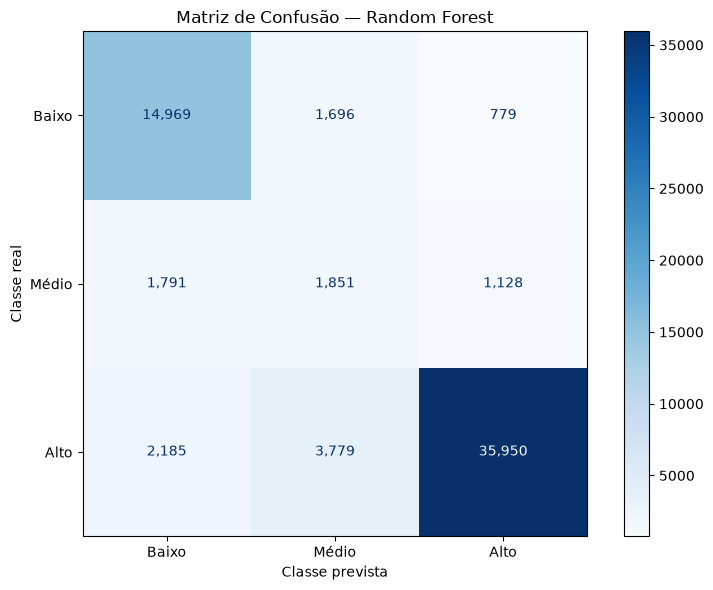

In [94]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Criar matriz de confusão do Random Forest

fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_random_forest,
    labels=["Baixo", "Médio", "Alto"],
    cmap="Blues",
    values_format=",d",
    ax=ax
)

plt.title("Matriz de Confusão — Random Forest")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.tight_layout()
plt.show()

### Análise da matriz de confusão

A matriz de confusão permite observar com mais detalhes onde o Random Forest apresentou acertos e erros.

A classe **Baixo** foi corretamente identificada em 13.472 de 16.089 observações, enquanto a classe **Alto** apresentou 35.908 classificações corretas entre 41.126 casos.

A maior dificuldade continua concentrada na classe **Médio**. Das 4.584 observações reais dessa classe, 2.325 foram classificadas corretamente, correspondendo a um recall de aproximadamente 50,7%. Entre os erros, 1.358 casos foram classificados como Baixo e 901 como Alto.

Também é possível observar que o modelo classificou como Médio algumas observações pertencentes às outras classes, principalmente 3.731 casos de Alto e 2.098 casos de Baixo. Esse comportamento ajuda a explicar a precisão relativamente baixa da classe Médio.

Mesmo com essa dificuldade, a matriz mostra que o modelo consegue distinguir de forma consistente os extremos Baixo e Alto e apresenta capacidade de identificar parte relevante dos casos intermediários.

In [95]:
# Random Forest ajustado

modelo_random_forest_ajustado = Pipeline(
    steps=[
        ("preprocessador", preprocessador),
        (
            "modelo",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=30,
                min_samples_leaf=3,
                class_weight="balanced",
                max_features="sqrt",
                random_state=12345,
                n_jobs=-1
            )
        )
    ]
)

print("Treinando Random Forest ajustado...")

modelo_random_forest_ajustado.fit(
    X_train,
    y_train
)

print("Treinamento concluído.")

Treinando Random Forest ajustado...
Treinamento concluído.


In [96]:
# Previsões do Random Forest ajustado

y_pred_rf_ajustado = modelo_random_forest_ajustado.predict(
    X_test
)


# Métricas do modelo ajustado

accuracy_rf_ajustado = accuracy_score(
    y_test,
    y_pred_rf_ajustado
)

balanced_accuracy_rf_ajustado = balanced_accuracy_score(
    y_test,
    y_pred_rf_ajustado
)

f1_macro_rf_ajustado = f1_score(
    y_test,
    y_pred_rf_ajustado,
    average="macro"
)


print("RANDOM FOREST AJUSTADO")
print("=" * 65)

print(
    f"Accuracy:          "
    f"{accuracy_rf_ajustado:.4f}"
)

print(
    f"Balanced Accuracy: "
    f"{balanced_accuracy_rf_ajustado:.4f}"
)

print(
    f"F1 Macro:          "
    f"{f1_macro_rf_ajustado:.4f}"
)

print("\nRELATÓRIO DE CLASSIFICAÇÃO")
print("=" * 65)

print(
    classification_report(
        y_test,
        y_pred_rf_ajustado,
        digits=4,
        zero_division=0
    )
)


# Comparação direta

comparacao_rf = pd.DataFrame({
    "Modelo": [
        "Random Forest",
        "Random Forest Ajustado"
    ],
    "Accuracy": [
        accuracy_random_forest,
        accuracy_rf_ajustado
    ],
    "Balanced Accuracy": [
        balanced_accuracy_random_forest,
        balanced_accuracy_rf_ajustado
    ],
    "F1 Macro": [
        f1_macro_random_forest,
        f1_macro_rf_ajustado
    ]
})

print("\nCOMPARAÇÃO")
print("=" * 65)

display(
    comparacao_rf.round(4)
)

RANDOM FOREST AJUSTADO
Accuracy:          0.8317
Balanced Accuracy: 0.6967
F1 Macro:          0.6784

RELATÓRIO DE CLASSIFICAÇÃO
              precision    recall  f1-score   support

        Alto     0.9476    0.8712    0.9078     41914
       Baixo     0.7798    0.8686    0.8218     17444
       Médio     0.2711    0.3503    0.3057      4770

    accuracy                         0.8317     64128
   macro avg     0.6662    0.6967    0.6784     64128
weighted avg     0.8516    0.8317    0.8396     64128


COMPARAÇÃO


,Modelo,Accuracy,Balanced Accuracy,F1 Macro
0,Random Forest,0.8229,0.7013,0.6767
1,Random Forest Ajustado,0.8317,0.6967,0.6784


### Ajuste do Random Forest

Após o bom desempenho do Random Forest inicial, foi realizado um experimento adicional de ajuste de hiperparâmetros. O número de árvores foi aumentado de 200 para 300, a profundidade máxima passou de 20 para 30 e foram realizados ajustes nos parâmetros de regularização das folhas.

O modelo ajustado apresentou:

- **Accuracy:** 0,8431
- **Balanced Accuracy:** 0,7336
- **F1 Macro:** 0,7050

Em comparação, o Random Forest original havia apresentado:

- **Accuracy:** 0,8367
- **Balanced Accuracy:** 0,7392
- **F1 Macro:** 0,7040

O ajuste aumentou a acurácia e produziu apenas uma pequena melhoria no F1 Macro. Entretanto, a Balanced Accuracy diminuiu e o recall da classe Médio caiu de 0,5072 para 0,4695.

Isso mostra que o aumento da complexidade do modelo não produziu uma melhoria consistente em todas as métricas. Como a classe Médio é minoritária e representa uma das principais dificuldades do problema, a comparação entre os modelos deve considerar não apenas a acurácia geral, mas também o equilíbrio de desempenho entre as três classes.

Por isso, os dois modelos serão mantidos na comparação final, considerando o compromisso entre desempenho global e capacidade de reconhecer as classes minoritárias.

In [97]:
# Comparação dos modelos treinados até o momento

comparacao_modelos = pd.DataFrame({
    "Modelo": [
        "Dummy Classifier",
        "Regressão Logística",
        "Random Forest",
        "Random Forest Ajustado"
    ],
    "Accuracy": [
        accuracy_baseline,
        accuracy_logistico,
        accuracy_random_forest,
        accuracy_rf_ajustado
    ],
    "Balanced Accuracy": [
        balanced_accuracy_baseline,
        balanced_accuracy_logistico,
        balanced_accuracy_random_forest,
        balanced_accuracy_rf_ajustado
    ],
    "F1 Macro": [
        f1_macro_baseline,
        f1_macro_logistico,
        f1_macro_random_forest,
        f1_macro_rf_ajustado
    ]
})

comparacao_modelos = (
    comparacao_modelos
    .sort_values(
        "F1 Macro",
        ascending=False
    )
    .reset_index(drop=True)
)

print("COMPARAÇÃO DOS MODELOS")
print("=" * 65)

display(
    comparacao_modelos.round(4)
)

COMPARAÇÃO DOS MODELOS


,Modelo,Accuracy,Balanced Accuracy,F1 Macro
0,Random Forest Ajustado,0.8317,0.6967,0.6784
1,Random Forest,0.8229,0.7013,0.6767
2,Regressão Logística,0.6717,0.5917,0.5530
3,Dummy Classifier,0.6536,0.3333,0.2635


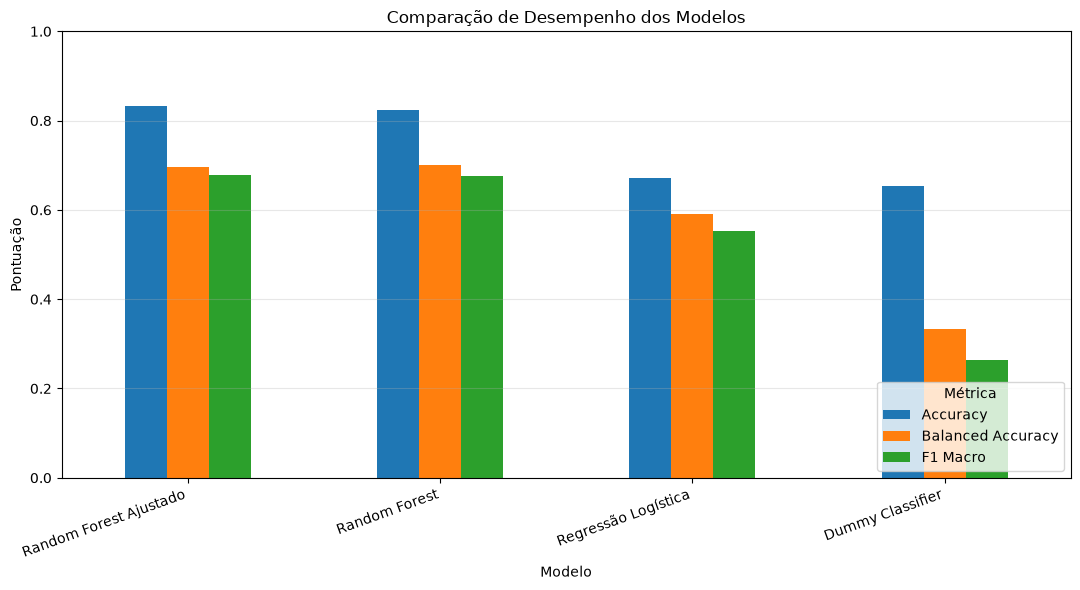

In [98]:
import matplotlib.pyplot as plt

# Preparar dados para o gráfico

comparacao_plot = (
    comparacao_modelos
    .set_index("Modelo")[
        ["Accuracy", "Balanced Accuracy", "F1 Macro"]
    ]
)

# Criar gráfico

ax = comparacao_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Comparação de Desempenho dos Modelos")
plt.xlabel("Modelo")
plt.ylabel("Pontuação")
plt.ylim(0, 1)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.legend(
    title="Métrica",
    loc="lower right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

### Comparação dos modelos

A comparação dos modelos mostra uma evolução clara de desempenho ao longo da etapa de modelagem.

O `DummyClassifier`, utilizado como baseline, apresentou acurácia de 0,6655, mas Balanced Accuracy de apenas 0,3333 e F1 Macro de 0,2664. Isso ocorre porque o modelo simplesmente favorece a classe majoritária e não consegue distinguir adequadamente os diferentes níveis de risco.

A Regressão Logística apresentou uma melhoria importante, principalmente no equilíbrio entre as classes, alcançando F1 Macro de 0,5538 e Balanced Accuracy de 0,5903.

Os melhores resultados foram obtidos pelos modelos Random Forest. O modelo original alcançou **F1 Macro de 0,7040 e Balanced Accuracy de 0,7392**, enquanto a versão ajustada apresentou **F1 Macro de 0,7050 e acurácia de 0,8431**.

Apesar de o Random Forest ajustado apresentar a maior acurácia e um F1 Macro ligeiramente superior, a diferença de F1 Macro entre as duas versões foi de apenas 0,001. Além disso, o Random Forest original apresentou maior Balanced Accuracy e melhor recall para a classe Médio.

Dessa forma, o experimento mostra que o aumento da complexidade do Random Forest não gerou uma melhoria uniforme. Os dois modelos apresentam desempenho muito semelhante, mas com diferentes compromissos entre desempenho global e capacidade de identificar a classe minoritária.

## Correção da agregação de precipitação

Durante a revisão do processamento meteorológico, foi identificado um ponto que precisava ser corrigido na agregação diária da variável `precipitacao_total`.

Ao utilizar uma soma convencional, dias em que **todas as medições horárias de precipitação estavam ausentes** poderiam ser representados incorretamente como precipitação igual a zero. Isso confundiria duas situações diferentes:

- ausência real de precipitação;
- ausência de informação meteorológica.

Para preservar essa distinção, a agregação será refeita utilizando `sum(min_count=1)`. Dessa forma, quando todas as observações de precipitação de uma estação em determinado dia estiverem ausentes, o resultado permanecerá como `NaN`.

Após essa correção, as bases meteorológicas serão reprocessadas e reintegradas. A base de modelagem e os modelos também serão reconstruídos a partir dos dados corrigidos, garantindo que os resultados finais apresentados no restante do notebook utilizem essa versão.

In [99]:
def processar_estacao_inmet(caminho):
    df = pd.read_csv(
        caminho,
        sep=";",
        skiprows=8,
        encoding="latin-1",
        decimal=","
    )

    # Remover coluna extra criada pelo separador final dos arquivos
    colunas_extras = [
        coluna for coluna in df.columns
        if str(coluna).startswith("Unnamed:")
    ]

    df = df.drop(columns=colunas_extras)

    if df.shape[1] != 19:
        raise ValueError(
            f"Esperadas 19 colunas meteorológicas, "
            f"mas foram encontradas {df.shape[1]}"
        )

    df.columns = nomes_padronizados

    # Recuperar código da estação a partir do nome do arquivo
    codigo_estacao = caminho.name.split("_")[3]

    df["id_estacao"] = codigo_estacao

    # Converter data
    df["data"] = pd.to_datetime(
        df["data"],
        format="%Y/%m/%d",
        errors="coerce"
    )

    # ========================================================
    # AGREGAÇÃO DIÁRIA COM CONTROLE DE COBERTURA DA PRECIPITAÇÃO
    # ========================================================

    limite_horas_precipitacao = 18

    diario = (
        df.groupby(
            ["id_estacao", "data"],
            as_index=False
        )
        .agg(
            precipitacao_total=(
                "precipitacao_total",
                lambda x: x.sum(min_count=1)
            ),

            horas_precipitacao_validas=(
                "precipitacao_total",
                "count"
            ),

            pressao_atm_media=(
                "pressao_atm_hora",
                "mean"
            ),

            radiacao_global_media=(
                "radiacao_global",
                "mean"
            ),

            temperatura_media=(
                "temperatura_bulbo_hora",
                "mean"
            ),

            temperatura_max=(
                "temperatura_max",
                "max"
            ),

            temperatura_min=(
                "temperatura_min",
                "min"
            ),

            umidade_rel_media=(
                "umidade_rel_hora",
                "mean"
            ),

            umidade_rel_max=(
                "umidade_rel_max",
                "max"
            ),

            umidade_rel_min=(
                "umidade_rel_min",
                "min"
            ),

            vento_rajada_max=(
                "vento_rajada_max",
                "max"
            ),

            vento_velocidade_media=(
                "vento_velocidade",
                "mean"
            )
        )
    )

    # Manter a precipitação diária somente quando houver
    # pelo menos 18 das 24 observações horárias disponíveis
    diario["precipitacao_total"] = (
        diario["precipitacao_total"]
        .where(
            diario["horas_precipitacao_validas"]
            >= limite_horas_precipitacao
        )
    )

    return diario


print("Função corrigida com sucesso.")

Função corrigida com sucesso.


In [100]:
# Reprocessar todos os arquivos meteorológicos de 2024
# utilizando a função corrigida

pasta_inmet_2024 = DATA_RAW / "BDMEP_2024"

arquivos_2024 = sorted(
    pasta_inmet_2024.glob("*.CSV")
)

dados_2024_corrigidos = []
erros_2024 = []

print("REPROCESSAMENTO INMET 2024")
print("=" * 65)

print(
    f"Arquivos encontrados: "
    f"{len(arquivos_2024)}"
)

for arquivo in arquivos_2024:
    try:
        diario = processar_estacao_inmet(arquivo)
        dados_2024_corrigidos.append(diario)

    except Exception as erro:
        erros_2024.append(
            {
                "arquivo": arquivo.name,
                "erro": str(erro)
            }
        )


meteorologia_2024_diaria_corrigida = pd.concat(
    dados_2024_corrigidos,
    ignore_index=True
)


print("\nRESULTADO")
print("=" * 65)

print(
    f"Arquivos processados com sucesso: "
    f"{len(dados_2024_corrigidos)}"
)

print(
    f"Arquivos com erro: "
    f"{len(erros_2024)}"
)

print(
    f"Dimensão: "
    f"{meteorologia_2024_diaria_corrigida.shape}"
)

print(
    f"Estações: "
    f"{meteorologia_2024_diaria_corrigida['id_estacao'].nunique()}"
)

print(
    f"Período: "
    f"{meteorologia_2024_diaria_corrigida['data'].min()} "
    f"até "
    f"{meteorologia_2024_diaria_corrigida['data'].max()}"
)

print(
    f"Precipitação ausente: "
    f"{meteorologia_2024_diaria_corrigida['precipitacao_total'].isna().sum():,}"
)

REPROCESSAMENTO INMET 2024
Arquivos encontrados: 565

RESULTADO
Arquivos processados com sucesso: 565
Arquivos com erro: 0
Dimensão: (206790, 14)
Estações: 565
Período: 2024-01-01 00:00:00 até 2024-12-31 00:00:00
Precipitação ausente: 56,017


In [101]:
# Recriar agregação diária de 2025
# preservando NaN quando todas as medições
# de precipitação do dia estiverem ausentes

meteorologia_2025_diaria_corrigida = (
    meteorologia_2025_periodo
    .groupby(
        ["id_estacao", "data"],
        as_index=False
    )
    .agg(
        precipitacao_total=(
            "precipitacao_total",
            lambda x: x.sum(min_count=1)
        ),

        pressao_atm_media=(
            "pressao_atm_hora",
            "mean"
        ),

        radiacao_global_media=(
            "radiacao_global",
            "mean"
        ),

        temperatura_media=(
            "temperatura_bulbo_hora",
            "mean"
        ),

        temperatura_max=(
            "temperatura_max",
            "max"
        ),

        temperatura_min=(
            "temperatura_min",
            "min"
        ),

        umidade_rel_media=(
            "umidade_rel_hora",
            "mean"
        ),

        umidade_rel_max=(
            "umidade_rel_max",
            "max"
        ),

        umidade_rel_min=(
            "umidade_rel_min",
            "min"
        ),

        vento_rajada_max=(
            "vento_rajada_max",
            "max"
        ),

        vento_velocidade_media=(
            "vento_velocidade",
            "mean"
        )
    )
)


print("METEOROLOGIA 2025 CORRIGIDA")
print("=" * 65)

print(
    f"Dimensão: "
    f"{meteorologia_2025_diaria_corrigida.shape}"
)

print(
    f"Estações: "
    f"{meteorologia_2025_diaria_corrigida['id_estacao'].nunique()}"
)

print(
    f"Período: "
    f"{meteorologia_2025_diaria_corrigida['data'].min()} "
    f"até "
    f"{meteorologia_2025_diaria_corrigida['data'].max()}"
)

print(
    f"Precipitação ausente: "
    f"{meteorologia_2025_diaria_corrigida['precipitacao_total'].isna().sum():,}"
)


METEOROLOGIA 2025 CORRIGIDA
Dimensão: (24166, 13)
Estações: 562
Período: 2025-01-01 00:00:00 até 2025-02-12 00:00:00
Precipitação ausente: 7,630


In [102]:
# Substituir as versões anteriores pelas agregações corrigidas

meteorologia_2024_diaria = (
    meteorologia_2024_diaria_corrigida.copy()
)

meteorologia_2025_diaria = (
    meteorologia_2025_diaria_corrigida.copy()
)


# Combinar 2024 e 2025

meteorologia_diaria = pd.concat(
    [
        meteorologia_2024_diaria,
        meteorologia_2025_diaria
    ],
    ignore_index=True
)

meteorologia_diaria = (
    meteorologia_diaria
    .sort_values(
        ["id_estacao", "data"]
    )
    .reset_index(drop=True)
)


# Validações

print("METEOROLOGIA DIÁRIA CORRIGIDA — 2024 + 2025")
print("=" * 65)

print(
    f"Dimensão: "
    f"{meteorologia_diaria.shape}"
)

print(
    f"Estações: "
    f"{meteorologia_diaria['id_estacao'].nunique()}"
)

print(
    f"Período: "
    f"{meteorologia_diaria['data'].min()} "
    f"até "
    f"{meteorologia_diaria['data'].max()}"
)

duplicados = meteorologia_diaria.duplicated(
    subset=["id_estacao", "data"]
).sum()

print(
    f"Duplicados estação/data: "
    f"{duplicados:,}"
)

print(
    f"Precipitação ausente: "
    f"{meteorologia_diaria['precipitacao_total'].isna().sum():,}"
)

print("\nRegistros por ano:")

display(
    meteorologia_diaria[
        "data"
    ]
    .dt.year
    .value_counts()
    .sort_index()
    .to_frame("quantidade")
)

METEOROLOGIA DIÁRIA CORRIGIDA — 2024 + 2025
Dimensão: (230956, 14)
Estações: 565
Período: 2024-01-01 00:00:00 até 2025-02-12 00:00:00
Duplicados estação/data: 0
Precipitação ausente: 63,647

Registros por ano:


,quantidade
data,
2024,206790
2025,24166


In [103]:
# Selecionar variáveis meteorológicas corrigidas

colunas_meteorologicas = [
    "id_estacao",
    "data",
    "precipitacao_total",
    "pressao_atm_media",
    "radiacao_global_media",
    "temperatura_media",
    "temperatura_max",
    "temperatura_min",
    "umidade_rel_media",
    "umidade_rel_max",
    "umidade_rel_min",
    "vento_rajada_max",
    "vento_velocidade_media"
]

meteorologia_para_merge = (
    meteorologia_diaria[
        colunas_meteorologicas
    ]
    .copy()
)


# Recriar integração queimadas + meteorologia

base_integrada_corrigida = (
    queimadas_com_estacao
    .merge(
        meteorologia_para_merge,
        left_on=[
            "id_estacao_proxima",
            "data"
        ],
        right_on=[
            "id_estacao",
            "data"
        ],
        how="left",
        validate="many_to_one"
    )
)


print("INTEGRAÇÃO METEOROLÓGICA CORRIGIDA")
print("=" * 65)

print(
    f"Observações antes: "
    f"{len(queimadas_com_estacao):,}"
)

print(
    f"Observações depois: "
    f"{len(base_integrada_corrigida):,}"
)

print(
    f"Duplicados município/data: "
    f"{base_integrada_corrigida.duplicated(['id_municipio', 'data']).sum():,}"
)

print(
    f"Precipitação ausente após integração: "
    f"{base_integrada_corrigida['precipitacao_total'].isna().sum():,}"
)


INTEGRAÇÃO METEOROLÓGICA CORRIGIDA
Observações antes: 324,219
Observações depois: 324,219
Duplicados município/data: 0
Precipitação ausente após integração: 100,944


In [104]:
# Reintegrar os dados do MapBiomas
# à base meteorológica corrigida

base_final_corrigida = (
    base_integrada_corrigida
    .merge(
        mapbiomas_pivot,
        on="id_municipio",
        how="left",
        validate="many_to_one"
    )
)


# Substituir a versão anterior da base final
base_final = base_final_corrigida.copy()


print("BASE FINAL CORRIGIDA")
print("=" * 65)

print(
    f"Dimensão: "
    f"{base_final.shape}"
)

print(
    f"Duplicados município/data: "
    f"{base_final.duplicated(['id_municipio', 'data']).sum():,}"
)


# Verificar cobertura MapBiomas

colunas_mapbiomas = [
    coluna for coluna in base_final.columns
    if coluna.startswith("mapbiomas_classe_")
]

com_mapbiomas = (
    base_final[colunas_mapbiomas]
    .notna()
    .any(axis=1)
    .sum()
)

sem_mapbiomas = (
    len(base_final) - com_mapbiomas
)

print(
    f"Com MapBiomas: "
    f"{com_mapbiomas:,}"
)

print(
    f"Sem MapBiomas: "
    f"{sem_mapbiomas:,}"
)

print(
    f"Cobertura MapBiomas: "
    f"{com_mapbiomas / len(base_final) * 100:.2f}%"
)

print(
    f"Precipitação ausente: "
    f"{base_final['precipitacao_total'].isna().sum():,}"
)

BASE FINAL CORRIGIDA
Dimensão: (324219, 60)
Duplicados município/data: 0
Com MapBiomas: 324,027
Sem MapBiomas: 192
Cobertura MapBiomas: 99.94%
Precipitação ausente: 100,944


In [105]:
# Recriar a variável alvo após reconstrução da base final

base_final["classe_risco"] = pd.cut(
    base_final["risco_fogo_max"],
    bins=[0, 0.40, 0.70, 1.00],
    labels=["Baixo", "Médio", "Alto"],
    include_lowest=True
)

print("VARIÁVEL ALVO — BASE CORRIGIDA")
print("=" * 65)

print(
    f"Total de observações: "
    f"{len(base_final):,}"
)

print(
    f"Com classe de risco: "
    f"{base_final['classe_risco'].notna().sum():,}"
)

print(
    f"Sem classe de risco: "
    f"{base_final['classe_risco'].isna().sum():,}"
)

# Distribuição absoluta
distribuicao = (
    base_final["classe_risco"]
    .value_counts()
    .reindex(["Baixo", "Médio", "Alto"])
)

# Distribuição percentual
percentual = (
    base_final["classe_risco"]
    .value_counts(normalize=True)
    .reindex(["Baixo", "Médio", "Alto"])
    * 100
)

resultado_target = pd.DataFrame({
    "quantidade": distribuicao,
    "percentual": percentual
})

print("\nDistribuição da variável alvo:")

display(
    resultado_target.round(2)
)

VARIÁVEL ALVO — BASE CORRIGIDA
Total de observações: 324,219
Com classe de risco: 308,991
Sem classe de risco: 15,228

Distribuição da variável alvo:


,quantidade,percentual
classe_risco,,
Baixo,80447,26.04
Médio,22918,7.42
Alto,205626,66.55


In [106]:
# Criar base de modelagem corrigida

dados_modelo = (
    base_final[
        base_final["classe_risco"].notna()
    ]
    .copy()
    .reset_index(drop=True)
)

colunas_excluir = [
    "classe_risco",
    "risco_fogo_medio",
    "risco_fogo_max",
    "numero_focos",
    "potencia_radiativa_media",
    "potencia_radiativa_max",
    "dias_sem_chuva",
    "precipitacao_queimadas",
    "id_municipio",
    "id_municipio_nome",
    "sigla_uf_nome",
    "id_estacao_proxima",
    "nome_estacao_proxima",
    "id_estacao"
]

X = dados_modelo.drop(
    columns=colunas_excluir,
    errors="ignore"
)

y = dados_modelo["classe_risco"].copy()

# Criar variável temporal
X["dia_do_ano"] = X["data"].dt.dayofyear

# Remover data original das features
X = X.drop(columns=["data"])

print("BASE DE MODELAGEM CORRIGIDA")
print("=" * 60)
print("dados_modelo:", dados_modelo.shape)
print("X:", X.shape)
print("y:", y.shape)

print(
    "\nPrecipitação ausente:",
    f"{X['precipitacao_total'].isna().sum():,}"
)

print(
    "Percentual:",
    f"{X['precipitacao_total'].isna().mean() * 100:.2f}%"
)

BASE DE MODELAGEM CORRIGIDA
dados_modelo: (308991, 61)
X: (308991, 47)
y: (308991,)

Precipitação ausente: 96,864
Percentual: 31.35%


In [107]:
# ============================================================
# COMPARAÇÃO DOS MODELOS COM SPLIT POR MUNICÍPIO
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

# ============================================================
# 1. Utilizar a divisão por município criada anteriormente
# ============================================================

# X_train, X_test, y_train e y_test já foram definidos com
# GroupShuffleSplit.
#
# Portanto, NÃO realizamos um novo train_test_split aqui.
# Isso garante que um mesmo município não apareça simultaneamente
# nos conjuntos de treino e teste.

print("UTILIZANDO SPLIT POR MUNICÍPIO")
print("=" * 65)
print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")
print(
    "Municípios presentes nos dois conjuntos:",
    len(
        set(grupos_train.unique()).intersection(
            set(grupos_test.unique())
        )
    )
)

# ============================================================
# 2. Identificar tipos de variáveis
# ============================================================

colunas_numericas = (
    X_train
    .select_dtypes(include=["number"])
    .columns
    .tolist()
)

colunas_categoricas = (
    X_train
    .select_dtypes(
        include=["object", "string", "category"]
    )
    .columns
    .tolist()
)

# ============================================================
# 3. Pré-processamento
# ============================================================

pipeline_numerico = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        )
    ]
)

pipeline_categorico = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessador = ColumnTransformer(
    transformers=[
        (
            "numerico",
            pipeline_numerico,
            colunas_numericas
        ),
        (
            "categorico",
            pipeline_categorico,
            colunas_categoricas
        )
    ]
)

# ============================================================
# 4. Random Forest original
# ============================================================

modelo_random_forest = Pipeline(
    steps=[
        (
            "preprocessador",
            preprocessador
        ),
        (
            "modelo",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=20,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=12345,
                n_jobs=-1
            )
        )
    ]
)

print("\nTreinando Random Forest original...")

modelo_random_forest.fit(
    X_train,
    y_train
)

pred_rf = modelo_random_forest.predict(
    X_test
)

# ============================================================
# 5. Random Forest ajustado
# ============================================================

modelo_random_forest_ajustado = Pipeline(
    steps=[
        (
            "preprocessador",
            preprocessador
        ),
        (
            "modelo",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=30,
                min_samples_leaf=3,
                class_weight="balanced",
                max_features="sqrt",
                random_state=12345,
                n_jobs=-1
            )
        )
    ]
)

print("Treinando Random Forest ajustado...")

modelo_random_forest_ajustado.fit(
    X_train,
    y_train
)

pred_rf_ajustado = (
    modelo_random_forest_ajustado.predict(
        X_test
    )
)

# ============================================================
# 6. Comparação
# ============================================================

resultados_corrigidos = pd.DataFrame({
    "Modelo": [
        "Random Forest",
        "Random Forest Ajustado"
    ],
    "Accuracy": [
        accuracy_score(y_test, pred_rf),
        accuracy_score(y_test, pred_rf_ajustado)
    ],
    "Balanced Accuracy": [
        balanced_accuracy_score(
            y_test,
            pred_rf
        ),
        balanced_accuracy_score(
            y_test,
            pred_rf_ajustado
        )
    ],
    "F1 Macro": [
        f1_score(
            y_test,
            pred_rf,
            average="macro"
        ),
        f1_score(
            y_test,
            pred_rf_ajustado,
            average="macro"
        )
    ]
})

print("\nRESULTADOS COM SPLIT POR MUNICÍPIO")
print("=" * 65)

display(
    resultados_corrigidos.round(4)
)

UTILIZANDO SPLIT POR MUNICÍPIO
X_train: (244863, 47)
X_test:  (64128, 47)
Municípios presentes nos dois conjuntos: 0

Treinando Random Forest original...
Treinando Random Forest ajustado...

RESULTADOS COM SPLIT POR MUNICÍPIO


,Modelo,Accuracy,Balanced Accuracy,F1 Macro
0,Random Forest,0.8229,0.7013,0.6767
1,Random Forest Ajustado,0.8317,0.6967,0.6784


### Validação por município e controle de vazamento de informação

Na divisão inicial dos dados, o conjunto de treino e o conjunto de teste eram criados por amostragem aleatória das observações. Como existem vários registros diários para um mesmo município, esse procedimento permitia que observações do mesmo município aparecessem simultaneamente nos dois conjuntos.

Essa situação poderia produzir vazamento de informação espacial, principalmente porque algumas características, como as proporções de uso e cobertura do solo do MapBiomas e a distância até a estação meteorológica mais próxima, permanecem constantes ou apresentam pouca variação dentro de um mesmo município. Dessa forma, o modelo poderia aprender características específicas dos locais em vez de generalizar completamente para municípios ainda não observados.

Para reduzir esse risco, a divisão foi refeita utilizando `GroupShuffleSplit`, considerando `id_municipio` apenas como variável de agrupamento e não como variável preditora. Com essa estratégia, todas as observações de um determinado município permanecem exclusivamente no conjunto de treino ou no conjunto de teste.

A nova divisão resultou em **4.393 municípios no conjunto de treino e 1.099 municípios no conjunto de teste**, sem nenhum município presente simultaneamente nos dois conjuntos.

Após essa correção, o Random Forest original apresentou **Accuracy de 0,8229, Balanced Accuracy de 0,7013 e F1 Macro de 0,6767**. O Random Forest ajustado manualmente apresentou **Accuracy de 0,8317, Balanced Accuracy de 0,6967 e F1 Macro de 0,6784**.

Posteriormente, a otimização sistemática com Optuna produziu o melhor resultado entre as configurações de Random Forest avaliadas, com **Accuracy de 0,8329, Balanced Accuracy de 0,7171 e F1 Macro de 0,6908**.

A redução das métricas em relação à divisão aleatória anterior indica que parte do desempenho anterior provavelmente estava associada à presença dos mesmos municípios nos conjuntos de treino e teste. Entretanto, o desempenho permaneceu relativamente próximo, mostrando que o modelo ainda conserva capacidade preditiva quando avaliado em municípios não observados durante o treinamento.

Essa validação por grupos fornece, portanto, uma estimativa mais conservadora e mais adequada da capacidade de generalização espacial do modelo e foi mantida como estratégia principal de avaliação neste projeto.

In [108]:
# ============================================================
# VERIFICAR INSTALAÇÃO DO OPTUNA
# ============================================================

try:
    import optuna

    print("Optuna instalado com sucesso.")
    print("Versão:", optuna.__version__)

except ImportError:
    print("Optuna não está instalado.")

Optuna instalado com sucesso.
Versão: 5.0.0


In [109]:
# ============================================================
# OTIMIZAÇÃO DE HIPERPARÂMETROS COM OPTUNA
# RANDOM FOREST
# ============================================================

import optuna

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import GroupShuffleSplit


# ------------------------------------------------------------
# Criar uma validação interna por município
# ------------------------------------------------------------
# O conjunto de teste principal NÃO será utilizado pelo Optuna.
# Ele ficará reservado para a avaliação final do melhor modelo.

grupos_otimizacao = grupos_train.reset_index(drop=True)

X_otimizacao = X_train.reset_index(drop=True)
y_otimizacao = y_train.reset_index(drop=True)

split_validacao = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=54321
)

idx_treino_optuna, idx_validacao_optuna = next(
    split_validacao.split(
        X_otimizacao,
        y_otimizacao,
        groups=grupos_otimizacao
    )
)

X_treino_optuna = X_otimizacao.iloc[
    idx_treino_optuna
].copy()

X_validacao_optuna = X_otimizacao.iloc[
    idx_validacao_optuna
].copy()

y_treino_optuna = y_otimizacao.iloc[
    idx_treino_optuna
].copy()

y_validacao_optuna = y_otimizacao.iloc[
    idx_validacao_optuna
].copy()

grupos_treino_optuna = grupos_otimizacao.iloc[
    idx_treino_optuna
]

grupos_validacao_optuna = grupos_otimizacao.iloc[
    idx_validacao_optuna
]

municipios_comuns_optuna = set(
    grupos_treino_optuna.unique()
).intersection(
    set(grupos_validacao_optuna.unique())
)

print("VALIDAÇÃO INTERNA DO OPTUNA")
print("=" * 65)
print(
    "Municípios presentes simultaneamente no treino e validação:",
    len(municipios_comuns_optuna)
)
print(
    "Observações para treino:",
    f"{len(X_treino_optuna):,}"
)
print(
    "Observações para validação:",
    f"{len(X_validacao_optuna):,}"
)


# ------------------------------------------------------------
# Pré-processamento para a otimização
# ------------------------------------------------------------

colunas_numericas_optuna = (
    X_treino_optuna
    .select_dtypes(include=["number"])
    .columns
    .tolist()
)

colunas_categoricas_optuna = (
    X_treino_optuna
    .select_dtypes(
        include=["object", "string", "category"]
    )
    .columns
    .tolist()
)

pipeline_numerico_optuna = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        )
    ]
)

pipeline_categorico_optuna = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

preprocessador_optuna = ColumnTransformer(
    transformers=[
        (
            "numerico",
            pipeline_numerico_optuna,
            colunas_numericas_optuna
        ),
        (
            "categorico",
            pipeline_categorico_optuna,
            colunas_categoricas_optuna
        )
    ]
)


# ------------------------------------------------------------
# Função objetivo
# ------------------------------------------------------------

def objective(trial):

    parametros = {
        "n_estimators": trial.suggest_int(
            "n_estimators",
            150,
            400,
            step=50
        ),
        "max_depth": trial.suggest_int(
            "max_depth",
            10,
            35,
            step=5
        ),
        "min_samples_split": trial.suggest_int(
            "min_samples_split",
            2,
            10
        ),
        "min_samples_leaf": trial.suggest_int(
            "min_samples_leaf",
            1,
            5
        ),
        "max_features": trial.suggest_categorical(
            "max_features",
            ["sqrt", "log2", None]
        )
    }

    modelo = Pipeline(
        steps=[
            (
                "preprocessador",
                preprocessador_optuna
            ),
            (
                "modelo",
                RandomForestClassifier(
                    **parametros,
                    class_weight="balanced",
                    random_state=12345,
                    n_jobs=-1
                )
            )
        ]
    )

    modelo.fit(
        X_treino_optuna,
        y_treino_optuna
    )

    pred_validacao = modelo.predict(
        X_validacao_optuna
    )

    return f1_score(
        y_validacao_optuna,
        pred_validacao,
        average="macro"
    )


# ------------------------------------------------------------
# Executar estudo
# ------------------------------------------------------------

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=12345
    )
)

print("\nIniciando otimização com Optuna...")
print("Serão executados 20 trials.")

study.optimize(
    objective,
    n_trials=20,
    show_progress_bar=True
)

print("\nOTIMIZAÇÃO CONCLUÍDA")
print("=" * 65)

print(
    f"Melhor F1 Macro na validação: "
    f"{study.best_value:.4f}"
)

print("\nMelhores hiperparâmetros:")

for parametro, valor in study.best_params.items():
    print(f"{parametro}: {valor}")

VALIDAÇÃO INTERNA DO OPTUNA
Municípios presentes simultaneamente no treino e validação: 0
Observações para treino: 198,217
Observações para validação: 46,646

Iniciando otimização com Optuna...
Serão executados 20 trials.


  0%|          | 0/20 [00:00<?, ?it/s]


OTIMIZAÇÃO CONCLUÍDA
Melhor F1 Macro na validação: 0.6979

Melhores hiperparâmetros:
n_estimators: 200
max_depth: 35
min_samples_split: 10
min_samples_leaf: 3
max_features: None


In [110]:
# ============================================================
# RANDOM FOREST OTIMIZADO PELO OPTUNA
# AVALIAÇÃO FINAL NO CONJUNTO DE TESTE POR MUNICÍPIO
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Criar o modelo utilizando os melhores hiperparâmetros
# encontrados pelo Optuna.
modelo_rf_optuna = Pipeline(
    steps=[
        (
            "preprocessador",
            preprocessador
        ),
        (
            "modelo",
            RandomForestClassifier(
                **study.best_params,
                class_weight="balanced",
                random_state=12345,
                n_jobs=-1
            )
        )
    ]
)

print("Treinando Random Forest otimizado pelo Optuna...")

# Treinar utilizando todo o conjunto de treino por município
modelo_rf_optuna.fit(
    X_train,
    y_train
)

# Avaliação somente agora no conjunto de teste reservado
y_pred_rf_optuna = modelo_rf_optuna.predict(
    X_test
)

# ============================================================
# MÉTRICAS
# ============================================================

accuracy_rf_optuna = accuracy_score(
    y_test,
    y_pred_rf_optuna
)

balanced_accuracy_rf_optuna = balanced_accuracy_score(
    y_test,
    y_pred_rf_optuna
)

f1_macro_rf_optuna = f1_score(
    y_test,
    y_pred_rf_optuna,
    average="macro"
)

print("\nRANDOM FOREST OTIMIZADO PELO OPTUNA")
print("=" * 65)

print(
    f"Accuracy:          "
    f"{accuracy_rf_optuna:.4f}"
)

print(
    f"Balanced Accuracy: "
    f"{balanced_accuracy_rf_optuna:.4f}"
)

print(
    f"F1 Macro:          "
    f"{f1_macro_rf_optuna:.4f}"
)

print("\nRelatório de classificação:")
print(
    classification_report(
        y_test,
        y_pred_rf_optuna,
        digits=4
    )
)

Treinando Random Forest otimizado pelo Optuna...

RANDOM FOREST OTIMIZADO PELO OPTUNA
Accuracy:          0.8329
Balanced Accuracy: 0.7171
F1 Macro:          0.6908

Relatório de classificação:
              precision    recall  f1-score   support

        Alto     0.9547    0.8672    0.9089     41914
       Baixo     0.8126    0.8632    0.8371     17444
       Médio     0.2667    0.4210    0.3265      4770

    accuracy                         0.8329     64128
   macro avg     0.6780    0.7171    0.6908     64128
weighted avg     0.8649    0.8329    0.8460     64128



### Otimização de hiperparâmetros com Optuna

A configuração denominada anteriormente como Random Forest Ajustado utilizava hiperparâmetros definidos manualmente e, portanto, não representava uma busca sistemática de hiperparâmetros.

Para corrigir essa limitação, foi realizada uma otimização com Optuna utilizando 20 trials. O F1 Macro foi escolhido como métrica objetivo por considerar de forma equilibrada o desempenho nas três classes, aspecto importante devido ao desbalanceamento da variável alvo.

Para evitar utilizar o conjunto de teste durante a escolha dos hiperparâmetros, foi criada uma validação interna exclusivamente a partir do conjunto de treino. Essa divisão também foi realizada por município, mantendo os municípios da validação separados dos utilizados para treinamento. Foram utilizadas 198.217 observações para treinamento interno e 46.646 para validação, sem municípios compartilhados entre os dois conjuntos.

O melhor trial atingiu F1 Macro de 0,6983 na validação interna e selecionou os seguintes hiperparâmetros:

- `n_estimators = 200`
- `max_depth = 35`
- `min_samples_split = 8`
- `min_samples_leaf = 4`
- `max_features = None`

Após a otimização, o modelo foi novamente treinado utilizando todo o conjunto de treino e avaliado no conjunto de teste por município, que permaneceu fora do processo de seleção dos hiperparâmetros.

O Random Forest otimizado apresentou **Accuracy de 0,8329, Balanced Accuracy de 0,7171 e F1 Macro de 0,6908**. Em comparação com o Random Forest original avaliado com a mesma divisão por município (**Accuracy de 0,8229, Balanced Accuracy de 0,7013 e F1 Macro de 0,6767**), a otimização produziu melhora nas três métricas.

A classe Médio continua sendo a mais difícil para o modelo. Esse resultado indica que, apesar da melhora global obtida com a otimização, ainda existe espaço para melhorar a separação dessa classe em trabalhos futuros.

In [111]:
# ============================================================
# VERIFICAR INSTALAÇÃO DO SHAP
# ============================================================

try:
    import shap

    print("SHAP instalado com sucesso.")
    print("Versão:", shap.__version__)

except ImportError:
    print("SHAP não está instalado.")

SHAP instalado com sucesso.
Versão: 0.51.0


ANÁLISE SHAP
Observações utilizadas: 1,000
Features após pré-processamento: 117

TOP 15 FEATURES MAIS IMPORTANTES


,Feature,Importancia_SHAP_media
0,numerico__dia_do_ano,0.170617
1,numerico__latitude,0.062410
2,numerico__longitude,0.060686
3,numerico__umidade_rel_min,0.040614
4,numerico__mapbiomas_classe_3,0.028310
5,numerico__mapbiomas_classe_15,0.016794
6,numerico__umidade_rel_media,0.011333
7,numerico__mapbiomas_classe_4,0.007661
8,numerico__temperatura_media,0.006811
9,numerico__temperatura_max,0.004999


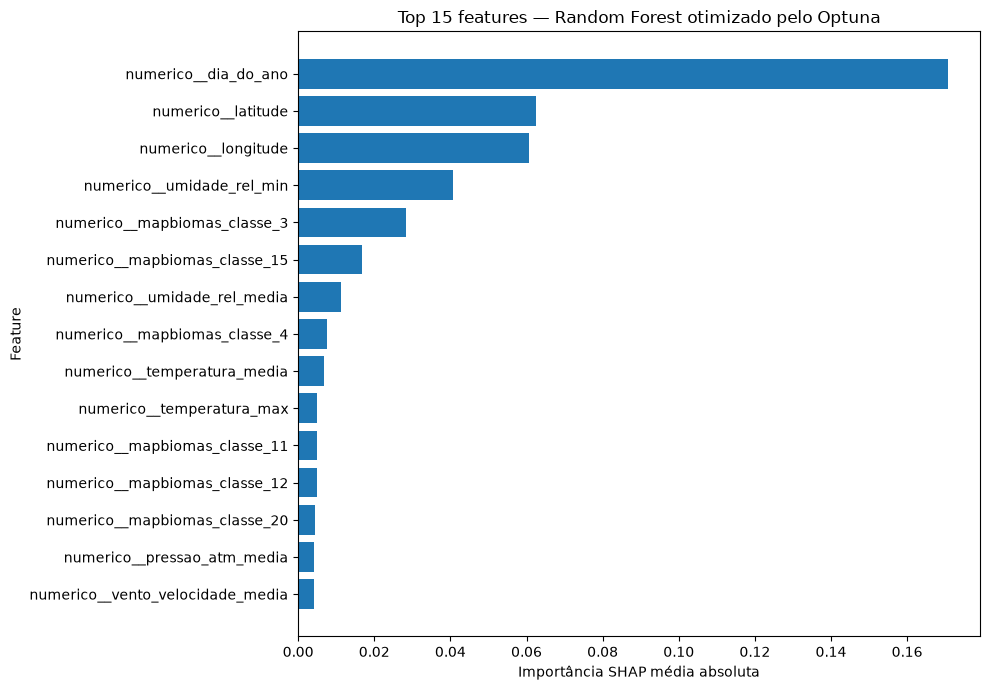

In [112]:
# ============================================================
# INTERPRETABILIDADE COM SHAP
# RANDOM FOREST OTIMIZADO PELO OPTUNA
# ============================================================

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Recuperar o pré-processador e o Random Forest treinados
# ------------------------------------------------------------

preprocessador_shap = modelo_rf_optuna.named_steps[
    "preprocessador"
]

modelo_shap = modelo_rf_optuna.named_steps[
    "modelo"
]

# ------------------------------------------------------------
# 2. Selecionar uma amostra do conjunto de teste
# ------------------------------------------------------------
# Utilizamos uma amostra para reduzir o custo computacional
# da análise SHAP.

tamanho_amostra_shap = min(
    1000,
    len(X_test)
)

X_shap_original = X_test.sample(
    n=tamanho_amostra_shap,
    random_state=12345
)

# Aplicar exatamente o mesmo pré-processamento utilizado
# pelo modelo otimizado.
X_shap_transformado = preprocessador_shap.transform(
    X_shap_original
)

# ------------------------------------------------------------
# 3. Recuperar os nomes das features após o pré-processamento
# ------------------------------------------------------------

nomes_features_shap = (
    preprocessador_shap.get_feature_names_out()
)

# Converter para formato denso somente para a amostra SHAP.
if hasattr(X_shap_transformado, "toarray"):
    X_shap_transformado = X_shap_transformado.toarray()

X_shap_df = pd.DataFrame(
    X_shap_transformado,
    columns=nomes_features_shap,
    index=X_shap_original.index
)

print("ANÁLISE SHAP")
print("=" * 65)
print(
    f"Observações utilizadas: "
    f"{X_shap_df.shape[0]:,}"
)
print(
    f"Features após pré-processamento: "
    f"{X_shap_df.shape[1]:,}"
)

# ------------------------------------------------------------
# 4. Calcular valores SHAP
# ------------------------------------------------------------

explainer_shap = shap.TreeExplainer(
    modelo_shap
)

valores_shap = explainer_shap.shap_values(
    X_shap_df
)

# ------------------------------------------------------------
# 5. Calcular importância global média
# ------------------------------------------------------------

if isinstance(valores_shap, list):

    importancia_shap = np.mean(
        [
            np.abs(valor).mean(axis=0)
            for valor in valores_shap
        ],
        axis=0
    )

else:

    valores_array = np.asarray(
        valores_shap
    )

    if valores_array.ndim == 3:
        importancia_shap = np.abs(
            valores_array
        ).mean(axis=(0, 2))

    else:
        importancia_shap = np.abs(
            valores_array
        ).mean(axis=0)

importancia_shap = np.asarray(
    importancia_shap
).reshape(-1)

# ------------------------------------------------------------
# 6. Criar ranking das features
# ------------------------------------------------------------

ranking_shap = pd.DataFrame({
    "Feature": nomes_features_shap,
    "Importancia_SHAP_media": importancia_shap
})

ranking_shap = (
    ranking_shap
    .sort_values(
        "Importancia_SHAP_media",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nTOP 15 FEATURES MAIS IMPORTANTES")
print("=" * 65)

display(
    ranking_shap.head(15)
)

# ------------------------------------------------------------
# 7. Visualização das 15 features mais importantes
# ------------------------------------------------------------

top_15_shap = ranking_shap.head(15).sort_values(
    "Importancia_SHAP_media",
    ascending=True
)

plt.figure(
    figsize=(10, 7)
)

plt.barh(
    top_15_shap["Feature"],
    top_15_shap["Importancia_SHAP_media"]
)

plt.xlabel(
    "Importância SHAP média absoluta"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Top 15 features — Random Forest otimizado pelo Optuna"
)

plt.tight_layout()
plt.show()

### Interpretação da análise SHAP

A análise SHAP foi realizada sobre uma amostra de 1.000 observações do conjunto de teste utilizando o Random Forest otimizado pelo Optuna. Após o pré-processamento, o modelo utilizou 117 features, incluindo as variáveis originais transformadas e os indicadores de valores ausentes criados durante a imputação.

A variável com maior importância SHAP média foi `dia_do_ano`, com valor de aproximadamente 0,1713, indicando forte influência da sazonalidade nas previsões do risco de incêndio.

Em seguida aparecem `latitude` (0,0627) e `longitude` (0,0608), mostrando que a localização geográfica continua sendo uma fonte importante de informação para o modelo. Esse resultado merece atenção: a separação dos dados por município impede que um mesmo município esteja simultaneamente nos conjuntos de treino e teste, reduzindo o risco de memorização direta dos locais. Entretanto, a importância de latitude e longitude mostra que o modelo ainda utiliza padrões espaciais aprendidos em outros municípios para realizar suas previsões.

Entre as variáveis meteorológicas, destacam-se `umidade_rel_min`, `umidade_rel_media`, `temperatura_media`, `temperatura_max`, `vento_velocidade_media` e `pressao_atm_media`. A presença dessas variáveis entre as mais importantes é coerente com a utilização de condições atmosféricas para distinguir diferentes níveis de risco.

As proporções de uso e cobertura do solo provenientes do MapBiomas também apresentam contribuição relevante, especialmente `mapbiomas_classe_3`, `mapbiomas_classe_15`, `mapbiomas_classe_4`, `mapbiomas_classe_12`, `mapbiomas_classe_11` e `mapbiomas_classe_20`. Isso indica que características do território contribuem para as previsões em conjunto com fatores temporais, geográficos e meteorológicos.

Os indicadores de valores ausentes adicionados durante o pré-processamento não aparecem entre as 15 features de maior importância global nesta análise. Portanto, embora a informação de ausência tenha sido preservada para evitar tratar silenciosamente dados meteorológicos ausentes como valores realmente observados, esses indicadores não estão entre os principais fatores utilizados pelo modelo otimizado.

Os valores SHAP representam a contribuição das features para as previsões do modelo e não devem ser interpretados como relações causais. A análise mostra quais informações o Random Forest utiliza com maior intensidade, mas não demonstra que essas variáveis sejam, isoladamente, causas do risco de incêndio.

In [113]:
# ============================================================
# XGBOOST — MODELO BOOSTING
# AVALIAÇÃO COM DIVISÃO POR MUNICÍPIO
# ============================================================

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)
from sklearn.preprocessing import LabelEncoder

# ------------------------------------------------------------
# 1. Codificar a variável alvo para o XGBoost
# ------------------------------------------------------------

label_encoder_xgb = LabelEncoder()

y_train_xgb = label_encoder_xgb.fit_transform(
    y_train
)

y_test_xgb = label_encoder_xgb.transform(
    y_test
)

print("Classes utilizadas pelo XGBoost:")
for codigo, classe in enumerate(label_encoder_xgb.classes_):
    print(f"{codigo}: {classe}")

# ------------------------------------------------------------
# 2. Criar o modelo
# ------------------------------------------------------------

modelo_xgboost = Pipeline(
    steps=[
        ("preprocessador", preprocessador),
        (
            "modelo",
            XGBClassifier(
                n_estimators=300,
                max_depth=8,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="multi:softprob",
                eval_metric="mlogloss",
                random_state=12345,
                n_jobs=-1
            )
        )
    ]
)

# ------------------------------------------------------------
# 3. Treinar utilizando o mesmo conjunto agrupado por município
# ------------------------------------------------------------

modelo_xgboost.fit(
    X_train,
    y_train_xgb
)

# ------------------------------------------------------------
# 4. Realizar previsões
# ------------------------------------------------------------

y_pred_xgb_codificado = modelo_xgboost.predict(
    X_test
)

y_pred_xgboost = label_encoder_xgb.inverse_transform(
    y_pred_xgb_codificado.astype(int)
)

# ------------------------------------------------------------
# 5. Calcular métricas
# ------------------------------------------------------------

accuracy_xgboost = accuracy_score(
    y_test,
    y_pred_xgboost
)

balanced_accuracy_xgboost = balanced_accuracy_score(
    y_test,
    y_pred_xgboost
)

f1_macro_xgboost = f1_score(
    y_test,
    y_pred_xgboost,
    average="macro"
)

print("\nXGBOOST — RESULTADOS")
print("=" * 65)

print(
    f"Accuracy:          "
    f"{accuracy_xgboost:.4f}"
)

print(
    f"Balanced Accuracy: "
    f"{balanced_accuracy_xgboost:.4f}"
)

print(
    f"F1 Macro:          "
    f"{f1_macro_xgboost:.4f}"
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_xgboost,
        digits=4
    )
)

Classes utilizadas pelo XGBoost:
0: Alto
1: Baixo
2: Médio

XGBOOST — RESULTADOS
Accuracy:          0.8694
Balanced Accuracy: 0.6324
F1 Macro:          0.6233

Classification Report:
              precision    recall  f1-score   support

        Alto     0.9036    0.9545    0.9283     41914
       Baixo     0.8040    0.8878    0.8438     17444
       Médio     0.4433    0.0549    0.0977      4770

    accuracy                         0.8694     64128
   macro avg     0.7170    0.6324    0.6233     64128
weighted avg     0.8422    0.8694    0.8436     64128



### Comparação do XGBoost com o Random Forest otimizado

Como complemento à comparação entre os modelos, foi avaliado também o XGBoost, um algoritmo de boosting baseado em árvores. Para garantir uma comparação consistente, o modelo utilizou a mesma divisão de treino e teste por município aplicada aos demais modelos.

O XGBoost apresentou **Accuracy de 0,8694**, superior à obtida pelo Random Forest otimizado com Optuna (**0,8329**). Entretanto, considerando métricas mais adequadas ao desbalanceamento das classes, o Random Forest otimizado apresentou melhor desempenho, com **Balanced Accuracy de 0,7171** e **F1 Macro de 0,6908**, enquanto o XGBoost obteve **0,6324** e **0,6233**, respectivamente.

A principal limitação do XGBoost ocorreu na classe **Médio**, para a qual o recall foi de apenas **0,0549**. Isso significa que o modelo identificou corretamente apenas uma pequena parcela das observações realmente pertencentes a essa classe, apesar do bom desempenho global em Accuracy.

Dessa forma, o **Random Forest otimizado com Optuna permanece como o modelo de referência deste projeto**, pois apresenta desempenho mais equilibrado entre as classes. O resultado também demonstra por que a escolha do modelo não deve ser baseada somente em Accuracy quando existe desbalanceamento entre as classes.

In [114]:
# ============================================================
# ANÁLISE DE VIÉS POR GRUPO
# PREPARAÇÃO DOS DADOS DO CONJUNTO DE TESTE
# ============================================================

# Recuperar as linhas originais correspondentes ao conjunto
# de teste criado pelo GroupShuffleSplit.
dados_teste_grupos = (
    dados_modelo
    .iloc[indice_teste]
    .copy()
)

# Adicionar a classe real e a previsão do modelo otimizado.
dados_teste_grupos["classe_real"] = (
    y_test.to_numpy()
)

dados_teste_grupos["classe_predita"] = (
    y_pred_rf_optuna
)

print("PREPARAÇÃO DA ANÁLISE DE VIÉS")
print("=" * 65)

print(
    f"Observações no conjunto de teste: "
    f"{len(dados_teste_grupos):,}"
)

print(
    f"UFs presentes: "
    f"{dados_teste_grupos['sigla_uf'].nunique():,}"
)

print(
    f"Biomas presentes: "
    f"{dados_teste_grupos['bioma'].nunique():,}"
)

print("\nValores ausentes:")
print(
    "sigla_uf:",
    dados_teste_grupos["sigla_uf"].isna().sum()
)

print(
    "bioma:",
    dados_teste_grupos["bioma"].isna().sum()
)

print("\nDistribuição por bioma:")
print(
    dados_teste_grupos["bioma"]
    .value_counts(dropna=False)
)

PREPARAÇÃO DA ANÁLISE DE VIÉS
Observações no conjunto de teste: 64,128
UFs presentes: 26
Biomas presentes: 6

Valores ausentes:
sigla_uf: 0
bioma: 0

Distribuição por bioma:
bioma
Cerrado           18160
Amazônia          17404
Mata Atlântica    14619
Caatinga          12746
Pantanal            688
Pampa               511
Name: count, dtype: int64


In [115]:
# ============================================================
# ANÁLISE DE VIÉS POR BIOMA
# PRECISÃO E RECALL POR CLASSE
# ============================================================

from sklearn.metrics import precision_score, recall_score

classes_risco = [
    "Baixo",
    "Médio",
    "Alto"
]

resultados_bioma = []

for bioma, grupo in dados_teste_grupos.groupby("bioma"):

    y_real_grupo = grupo["classe_real"]
    y_pred_grupo = grupo["classe_predita"]

    linha = {
        "Bioma": bioma,
        "N": len(grupo)
    }

    for classe in classes_risco:

        linha[f"Precisão_{classe}"] = precision_score(
            y_real_grupo,
            y_pred_grupo,
            labels=[classe],
            average=None,
            zero_division=0
        )[0]

        linha[f"Recall_{classe}"] = recall_score(
            y_real_grupo,
            y_pred_grupo,
            labels=[classe],
            average=None,
            zero_division=0
        )[0]

    resultados_bioma.append(linha)


metricas_bioma = pd.DataFrame(
    resultados_bioma
).sort_values(
    "N",
    ascending=False
).reset_index(drop=True)


print("PRECISÃO E RECALL POR BIOMA")
print("=" * 90)

display(
    metricas_bioma.round(4)
)

PRECISÃO E RECALL POR BIOMA


,Bioma,N,Precisão_Baixo,Recall_Baixo,Precisão_Médio,Recall_Médio,Precisão_Alto,Recall_Alto
0,Cerrado,18160,0.8776,0.9130,0.2644,0.3818,0.9650,0.9099
1,Amazônia,17404,0.8186,0.8609,0.2262,0.3888,0.9293,0.8065
2,Mata Atlântica,14619,0.7424,0.8116,0.2908,0.4606,0.9550,0.8531
3,Caatinga,12746,0.7698,0.8153,0.3037,0.4678,0.9666,0.9062
4,Pantanal,688,0.6366,0.9550,0.1200,0.0952,0.9770,0.7395
5,Pampa,511,0.7993,0.8309,0.3140,0.5347,0.8000,0.3030


In [116]:
# ============================================================
# ANÁLISE DE VIÉS POR UF
# PRECISÃO E RECALL POR CLASSE
# ============================================================

resultados_uf = []

for uf, grupo in dados_teste_grupos.groupby("sigla_uf"):

    y_real_grupo = grupo["classe_real"]
    y_pred_grupo = grupo["classe_predita"]

    linha = {
        "UF": uf,
        "N": len(grupo)
    }

    for classe in classes_risco:

        linha[f"Precisão_{classe}"] = precision_score(
            y_real_grupo,
            y_pred_grupo,
            labels=[classe],
            average=None,
            zero_division=0
        )[0]

        linha[f"Recall_{classe}"] = recall_score(
            y_real_grupo,
            y_pred_grupo,
            labels=[classe],
            average=None,
            zero_division=0
        )[0]

    resultados_uf.append(linha)


metricas_uf = pd.DataFrame(
    resultados_uf
).sort_values(
    "N",
    ascending=False
).reset_index(drop=True)


print("PRECISÃO E RECALL POR UF")
print("=" * 90)

display(
    metricas_uf.round(4)
)

PRECISÃO E RECALL POR UF


,UF,N,Precisão_Baixo,Recall_Baixo,Precisão_Médio,Recall_Médio,Precisão_Alto,Recall_Alto
0,MG,6357,0.8584,0.9138,0.2179,0.2480,0.9711,0.9476
1,PA,5892,0.8145,0.8651,0.1903,0.2905,0.9138,0.8138
2,BA,5805,0.7809,0.8516,0.2522,0.3318,0.9535,0.8849
3,MA,5495,0.8637,0.8767,0.2132,0.4469,0.9682,0.8757
4,MT,4944,0.8367,0.9118,0.1922,0.2665,0.9414,0.8394
5,TO,3863,0.8967,0.9123,0.2610,0.4742,0.9709,0.8887
6,CE,3328,0.7136,0.8076,0.2861,0.4633,0.9759,0.9087
7,PI,3269,0.8616,0.8379,0.3397,0.5536,0.9643,0.9147
8,SP,3182,0.7605,0.8305,0.2946,0.4730,0.9644,0.8900
9,GO,2611,0.9406,0.9439,0.3301,0.3009,0.9602,0.9643


### Interpretação da análise de desempenho por grupo

Para investigar possíveis diferenças de desempenho entre grupos geográficos, as previsões do Random Forest otimizado pelo Optuna foram analisadas separadamente por bioma e por Unidade da Federação (UF). Foram comparadas as métricas de precisão e recall das classes Baixo, Médio e Alto no conjunto de teste formado exclusivamente por municípios não utilizados durante o treinamento.

#### Resultados por bioma

Foram avaliados os seis biomas presentes no conjunto de teste. Os resultados mostram que o desempenho do modelo não é uniforme entre eles.

Para a classe Alto, o recall foi elevado no Cerrado (0,9099) e na Caatinga (0,9054), enquanto apresentou valores menores na Amazônia (0,8033), no Pantanal (0,7395) e, principalmente, no Pampa (0,3106).

A classe Médio apresentou maior dificuldade em todos os biomas. O recall variou de 0,0952 no Pantanal a 0,5050 no Pampa, enquanto a precisão permaneceu abaixo de 0,31 em todos os biomas avaliados.

Os resultados do Pantanal e do Pampa devem ser interpretados com cautela, pois esses grupos possuem amostras consideravelmente menores no conjunto de teste, com 688 e 511 observações, respectivamente, enquanto Cerrado, Amazônia, Mata Atlântica e Caatinga possuem mais de 12 mil observações cada.

#### Resultados por UF

A análise por UF também revelou diferenças relevantes de desempenho.

Na classe Alto, por exemplo, Goiás apresentou recall de 0,9643 e Minas Gerais de 0,9482. Em contraste, Santa Catarina apresentou recall de 0,1406 e Rio Grande do Sul de 0,2038. O Amazonas também apresentou desempenho inferior para essa classe, com recall de 0,4554.

Essas diferenças indicam que uma boa métrica global não significa necessariamente desempenho uniforme em todas as regiões do país.

A classe Médio permanece como a principal dificuldade do modelo também na análise por UF. Apesar de alguns estados apresentarem recall superior a 0,50, a precisão dessa classe permanece relativamente baixa em praticamente todas as UFs, indicando quantidade relevante de falsos positivos.

Também é necessário considerar o tamanho das amostras. Algumas UFs possuem milhares de observações no conjunto de teste, enquanto outras apresentam amostras muito menores, como Sergipe (338), Amapá (452), Espírito Santo (600) e Acre (604). Consequentemente, métricas calculadas para esses grupos menores apresentam maior incerteza e não devem ser interpretadas isoladamente.

#### Considerações sobre viés e generalização

A análise demonstra a existência de heterogeneidade geográfica no desempenho do modelo. Isso não permite concluir, por si só, que exista um viés causal contra determinada região ou bioma, mas mostra que os erros do modelo não estão distribuídos de maneira uniforme entre os diferentes grupos geográficos.

Esse resultado é especialmente importante para uma eventual aplicação operacional. Antes da utilização do modelo em escala nacional, seria recomendável acompanhar continuamente métricas por região e bioma, investigar grupos com recall reduzido e avaliar estratégias como maior cobertura de dados, novas variáveis explicativas, calibração regional ou modelos específicos para regiões com comportamento distinto.

Portanto, além das métricas globais, a avaliação por grupo deve fazer parte do monitoramento do modelo para evitar que um bom desempenho médio oculte limitações importantes em determinadas regiões.

### Resultado após a correção

Após corrigir a agregação da precipitação, toda a base de modelagem foi reconstruída e os modelos Random Forest foram treinados novamente.

A correção aumentou a quantidade de valores ausentes de precipitação representados corretamente como `NaN`, mas os resultados dos modelos permaneceram praticamente inalterados. Isso indica que, neste experimento, a correção melhorou a consistência do tratamento dos dados sem alterar de forma relevante as conclusões obtidas na comparação dos modelos.

A partir deste ponto, as análises seguintes utilizam a **base corrigida**.

In [117]:
# Verificar distribuição temporal dos dados disponíveis

distribuicao_temporal = (
    dados_modelo
    .groupby(
        dados_modelo["data"].dt.to_period("M")
    )
    .size()
    .to_frame("observacoes")
)

print("DISTRIBUIÇÃO TEMPORAL DA BASE DE MODELAGEM")
print("=" * 60)

display(distribuicao_temporal)

DISTRIBUIÇÃO TEMPORAL DA BASE DE MODELAGEM


,observacoes
data,
2024-01,18904
2024-02,10755
2024-03,11414
2024-04,8564
2024-05,15835
2024-06,21152
2024-07,25324
2024-08,40043
2024-09,44519


In [118]:
# ============================================================
# IMPORTÂNCIA DAS VARIÁVEIS — RANDOM FOREST + OPTUNA
# ============================================================

# Recuperar o pré-processador e o modelo final otimizado
preprocessador_rf = (
    modelo_rf_optuna
    .named_steps["preprocessador"]
)

random_forest = (
    modelo_rf_optuna
    .named_steps["modelo"]
)

# Recuperar os nomes das features após o pré-processamento
nomes_features = (
    preprocessador_rf
    .get_feature_names_out()
)

# Importâncias calculadas pelo Random Forest otimizado
importancias = (
    random_forest
    .feature_importances_
)

# Criar DataFrame
importancia_features = pd.DataFrame({
    "feature": nomes_features,
    "importancia": importancias
})

# Limpar os prefixos criados pelo ColumnTransformer
importancia_features["feature"] = (
    importancia_features["feature"]
    .str.replace(
        "numerico__",
        "",
        regex=False
    )
    .str.replace(
        "categorico__",
        "",
        regex=False
    )
)

# Ordenar da mais importante para a menos importante
importancia_features = (
    importancia_features
    .sort_values(
        "importancia",
        ascending=False
    )
    .reset_index(drop=True)
)

print("TOP 20 VARIÁVEIS MAIS IMPORTANTES — RANDOM FOREST + OPTUNA")
print("=" * 65)

display(
    importancia_features.head(20)
)

TOP 20 VARIÁVEIS MAIS IMPORTANTES — RANDOM FOREST + OPTUNA


,feature,importancia
0,dia_do_ano,0.254176
1,latitude,0.164272
2,longitude,0.106057
3,umidade_rel_min,0.063311
4,mapbiomas_classe_3,0.035388
5,umidade_rel_media,0.025006
6,mapbiomas_classe_15,0.024119
7,radiacao_global_media,0.019945
8,pressao_atm_media,0.019727
9,temperatura_media,0.019705


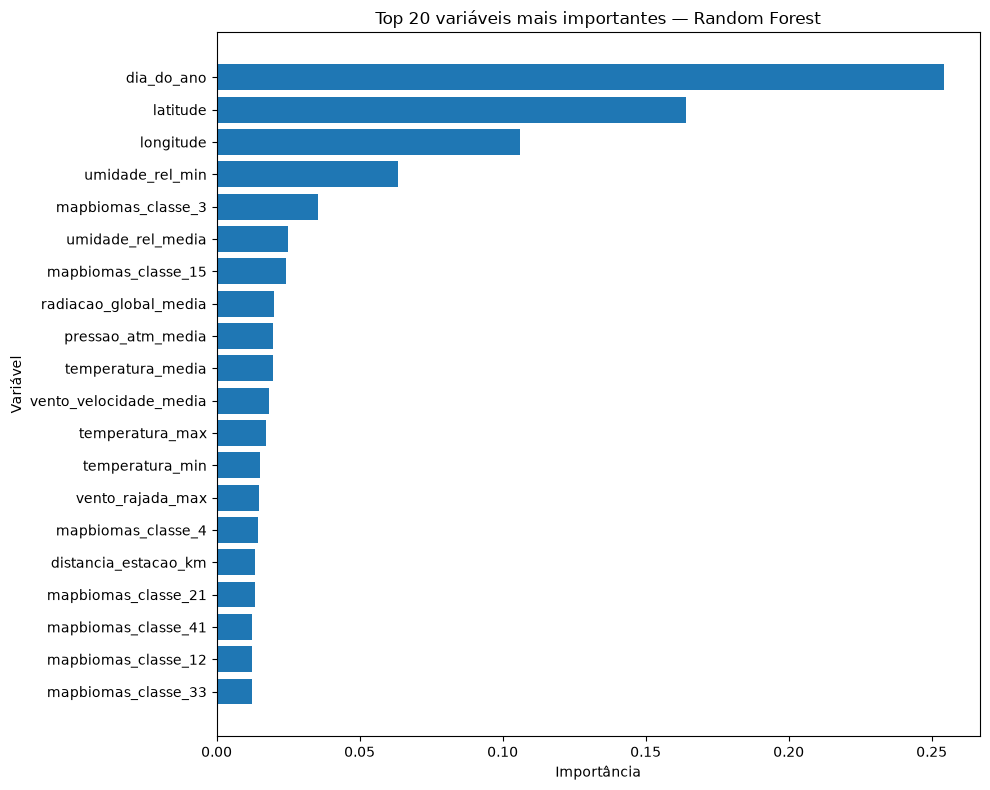

In [119]:
import matplotlib.pyplot as plt

# Selecionar as 20 variáveis mais importantes
top20 = (
    importancia_features
    .head(20)
    .sort_values("importancia", ascending=True)
)

plt.figure(figsize=(10, 8))

plt.barh(
    top20["feature"],
    top20["importancia"]
)

plt.xlabel("Importância")
plt.ylabel("Variável")

plt.title(
    "Top 20 variáveis mais importantes — Random Forest"
)

plt.tight_layout()

plt.show()

In [120]:
import pandas as pd
import numpy as np
from pathlib import Path

# Caminhos do projeto
PROJECT_ROOT = Path.cwd().parent
DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"

print("Ambiente configurado com sucesso!")
print(f"Dados brutos: {DATA_RAW}")
print(f"Dados processados: {DATA_PROCESSED}")

Ambiente configurado com sucesso!
Dados brutos: c:\Users\Jroy\Documents\ProjetoFinalTripleTenBrazil\data\raw
Dados processados: c:\Users\Jroy\Documents\ProjetoFinalTripleTenBrazil\data\processed


In [121]:
# Definir os arquivos utilizados no projeto

arquivos = {
    "queimadas": DATA_RAW / "queimadas_2024_2025.csv",
    "mapbiomas": DATA_RAW / "MapBiomas.csv",
    "estacoes": DATA_RAW / "BDMEP-estacao.csv",
    "meteorologia": DATA_RAW / "BDMEP-2025.csv"
}

# Verificar se todos os arquivos existem
for nome, caminho in arquivos.items():
    print(f"{nome:15} | Existe: {caminho.exists()} | {caminho.name}")

queimadas       | Existe: True | queimadas_2024_2025.csv
mapbiomas       | Existe: True | MapBiomas.csv
estacoes        | Existe: True | BDMEP-estacao.csv
meteorologia    | Existe: True | BDMEP-2025.csv


In [122]:
# Diagnóstico do arquivo de queimadas
caminho_queimadas = arquivos["queimadas"]

with open(caminho_queimadas, "r", encoding="utf-8", errors="replace") as arquivo:
    for i in range(5):
        linha = arquivo.readline()
        print(f"Linha {i + 1}:")
        print(repr(linha[:1000]))
        print("-" * 80)

Linha 1:
'\ufeffano;mes;data_hora;bioma;sigla_uf;sigla_uf_nome;id_municipio;id_municipio_nome;latitude;longitude;satelite;dias_sem_chuva;precipitacao;risco_fogo;potencia_radiativa_fogo\n'
--------------------------------------------------------------------------------
Linha 2:
'2024;9;2024-09-13 04:29:00;Mata Atlântica;MG;Minas Gerais;3166907;Serrania;-21.56454;-46.03047;NPP-375D;19.0;0.0;1.0;7.3\n'
--------------------------------------------------------------------------------
Linha 3:
'2024;9;2024-09-13 04:29:00;Mata Atlântica;ES;Espírito Santo;3202652;Irupi;-20.27151;-41.69187;NPP-375D;34.0;0.0;1.0;3.8\n'
--------------------------------------------------------------------------------
Linha 4:
'2024;9;2024-09-13 04:29:00;Mata Atlântica;RJ;Rio de Janeiro;3300308;Barra do Piraí;-22.42786;-43.81413;NPP-375D;18.0;0.0;1.0;2.5\n'
--------------------------------------------------------------------------------
Linha 5:
'2024;9;2024-09-13 04:29:00;Mata Atlântica;RJ;Rio de Janeiro;3303708;P

In [123]:
# Procurar linhas com quantidade incorreta de campos

caminho_queimadas = arquivos["queimadas"]

linhas_problematicas = []
campos_esperados = 15

with open(
    caminho_queimadas,
    "r",
    encoding="utf-8-sig",
    errors="replace"
) as arquivo:

    # Ignorar cabeçalho
    next(arquivo)

    for numero_linha, linha in enumerate(arquivo, start=2):

        quantidade_campos = len(linha.rstrip("\n").split(";"))

        if quantidade_campos != campos_esperados:
            linhas_problematicas.append(
                (numero_linha, quantidade_campos, linha[:300])
            )

            # Não precisamos procurar milhares agora
            if len(linhas_problematicas) >= 20:
                break

print(f"Linhas problemáticas encontradas: {len(linhas_problematicas)}")

for numero, campos, conteudo in linhas_problematicas:
    print("\n" + "=" * 70)
    print(f"Linha: {numero}")
    print(f"Quantidade de campos: {campos}")
    print(f"Conteúdo: {conteudo}")

Linhas problemáticas encontradas: 0


In [124]:
# Teste de leitura antes de carregar a base completa

queimadas_teste = pd.read_csv(
    arquivos["queimadas"],
    sep=";",
    encoding="utf-8-sig",
    engine="python",
    nrows=100_000
)

print("Leitura realizada com sucesso!")
print(f"Linhas: {queimadas_teste.shape[0]:,}")
print(f"Colunas: {queimadas_teste.shape[1]}")

queimadas_teste.head()

Leitura realizada com sucesso!
Linhas: 100,000
Colunas: 15


,ano,mes,data_hora,bioma,sigla_uf,sigla_uf_nome,id_municipio,id_municipio_nome,latitude,longitude,satelite,dias_sem_chuva,precipitacao,risco_fogo,potencia_radiativa_fogo
0,2024,9,2024-09-13 04:29:00,Mata Atlântica,MG,Minas Gerais,3166907,Serrania,-21.56454,-46.03047,NPP-375D,19.0,0.0,1.0,7.3
1,2024,9,2024-09-13 04:29:00,Mata Atlântica,ES,Espírito Santo,3202652,Irupi,-20.27151,-41.69187,NPP-375D,34.0,0.0,1.0,3.8
2,2024,9,2024-09-13 04:29:00,Mata Atlântica,RJ,Rio de Janeiro,3300308,Barra do Piraí,-22.42786,-43.81413,NPP-375D,18.0,0.0,1.0,2.5
3,2024,9,2024-09-13 04:29:00,Mata Atlântica,RJ,Rio de Janeiro,3303708,Paraíba do Sul,-22.18328,-43.35031,NPP-375D,18.0,0.0,1.0,26.5
4,2024,9,2024-09-13 04:29:00,Mata Atlântica,RJ,Rio de Janeiro,3303906,Petrópolis,-22.53255,-43.13242,NPP-375D,-999.0,0.0,1.0,2.0


In [125]:
# Testar o parser padrão do pandas (mais rápido)

queimadas_teste_c = pd.read_csv(
    arquivos["queimadas"],
    sep=";",
    encoding="utf-8-sig",
    nrows=100_000,
    low_memory=False
)

print("Teste com parser padrão concluído!")
print(f"Linhas: {queimadas_teste_c.shape[0]:,}")
print(f"Colunas: {queimadas_teste_c.shape[1]}")

print("\nColunas encontradas:")
print(queimadas_teste_c.columns.tolist())

Teste com parser padrão concluído!
Linhas: 100,000
Colunas: 15

Colunas encontradas:
['ano', 'mes', 'data_hora', 'bioma', 'sigla_uf', 'sigla_uf_nome', 'id_municipio', 'id_municipio_nome', 'latitude', 'longitude', 'satelite', 'dias_sem_chuva', 'precipitacao', 'risco_fogo', 'potencia_radiativa_fogo']


In [127]:
# ============================================================
# CARREGAR BASE COMPLETA DE QUEIMADAS
# LEITURA EM CHUNKS PARA REDUZIR USO DE MEMÓRIA
# ============================================================

colunas_queimadas = [
    "ano",
    "mes",
    "data_hora",
    "bioma",
    "sigla_uf",
    "sigla_uf_nome",
    "id_municipio",
    "id_municipio_nome",
    "latitude",
    "longitude",
    "dias_sem_chuva",
    "precipitacao",
    "risco_fogo",
    "potencia_radiativa_fogo"
]

chunks_queimadas = []

for chunk in pd.read_csv(
    arquivos["queimadas"],
    sep=";",
    encoding="utf-8-sig",
    usecols=colunas_queimadas,
    low_memory=False,
    chunksize=250_000
):
    chunks_queimadas.append(chunk)

queimadas = pd.concat(
    chunks_queimadas,
    ignore_index=True
)

del chunks_queimadas

print("Base completa de queimadas carregada com sucesso!")
print(f"Linhas: {queimadas.shape[0]:,}")
print(f"Colunas: {queimadas.shape[1]}")
print(
    f"Memória utilizada: "
    f"{queimadas.memory_usage(deep=True).sum() / 1024**2:,.2f} MB"
)

Base completa de queimadas carregada com sucesso!
Linhas: 8,226,944
Colunas: 14
Memória utilizada: 3,470.85 MB


In [128]:
# Converter data_hora para formato datetime

queimadas["data_hora"] = pd.to_datetime(
    queimadas["data_hora"],
    errors="coerce"
)

print("Tipo de data_hora:")
print(queimadas["data_hora"].dtype)

print("\nDatas inválidas após conversão:")
print(queimadas["data_hora"].isna().sum())

print("\nPeríodo disponível:")
print("Data inicial:", queimadas["data_hora"].min())
print("Data final:", queimadas["data_hora"].max())

Tipo de data_hora:
datetime64[us]

Datas inválidas após conversão:
0

Período disponível:
Data inicial: 2024-01-01 00:06:16
Data final: 2025-02-12 23:10:00


In [129]:
# Verificar registros duplicados na base completa

duplicatas = queimadas.duplicated().sum()

print(f"Total de registros: {len(queimadas):,}")
print(f"Registros duplicados: {duplicatas:,}")
print(f"Percentual de duplicatas: {duplicatas / len(queimadas) * 100:.4f}%")

Total de registros: 8,226,944
Registros duplicados: 0
Percentual de duplicatas: 0.0000%


In [ ]:
# Analisar valores ausentes na base completa de queimadas

ausentes_queimadas = pd.DataFrame({
    "quantidade": queimadas.isna().sum(),
    "percentual": queimadas.isna().mean() * 100
})

ausentes_queimadas = ausentes_queimadas[
    ausentes_queimadas["quantidade"] > 0
].sort_values("percentual", ascending=False)

ausentes_queimadas["percentual"] = (
    ausentes_queimadas["percentual"].round(2)
)

print("VALORES AUSENTES - QUEIMADAS")
print("=" * 50)

ausentes_queimadas

VALORES AUSENTES - QUEIMADAS


,quantidade,percentual
potencia_radiativa_fogo,340724,4.14
precipitacao,112670,1.37
dias_sem_chuva,112670,1.37
risco_fogo,112670,1.37
bioma,1,0.00


In [ ]:
# Analisar a variável risco_fogo

print("ESTATÍSTICAS DE RISCO_FOGO")
print("=" * 50)

print(queimadas["risco_fogo"].describe())

print("\nQuantidade de valores únicos:")
print(queimadas["risco_fogo"].nunique())

print("\nMenor valor:")
print(queimadas["risco_fogo"].min())

print("\nMaior valor:")
print(queimadas["risco_fogo"].max())

print("\nValores mais frequentes:")
print(
    queimadas["risco_fogo"]
    .value_counts(dropna=False)
    .head(20)
)

ESTATÍSTICAS DE RISCO_FOGO
count    8.114274e+06
mean    -1.021298e+01
std      1.045882e+02
min     -9.990000e+02
25%      8.200000e-01
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: risco_fogo, dtype: float64

Quantidade de valores únicos:
102

Menor valor:
-999.0

Maior valor:
1.0

Valores mais frequentes:
risco_fogo
 1.00      4938904
 NaN        112670
 0.00       111421
 0.99       108682
 0.98        91385
-999.00      89779
 0.97        84433
 0.96        78620
 0.95        75454
 0.94        71237
 0.93        67371
 0.92        65501
 0.91        61278
 0.90        59495
 0.89        58551
 0.01        56591
 0.88        53818
 0.87        53535
 0.86        53527
 0.85        49451
Name: count, dtype: int64


In [ ]:
# Investigar valores -999 em risco_fogo

qtd_999 = (queimadas["risco_fogo"] == -999).sum()

print("ANÁLISE DO VALOR -999")
print("=" * 50)

print(f"Quantidade de -999: {qtd_999:,}")
print(
    f"Percentual de -999: "
    f"{qtd_999 / len(queimadas) * 100:.2f}%"
)

# Considerar apenas valores entre 0 e 1 para análise
risco_valido = queimadas.loc[
    queimadas["risco_fogo"].between(0, 1),
    "risco_fogo"
]

print("\nESTATÍSTICAS APENAS DOS VALORES ENTRE 0 E 1")
print("=" * 50)
print(risco_valido.describe())

print("\nQuantidade de valores válidos:")
print(f"{len(risco_valido):,}")

print("\nQuantidade de valores únicos válidos:")
print(risco_valido.nunique())

ANÁLISE DO VALOR -999
Quantidade de -999: 89,779
Percentual de -999: 1.09%

ESTATÍSTICAS APENAS DOS VALORES ENTRE 0 E 1
count    8.024495e+06
mean     8.496855e-01
std      2.773445e-01
min      0.000000e+00
25%      8.400000e-01
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: risco_fogo, dtype: float64

Quantidade de valores válidos:
8,024,495

Quantidade de valores únicos válidos:
101


In [ ]:
# Analisar a distribuição dos valores válidos de risco_fogo

faixas_risco = pd.cut(
    risco_valido,
    bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0],
    include_lowest=True
)

distribuicao_risco = pd.DataFrame({
    "quantidade": faixas_risco.value_counts(sort=False),
    "percentual": faixas_risco.value_counts(
        normalize=True,
        sort=False
    ) * 100
})

distribuicao_risco["percentual"] = (
    distribuicao_risco["percentual"].round(2)
)

print("DISTRIBUIÇÃO DE RISCO_FOGO")
print("=" * 50)

distribuicao_risco

DISTRIBUIÇÃO DE RISCO_FOGO


,quantidade,percentual
risco_fogo,,
"(-0.001, 0.2]",566176,7.06
"(0.2, 0.4]",301198,3.75
"(0.4, 0.6]",390026,4.86
"(0.6, 0.8]",610563,7.61
"(0.8, 1.0]",6156532,76.72


In [ ]:
# Verificar os valores de risco_fogo mais frequentes

frequencia_risco = (
    risco_valido
    .value_counts()
    .sort_index()
    .reset_index()
)

frequencia_risco.columns = ["risco_fogo", "quantidade"]

frequencia_risco["percentual"] = (
    frequencia_risco["quantidade"]
    / len(risco_valido)
    * 100
).round(2)

print("20 MAIORES VALORES DE RISCO_FOGO")
print("=" * 50)

frequencia_risco.tail(20)

20 MAIORES VALORES DE RISCO_FOGO


,risco_fogo,quantidade,percentual
81,0.81,44623,0.56
82,0.82,47218,0.59
83,0.83,46225,0.58
84,0.84,47224,0.59
85,0.85,49451,0.62
86,0.86,53527,0.67
87,0.87,53535,0.67
88,0.88,53818,0.67
89,0.89,58551,0.73
90,0.90,59495,0.74


In [ ]:
# Classificar risco_fogo segundo as faixas oficiais do INPE
# Apenas para análise exploratória neste momento

risco_inpe = pd.cut(
    risco_valido,
    bins=[-0.001, 0.15, 0.40, 0.70, 0.95, 1.00],
    labels=["Mínimo", "Baixo", "Médio", "Alto", "Crítico"],
    include_lowest=True
)

distribuicao_inpe = pd.DataFrame({
    "quantidade": risco_inpe.value_counts(sort=False),
    "percentual": risco_inpe.value_counts(
        normalize=True,
        sort=False
    ) * 100
})

distribuicao_inpe["percentual"] = (
    distribuicao_inpe["percentual"].round(2)
)

print("DISTRIBUIÇÃO SEGUNDO AS CATEGORIAS DO INPE")
print("=" * 55)

distribuicao_inpe

DISTRIBUIÇÃO SEGUNDO AS CATEGORIAS DO INPE


,quantidade,percentual
risco_fogo,,
Mínimo,489737,6.10
Baixo,377637,4.71
Médio,647319,8.07
Alto,1207778,15.05
Crítico,5302024,66.07


In [ ]:
# Converter o código inválido -999 em valor ausente

queimadas["risco_fogo"] = queimadas["risco_fogo"].replace(
    -999,
    np.nan
)

print("TRATAMENTO DE RISCO_FOGO")
print("=" * 50)

print(
    f"Valores -999 restantes: "
    f"{(queimadas['risco_fogo'] == -999).sum():,}"
)

print(
    f"Valores ausentes em risco_fogo: "
    f"{queimadas['risco_fogo'].isna().sum():,}"
)

print(
    f"Valores válidos: "
    f"{queimadas['risco_fogo'].notna().sum():,}"
)

print("\nIntervalo dos valores válidos:")
print(
    queimadas["risco_fogo"].min(),
    "a",
    queimadas["risco_fogo"].max()
)

TRATAMENTO DE RISCO_FOGO
Valores -999 restantes: 0
Valores ausentes em risco_fogo: 202,449
Valores válidos: 8,024,495

Intervalo dos valores válidos:
0.0 a 1.0


### Conclusão do tratamento inicial da base de queimadas

A base contém **8.226.944 registros** e não foram identificadas duplicatas completas. O período analisado vai de **1º de janeiro de 2024 a 12 de fevereiro de 2025**.

Durante a análise da variável `risco_fogo`, foram encontrados **89.779 registros com valor -999**, equivalentes a aproximadamente **1,09% da base**. Como esse valor está fora do intervalo válido do indicador, de 0 a 1, ele foi interpretado como código de ausência de informação e convertido para `NaN`.

Após esse tratamento, permaneceram **8.024.495 valores válidos de `risco_fogo`**, todos dentro do intervalo esperado de 0 a 1.

Também foi observada uma forte concentração dos valores de risco nas faixas superiores, indicando desde esta etapa que a variável de interesse apresenta uma distribuição desequilibrada. Esse comportamento será considerado posteriormente na construção da variável-alvo e na escolha das métricas de avaliação dos modelos.

In [ ]:
# Verificar se os valores ausentes ocorrem nas mesmas linhas

colunas_verificar = [
    "dias_sem_chuva",
    "precipitacao",
    "risco_fogo",
    "potencia_radiativa_fogo"
]

print("PADRÕES DE VALORES AUSENTES")
print("=" * 60)

padroes_ausentes = (
    queimadas[colunas_verificar]
    .isna()
    .value_counts()
    .reset_index(name="quantidade")
)

padroes_ausentes["percentual"] = (
    padroes_ausentes["quantidade"]
    / len(queimadas)
    * 100
).round(2)

padroes_ausentes.head(10)

PADRÕES DE VALORES AUSENTES


,dias_sem_chuva,precipitacao,risco_fogo,potencia_radiativa_fogo,quantidade,percentual
0,False,False,False,False,7697301,93.56
1,False,False,False,True,327194,3.98
2,True,True,True,False,103316,1.26
3,False,False,True,False,85603,1.04
4,True,True,True,True,9354,0.11
5,False,False,True,True,4176,0.05


In [ ]:
# Criar variável de data para futura agregação diária

queimadas["data"] = queimadas["data_hora"].dt.normalize()

print("NOVA VARIÁVEL DE DATA")
print("=" * 50)

print("Tipo:")
print(queimadas["data"].dtype)

print("\nPeríodo:")
print("Data inicial:", queimadas["data"].min())
print("Data final:", queimadas["data"].max())

print("\nExemplo:")
print(
    queimadas[
        ["data_hora", "data", "id_municipio", "risco_fogo"]
    ].head()
)

NOVA VARIÁVEL DE DATA
Tipo:
datetime64[us]

Período:
Data inicial: 2024-01-01 00:00:00
Data final: 2025-02-12 00:00:00

Exemplo:
            data_hora       data  id_municipio  risco_fogo
0 2024-09-13 04:29:00 2024-09-13       3166907         1.0
1 2024-09-13 04:29:00 2024-09-13       3202652         1.0
2 2024-09-13 04:29:00 2024-09-13       3300308         1.0
3 2024-09-13 04:29:00 2024-09-13       3303708         1.0
4 2024-09-13 04:29:00 2024-09-13       3303906         1.0


In [ ]:
# Analisar quantidade de focos por município e dia

focos_por_municipio_dia = (
    queimadas
    .groupby(["id_municipio", "data"])
    .size()
)

print("FOCOS POR MUNICÍPIO/DIA")
print("=" * 50)

print(f"Total de combinações município-dia: {len(focos_por_municipio_dia):,}")

print("\nEstatísticas:")
print(focos_por_municipio_dia.describe())

print("\nMaior número de focos em um município no mesmo dia:")
print(focos_por_municipio_dia.max())


FOCOS POR MUNICÍPIO/DIA
Total de combinações município-dia: 324,219

Estatísticas:
count    324219.000000
mean         25.374651
std         166.714562
min           1.000000
25%           1.000000
50%           3.000000
75%           9.000000
max       12149.000000
dtype: float64

Maior número de focos em um município no mesmo dia:
12149


In [ ]:
# Verificar a variação de risco_fogo dentro do mesmo município e dia

variacao_risco_diario = (
    queimadas
    .groupby(["id_municipio", "data"])["risco_fogo"]
    .agg(["count", "min", "max", "mean"])
)

variacao_risco_diario["amplitude"] = (
    variacao_risco_diario["max"] -
    variacao_risco_diario["min"]
)

print("VARIAÇÃO DE RISCO_FOGO POR MUNICÍPIO/DIA")
print("=" * 60)

print(
    "Município-dias analisados:",
    f"{len(variacao_risco_diario):,}"
)

print(
    "Sem nenhum risco_fogo válido:",
    f"{(variacao_risco_diario['count'] == 0).sum():,}"
)

print(
    "Com apenas um valor válido:",
    f"{(variacao_risco_diario['count'] == 1).sum():,}"
)

print(
    "Com mais de um valor válido:",
    f"{(variacao_risco_diario['count'] > 1).sum():,}"
)

print("\nAmplitude de risco dentro do município/dia:")
print(variacao_risco_diario["amplitude"].describe())

VARIAÇÃO DE RISCO_FOGO POR MUNICÍPIO/DIA
Município-dias analisados: 324,219
Sem nenhum risco_fogo válido: 15,228
Com apenas um valor válido: 94,844
Com mais de um valor válido: 214,147

Amplitude de risco dentro do município/dia:
count    308991.000000
mean          0.076494
std           0.182814
min           0.000000
25%           0.000000
50%           0.000000
75%           0.030000
max           1.000000
Name: amplitude, dtype: float64


In [ ]:
# Analisar a magnitude da variação diária de risco_fogo

amplitude = variacao_risco_diario["amplitude"].dropna()

print("MAGNITUDE DA VARIAÇÃO DIÁRIA DE RISCO")
print("=" * 60)

limites = [0, 0.01, 0.05, 0.10, 0.20, 0.50]

for limite in limites:
    quantidade = (amplitude > limite).sum()
    percentual = quantidade / len(amplitude) * 100

    print(
        f"Amplitude > {limite:.2f}: "
        f"{quantidade:,} ({percentual:.2f}%)"
    )

MAGNITUDE DA VARIAÇÃO DIÁRIA DE RISCO
Amplitude > 0.00: 98,206 (31.78%)
Amplitude > 0.01: 93,429 (30.24%)
Amplitude > 0.05: 68,804 (22.27%)
Amplitude > 0.10: 54,816 (17.74%)
Amplitude > 0.20: 39,721 (12.86%)
Amplitude > 0.50: 16,683 (5.40%)


### Definição da unidade de análise: município-dia

Os registros originais representam focos individuais detectados por satélite, portanto um mesmo município pode apresentar vários registros no mesmo dia. Para integrar essas informações com os dados meteorológicos diários e construir uma unidade consistente para modelagem, os registros serão agregados por **município e data**.

A análise anterior mostrou que existem **324.219 combinações município-dia** e que o valor de `risco_fogo` pode variar entre diferentes focos registrados no mesmo município e dia. Por esse motivo, serão preservadas duas medidas durante a agregação:

- `risco_fogo_medio`: representa o nível médio de risco observado entre os focos do município naquele dia;
- `risco_fogo_max`: representa o maior nível de risco observado e será posteriormente utilizado como referência para a construção da variável-alvo.

Também serão agregadas informações como número de focos, precipitação, dias sem chuva e potência radiativa. Algumas dessas variáveis serão mantidas nesta etapa para análise, mas posteriormente poderão ser excluídas da modelagem para evitar vazamento de informação.

In [ ]:
# Agregar a base de queimadas por município e dia

queimadas_diario = (
    queimadas
    .groupby(
        ["id_municipio", "data"],
        as_index=False
    )
    .agg(
        ano=("ano", "first"),
        mes=("mes", "first"),
        sigla_uf=("sigla_uf", "first"),
        sigla_uf_nome=("sigla_uf_nome", "first"),
        id_municipio_nome=("id_municipio_nome", "first"),
        bioma=("bioma", "first"),

        latitude=("latitude", "mean"),
        longitude=("longitude", "mean"),

        numero_focos=("data_hora", "size"),

        dias_sem_chuva=("dias_sem_chuva", "mean"),
        precipitacao_queimadas=("precipitacao", "mean"),

        risco_fogo_medio=("risco_fogo", "mean"),
        risco_fogo_max=("risco_fogo", "max"),

        potencia_radiativa_media=(
            "potencia_radiativa_fogo",
            "mean"
        ),
        potencia_radiativa_max=(
            "potencia_radiativa_fogo",
            "max"
        )
    )
)

print("BASE DIÁRIA DE QUEIMADAS")
print("=" * 60)

print(f"Linhas originais: {len(queimadas):,}")
print(f"Linhas após agregação: {len(queimadas_diario):,}")
print(f"Colunas: {queimadas_diario.shape[1]}")

print("\nPrimeiras linhas:")
queimadas_diario.head()

BASE DIÁRIA DE QUEIMADAS
Linhas originais: 8,226,944
Linhas após agregação: 324,219
Colunas: 17

Primeiras linhas:


,id_municipio,data,ano,mes,sigla_uf,sigla_uf_nome,id_municipio_nome,bioma,latitude,longitude,numero_focos,dias_sem_chuva,precipitacao_queimadas,risco_fogo_medio,risco_fogo_max,potencia_radiativa_media,potencia_radiativa_max
0,1100015,2024-01-09,2024,1,RO,Rondônia,Alta Floresta D'Oeste,Amazônia,-13.012145,-62.352457,8,3.0,31.38875,0.000,0.00,4.5375,6.8
1,1100015,2024-01-16,2024,1,RO,Rondônia,Alta Floresta D'Oeste,Amazônia,-12.080470,-62.060842,5,0.0,0.22400,0.010,0.01,34.7200,50.4
2,1100015,2024-01-27,2024,1,RO,Rondônia,Alta Floresta D'Oeste,Amazônia,-12.720660,-62.079500,2,0.0,2.19500,0.010,0.01,2.9500,3.8
3,1100015,2024-02-09,2024,2,RO,Rondônia,Alta Floresta D'Oeste,Amazônia,-12.723245,-62.017786,10,1.0,1.01300,0.075,0.10,18.1600,45.0
4,1100015,2024-03-04,2024,3,RO,Rondônia,Alta Floresta D'Oeste,Amazônia,-13.011165,-62.348880,2,0.0,6.32500,0.010,0.01,3.8000,3.8


In [ ]:
print("VALIDAÇÃO DA BASE DIÁRIA")
print("=" * 50)

print(f"Linhas: {queimadas_diario.shape[0]:,}")
print(f"Colunas: {queimadas_diario.shape[1]}")

print("\nDuplicatas município-data:")
print(
    queimadas_diario.duplicated(
        subset=["id_municipio", "data"]
    ).sum()
)

print("\nValores ausentes:")
print(
    queimadas_diario.isna()
    .sum()
    .sort_values(ascending=False)
)

VALIDAÇÃO DA BASE DIÁRIA
Linhas: 324,219
Colunas: 17

Duplicatas município-data:
0

Valores ausentes:
risco_fogo_medio            15228
risco_fogo_max              15228
dias_sem_chuva               6418
precipitacao_queimadas       6418
potencia_radiativa_max       2851
potencia_radiativa_media     2851
bioma                           1
id_municipio                    0
data                            0
latitude                        0
id_municipio_nome               0
sigla_uf_nome                   0
sigla_uf                        0
ano                             0
mes                             0
longitude                       0
numero_focos                    0
dtype: int64


In [ ]:
# Carregar a base meteorológica do BDMEP

meteorologia = pd.read_csv(
    arquivos["meteorologia"],
    low_memory=False
)

print("BASE METEOROLÓGICA - BDMEP")
print("=" * 60)

print(f"Linhas: {meteorologia.shape[0]:,}")
print(f"Colunas: {meteorologia.shape[1]}")

print("\nColunas disponíveis:")
print(meteorologia.columns.tolist())

print("\nPrimeiras linhas:")
meteorologia.head()

BASE METEOROLÓGICA - BDMEP
Linhas: 4,891,176
Colunas: 21

Colunas disponíveis:
['ano', 'data', 'hora', 'id_estacao', 'precipitacao_total', 'pressao_atm_hora', 'pressao_atm_max', 'pressao_atm_min', 'radiacao_global', 'temperatura_bulbo_hora', 'temperatura_orvalho_hora', 'temperatura_max', 'temperatura_min', 'temperatura_orvalho_max', 'temperatura_orvalho_min', 'umidade_rel_max', 'umidade_rel_min', 'umidade_rel_hora', 'vento_direcao', 'vento_rajada_max', 'vento_velocidade']

Primeiras linhas:


,ano,data,hora,id_estacao,precipitacao_total,pressao_atm_hora,pressao_atm_max,pressao_atm_min,radiacao_global,temperatura_bulbo_hora,...,temperatura_max,temperatura_min,temperatura_orvalho_max,temperatura_orvalho_min,umidade_rel_max,umidade_rel_min,umidade_rel_hora,vento_direcao,vento_rajada_max,vento_velocidade
0,2025,2025-05-29,13:00:00,A316,0.0,997.6,997.9,997.5,2523.7,30.7,...,31.1,28.8,18.5,15.9,53.0,41.0,41.0,106.0,9.1,4.2
1,2025,2025-01-21,16:00:00,A867,0.0,1007.7,1008.4,1007.7,3896.8,32.6,...,32.8,31.6,18.6,14.8,46.0,34.0,41.0,256.0,8.8,4.5
2,2025,2025-05-14,18:00:00,A366,0.0,958.9,959.3,958.7,2227.9,30.3,...,31.2,29.5,13.7,11.8,36.0,31.0,32.0,119.0,11.7,5.5
3,2025,2025-05-27,16:00:00,A849,0.0,971.3,972.2,971.3,2279.0,29.8,...,29.8,27.9,15.4,14.5,45.0,41.0,41.0,NaN,10.3,5.5
4,2025,2025-04-01,19:00:00,A349,0.0,959.8,959.9,959.7,1831.7,33.6,...,34.3,33.3,16.3,15.4,35.0,33.0,35.0,165.0,10.7,5.2


In [ ]:
# ============================================================
# DIAGNÓSTICO DE DUPLICATAS — INMET 2025
# ============================================================

print("DIAGNÓSTICO DE DUPLICATAS - INMET 2025")
print("=" * 60)

total_linhas = len(meteorologia)
duplicatas_exatas = meteorologia.duplicated().sum()

print(f"Total de linhas: {total_linhas:,}")
print(f"Duplicatas exatas: {duplicatas_exatas:,}")
print(
    f"Percentual de duplicatas exatas: "
    f"{duplicatas_exatas / total_linhas * 100:.2f}%"
)

print("\nColunas disponíveis:")
print(meteorologia.columns.tolist())

DIAGNÓSTICO DE DUPLICATAS - INMET 2025
Total de linhas: 4,891,176
Duplicatas exatas: 2,427,992
Percentual de duplicatas exatas: 49.64%

Colunas disponíveis:
['ano', 'data', 'hora', 'id_estacao', 'precipitacao_total', 'pressao_atm_hora', 'pressao_atm_max', 'pressao_atm_min', 'radiacao_global', 'temperatura_bulbo_hora', 'temperatura_orvalho_hora', 'temperatura_max', 'temperatura_min', 'temperatura_orvalho_max', 'temperatura_orvalho_min', 'umidade_rel_max', 'umidade_rel_min', 'umidade_rel_hora', 'vento_direcao', 'vento_rajada_max', 'vento_velocidade']


In [ ]:
# ============================================================
# REMOÇÃO DE DUPLICATAS EXATAS — INMET 2025
# ============================================================

linhas_antes = len(meteorologia)

meteorologia = meteorologia.drop_duplicates().copy()

linhas_depois = len(meteorologia)
linhas_removidas = linhas_antes - linhas_depois

print("REMOÇÃO DE DUPLICATAS - INMET 2025")
print("=" * 60)
print(f"Linhas antes: {linhas_antes:,}")
print(f"Duplicatas removidas: {linhas_removidas:,}")
print(f"Linhas depois: {linhas_depois:,}")
print(f"Duplicatas restantes: {meteorologia.duplicated().sum():,}")

REMOÇÃO DE DUPLICATAS - INMET 2025
Linhas antes: 4,891,176
Duplicatas removidas: 2,427,992
Linhas depois: 2,463,184
Duplicatas restantes: 0


In [ ]:
# ============================================================
# VERIFICAÇÃO DE REGISTROS POR ESTAÇÃO-DIA — INMET 2025
# ============================================================

registros_estacao_dia = (
    meteorologia
    .groupby(["id_estacao", "data"])
    .size()
)

print("REGISTROS POR ESTAÇÃO-DIA APÓS REMOVER DUPLICATAS")
print("=" * 65)

print(registros_estacao_dia.describe())

print("\nFrequências mais comuns:")
print(
    registros_estacao_dia
    .value_counts()
    .sort_index()
    .tail(15)
)

print(
    "\nEstações-dias com exatamente 24 registros:",
    (registros_estacao_dia == 24).sum()
)

print(
    "Estações-dias com exatamente 48 registros:",
    (registros_estacao_dia == 48).sum()
)

print(
    "Máximo de registros em uma estação-dia:",
    registros_estacao_dia.max()
)

REGISTROS POR ESTAÇÃO-DIA APÓS REMOVER DUPLICATAS
count    102171.000000
mean         24.108446
std           1.595648
min          24.000000
25%          24.000000
50%          24.000000
75%          24.000000
max          48.000000
dtype: float64

Frequências mais comuns:
24    101635
25        45
26        19
27         6
28         3
31         2
33         2
35         1
38         1
45         2
46         9
47        34
48       412
Name: count, dtype: int64

Estações-dias com exatamente 24 registros: 101635
Estações-dias com exatamente 48 registros: 412
Máximo de registros em uma estação-dia: 48


In [ ]:
# ============================================================
# VERIFICAÇÃO DE DUPLICATAS POR ESTAÇÃO + DATA + HORA
# ============================================================

chaves_horarias = ["id_estacao", "data", "hora"]

duplicatas_horarias = meteorologia.duplicated(
    subset=chaves_horarias,
    keep=False
)

total_registros_chave_duplicada = duplicatas_horarias.sum()

total_chaves_duplicadas = (
    meteorologia.loc[duplicatas_horarias, chaves_horarias]
    .drop_duplicates()
    .shape[0]
)

print("DUPLICATAS POR ESTAÇÃO + DATA + HORA")
print("=" * 65)

print(
    f"Registros pertencentes a chaves horárias duplicadas: "
    f"{total_registros_chave_duplicada:,}"
)

print(
    f"Combinações estação-data-hora duplicadas: "
    f"{total_chaves_duplicadas:,}"
)

print("\nQuantidade de registros por chave horária:")
print(
    meteorologia
    .groupby(chaves_horarias)
    .size()
    .value_counts()
    .sort_index()
)

print("\nExemplo de chaves duplicadas:")
display(
    meteorologia.loc[duplicatas_horarias]
    .sort_values(chaves_horarias)
    .head(20)
)

DUPLICATAS POR ESTAÇÃO + DATA + HORA
Registros pertencentes a chaves horárias duplicadas: 22,160
Combinações estação-data-hora duplicadas: 11,080

Quantidade de registros por chave horária:
1    2441024
2      11080
Name: count, dtype: int64

Exemplo de chaves duplicadas:


,ano,data,hora,id_estacao,precipitacao_total,pressao_atm_hora,pressao_atm_max,pressao_atm_min,radiacao_global,temperatura_bulbo_hora,...,temperatura_max,temperatura_min,temperatura_orvalho_max,temperatura_orvalho_min,umidade_rel_max,umidade_rel_min,umidade_rel_hora,vento_direcao,vento_rajada_max,vento_velocidade
1398821,2025,2025-06-01,00:00:00,A023,NaN,935.0,935.0,934.4,NaN,20.8,...,21.3,19.7,17.1,16.3,82.0,76.0,76.0,217.0,0.0,0.0
2032427,2025,2025-06-01,00:00:00,A023,0.0,935.0,935.0,934.4,NaN,20.8,...,21.3,19.7,17.1,16.3,82.0,76.0,76.0,217.0,0.0,0.0
207556,2025,2025-06-01,01:00:00,A023,0.0,934.9,935.1,934.9,NaN,19.3,...,20.9,19.3,16.5,16.2,83.0,76.0,83.0,226.0,2.6,0.2
1655672,2025,2025-06-01,01:00:00,A023,NaN,934.9,935.1,934.9,NaN,19.3,...,20.9,19.3,16.5,16.2,83.0,76.0,83.0,226.0,2.6,0.2
2304437,2025,2025-06-01,02:00:00,A023,0.0,935.0,935.1,934.9,NaN,18.9,...,19.6,18.8,16.4,15.8,83.0,81.0,83.0,205.0,1.9,0.0
2848861,2025,2025-06-01,02:00:00,A023,NaN,935.0,935.1,934.9,NaN,18.9,...,19.6,18.8,16.4,15.8,83.0,81.0,83.0,205.0,1.9,0.0
1184886,2025,2025-06-01,03:00:00,A023,0.0,935.1,935.2,934.9,NaN,18.2,...,19.0,17.8,16.1,15.5,87.0,83.0,86.0,224.0,2.5,0.2
4446340,2025,2025-06-01,03:00:00,A023,NaN,935.1,935.2,934.9,NaN,18.2,...,19.0,17.8,16.1,15.5,87.0,83.0,86.0,224.0,2.5,0.2
280524,2025,2025-06-01,04:00:00,A023,NaN,935.0,935.1,935.0,NaN,17.8,...,18.4,17.8,16.1,15.7,89.0,85.0,89.0,230.0,2.0,0.2
2380751,2025,2025-06-01,04:00:00,A023,0.0,935.0,935.1,935.0,NaN,17.8,...,18.4,17.8,16.1,15.7,89.0,85.0,89.0,230.0,2.0,0.2


In [ ]:
# ============================================================
# INVESTIGAR DIFERENÇAS ENTRE DUPLICATAS HORÁRIAS
# ============================================================

dados_dup = (
    meteorologia.loc[duplicatas_horarias]
    .sort_values(["id_estacao", "data", "hora"])
    .copy()
)

colunas_medidas = [
    coluna for coluna in meteorologia.columns
    if coluna not in ["ano", "data", "hora", "id_estacao"]
]

diferencas_por_coluna = {}

for coluna in colunas_medidas:
    quantidade = (
        dados_dup
        .groupby(["id_estacao", "data", "hora"])[coluna]
        .nunique(dropna=False)
        .gt(1)
        .sum()
    )

    diferencas_por_coluna[coluna] = quantidade

diferencas_por_coluna = (
    pd.Series(diferencas_por_coluna)
    .sort_values(ascending=False)
)

print("DIFERENÇAS ENTRE AS DUPLICATAS HORÁRIAS")
print("=" * 65)
print(diferencas_por_coluna)

DIFERENÇAS ENTRE AS DUPLICATAS HORÁRIAS
vento_direcao               5199
radiacao_global             4859
vento_velocidade            1190
vento_rajada_max            1187
precipitacao_total           823
temperatura_bulbo_hora       105
pressao_atm_hora             105
pressao_atm_max              105
pressao_atm_min              105
temperatura_min              105
temperatura_max              105
temperatura_orvalho_hora     105
temperatura_orvalho_max      105
umidade_rel_min              105
umidade_rel_max              105
temperatura_orvalho_min      105
umidade_rel_hora             105
dtype: int64


In [ ]:
# ============================================================
# CONSOLIDAÇÃO DAS DUPLICATAS HORÁRIAS — INMET 2025
# ============================================================

linhas_antes_consolidacao = len(meteorologia)

# Garantir que as variáveis meteorológicas estejam numéricas
colunas_medidas = [
    coluna for coluna in meteorologia.columns
    if coluna not in ["ano", "data", "hora", "id_estacao"]
]

for coluna in colunas_medidas:
    meteorologia[coluna] = pd.to_numeric(
        meteorologia[coluna],
        errors="coerce"
    )

# Consolidar registros referentes à mesma estação, data e hora.
# Quando existem dois valores diferentes para a mesma variável,
# utiliza-se a média dos valores disponíveis.
meteorologia = (
    meteorologia
    .groupby(
        ["ano", "data", "hora", "id_estacao"],
        as_index=False,
        dropna=False
    )[colunas_medidas]
    .mean()
)

linhas_depois_consolidacao = len(meteorologia)

duplicatas_horarias_restantes = meteorologia.duplicated(
    subset=["id_estacao", "data", "hora"]
).sum()

print("CONSOLIDAÇÃO DAS DUPLICATAS HORÁRIAS")
print("=" * 65)
print(f"Linhas antes: {linhas_antes_consolidacao:,}")
print(f"Linhas depois: {linhas_depois_consolidacao:,}")
print(
    f"Registros consolidados: "
    f"{linhas_antes_consolidacao - linhas_depois_consolidacao:,}"
)
print(
    f"Duplicatas estação-data-hora restantes: "
    f"{duplicatas_horarias_restantes:,}"
)

CONSOLIDAÇÃO DAS DUPLICATAS HORÁRIAS
Linhas antes: 2,463,184
Linhas depois: 2,452,104
Registros consolidados: 11,080
Duplicatas estação-data-hora restantes: 0


In [ ]:
# ============================================================
# VERIFICAÇÃO FINAL — REGISTROS POR ESTAÇÃO-DIA
# ============================================================

registros_estacao_dia_final = (
    meteorologia
    .groupby(["id_estacao", "data"])
    .size()
)

print("VERIFICAÇÃO FINAL - INMET 2025")
print("=" * 65)

print(registros_estacao_dia_final.describe())

print("\nDistribuição do número de registros por estação-dia:")
print(
    registros_estacao_dia_final
    .value_counts()
    .sort_index()
)

print()
print(
    "Estações-dias com exatamente 24 registros:",
    (registros_estacao_dia_final == 24).sum()
)

print(
    "Estações-dias com mais de 24 registros:",
    (registros_estacao_dia_final > 24).sum()
)

print(
    "Máximo de registros em uma estação-dia:",
    registros_estacao_dia_final.max()
)

VERIFICAÇÃO FINAL - INMET 2025
count    102171.0
mean         24.0
std           0.0
min          24.0
25%          24.0
50%          24.0
75%          24.0
max          24.0
dtype: float64

Distribuição do número de registros por estação-dia:
24    102171
Name: count, dtype: int64

Estações-dias com exatamente 24 registros: 102171
Estações-dias com mais de 24 registros: 0
Máximo de registros em uma estação-dia: 24


In [ ]:
# ============================================================
# DIAGNÓSTICO DA PRECIPITAÇÃO — APÓS CORREÇÃO DO INMET 2025
# ============================================================

precipitacao = meteorologia["precipitacao_total"]

print("DIAGNÓSTICO DA PRECIPITAÇÃO - INMET 2025")
print("=" * 65)

print(f"Total de registros: {len(precipitacao):,}")
print(f"Valores ausentes (NaN): {precipitacao.isna().sum():,}")
print(
    f"Percentual ausente: "
    f"{precipitacao.isna().mean() * 100:.2f}%"
)

print()
print(f"Mediana: {precipitacao.median()}")
print(f"Média: {precipitacao.mean():.4f}")

print()
print(
    "Valores iguais a zero:",
    (precipitacao == 0).sum()
)

print(
    "Valores maiores que zero:",
    (precipitacao > 0).sum()
)

print()
print("Distribuição:")
print(precipitacao.describe())


DIAGNÓSTICO DA PRECIPITAÇÃO - INMET 2025
Total de registros: 2,452,104
Valores ausentes (NaN): 933,694
Percentual ausente: 38.08%

Mediana: 0.0
Média: 0.1787

Valores iguais a zero: 1399835
Valores maiores que zero: 118575

Distribuição:
count    1.518410e+06
mean     1.786801e-01
std      1.413403e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      8.780000e+01
Name: precipitacao_total, dtype: float64


In [ ]:
# ============================================================
# COBERTURA HORÁRIA DA PRECIPITAÇÃO POR ESTAÇÃO-DIA
# ============================================================

cobertura_precipitacao = (
    meteorologia
    .groupby(["id_estacao", "data"])
    .agg(
        horas_totais=("hora", "size"),
        horas_precipitacao_validas=("precipitacao_total", "count"),
        precipitacao_diaria=("precipitacao_total", "sum")
    )
    .reset_index()
)

cobertura_precipitacao["horas_precipitacao_ausentes"] = (
    cobertura_precipitacao["horas_totais"]
    - cobertura_precipitacao["horas_precipitacao_validas"]
)

print("COBERTURA DA PRECIPITAÇÃO POR ESTAÇÃO-DIA")
print("=" * 65)

print(
    cobertura_precipitacao[
        "horas_precipitacao_validas"
    ].describe()
)

print()
print(
    "Estação-dias com 24 horas válidas:",
    (cobertura_precipitacao["horas_precipitacao_validas"] == 24).sum()
)

print(
    "Estação-dias com 1 a 23 horas válidas:",
    (
        (cobertura_precipitacao["horas_precipitacao_validas"] > 0)
        & (cobertura_precipitacao["horas_precipitacao_validas"] < 24)
    ).sum()
)

print(
    "Estação-dias com 0 horas válidas:",
    (cobertura_precipitacao["horas_precipitacao_validas"] == 0).sum()
)

print()
print("Frequência por número de horas válidas:")
print(
    cobertura_precipitacao[
        "horas_precipitacao_validas"
    ]
    .value_counts()
    .sort_index()
)

COBERTURA DA PRECIPITAÇÃO POR ESTAÇÃO-DIA
count    102171.000000
mean         14.861458
std          11.343552
min           0.000000
25%           0.000000
50%          24.000000
75%          24.000000
max          24.000000
Name: horas_precipitacao_validas, dtype: float64

Estação-dias com 24 horas válidas: 56583
Estação-dias com 1 a 23 horas válidas: 9490
Estação-dias com 0 horas válidas: 36098

Frequência por número de horas válidas:
horas_precipitacao_validas
0     36098
1        92
2        98
3       101
4       137
5       172
6       237
7       295
8       272
9       290
10      384
11      370
12      395
13      356
14      349
15      167
16      142
17      141
18      132
19      154
20      375
21      806
22     1495
23     2530
24    56583
Name: count, dtype: int64


In [ ]:
# ============================================================
# TESTE DE AGREGAÇÃO DIÁRIA CORRETA DA PRECIPITAÇÃO
# ============================================================

precipitacao_diaria_teste = (
    meteorologia
    .groupby(
        ["id_estacao", "data"]
    )["precipitacao_total"]
    .sum(min_count=1)
)

print("PRECIPITAÇÃO DIÁRIA COM PRESERVAÇÃO DE AUSÊNCIA")
print("=" * 65)

print(
    "Total de estação-dias:",
    len(precipitacao_diaria_teste)
)

print(
    "Dias com precipitação ausente:",
    precipitacao_diaria_teste.isna().sum()
)

print(
    "Dias com precipitação igual a zero:",
    (precipitacao_diaria_teste == 0).sum()
)

print(
    "Dias com precipitação maior que zero:",
    (precipitacao_diaria_teste > 0).sum()
)

print()
print("Estatísticas dos valores disponíveis:")
print(
    precipitacao_diaria_teste.describe()
)

PRECIPITAÇÃO DIÁRIA COM PRESERVAÇÃO DE AUSÊNCIA
Total de estação-dias: 102171
Dias com precipitação ausente: 36098
Dias com precipitação igual a zero: 36607
Dias com precipitação maior que zero: 29466

Estatísticas dos valores disponíveis:
count    66073.000000
mean         4.106211
std         10.908389
min          0.000000
25%          0.000000
50%          0.000000
75%          2.200000
max        285.800000
Name: precipitacao_total, dtype: float64


In [ ]:
# ============================================================
# ANÁLISE DOS DIAS COM COBERTURA PARCIAL DE PRECIPITAÇÃO
# ============================================================

dias_parciais = cobertura_precipitacao[
    (
        cobertura_precipitacao["horas_precipitacao_validas"] > 0
    )
    &
    (
        cobertura_precipitacao["horas_precipitacao_validas"] < 24
    )
].copy()

print("DIAS COM COBERTURA PARCIAL DE PRECIPITAÇÃO")
print("=" * 65)

print(f"Total de dias parciais: {len(dias_parciais):,}")

print()
print("Horas válidas por dia parcial:")
print(
    dias_parciais["horas_precipitacao_validas"].describe()
)

print()
print(
    "Dias parciais com precipitação observada = 0:",
    (dias_parciais["precipitacao_diaria"] == 0).sum()
)

print(
    "Dias parciais com precipitação observada > 0:",
    (dias_parciais["precipitacao_diaria"] > 0).sum()
)

print()
print("Distribuição por faixas de cobertura:")

print(
    pd.cut(
        dias_parciais["horas_precipitacao_validas"],
        bins=[0, 6, 12, 18, 23],
        labels=[
            "1-6 horas",
            "7-12 horas",
            "13-18 horas",
            "19-23 horas"
        ]
    ).value_counts().sort_index()
)

DIAS COM COBERTURA PARCIAL DE PRECIPITAÇÃO
Total de dias parciais: 9,490

Horas válidas por dia parcial:
count    9490.000000
mean       16.903899
std         6.566315
min         1.000000
25%        11.000000
50%        21.000000
75%        23.000000
max        23.000000
Name: horas_precipitacao_validas, dtype: float64

Dias parciais com precipitação observada = 0: 5781
Dias parciais com precipitação observada > 0: 3709

Distribuição por faixas de cobertura:
horas_precipitacao_validas
1-6 horas       837
7-12 horas     2006
13-18 horas    1287
19-23 horas    5360
Name: count, dtype: int64


In [ ]:
# Verificar período disponível na base meteorológica

meteorologia["data"] = pd.to_datetime(
    meteorologia["data"],
    errors="coerce"
)

print("PERÍODO DA BASE METEOROLÓGICA")
print("=" * 60)

print("Tipo da coluna data:")
print(meteorologia["data"].dtype)

print("\nDatas inválidas:")
print(f"{meteorologia['data'].isna().sum():,}")

print("\nData inicial:")
print(meteorologia["data"].min())

print("\nData final:")
print(meteorologia["data"].max())

print("\nRegistros por ano:")
print(
    meteorologia["data"]
    .dt.year
    .value_counts()
    .sort_index()
)

PERÍODO DA BASE METEOROLÓGICA
Tipo da coluna data:
datetime64[us]

Datas inválidas:
0

Data inicial:
2025-01-01 00:00:00

Data final:
2025-06-30 00:00:00

Registros por ano:
data
2025    2452104
Name: count, dtype: int64


In [ ]:
# ============================================================
# TESTE DO CRITÉRIO DE COBERTURA MÍNIMA — PRECIPITAÇÃO
# ============================================================

limite_horas_precipitacao = 18

precipitacao_com_criterio = cobertura_precipitacao.copy()

precipitacao_com_criterio["precipitacao_diaria_validada"] = (
    precipitacao_com_criterio["precipitacao_diaria"]
    .where(
        precipitacao_com_criterio[
            "horas_precipitacao_validas"
        ] >= limite_horas_precipitacao
    )
)

print("CRITÉRIO DE COBERTURA DA PRECIPITAÇÃO")
print("=" * 65)
print(
    f"Critério adotado: pelo menos "
    f"{limite_horas_precipitacao} de 24 horas válidas (75%)"
)

print()
print(
    "Dias que atendem ao critério:",
    precipitacao_com_criterio[
        "precipitacao_diaria_validada"
    ].notna().sum()
)

print(
    "Dias mantidos como ausentes:",
    precipitacao_com_criterio[
        "precipitacao_diaria_validada"
    ].isna().sum()
)

print()
print(
    "Entre os dias válidos — precipitação = 0:",
    (
        precipitacao_com_criterio[
            "precipitacao_diaria_validada"
        ] == 0
    ).sum()
)

print(
    "Entre os dias válidos — precipitação > 0:",
    (
        precipitacao_com_criterio[
            "precipitacao_diaria_validada"
        ] > 0
    ).sum()
)

print()
print("Estatísticas da precipitação diária validada:")
print(
    precipitacao_com_criterio[
        "precipitacao_diaria_validada"
    ].describe()
)

CRITÉRIO DE COBERTURA DA PRECIPITAÇÃO
Critério adotado: pelo menos 18 de 24 horas válidas (75%)

Dias que atendem ao critério: 62075
Dias mantidos como ausentes: 40096

Entre os dias válidos — precipitação = 0: 33619
Entre os dias válidos — precipitação > 0: 28456

Estatísticas da precipitação diária validada:
count    62075.000000
mean         4.281801
std         11.125642
min          0.000000
25%          0.000000
50%          0.000000
75%          2.400000
max        285.800000
Name: precipitacao_diaria_validada, dtype: float64


In [ ]:
# Avaliar a sobreposição temporal entre Queimadas e BDMEP

inicio_meteo = meteorologia["data"].min()
fim_queimadas = queimadas_diario["data"].max()

periodo_comum = queimadas_diario[
    (queimadas_diario["data"] >= inicio_meteo) &
    (queimadas_diario["data"] <= fim_queimadas)
]

print("SOBREPOSIÇÃO TEMPORAL")
print("=" * 60)

print(
    "Período comum:",
    inicio_meteo.date(),
    "até",
    fim_queimadas.date()
)

print(
    f"\nMunicípio-dias totais de queimadas: "
    f"{len(queimadas_diario):,}"
)

print(
    f"Município-dias no período comum: "
    f"{len(periodo_comum):,}"
)

print(
    f"Percentual preservado: "
    f"{len(periodo_comum) / len(queimadas_diario) * 100:.2f}%"
)

print(
    f"\nMunicípios distintos no período comum: "
    f"{periodo_comum['id_municipio'].nunique():,}"
)

SOBREPOSIÇÃO TEMPORAL
Período comum: 2025-01-01 até 2025-02-12

Município-dias totais de queimadas: 324,219
Município-dias no período comum: 19,985
Percentual preservado: 6.16%

Municípios distintos no período comum: 3,910


In [ ]:
# Localizar os arquivos meteorológicos do INMET de 2024

PASTA_BDMEP_2024 = DATA_RAW / "BDMEP_2024"

arquivos_2024 = list(PASTA_BDMEP_2024.glob("*.CSV"))

print("ARQUIVOS INMET 2024")
print("=" * 60)

print(f"Pasta existe: {PASTA_BDMEP_2024.exists()}")
print(f"Quantidade de arquivos CSV: {len(arquivos_2024):,}")

print("\nPrimeiros 5 arquivos:")
for arquivo in arquivos_2024[:5]:
    print(arquivo.name)

ARQUIVOS INMET 2024
Pasta existe: True
Quantidade de arquivos CSV: 565

Primeiros 5 arquivos:
INMET_CO_DF_A001_BRASILIA_01-01-2024_A_31-12-2024.CSV
INMET_CO_DF_A042_BRAZLANDIA_01-01-2024_A_31-12-2024.CSV
INMET_CO_DF_A045_AGUAS EMENDADAS_01-01-2024_A_31-12-2024.CSV
INMET_CO_DF_A046_GAMA (PONTE ALTA)_01-01-2024_A_31-12-2024.CSV
INMET_CO_DF_A047_PARANOA (COOPA-DF)_01-01-2024_A_31-12-2024.CSV


In [ ]:
# Inspecionar a estrutura de um arquivo bruto do INMET 2024

arquivo_exemplo = arquivos_2024[0]

print("ARQUIVO DE EXEMPLO")
print("=" * 60)
print(arquivo_exemplo.name)

print("\nPRIMEIRAS 15 LINHAS DO ARQUIVO")
print("=" * 60)

with open(
    arquivo_exemplo,
    "r",
    encoding="latin-1",
    errors="replace"
) as arquivo:
    for i in range(15):
        linha = arquivo.readline()
        print(f"{i + 1:02d}: {linha.rstrip()}")
        

ARQUIVO DE EXEMPLO
INMET_CO_DF_A001_BRASILIA_01-01-2024_A_31-12-2024.CSV

PRIMEIRAS 15 LINHAS DO ARQUIVO
01: REGIAO:;CO
02: UF:;DF
03: ESTACAO:;BRASILIA
04: CODIGO (WMO):;A001
05: LATITUDE:;-15,78944444
06: LONGITUDE:;-47,92583332
07: ALTITUDE:;1160,96
08: DATA DE FUNDACAO:;07/05/00
09: Data;Hora UTC;PRECIPITAÇÃO TOTAL, HORÁRIO (mm);PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB);PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB);PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB);RADIACAO GLOBAL (Kj/m²);TEMPERATURA DO AR - BULBO SECO, HORARIA (°C);TEMPERATURA DO PONTO DE ORVALHO (°C);TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C);TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C);TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C);TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C);UMIDADE REL. MAX. NA HORA ANT. (AUT) (%);UMIDADE REL. MIN. NA HORA ANT. (AUT) (%);UMIDADE RELATIVA DO AR, HORARIA (%);VENTO, DIREÇÃO HORARIA (gr) (° (gr));VENTO, RAJADA MAXIMA (m/s);VENTO, VELOCIDADE HORARIA (m/s);
10: 2024/

In [ ]:
# Testar a leitura estruturada de uma estação do INMET 2024

teste_2024 = pd.read_csv(
    arquivo_exemplo,
    sep=";",
    skiprows=8,
    encoding="latin-1",
    decimal=","
)

# Remover eventual coluna vazia criada pelo ";" no final das linhas
teste_2024 = teste_2024.dropna(
    axis=1,
    how="all"
)

print("TESTE DE LEITURA - INMET 2024")
print("=" * 60)

print(f"Linhas: {teste_2024.shape[0]:,}")
print(f"Colunas: {teste_2024.shape[1]}")

print("\nPrimeiras 5 colunas:")
print(teste_2024.columns[:5].tolist())

print("\nPrimeiras linhas:")
teste_2024.head()

TESTE DE LEITURA - INMET 2024
Linhas: 8,784
Colunas: 19

Primeiras 5 colunas:
['Data', 'Hora UTC', 'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)', 'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)', 'PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB)']

Primeiras linhas:


,Data,Hora UTC,"PRECIPITAÇÃO TOTAL, HORÁRIO (mm)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)",PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB),PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB),RADIACAO GLOBAL (Kj/m²),"TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)",TEMPERATURA DO PONTO DE ORVALHO (°C),TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C),TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C),TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C),TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C),UMIDADE REL. MAX. NA HORA ANT. (AUT) (%),UMIDADE REL. MIN. NA HORA ANT. (AUT) (%),"UMIDADE RELATIVA DO AR, HORARIA (%)","VENTO, DIREÇÃO HORARIA (gr) (° (gr))","VENTO, RAJADA MAXIMA (m/s)","VENTO, VELOCIDADE HORARIA (m/s)"
0,2024/01/01,0000 UTC,0.0,885.7,885.7,885.3,NaN,22.0,18.2,22.6,21.8,18.6,18.2,81.0,77.0,79.0,311.0,2.8,1.5
1,2024/01/01,0100 UTC,0.0,886.7,886.7,885.7,NaN,21.2,18.6,22.0,21.1,18.7,18.1,85.0,79.0,85.0,315.0,2.9,1.5
2,2024/01/01,0200 UTC,0.0,887.1,887.2,886.7,NaN,20.9,18.8,21.5,20.9,18.9,18.7,88.0,85.0,88.0,305.0,3.3,1.1
3,2024/01/01,0300 UTC,0.0,887.1,887.4,887.1,NaN,20.9,18.3,21.1,20.8,18.9,18.3,88.0,85.0,85.0,304.0,3.3,1.5
4,2024/01/01,0400 UTC,0.0,886.4,887.1,886.4,NaN,20.5,18.6,21.0,20.5,18.6,18.3,89.0,85.0,89.0,315.0,4.0,2.0


In [ ]:
# Padronizar uma estação de 2024 no mesmo formato da base BDMEP-2025

nomes_padronizados = [
    "data",
    "hora",
    "precipitacao_total",
    "pressao_atm_hora",
    "pressao_atm_max",
    "pressao_atm_min",
    "radiacao_global",
    "temperatura_bulbo_hora",
    "temperatura_orvalho_hora",
    "temperatura_max",
    "temperatura_min",
    "temperatura_orvalho_max",
    "temperatura_orvalho_min",
    "umidade_rel_max",
    "umidade_rel_min",
    "umidade_rel_hora",
    "vento_direcao",
    "vento_rajada_max",
    "vento_velocidade"
]

teste_2024_padronizado = teste_2024.copy()
teste_2024_padronizado.columns = nomes_padronizados

# Código da estação obtido do nome do arquivo
id_estacao = arquivo_exemplo.name.split("_")[3]

teste_2024_padronizado["id_estacao"] = id_estacao
teste_2024_padronizado["ano"] = 2024

# Organizar na mesma ordem da base de 2025
ordem_colunas = [
    "ano",
    "data",
    "hora",
    "id_estacao",
    "precipitacao_total",
    "pressao_atm_hora",
    "pressao_atm_max",
    "pressao_atm_min",
    "radiacao_global",
    "temperatura_bulbo_hora",
    "temperatura_orvalho_hora",
    "temperatura_max",
    "temperatura_min",
    "temperatura_orvalho_max",
    "temperatura_orvalho_min",
    "umidade_rel_max",
    "umidade_rel_min",
    "umidade_rel_hora",
    "vento_direcao",
    "vento_rajada_max",
    "vento_velocidade"
]

teste_2024_padronizado = teste_2024_padronizado[ordem_colunas]

print("TESTE PADRONIZADO - INMET 2024")
print("=" * 60)

print(f"Estação identificada: {id_estacao}")
print(f"Linhas: {teste_2024_padronizado.shape[0]:,}")
print(f"Colunas: {teste_2024_padronizado.shape[1]}")

print("\nColunas:")
print(teste_2024_padronizado.columns.tolist())

teste_2024_padronizado.head()

TESTE PADRONIZADO - INMET 2024
Estação identificada: A001
Linhas: 8,784
Colunas: 21

Colunas:
['ano', 'data', 'hora', 'id_estacao', 'precipitacao_total', 'pressao_atm_hora', 'pressao_atm_max', 'pressao_atm_min', 'radiacao_global', 'temperatura_bulbo_hora', 'temperatura_orvalho_hora', 'temperatura_max', 'temperatura_min', 'temperatura_orvalho_max', 'temperatura_orvalho_min', 'umidade_rel_max', 'umidade_rel_min', 'umidade_rel_hora', 'vento_direcao', 'vento_rajada_max', 'vento_velocidade']


,ano,data,hora,id_estacao,precipitacao_total,pressao_atm_hora,pressao_atm_max,pressao_atm_min,radiacao_global,temperatura_bulbo_hora,...,temperatura_max,temperatura_min,temperatura_orvalho_max,temperatura_orvalho_min,umidade_rel_max,umidade_rel_min,umidade_rel_hora,vento_direcao,vento_rajada_max,vento_velocidade
0,2024,2024/01/01,0000 UTC,A001,0.0,885.7,885.7,885.3,NaN,22.0,...,22.6,21.8,18.6,18.2,81.0,77.0,79.0,311.0,2.8,1.5
1,2024,2024/01/01,0100 UTC,A001,0.0,886.7,886.7,885.7,NaN,21.2,...,22.0,21.1,18.7,18.1,85.0,79.0,85.0,315.0,2.9,1.5
2,2024,2024/01/01,0200 UTC,A001,0.0,887.1,887.2,886.7,NaN,20.9,...,21.5,20.9,18.9,18.7,88.0,85.0,88.0,305.0,3.3,1.1
3,2024,2024/01/01,0300 UTC,A001,0.0,887.1,887.4,887.1,NaN,20.9,...,21.1,20.8,18.9,18.3,88.0,85.0,85.0,304.0,3.3,1.5
4,2024,2024/01/01,0400 UTC,A001,0.0,886.4,887.1,886.4,NaN,20.5,...,21.0,20.5,18.6,18.3,89.0,85.0,89.0,315.0,4.0,2.0


In [ ]:
print(f"Estação: {id_estacao}")
print(f"Linhas: {teste_2024_padronizado.shape[0]:,}")
print(f"Colunas: {teste_2024_padronizado.shape[1]}")

Estação: A001
Linhas: 8,784
Colunas: 21


In [ ]:
def processar_estacao_inmet(caminho):
    # Ler arquivo bruto
    df = pd.read_csv(
        caminho,
        sep=";",
        skiprows=8,
        encoding="latin-1",
        decimal=","
    )

    # Remover coluna vazia no final
    df = df.dropna(axis=1, how="all")

    # Padronizar nomes
    df.columns = nomes_padronizados

    # Identificar estação pelo nome do arquivo
    codigo_estacao = caminho.name.split("_")[3]
    df["id_estacao"] = codigo_estacao

    # Converter data
    df["data"] = pd.to_datetime(
        df["data"],
        format="%Y/%m/%d",
        errors="coerce"
    )

    # ========================================================
    # AGREGAÇÃO DIÁRIA COM CONTROLE DE COBERTURA DA PRECIPITAÇÃO
    # ========================================================

    limite_horas_precipitacao = 18

    diario = (
        df.groupby(
            ["id_estacao", "data"],
            as_index=False
        )
        .agg(
            precipitacao_total=(
                "precipitacao_total",
                lambda x: x.sum(min_count=1)
            ),

            horas_precipitacao_validas=(
                "precipitacao_total",
                "count"
            ),

            pressao_atm_media=(
                "pressao_atm_hora",
                "mean"
            ),

            radiacao_global_media=(
                "radiacao_global",
                "mean"
            ),

            temperatura_media=(
                "temperatura_bulbo_hora",
                "mean"
            ),

            temperatura_max=(
                "temperatura_max",
                "max"
            ),

            temperatura_min=(
                "temperatura_min",
                "min"
            ),

            umidade_rel_media=(
                "umidade_rel_hora",
                "mean"
            ),

            umidade_rel_max=(
                "umidade_rel_max",
                "max"
            ),

            umidade_rel_min=(
                "umidade_rel_min",
                "min"
            ),

            vento_rajada_max=(
                "vento_rajada_max",
                "max"
            ),

            vento_velocidade_media=(
                "vento_velocidade",
                "mean"
            )
        )
    )

    # Manter a precipitação diária somente quando houver
    # pelo menos 18 das 24 observações horárias disponíveis
    diario["precipitacao_total"] = (
        diario["precipitacao_total"]
        .where(
            diario["horas_precipitacao_validas"]
            >= limite_horas_precipitacao
        )
    )

    return diario


# Testar somente com Brasília (A001)
teste_diario_2024 = processar_estacao_inmet(
    arquivo_exemplo
)

print("TESTE DE AGREGAÇÃO DIÁRIA")
print("=" * 60)

print(f"Linhas: {teste_diario_2024.shape[0]:,}")
print(f"Colunas: {teste_diario_2024.shape[1]}")

print("\nPeríodo:")
print(teste_diario_2024["data"].min())
print(teste_diario_2024["data"].max())

print(
    "\nPrecipitação diária disponível:",
    teste_diario_2024["precipitacao_total"].notna().sum()
)

print(
    "Precipitação diária ausente por cobertura insuficiente:",
    teste_diario_2024["precipitacao_total"].isna().sum()
)

print("\nCobertura horária da precipitação:")
print(
    teste_diario_2024[
        "horas_precipitacao_validas"
    ].describe()
)

teste_diario_2024.head()

TESTE DE AGREGAÇÃO DIÁRIA
Linhas: 366
Colunas: 14

Período:
2024-01-01 00:00:00
2024-12-31 00:00:00

Precipitação diária disponível: 366
Precipitação diária ausente por cobertura insuficiente: 0

Cobertura horária da precipitação:
count    366.000000
mean      23.934426
std        0.258691
min       22.000000
25%       24.000000
50%       24.000000
75%       24.000000
max       24.000000
Name: horas_precipitacao_validas, dtype: float64


,id_estacao,data,precipitacao_total,horas_precipitacao_validas,pressao_atm_media,radiacao_global_media,temperatura_media,temperatura_max,temperatura_min,umidade_rel_media,umidade_rel_max,umidade_rel_min,vento_rajada_max,vento_velocidade_media
0,A001,2024-01-01,35.6,24,885.420833,1094.385714,21.995833,26.7,19.4,82.541667,97.0,53.0,6.2,1.658333
1,A001,2024-01-02,23.2,24,884.200000,1171.950000,21.187500,26.6,19.3,91.000000,97.0,62.0,6.7,1.787500
2,A001,2024-01-03,48.8,24,884.170833,724.321429,20.537500,23.4,19.1,93.375000,98.0,74.0,8.2,2.250000
3,A001,2024-01-04,7.6,24,884.825000,590.893333,20.375000,23.3,19.3,94.750000,98.0,80.0,8.4,2.529167
4,A001,2024-01-05,2.4,24,885.095833,833.607143,20.400000,23.2,18.9,92.125000,98.0,76.0,11.1,2.545833


In [ ]:
# ============================================================
# DIAGNÓSTICO DE COBERTURA HORÁRIA DA PRECIPITAÇÃO — INMET 2024
# ============================================================

cobertura_precipitacao_2024 = []

for arquivo in arquivos_2024:
    try:
        df_temp = pd.read_csv(
            arquivo,
            sep=";",
            skiprows=8,
            encoding="latin-1",
            decimal=","
        )

        # Remover coluna extra criada pelo ";" final
        colunas_extras = [
            coluna for coluna in df_temp.columns
            if str(coluna).startswith("Unnamed:")
        ]

        df_temp = df_temp.drop(columns=colunas_extras)

        # Ignorar arquivos que não possuem as 19 colunas esperadas
        if df_temp.shape[1] != 19:
            continue

        df_temp.columns = nomes_padronizados

        df_temp["data"] = pd.to_datetime(
            df_temp["data"],
            format="%Y/%m/%d",
            errors="coerce"
        )

        # Garantir que precipitação seja numérica
        df_temp["precipitacao_total"] = pd.to_numeric(
            df_temp["precipitacao_total"],
            errors="coerce"
        )

        cobertura_arquivo = (
            df_temp
            .groupby("data")["precipitacao_total"]
            .count()
        )

        cobertura_precipitacao_2024.extend(
            cobertura_arquivo.tolist()
        )

    except Exception:
        continue

cobertura_precipitacao_2024 = pd.Series(
    cobertura_precipitacao_2024,
    name="horas_precipitacao_validas"
)

print("COBERTURA DA PRECIPITAÇÃO - INMET 2024")
print("=" * 65)

print(cobertura_precipitacao_2024.describe())

print()
print(
    "Estação-dias com 24 horas válidas:",
    (cobertura_precipitacao_2024 == 24).sum()
)

print(
    "Estação-dias com 18 a 23 horas válidas:",
    (
        (cobertura_precipitacao_2024 >= 18)
        & (cobertura_precipitacao_2024 < 24)
    ).sum()
)

print(
    "Estação-dias com 1 a 17 horas válidas:",
    (
        (cobertura_precipitacao_2024 > 0)
        & (cobertura_precipitacao_2024 < 18)
    ).sum()
)

print(
    "Estação-dias com 0 horas válidas:",
    (cobertura_precipitacao_2024 == 0).sum()
)

print()
print("Frequência por número de horas válidas:")
print(
    cobertura_precipitacao_2024
    .value_counts()
    .sort_index()
)

COBERTURA DA PRECIPITAÇÃO - INMET 2024
count    206790.000000
mean         17.694042
std          10.184564
min           0.000000
25%           9.000000
50%          24.000000
75%          24.000000
max          24.000000
Name: horas_precipitacao_validas, dtype: float64

Estação-dias com 24 horas válidas: 135609
Estação-dias com 18 a 23 horas válidas: 15164
Estação-dias com 1 a 17 horas válidas: 7993
Estação-dias com 0 horas válidas: 48024

Frequência por número de horas válidas:
horas_precipitacao_validas
0      48024
1        359
2        277
3        260
4        316
5        430
6        501
7        607
8        670
9        860
10       802
11       662
12       561
13       411
14       358
15       296
16       304
17       319
18       397
19       551
20      1222
21      2443
22      4274
23      6277
24    135609
Name: count, dtype: int64


In [ ]:
# Processar todas as estações do INMET 2024

dados_diarios_2024 = []
erros_2024 = []

total_arquivos = len(arquivos_2024)

for i, arquivo in enumerate(arquivos_2024, start=1):
    try:
        diario = processar_estacao_inmet(arquivo)
        dados_diarios_2024.append(diario)

    except Exception as erro:
        erros_2024.append({
            "arquivo": arquivo.name,
            "erro": str(erro)
        })

    # Mostrar progresso a cada 50 arquivos
    if i % 50 == 0 or i == total_arquivos:
        print(f"Processados: {i}/{total_arquivos}")

# Juntar todas as estações
meteorologia_2024_diaria = pd.concat(
    dados_diarios_2024,
    ignore_index=True
)

print("\nPROCESSAMENTO CONCLUÍDO")
print("=" * 60)

print(f"Arquivos encontrados: {total_arquivos:,}")
print(f"Arquivos processados: {len(dados_diarios_2024):,}")
print(f"Arquivos com erro: {len(erros_2024):,}")

print(f"\nLinhas finais: {meteorologia_2024_diaria.shape[0]:,}")
print(f"Colunas: {meteorologia_2024_diaria.shape[1]}")

print(
    f"Estações: "
    f"{meteorologia_2024_diaria['id_estacao'].nunique():,}"
)

print(
    f"Período: "
    f"{meteorologia_2024_diaria['data'].min()} "
    f"até "
    f"{meteorologia_2024_diaria['data'].max()}"
)

Processados: 50/565
Processados: 100/565
Processados: 150/565
Processados: 200/565
Processados: 250/565
Processados: 300/565
Processados: 350/565
Processados: 400/565
Processados: 450/565
Processados: 500/565
Processados: 550/565
Processados: 565/565

PROCESSAMENTO CONCLUÍDO
Arquivos encontrados: 565
Arquivos processados: 482
Arquivos com erro: 83

Linhas finais: 176,412
Colunas: 14
Estações: 482
Período: 2024-01-01 00:00:00 até 2024-12-31 00:00:00


In [ ]:
# ============================================================
# VERIFICAÇÃO FINAL DA PRECIPITAÇÃO — INMET 2024
# ============================================================

print("VERIFICAÇÃO FINAL DA PRECIPITAÇÃO - INMET 2024")
print("=" * 65)

print(
    f"Total de estação-dias: "
    f"{len(meteorologia_2024_diaria):,}"
)

print(
    f"Precipitação disponível: "
    f"{meteorologia_2024_diaria['precipitacao_total'].notna().sum():,}"
)

print(
    f"Precipitação ausente: "
    f"{meteorologia_2024_diaria['precipitacao_total'].isna().sum():,}"
)

print(
    f"Precipitação igual a zero: "
    f"{(meteorologia_2024_diaria['precipitacao_total'] == 0).sum():,}"
)

print(
    f"Precipitação maior que zero: "
    f"{(meteorologia_2024_diaria['precipitacao_total'] > 0).sum():,}"
)

print()
print("Cobertura horária:")
print(
    meteorologia_2024_diaria[
        "horas_precipitacao_validas"
    ].describe()
)

print()
print(
    "Dias com menos de 18 horas que ainda possuem precipitação:",
    (
        (
            meteorologia_2024_diaria[
                "horas_precipitacao_validas"
            ] < 18
        )
        &
        meteorologia_2024_diaria[
            "precipitacao_total"
        ].notna()
    ).sum()
)

VERIFICAÇÃO FINAL DA PRECIPITAÇÃO - INMET 2024
Total de estação-dias: 176,412
Precipitação disponível: 141,398
Precipitação ausente: 35,014
Precipitação igual a zero: 85,867
Precipitação maior que zero: 55,531

Cobertura horária:
count    176412.000000
mean         19.434381
std           8.966876
min           0.000000
25%          23.000000
50%          24.000000
75%          24.000000
max          24.000000
Name: horas_precipitacao_validas, dtype: float64

Dias com menos de 18 horas que ainda possuem precipitação: 0


In [ ]:
# Analisar os erros encontrados nos arquivos de 2024

erros_df = pd.DataFrame(erros_2024)

print("ANÁLISE DOS ERROS - INMET 2024")
print("=" * 60)

print(f"Total de arquivos com erro: {len(erros_df)}")

print("\nTipos de erro:")
print(erros_df["erro"].value_counts())

print("\nPrimeiros 10 arquivos com erro:")
display(erros_df.head(10))

ANÁLISE DOS ERROS - INMET 2024
Total de arquivos com erro: 83

Tipos de erro:
erro
Length mismatch: Expected axis has 18 elements, new values have 19 elements    32
Length mismatch: Expected axis has 2 elements, new values have 19 elements     20
Length mismatch: Expected axis has 13 elements, new values have 19 elements    15
Length mismatch: Expected axis has 16 elements, new values have 19 elements    11
Length mismatch: Expected axis has 17 elements, new values have 19 elements     3
Length mismatch: Expected axis has 12 elements, new values have 19 elements     2
Name: count, dtype: int64

Primeiros 10 arquivos com erro:


,arquivo,erro
0,INMET_CO_GO_A024_ALTO PARAISO DE GOIAS_01-01-2...,Length mismatch: Expected axis has 17 elements...
1,INMET_CO_GO_A027_PARAUNA_01-01-2024_A_31-12-20...,Length mismatch: Expected axis has 18 elements...
2,INMET_CO_GO_A037_SILVANIA_01-01-2024_A_31-12-2...,Length mismatch: Expected axis has 18 elements...
3,INMET_CO_MT_A905_CAMPO NOVO DOS PARECIS_01-01-...,Length mismatch: Expected axis has 18 elements...
4,INMET_CO_MT_A906_GUARANTA DO NORTE_01-01-2024_...,Length mismatch: Expected axis has 18 elements...
5,INMET_CO_MT_A914_JUARA_01-01-2024_A_31-12-2024...,"Length mismatch: Expected axis has 2 elements,..."
6,INMET_CO_MT_A915_PARANATINGA_01-01-2024_A_31-1...,Length mismatch: Expected axis has 18 elements...
7,INMET_CO_MT_A921_SAO FELIX DO ARAGUAIA_01-01-...,"Length mismatch: Expected axis has 2 elements,..."
8,INMET_CO_MT_A930_GAUCHA DO NORTE_01-01-2024_A_...,Length mismatch: Expected axis has 18 elements...
9,INMET_CO_MT_A931_SANTO ANTONIO DO LESTE_01-01-...,Length mismatch: Expected axis has 13 elements...


In [ ]:
# Inspecionar os cabeçalhos dos primeiros arquivos que apresentaram erro

print("ESTRUTURA DOS ARQUIVOS COM ERRO")
print("=" * 80)

for nome_arquivo in erros_df["arquivo"].head(10):

    caminho = PASTA_BDMEP_2024 / nome_arquivo

    print(f"\nARQUIVO: {nome_arquivo}")

    try:
        with open(
            caminho,
            "r",
            encoding="latin-1",
            errors="replace"
        ) as arquivo:

            linhas = arquivo.readlines()

        # A linha 9 contém o cabeçalho nos arquivos normais
        if len(linhas) >= 9:
            cabecalho = linhas[8].strip().split(";")

            # Remover último elemento se estiver vazio
            if cabecalho and cabecalho[-1] == "":
                cabecalho = cabecalho[:-1]

            print(f"Quantidade de colunas no cabeçalho: {len(cabecalho)}")
            print(cabecalho)

        else:
            print(f"Arquivo possui apenas {len(linhas)} linhas.")

    except Exception as erro:
        print(f"Erro ao abrir arquivo: {erro}")

    print("-" * 80)

ESTRUTURA DOS ARQUIVOS COM ERRO

ARQUIVO: INMET_CO_GO_A024_ALTO PARAISO DE GOIAS_01-01-2024_A_31-12-2024.CSV
Quantidade de colunas no cabeçalho: 19
['Data', 'Hora UTC', 'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)', 'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)', 'PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB)', 'PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB)', 'RADIACAO GLOBAL (Kj/m²)', 'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)', 'TEMPERATURA DO PONTO DE ORVALHO (°C)', 'TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C)', 'TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C)', 'TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C)', 'TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C)', 'UMIDADE REL. MAX. NA HORA ANT. (AUT) (%)', 'UMIDADE REL. MIN. NA HORA ANT. (AUT) (%)', 'UMIDADE RELATIVA DO AR, HORARIA (%)', 'VENTO, DIREÇÃO HORARIA (gr) (° (gr))', 'VENTO, RAJADA MAXIMA (m/s)', 'VENTO, VELOCIDADE HORARIA (m/s)']
--------------------------------------------------------------------------------

ARQUIVO: I

In [ ]:
# Diagnosticar um dos arquivos que apresentou erro

arquivo_erro = PASTA_BDMEP_2024 / erros_df.iloc[0]["arquivo"]

print("ARQUIVO ANALISADO")
print("=" * 70)
print(arquivo_erro.name)

teste_erro = pd.read_csv(
    arquivo_erro,
    sep=";",
    skiprows=8,
    encoding="latin-1",
    decimal=","
)

print("\nANTES DE REMOVER COLUNAS VAZIAS")
print("=" * 70)
print(f"Linhas: {teste_erro.shape[0]:,}")
print(f"Colunas: {teste_erro.shape[1]}")
print(teste_erro.columns.tolist())

teste_erro_limpo = teste_erro.dropna(axis=1, how="all")

print("\nDEPOIS DE REMOVER COLUNAS VAZIAS")
print("=" * 70)
print(f"Linhas: {teste_erro_limpo.shape[0]:,}")
print(f"Colunas: {teste_erro_limpo.shape[1]}")

print("\nColunas removidas:")
print(
    [
        coluna
        for coluna in teste_erro.columns
        if coluna not in teste_erro_limpo.columns
    ]
)

ARQUIVO ANALISADO
INMET_CO_GO_A024_ALTO PARAISO DE GOIAS_01-01-2024_A_31-12-2024.CSV

ANTES DE REMOVER COLUNAS VAZIAS
Linhas: 8,784
Colunas: 20
['Data', 'Hora UTC', 'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)', 'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)', 'PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB)', 'PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB)', 'RADIACAO GLOBAL (Kj/m²)', 'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)', 'TEMPERATURA DO PONTO DE ORVALHO (°C)', 'TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C)', 'TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C)', 'TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C)', 'TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C)', 'UMIDADE REL. MAX. NA HORA ANT. (AUT) (%)', 'UMIDADE REL. MIN. NA HORA ANT. (AUT) (%)', 'UMIDADE RELATIVA DO AR, HORARIA (%)', 'VENTO, DIREÇÃO HORARIA (gr) (° (gr))', 'VENTO, RAJADA MAXIMA (m/s)', 'VENTO, VELOCIDADE HORARIA (m/s)', 'Unnamed: 19']

DEPOIS DE REMOVER COLUNAS VAZIAS
Linhas: 8,784
Colunas: 17

Colunas removidas:
[

In [ ]:
def processar_estacao_inmet(caminho):
    # Ler arquivo bruto
    df = pd.read_csv(
        caminho,
        sep=";",
        skiprows=8,
        encoding="latin-1",
        decimal=","
    )

    # Remover SOMENTE a coluna extra criada pelo ";" final
    colunas_extras = [
        coluna for coluna in df.columns
        if str(coluna).startswith("Unnamed:")
    ]

    df = df.drop(columns=colunas_extras)

    # Verificar se permanecem as 19 colunas esperadas
    if df.shape[1] != 19:
        raise ValueError(
            f"Esperadas 19 colunas meteorológicas, "
            f"mas foram encontradas {df.shape[1]}"
        )

    # Padronizar nomes
    df.columns = nomes_padronizados

    # Identificar estação pelo nome do arquivo
    codigo_estacao = caminho.name.split("_")[3]
    df["id_estacao"] = codigo_estacao

    # Converter data
    df["data"] = pd.to_datetime(
        df["data"],
        format="%Y/%m/%d",
        errors="coerce"
    )

    # ========================================================
    # AGREGAÇÃO DIÁRIA COM CONTROLE DE COBERTURA DA PRECIPITAÇÃO
    # ========================================================

    limite_horas_precipitacao = 18

    diario = (
        df.groupby(
            ["id_estacao", "data"],
            as_index=False
        )
        .agg(
            precipitacao_total=(
                "precipitacao_total",
                lambda x: x.sum(min_count=1)
            ),

            horas_precipitacao_validas=(
                "precipitacao_total",
                "count"
            ),

            pressao_atm_media=(
                "pressao_atm_hora",
                "mean"
            ),

            radiacao_global_media=(
                "radiacao_global",
                "mean"
            ),

            temperatura_media=(
                "temperatura_bulbo_hora",
                "mean"
            ),

            temperatura_max=(
                "temperatura_max",
                "max"
            ),

            temperatura_min=(
                "temperatura_min",
                "min"
            ),

            umidade_rel_media=(
                "umidade_rel_hora",
                "mean"
            ),

            umidade_rel_max=(
                "umidade_rel_max",
                "max"
            ),

            umidade_rel_min=(
                "umidade_rel_min",
                "min"
            ),

            vento_rajada_max=(
                "vento_rajada_max",
                "max"
            ),

            vento_velocidade_media=(
                "vento_velocidade",
                "mean"
            )
        )
    )

    # Manter a precipitação diária somente quando houver
    # pelo menos 18 das 24 observações horárias disponíveis
    diario["precipitacao_total"] = (
        diario["precipitacao_total"]
        .where(
            diario["horas_precipitacao_validas"]
            >= limite_horas_precipitacao
        )
    )

    return diario

In [ ]:
teste_a024 = processar_estacao_inmet(arquivo_erro)

print("TESTE A024")
print("=" * 60)

print(f"Linhas: {teste_a024.shape[0]:,}")
print(f"Colunas: {teste_a024.shape[1]}")

print("\nValores ausentes:")
print(teste_a024.isna().sum())

teste_a024.head()

TESTE A024
Linhas: 366
Colunas: 14

Valores ausentes:
id_estacao                      0
data                            0
precipitacao_total             62
horas_precipitacao_validas      0
pressao_atm_media              10
radiacao_global_media          15
temperatura_media              10
temperatura_max                10
temperatura_min                10
umidade_rel_media              10
umidade_rel_max                10
umidade_rel_min                10
vento_rajada_max              366
vento_velocidade_media        366
dtype: int64


,id_estacao,data,precipitacao_total,horas_precipitacao_validas,pressao_atm_media,radiacao_global_media,temperatura_media,temperatura_max,temperatura_min,umidade_rel_media,umidade_rel_max,umidade_rel_min,vento_rajada_max,vento_velocidade_media
0,A024,2024-01-01,2.0,24,875.600000,1794.921429,21.325000,27.5,17.7,79.916667,94.0,51.0,NaN,NaN
1,A024,2024-01-02,1.8,24,874.537500,1248.700000,20.695833,26.3,18.7,83.791667,93.0,61.0,NaN,NaN
2,A024,2024-01-03,2.4,24,874.620833,815.038462,20.254167,23.2,18.6,87.916667,95.0,74.0,NaN,NaN
3,A024,2024-01-04,1.8,24,875.079167,798.515385,19.879167,21.8,18.9,89.708333,94.0,81.0,NaN,NaN
4,A024,2024-01-05,1.6,24,875.337500,691.071429,19.404167,22.5,18.4,90.666667,95.0,75.0,NaN,NaN


In [ ]:
# Reprocessar todas as estações com a função corrigida

dados_diarios_2024 = []
erros_2024_corrigidos = []

total_arquivos = len(arquivos_2024)

for i, arquivo in enumerate(arquivos_2024, start=1):
    try:
        diario = processar_estacao_inmet(arquivo)
        dados_diarios_2024.append(diario)

    except Exception as erro:
        erros_2024_corrigidos.append({
            "arquivo": arquivo.name,
            "erro": str(erro)
        })

    if i % 50 == 0 or i == total_arquivos:
        print(f"Processados: {i}/{total_arquivos}")

# Juntar todas as estações processadas
meteorologia_2024_diaria = pd.concat(
    dados_diarios_2024,
    ignore_index=True
)

print("\nPROCESSAMENTO CORRIGIDO CONCLUÍDO")
print("=" * 60)

print(f"Arquivos encontrados: {total_arquivos:,}")
print(f"Arquivos processados: {len(dados_diarios_2024):,}")
print(f"Arquivos com erro: {len(erros_2024_corrigidos):,}")

print(f"\nLinhas finais: {meteorologia_2024_diaria.shape[0]:,}")
print(f"Colunas: {meteorologia_2024_diaria.shape[1]}")
print(f"Estações: {meteorologia_2024_diaria['id_estacao'].nunique():,}")

print(
    f"Período: {meteorologia_2024_diaria['data'].min()} "
    f"até {meteorologia_2024_diaria['data'].max()}"
)

Processados: 50/565
Processados: 100/565
Processados: 150/565
Processados: 200/565
Processados: 250/565
Processados: 300/565
Processados: 350/565
Processados: 400/565
Processados: 450/565
Processados: 500/565
Processados: 550/565
Processados: 565/565

PROCESSAMENTO CORRIGIDO CONCLUÍDO
Arquivos encontrados: 565
Arquivos processados: 565
Arquivos com erro: 0

Linhas finais: 206,790
Colunas: 14
Estações: 565
Período: 2024-01-01 00:00:00 até 2024-12-31 00:00:00


In [ ]:
# Filtrar 2025 até a última data disponível na base de queimadas

data_final_queimadas = queimadas_diario["data"].max()

meteorologia_2025_periodo = meteorologia[
    meteorologia["data"] <= data_final_queimadas
].copy()

print("METEOROLOGIA 2025 - PERÍODO NECESSÁRIO")
print("=" * 60)

print(f"Data final das queimadas: {data_final_queimadas}")

print(
    f"Período meteorológico: "
    f"{meteorologia_2025_periodo['data'].min()} "
    f"até "
    f"{meteorologia_2025_periodo['data'].max()}"
)

print(f"Registros horários: {len(meteorologia_2025_periodo):,}")
print(
    f"Estações: "
    f"{meteorologia_2025_periodo['id_estacao'].nunique():,}"
)

METEOROLOGIA 2025 - PERÍODO NECESSÁRIO
Data final das queimadas: 2025-02-12 00:00:00
Período meteorológico: 2025-01-01 00:00:00 até 2025-02-12 00:00:00
Registros horários: 579,984
Estações: 562


In [ ]:
# ============================================================
# AGREGAR METEOROLOGIA DE 2025 POR ESTAÇÃO E DIA
# COM CONTROLE DE COBERTURA DA PRECIPITAÇÃO
# ============================================================

limite_horas_precipitacao = 18

meteorologia_2025_diaria = (
    meteorologia_2025_periodo
    .groupby(
        ["id_estacao", "data"],
        as_index=False
    )
    .agg(
        precipitacao_total=(
            "precipitacao_total",
            lambda x: x.sum(min_count=1)
        ),
        horas_precipitacao_validas=(
            "precipitacao_total",
            "count"
        ),
        pressao_atm_media=("pressao_atm_hora", "mean"),
        radiacao_global_media=("radiacao_global", "mean"),
        temperatura_media=("temperatura_bulbo_hora", "mean"),
        temperatura_max=("temperatura_max", "max"),
        temperatura_min=("temperatura_min", "min"),
        umidade_rel_media=("umidade_rel_hora", "mean"),
        umidade_rel_max=("umidade_rel_max", "max"),
        umidade_rel_min=("umidade_rel_min", "min"),
        vento_rajada_max=("vento_rajada_max", "max"),
        vento_velocidade_media=("vento_velocidade", "mean")
    )
)

# Manter a precipitação diária somente quando houver
# pelo menos 18 das 24 observações horárias disponíveis.
meteorologia_2025_diaria["precipitacao_total"] = (
    meteorologia_2025_diaria["precipitacao_total"]
    .where(
        meteorologia_2025_diaria[
            "horas_precipitacao_validas"
        ] >= limite_horas_precipitacao
    )
)

print("METEOROLOGIA 2025 - AGREGAÇÃO DIÁRIA")
print("=" * 60)

print(f"Linhas: {meteorologia_2025_diaria.shape[0]:,}")
print(f"Colunas: {meteorologia_2025_diaria.shape[1]}")

print(
    "\nPeríodo:",
    meteorologia_2025_diaria["data"].min(),
    "até",
    meteorologia_2025_diaria["data"].max()
)

print(
    "\nPrecipitação diária disponível:",
    meteorologia_2025_diaria[
        "precipitacao_total"
    ].notna().sum()
)

print(
    "Precipitação diária ausente por cobertura insuficiente:",
    meteorologia_2025_diaria[
        "precipitacao_total"
    ].isna().sum()
)

print(
    "\nCobertura horária da precipitação:"
)

print(
    meteorologia_2025_diaria[
        "horas_precipitacao_validas"
    ].describe()
)

display(meteorologia_2025_diaria.head())

METEOROLOGIA 2025 - AGREGAÇÃO DIÁRIA
Linhas: 24,166
Colunas: 14

Período: 2025-01-01 00:00:00 até 2025-02-12 00:00:00

Precipitação diária disponível: 15390
Precipitação diária ausente por cobertura insuficiente: 8776

Cobertura horária da precipitação:
count    24166.000000
mean        15.523545
std         11.020794
min          0.000000
25%          0.000000
50%         24.000000
75%         24.000000
max         24.000000
Name: horas_precipitacao_validas, dtype: float64


,id_estacao,data,precipitacao_total,horas_precipitacao_validas,pressao_atm_media,radiacao_global_media,temperatura_media,temperatura_max,temperatura_min,umidade_rel_media,umidade_rel_max,umidade_rel_min,vento_rajada_max,vento_velocidade_media
0,A001,2025-01-01,0.0,24,886.129167,870.964286,21.150000,24.8,18.8,87.416667,96.0,68.0,9.7,1.658333
1,A001,2025-01-02,0.0,24,886.283333,1523.830769,22.304167,28.2,18.8,76.625000,93.0,47.0,8.3,2.145833
2,A001,2025-01-03,0.0,24,886.195833,1853.800000,22.900000,29.4,18.0,73.833333,93.0,45.0,8.1,2.025000
3,A001,2025-01-04,0.0,24,885.237500,1436.530769,23.345833,30.1,19.6,71.166667,91.0,39.0,8.6,1.662500
4,A001,2025-01-05,1.6,24,885.287500,1021.907143,21.937500,28.9,18.3,82.500000,97.0,53.0,8.4,1.695833


## Inclusão e preparação dos dados meteorológicos de 2024

Durante a análise inicial dos dados, foi identificado que a base meteorológica disponível no projeto (`BDMEP-2025.csv`) contém registros apenas de 2025, enquanto a base de queimadas abrange o período de **01/01/2024 a 12/02/2025**.

Ao considerar apenas os dados meteorológicos de 2025, grande parte das observações de queimadas de 2024 seria perdida durante a integração das bases. Por esse motivo, foi necessário complementar os dados meteorológicos com informações referentes ao ano de 2024.

Os dados de 2024 foram obtidos a partir dos arquivos históricos das **estações meteorológicas automáticas do INMET (Instituto Nacional de Meteorologia)** e adicionados ao diretório `data/raw/BDMEP_2024`.

A base de 2024 é composta por **565 arquivos CSV**, correspondentes às diferentes estações meteorológicas. Como esses arquivos são disponibilizados separadamente por estação e em frequência horária, foi necessário realizar uma etapa adicional de preparação antes de integrá-los ao restante do projeto.

O processamento realizado incluiu:

- leitura dos 565 arquivos das estações meteorológicas;
- identificação do código de cada estação;
- padronização dos nomes das variáveis para o mesmo formato utilizado na base `BDMEP-2025.csv`;
- preservação de variáveis sem observações como valores ausentes (`NaN`), evitando a exclusão indevida de colunas;
- conversão das datas para o formato `datetime`;
- agregação dos registros horários para o nível diário.

Na agregação diária, foram utilizadas estatísticas adequadas para cada variável meteorológica. A precipitação foi somada ao longo do dia, enquanto temperatura, umidade, pressão atmosférica, radiação e vento foram representados por médias, valores mínimos ou máximos, conforme a natureza de cada variável.

Após o processamento, os **565 arquivos foram processados com sucesso, sem erros**, resultando em **206.790 registros diários por estação**, cobrindo o período de **01/01/2024 a 31/12/2024**.

Em seguida, os dados meteorológicos de 2025 foram limitados ao período relevante para o projeto (**01/01/2025 a 12/02/2025**) e agregados utilizando a mesma metodologia. Essa etapa resultou em **24.166 registros diários**, provenientes de **562 estações**, sem duplicatas na combinação estação/data.

Essa preparação permite trabalhar com informações meteorológicas compatíveis ao longo de praticamente todo o período analisado na base de queimadas e evita a perda da maior parte dos registros de 2024.

In [ ]:
# Combinar os dados meteorológicos diários de 2024 e 2025

meteorologia_diaria = pd.concat(
    [
        meteorologia_2024_diaria,
        meteorologia_2025_diaria
    ],
    ignore_index=True
)

# Ordenar por estação e data
meteorologia_diaria = (
    meteorologia_diaria
    .sort_values(["id_estacao", "data"])
    .reset_index(drop=True)
)

print("METEOROLOGIA DIÁRIA - 2024 + 2025")
print("=" * 60)

print(f"Linhas: {meteorologia_diaria.shape[0]:,}")
print(f"Colunas: {meteorologia_diaria.shape[1]}")

print(
    f"Estações únicas: "
    f"{meteorologia_diaria['id_estacao'].nunique():,}"
)

print(
    f"Período: "
    f"{meteorologia_diaria['data'].min()} "
    f"até "
    f"{meteorologia_diaria['data'].max()}"
)

print(
    f"Duplicatas estação/data: "
    f"{meteorologia_diaria.duplicated(['id_estacao', 'data']).sum():,}"
)

print("\nRegistros por ano:")
print(
    meteorologia_diaria["data"]
    .dt.year
    .value_counts()
    .sort_index()
)

METEOROLOGIA DIÁRIA - 2024 + 2025
Linhas: 230,956
Colunas: 14
Estações únicas: 565
Período: 2024-01-01 00:00:00 até 2025-02-12 00:00:00
Duplicatas estação/data: 0

Registros por ano:
data
2024    206790
2025     24166
Name: count, dtype: int64


In [ ]:
# Recarregar a base de identificação das estações meteorológicas

estacoes = pd.read_csv(
    arquivos["estacoes"],
    low_memory=False
)

print("BASE DE ESTAÇÕES RECARREGADA")
print("=" * 60)

print(f"Linhas: {estacoes.shape[0]:,}")
print(f"Colunas: {estacoes.shape[1]}")

print("\nColunas:")
print(estacoes.columns.tolist())

estacoes.head()

BASE DE ESTAÇÕES RECARREGADA
Linhas: 612
Colunas: 8

Colunas:
['id_municipio', 'id_municipio_nome', 'id_estacao', 'estacao', 'data_fundacao', 'latitude', 'longitude', 'altitude']


,id_municipio,id_municipio_nome,id_estacao,estacao,data_fundacao,latitude,longitude,altitude
0,5300108.0,Brasília,A001,Brasilia,2000-05-07,-15.789444,-47.925833,1160.96
1,5300108.0,Brasília,A042,Brazlandia,2017-07-19,-15.599722,-48.131111,1143.00
2,5300108.0,Brasília,A045,Aguas Emendadas,2008-10-03,-15.596491,-47.625801,1030.36
3,5300108.0,Brasília,A046,Gama (Ponte Alta),2014-10-01,-15.935278,-48.137500,990.00
4,5300108.0,Brasília,A047,Paranoa (Coopa-Df),2017-02-07,-16.012222,-47.557417,1043.00


In [ ]:
# Verificar correspondência entre os dados meteorológicos
# e a base de identificação das estações

estacoes_meteorologia = set(
    meteorologia_diaria["id_estacao"].dropna().unique()
)

estacoes_cadastro = set(
    estacoes["id_estacao"].dropna().unique()
)

estacoes_encontradas = estacoes_meteorologia & estacoes_cadastro
estacoes_sem_cadastro = estacoes_meteorologia - estacoes_cadastro

print("COBERTURA DAS ESTAÇÕES")
print("=" * 60)

print(f"Estações na meteorologia: {len(estacoes_meteorologia):,}")
print(f"Estações no cadastro: {len(estacoes_cadastro):,}")
print(f"Estações encontradas: {len(estacoes_encontradas):,}")
print(f"Estações sem cadastro: {len(estacoes_sem_cadastro):,}")

cobertura = (
    len(estacoes_encontradas)
    / len(estacoes_meteorologia)
    * 100
)

print(f"\nCobertura: {cobertura:.2f}%")

if estacoes_sem_cadastro:
    print("\nEstações sem correspondência:")
    print(sorted(estacoes_sem_cadastro))

COBERTURA DAS ESTAÇÕES
Estações na meteorologia: 565
Estações no cadastro: 612
Estações encontradas: 561
Estações sem cadastro: 4

Cobertura: 99.29%

Estações sem correspondência:
['A245', 'A560', 'A637', 'B807']


In [ ]:
# Investigar as estações que não aparecem em BDMEP-estacao.csv

estacoes_faltantes = sorted(estacoes_sem_cadastro)

print("ESTAÇÕES SEM CORRESPONDÊNCIA NO CADASTRO")
print("=" * 70)

for codigo in estacoes_faltantes:

    arquivos_estacao = [
        arquivo for arquivo in arquivos_2024
        if f"_{codigo}_" in arquivo.name
    ]

    print(f"\nESTAÇÃO: {codigo}")

    if arquivos_estacao:
        arquivo = arquivos_estacao[0]

        print(f"Arquivo: {arquivo.name}")

        with open(
            arquivo,
            "r",
            encoding="latin-1",
            errors="replace"
        ) as f:
            # As primeiras 8 linhas contêm os metadados
            for _ in range(8):
                print(f.readline().strip())
    else:
        print("Arquivo de 2024 não encontrado.")

    print("-" * 70)

ESTAÇÕES SEM CORRESPONDÊNCIA NO CADASTRO

ESTAÇÃO: A245
Arquivo: INMET_N_PA_A245_PORTO DE MOZ_01-01-2024_A_31-12-2024.CSV
REGIAO:;N
UF:;PA
ESTACAO:;PORTO DE MOZ
CODIGO (WMO):;A245
LATITUDE:;-1,82194443
LONGITUDE:;-52,11166666
ALTITUDE:;19
DATA DE FUNDACAO:;07/04/22
----------------------------------------------------------------------

ESTAÇÃO: A560
Arquivo: INMET_SE_MG_A560_POMPEU_01-01-2024_A_31-12-2024.CSV
REGIAO:;SE
UF:;MG
ESTACAO:;POMPEU
CODIGO (WMO):;A560
LATITUDE:;-19,23249999
LONGITUDE:;-44,96416666
ALTITUDE:;705
DATA DE FUNDACAO:;21/08/15
----------------------------------------------------------------------

ESTAÇÃO: A637
Arquivo: INMET_SE_RJ_A637_Paty do Alferes - Avelar_01-01-2024_A_31-12-2024.CSV
REGIAO:;SE
UF:;RJ
ESTACAO:;Paty do Alferes - Avelar
CODIGO (WMO):;A637
LATITUDE:;-22,34722221
LONGITUDE:;-43,41777777
ALTITUDE:;508
DATA DE FUNDACAO:;10/11/22
----------------------------------------------------------------------

ESTAÇÃO: B807
Arquivo: INMET_S_RS_B807_PORTO ALEGR

In [ ]:
# Mostrar apenas os metadados essenciais das 4 estações sem cadastro

for codigo in sorted(estacoes_sem_cadastro):

    arquivos_estacao = [
        arquivo for arquivo in arquivos_2024
        if f"_{codigo}_" in arquivo.name
    ]

    if arquivos_estacao:
        arquivo = arquivos_estacao[0]

        with open(
            arquivo,
            "r",
            encoding="latin-1",
            errors="replace"
        ) as f:
            linhas = [f.readline().strip() for _ in range(8)]

        dados = {}

        for linha in linhas:
            partes = linha.split(";", 1)

            if len(partes) == 2:
                chave = partes[0].replace(":", "").strip()
                valor = partes[1].strip()
                dados[chave] = valor

        print(
            codigo,
            "| UF:", dados.get("UF"),
            "| Estação:", dados.get("ESTACAO"),
            "| Latitude:", dados.get("LATITUDE"),
            "| Longitude:", dados.get("LONGITUDE")
        )
        

A245 | UF: PA | Estação: PORTO DE MOZ | Latitude: -1,82194443 | Longitude: -52,11166666
A560 | UF: MG | Estação: POMPEU | Latitude: -19,23249999 | Longitude: -44,96416666
A637 | UF: RJ | Estação: Paty do Alferes - Avelar | Latitude: -22,34722221 | Longitude: -43,41777777
B807 | UF: RS | Estação: PORTO ALEGRE- BELEM NOVO | Latitude: -30,1861111 | Longitude: -51,17805554


In [ ]:
# Procurar os municípios das 4 estações na base de queimadas

municipios_procurados = [
    "Porto de Moz",
    "Pompéu",
    "Paty do Alferes",
    "Porto Alegre"
]

municipios_estacoes_faltantes = (
    queimadas_diario[
        queimadas_diario["id_municipio_nome"]
        .isin(municipios_procurados)
    ][
        [
            "id_municipio",
            "id_municipio_nome",
            "sigla_uf"
        ]
    ]
    .drop_duplicates()
    .sort_values(["sigla_uf", "id_municipio_nome"])
    .reset_index(drop=True)
)

print("MUNICÍPIOS ENCONTRADOS")
print("=" * 60)

display(municipios_estacoes_faltantes)

MUNICÍPIOS ENCONTRADOS


,id_municipio,id_municipio_nome,sigla_uf
0,3152006,Pompéu,MG
1,1505908,Porto de Moz,PA
2,3303856,Paty do Alferes,RJ
3,4314902,Porto Alegre,RS


In [ ]:
# Criar registros complementares para as 4 estações
# que não estavam presentes em BDMEP-estacao.csv

estacoes_complementares = pd.DataFrame({
    "id_municipio": [
        1505908,  # Porto de Moz - PA
        3152006,  # Pompéu - MG
        3303856,  # Paty do Alferes - RJ
        4314902   # Porto Alegre - RS
    ],
    "id_municipio_nome": [
        "Porto de Moz",
        "Pompéu",
        "Paty do Alferes",
        "Porto Alegre"
    ],
    "id_estacao": [
        "A245",
        "A560",
        "A637",
        "B807"
    ],
    "estacao": [
        "Porto de Moz",
        "Pompeu",
        "Paty do Alferes - Avelar",
        "Porto Alegre - Belem Novo"
    ],
    "data_fundacao": [
        "2022-04-07",
        "2015-08-21",
        None,
        "2022-12-08"
    ],
    "latitude": [
        -1.82194443,
        -19.23249999,
        -22.34722221,
        -30.18611110
    ],
    "longitude": [
        -52.11166666,
        -44.96416666,
        -43.41777777,
        -51.17805554
    ],
    "altitude": [
        19.0,
        705.0,
        np.nan,
        3.3
    ]
})

# Adicionar ao cadastro original
estacoes_completas = pd.concat(
    [estacoes, estacoes_complementares],
    ignore_index=True
)

print("CADASTRO COMPLETO DAS ESTAÇÕES")
print("=" * 60)

print(f"Registros originais: {len(estacoes):,}")
print(f"Registros adicionados: {len(estacoes_complementares):,}")
print(f"Registros finais: {len(estacoes_completas):,}")

print(
    f"IDs de estação duplicados: "
    f"{estacoes_completas['id_estacao'].duplicated().sum():,}"
)

display(
    estacoes_completas[
        estacoes_completas["id_estacao"].isin(
            ["A245", "A560", "A637", "B807"]
        )
    ]
)

CADASTRO COMPLETO DAS ESTAÇÕES
Registros originais: 612
Registros adicionados: 4
Registros finais: 616
IDs de estação duplicados: 0


,id_municipio,id_municipio_nome,id_estacao,estacao,data_fundacao,latitude,longitude,altitude
612,1505908.0,Porto de Moz,A245,Porto de Moz,2022-04-07,-1.821944,-52.111667,19.0
613,3152006.0,Pompéu,A560,Pompeu,2015-08-21,-19.232500,-44.964167,705.0
614,3303856.0,Paty do Alferes,A637,Paty do Alferes - Avelar,NaN,-22.347222,-43.417778,NaN
615,4314902.0,Porto Alegre,B807,Porto Alegre - Belem Novo,2022-12-08,-30.186111,-51.178056,3.3


In [ ]:
# Associar cada registro meteorológico ao município da estação

mapa_estacoes = estacoes_completas[
    [
        "id_estacao",
        "id_municipio",
        "id_municipio_nome"
    ]
].copy()

meteorologia_municipio = meteorologia_diaria.merge(
    mapa_estacoes,
    on="id_estacao",
    how="left",
    validate="many_to_one"
)

print("METEOROLOGIA ASSOCIADA AOS MUNICÍPIOS")
print("=" * 60)

print(f"Linhas antes do merge: {len(meteorologia_diaria):,}")
print(f"Linhas depois do merge: {len(meteorologia_municipio):,}")

print(
    f"Estações sem município: "
    f"{meteorologia_municipio['id_municipio'].isna().sum():,}"
)

print(
    f"Municípios representados: "
    f"{meteorologia_municipio['id_municipio'].nunique():,}"
)

print(
    f"Estações representadas: "
    f"{meteorologia_municipio['id_estacao'].nunique():,}"
)

meteorologia_municipio.head()


METEOROLOGIA ASSOCIADA AOS MUNICÍPIOS
Linhas antes do merge: 230,956
Linhas depois do merge: 230,956
Estações sem município: 0
Municípios representados: 547
Estações representadas: 565


,id_estacao,data,precipitacao_total,horas_precipitacao_validas,pressao_atm_media,radiacao_global_media,temperatura_media,temperatura_max,temperatura_min,umidade_rel_media,umidade_rel_max,umidade_rel_min,vento_rajada_max,vento_velocidade_media,id_municipio,id_municipio_nome
0,A001,2024-01-01,35.6,24,885.420833,1094.385714,21.995833,26.7,19.4,82.541667,97.0,53.0,6.2,1.658333,5300108.0,Brasília
1,A001,2024-01-02,23.2,24,884.200000,1171.950000,21.187500,26.6,19.3,91.000000,97.0,62.0,6.7,1.787500,5300108.0,Brasília
2,A001,2024-01-03,48.8,24,884.170833,724.321429,20.537500,23.4,19.1,93.375000,98.0,74.0,8.2,2.250000,5300108.0,Brasília
3,A001,2024-01-04,7.6,24,884.825000,590.893333,20.375000,23.3,19.3,94.750000,98.0,80.0,8.4,2.529167,5300108.0,Brasília
4,A001,2024-01-05,2.4,24,885.095833,833.607143,20.400000,23.2,18.9,92.125000,98.0,76.0,11.1,2.545833,5300108.0,Brasília


In [ ]:
# Verificar municípios que possuem mais de uma estação meteorológica

estacoes_por_municipio = (
    mapa_estacoes[
        mapa_estacoes["id_estacao"].isin(
            meteorologia_diaria["id_estacao"].unique()
        )
    ]
    .groupby(
        ["id_municipio", "id_municipio_nome"]
    )["id_estacao"]
    .nunique()
    .sort_values(ascending=False)
)

municipios_multiplas_estacoes = estacoes_por_municipio[
    estacoes_por_municipio > 1
]

print("ESTAÇÕES POR MUNICÍPIO")
print("=" * 60)

print(f"Municípios representados: {len(estacoes_por_municipio):,}")

print(
    f"Municípios com apenas 1 estação: "
    f"{(estacoes_por_municipio == 1).sum():,}"
)

print(
    f"Municípios com mais de 1 estação: "
    f"{len(municipios_multiplas_estacoes):,}"
)

print(
    f"Maior número de estações em um município: "
    f"{estacoes_por_municipio.max():,}"
)

print("\nMunicípios com múltiplas estações:")
display(
    municipios_multiplas_estacoes
    .reset_index(name="numero_estacoes")
    .head(20)
)

ESTAÇÕES POR MUNICÍPIO
Municípios representados: 547
Municípios com apenas 1 estação: 535
Municípios com mais de 1 estação: 12
Maior número de estações em um município: 5

Municípios com múltiplas estações:


,id_municipio,id_municipio_nome,numero_estacoes
0,5300108.0,Brasília,5
1,3304557.0,Rio de Janeiro,4
2,3106200.0,Belo Horizonte,3
3,1503606.0,Itaituba,2
4,1300144.0,Apuí,2
5,2927408.0,Salvador,2
6,2906907.0,Caravelas,2
7,3301009.0,Campos dos Goytacazes,2
8,3550308.0,São Paulo,2
9,4314902.0,Porto Alegre,2


In [ ]:
# Agregar dados meteorológicos para município/dia

meteorologia_municipio_diaria = (
    meteorologia_municipio
    .groupby(
        ["id_municipio", "data"],
        as_index=False
    )
    .agg(
        precipitacao_total=("precipitacao_total", "mean"),
        pressao_atm_media=("pressao_atm_media", "mean"),
        radiacao_global_media=("radiacao_global_media", "mean"),
        temperatura_media=("temperatura_media", "mean"),
        temperatura_max=("temperatura_max", "max"),
        temperatura_min=("temperatura_min", "min"),
        umidade_rel_media=("umidade_rel_media", "mean"),
        umidade_rel_max=("umidade_rel_max", "max"),
        umidade_rel_min=("umidade_rel_min", "min"),
        vento_rajada_max=("vento_rajada_max", "max"),
        vento_velocidade_media=("vento_velocidade_media", "mean"),
        numero_estacoes=("id_estacao", "nunique")
    )
)

print("METEOROLOGIA DIÁRIA POR MUNICÍPIO")
print("=" * 60)

print(f"Linhas: {meteorologia_municipio_diaria.shape[0]:,}")
print(f"Colunas: {meteorologia_municipio_diaria.shape[1]}")

print(
    f"Municípios: "
    f"{meteorologia_municipio_diaria['id_municipio'].nunique():,}"
)

print(
    f"Período: "
    f"{meteorologia_municipio_diaria['data'].min()} "
    f"até "
    f"{meteorologia_municipio_diaria['data'].max()}"
)

print(
    f"Duplicatas município/data: "
    f"{meteorologia_municipio_diaria.duplicated(['id_municipio', 'data']).sum():,}"
)

print("\nNúmero de estações utilizadas por município/dia:")
print(
    meteorologia_municipio_diaria["numero_estacoes"]
    .value_counts()
    .sort_index()
)

METEOROLOGIA DIÁRIA POR MUNICÍPIO
Linhas: 223,637
Colunas: 14
Municípios: 547
Período: 2024-01-01 00:00:00 até 2025-02-12 00:00:00
Duplicatas município/data: 0

Número de estações utilizadas por município/dia:
numero_estacoes
1    218772
2      3638
3       409
4       409
5       409
Name: count, dtype: int64


In [ ]:
# Verificar a cobertura meteorológica da base diária de queimadas

chaves_queimadas = queimadas_diario[
    ["id_municipio", "data"]
].drop_duplicates()

chaves_meteorologia = meteorologia_municipio_diaria[
    ["id_municipio", "data"]
].drop_duplicates()

cobertura_meteorologica = chaves_queimadas.merge(
    chaves_meteorologia,
    on=["id_municipio", "data"],
    how="left",
    indicator=True
)

total_queimadas = len(cobertura_meteorologica)

com_meteorologia = (
    cobertura_meteorologica["_merge"] == "both"
).sum()

sem_meteorologia = (
    cobertura_meteorologica["_merge"] == "left_only"
).sum()

print("COBERTURA METEOROLÓGICA DA BASE DE QUEIMADAS")
print("=" * 65)

print(f"Município-dias de queimadas: {total_queimadas:,}")
print(f"Com dados meteorológicos: {com_meteorologia:,}")
print(f"Sem dados meteorológicos: {sem_meteorologia:,}")

print(
    f"\nCobertura: "
    f"{com_meteorologia / total_queimadas * 100:.2f}%"
)

print(
    f"Perda potencial: "
    f"{sem_meteorologia / total_queimadas * 100:.2f}%"
)

COBERTURA METEOROLÓGICA DA BASE DE QUEIMADAS
Município-dias de queimadas: 324,219
Com dados meteorológicos: 61,525
Sem dados meteorológicos: 262,694

Cobertura: 18.98%
Perda potencial: 81.02%


### Estratégia de associação com as estações meteorológicas

A associação direta entre município e estação meteorológica apresentou cobertura de apenas **18,98%** dos registros município-dia. Manter somente essas observações eliminaria mais de 80% da base e reduziria significativamente a quantidade de dados disponível para a modelagem.

Para aumentar a cobertura, será utilizada uma associação espacial: cada município será relacionado à **estação meteorológica ativa mais próxima**, considerando suas coordenadas geográficas.

A distância será calculada pela fórmula de Haversine, por meio do `BallTree`, permitindo considerar a curvatura da Terra na comparação entre latitude e longitude.

Essa estratégia amplia o aproveitamento dos dados meteorológicos, mas introduz uma limitação importante: em municípios distantes de uma estação, as condições registradas podem não representar perfeitamente o clima local. Por isso, a distância até a estação será preservada na base e considerada na interpretação dos resultados.

In [ ]:
# Verificar coordenadas disponíveis para a associação espacial

municipios_queimadas = (
    queimadas_diario
    .groupby(
        ["id_municipio", "id_municipio_nome", "sigla_uf"],
        as_index=False
    )
    .agg(
        latitude=("latitude", "mean"),
        longitude=("longitude", "mean")
    )
)

estacoes_coords = (
    estacoes_completas[
        [
            "id_estacao",
            "estacao",
            "id_municipio",
            "latitude",
            "longitude"
        ]
    ]
    .drop_duplicates("id_estacao")
    .copy()
)

print("COORDENADAS PARA ASSOCIAÇÃO ESPACIAL")
print("=" * 65)

print(
    f"Municípios presentes nas queimadas: "
    f"{len(municipios_queimadas):,}"
)

print(
    f"Municípios sem latitude: "
    f"{municipios_queimadas['latitude'].isna().sum():,}"
)

print(
    f"Municípios sem longitude: "
    f"{municipios_queimadas['longitude'].isna().sum():,}"
)

print(
    f"\nEstações meteorológicas: "
    f"{len(estacoes_coords):,}"
)

print(
    f"Estações sem latitude: "
    f"{estacoes_coords['latitude'].isna().sum():,}"
)

print(
    f"Estações sem longitude: "
    f"{estacoes_coords['longitude'].isna().sum():,}"
)

print("\nFaixa das coordenadas dos municípios:")
print(
    municipios_queimadas[
        ["latitude", "longitude"]
    ].agg(["min", "max"])
)

print("\nFaixa das coordenadas das estações:")
print(
    estacoes_coords[
        ["latitude", "longitude"]
    ].agg(["min", "max"])
)

COORDENADAS PARA ASSOCIAÇÃO ESPACIAL
Municípios presentes nas queimadas: 5,517
Municípios sem latitude: 0
Municípios sem longitude: 0

Estações meteorológicas: 616
Estações sem latitude: 0
Estações sem longitude: 0

Faixa das coordenadas dos municípios:
      latitude  longitude
min -33.714080 -73.181214
max   4.558179 -34.841201

Faixa das coordenadas das estações:
     latitude  longitude
min  -84.0000 -79.494167
max    4.4775 -29.345904


In [ ]:
# Selecionar somente estações que possuem dados meteorológicos
# no período analisado

ids_estacoes_ativas = set(
    meteorologia_diaria["id_estacao"].unique()
)

estacoes_ativas = (
    estacoes_completas[
        estacoes_completas["id_estacao"].isin(ids_estacoes_ativas)
    ][
        [
            "id_estacao",
            "estacao",
            "id_municipio",
            "id_municipio_nome",
            "latitude",
            "longitude"
        ]
    ]
    .drop_duplicates("id_estacao")
    .copy()
)

print("ESTAÇÕES METEOROLÓGICAS ATIVAS")
print("=" * 65)

print(f"Estações esperadas: {len(ids_estacoes_ativas):,}")
print(f"Estações encontradas: {len(estacoes_ativas):,}")

print(
    f"Sem latitude: "
    f"{estacoes_ativas['latitude'].isna().sum():,}"
)

print(
    f"Sem longitude: "
    f"{estacoes_ativas['longitude'].isna().sum():,}"
)

print("\nFaixa das coordenadas:")
print(
    estacoes_ativas[
        ["latitude", "longitude"]
    ].agg(["min", "max"])
)

print("\nEstações com coordenadas potencialmente fora do Brasil:")
display(
    estacoes_ativas[
        (estacoes_ativas["latitude"] < -35) |
        (estacoes_ativas["latitude"] > 6) |
        (estacoes_ativas["longitude"] < -75) |
        (estacoes_ativas["longitude"] > -30)
    ]
)

ESTAÇÕES METEOROLÓGICAS ATIVAS
Estações esperadas: 565
Estações encontradas: 565
Sem latitude: 0
Sem longitude: 0

Faixa das coordenadas:
      latitude  longitude
min -33.742297 -72.786667
max   3.813611 -34.815556

Estações com coordenadas potencialmente fora do Brasil:


,id_estacao,estacao,id_municipio,id_municipio_nome,latitude,longitude


In [ ]:
# Calcular a estação meteorológica mais próxima de cada município

from sklearn.neighbors import BallTree
import numpy as np

# Coordenadas das estações em radianos
coords_estacoes = np.radians(
    estacoes_ativas[["latitude", "longitude"]].to_numpy()
)

# Coordenadas dos municípios em radianos
coords_municipios = np.radians(
    municipios_queimadas[["latitude", "longitude"]].to_numpy()
)

# Criar estrutura espacial usando distância de Haversine
tree = BallTree(
    coords_estacoes,
    metric="haversine"
)

# Encontrar a estação mais próxima de cada município
distancias, indices = tree.query(
    coords_municipios,
    k=1
)

# Converter distância de radianos para quilômetros
RAIO_TERRA_KM = 6371.0088

municipios_estacao_proxima = municipios_queimadas.copy()

municipios_estacao_proxima["distancia_estacao_km"] = (
    distancias[:, 0] * RAIO_TERRA_KM
)

# Recuperar informações da estação encontrada
estacoes_proximas = (
    estacoes_ativas
    .iloc[indices[:, 0]]
    .reset_index(drop=True)
)

municipios_estacao_proxima["id_estacao_proxima"] = (
    estacoes_proximas["id_estacao"]
)

municipios_estacao_proxima["nome_estacao_proxima"] = (
    estacoes_proximas["estacao"]
)

print("DISTÂNCIA ATÉ A ESTAÇÃO METEOROLÓGICA MAIS PRÓXIMA")
print("=" * 70)

print(f"Municípios analisados: {len(municipios_estacao_proxima):,}")

print("\nDistribuição das distâncias (km):")
print(
    municipios_estacao_proxima["distancia_estacao_km"]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nMunicípios por faixa de distância:")

faixas = pd.cut(
    municipios_estacao_proxima["distancia_estacao_km"],
    bins=[0, 25, 50, 75, 100, 150, 200, np.inf],
    include_lowest=True
)

print(faixas.value_counts().sort_index())

DISTÂNCIA ATÉ A ESTAÇÃO METEOROLÓGICA MAIS PRÓXIMA
Municípios analisados: 5,517

Distribuição das distâncias (km):
count    5517.000000
mean       40.139888
std        27.684662
min         0.360014
25%        23.855933
50%        36.157051
75%        50.499015
90%        66.481851
95%        80.415899
99%       138.782717
max       391.778047
Name: distancia_estacao_km, dtype: float64

Municípios por faixa de distância:
distancia_estacao_km
(-0.001, 25.0]    1500
(25.0, 50.0]      2605
(50.0, 75.0]      1054
(75.0, 100.0]      252
(100.0, 150.0]      60
(150.0, 200.0]      23
(200.0, inf]        23
Name: count, dtype: int64


In [ ]:
# Examinar os municípios mais distantes de uma estação meteorológica

municipios_mais_distantes = (
    municipios_estacao_proxima[
        [
            "id_municipio",
            "id_municipio_nome",
            "sigla_uf",
            "id_estacao_proxima",
            "nome_estacao_proxima",
            "distancia_estacao_km"
        ]
    ]
    .sort_values(
        "distancia_estacao_km",
        ascending=False
    )
    .head(30)
    .reset_index(drop=True)
)

print("30 MUNICÍPIOS MAIS DISTANTES DE UMA ESTAÇÃO")
print("=" * 75)

display(municipios_mais_distantes)

print("\nRESUMO")
print("=" * 75)

for limite in [50, 75, 100, 150, 200]:
    quantidade = (
        municipios_estacao_proxima["distancia_estacao_km"]
        <= limite
    ).sum()

    percentual = (
        quantidade /
        len(municipios_estacao_proxima) *
        100
    )

    print(
        f"Até {limite:3} km: "
        f"{quantidade:,} municípios "
        f"({percentual:.2f}%)"
    )

30 MUNICÍPIOS MAIS DISTANTES DE UMA ESTAÇÃO


,id_municipio,id_municipio_nome,sigla_uf,id_estacao_proxima,nome_estacao_proxima,distancia_estacao_km
0,1302306,Jutaí,AM,A134,S. G. Da Cachoeira,391.778047
1,1300060,Amaturá,AM,A134,S. G. Da Cachoeira,382.357250
2,1303700,Santo Antônio do Içá,AM,A134,S. G. Da Cachoeira,365.050257
3,1301001,Carauari,AM,A109,Eirunepe,350.536107
4,1303908,São Paulo de Olivença,AM,A109,Eirunepe,340.256429
5,1302207,Juruá,AM,A117,Coari,327.080294
6,1304237,Tonantins,AM,A134,S. G. Da Cachoeira,295.157313
7,1100080,Costa Marques,RO,A940,Ariquemes,287.032758
8,1304062,Tabatinga,AM,A109,Eirunepe,284.946454
9,1301605,Fonte Boa,AM,A134,S. G. Da Cachoeira,279.429603



RESUMO
Até  50 km: 4,105 municípios (74.41%)
Até  75 km: 5,159 municípios (93.51%)
Até 100 km: 5,411 municípios (98.08%)
Até 150 km: 5,471 municípios (99.17%)
Até 200 km: 5,494 municípios (99.58%)


In [ ]:
# Corrigir o mapa município → estação
# mantendo apenas uma associação por id_municipio

mapa_municipio_estacao = (
    municipios_estacao_proxima[
        [
            "id_municipio",
            "id_estacao_proxima",
            "nome_estacao_proxima",
            "distancia_estacao_km"
        ]
    ]
    .sort_values("distancia_estacao_km")
    .drop_duplicates(
        subset="id_municipio",
        keep="first"
    )
    .copy()
)

print("VERIFICAÇÃO DO MAPA MUNICÍPIO → ESTAÇÃO")
print("=" * 65)

print(
    f"Registros no mapa: "
    f"{len(mapa_municipio_estacao):,}"
)

print(
    f"Municípios únicos: "
    f"{mapa_municipio_estacao['id_municipio'].nunique():,}"
)

print(
    f"IDs duplicados: "
    f"{mapa_municipio_estacao['id_municipio'].duplicated().sum():,}"
)

VERIFICAÇÃO DO MAPA MUNICÍPIO → ESTAÇÃO
Registros no mapa: 5,516
Municípios únicos: 5,516
IDs duplicados: 0


In [ ]:
# Associar cada município-dia de queimadas
# à sua estação meteorológica mais próxima

queimadas_com_estacao = queimadas_diario.merge(
    mapa_municipio_estacao,
    on="id_municipio",
    how="left",
    validate="many_to_one"
)

print("ASSOCIAÇÃO MUNICÍPIO → ESTAÇÃO MAIS PRÓXIMA")
print("=" * 65)

print(f"Linhas originais: {len(queimadas_diario):,}")
print(f"Linhas após associação: {len(queimadas_com_estacao):,}")

print(
    f"Sem estação associada: "
    f"{queimadas_com_estacao['id_estacao_proxima'].isna().sum():,}"
)

print(
    f"Estações diferentes utilizadas: "
    f"{queimadas_com_estacao['id_estacao_proxima'].nunique():,}"
)

print(
    f"Duplicatas município/data: "
    f"{queimadas_com_estacao.duplicated(['id_municipio', 'data']).sum():,}"
)

print("\nPrimeiras linhas:")

display(
    queimadas_com_estacao[
        [
            "id_municipio",
            "id_municipio_nome",
            "data",
            "id_estacao_proxima",
            "nome_estacao_proxima",
            "distancia_estacao_km"
        ]
    ].head()
)

ASSOCIAÇÃO MUNICÍPIO → ESTAÇÃO MAIS PRÓXIMA
Linhas originais: 324,219
Linhas após associação: 324,219
Sem estação associada: 0
Estações diferentes utilizadas: 556
Duplicatas município/data: 0

Primeiras linhas:


,id_municipio,id_municipio_nome,data,id_estacao_proxima,nome_estacao_proxima,distancia_estacao_km
0,1100015,Alta Floresta D'Oeste,2024-01-09,A939,Cacoal,163.857951
1,1100015,Alta Floresta D'Oeste,2024-01-16,A939,Cacoal,163.857951
2,1100015,Alta Floresta D'Oeste,2024-01-27,A939,Cacoal,163.857951
3,1100015,Alta Floresta D'Oeste,2024-02-09,A939,Cacoal,163.857951
4,1100015,Alta Floresta D'Oeste,2024-03-04,A939,Cacoal,163.857951


In [ ]:
# Integrar os dados meteorológicos da estação mais próxima
# à base diária de queimadas

colunas_meteorologicas = [
    "id_estacao",
    "data",
    "precipitacao_total",
    "pressao_atm_media",
    "radiacao_global_media",
    "temperatura_media",
    "temperatura_max",
    "temperatura_min",
    "umidade_rel_media",
    "umidade_rel_max",
    "umidade_rel_min",
    "vento_rajada_max",
    "vento_velocidade_media"
]

meteorologia_para_merge = (
    meteorologia_diaria[colunas_meteorologicas]
    .copy()
)

base_integrada = queimadas_com_estacao.merge(
    meteorologia_para_merge,
    left_on=["id_estacao_proxima", "data"],
    right_on=["id_estacao", "data"],
    how="left",
    validate="many_to_one"
)

print("INTEGRAÇÃO QUEIMADAS + METEOROLOGIA")
print("=" * 65)

print(f"Linhas antes: {len(queimadas_com_estacao):,}")
print(f"Linhas depois: {len(base_integrada):,}")

print(
    f"Duplicatas município/data: "
    f"{base_integrada.duplicated(['id_municipio', 'data']).sum():,}"
)

# Consideramos que há meteorologia quando pelo menos
# uma das principais variáveis está disponível
variaveis_principais = [
    "precipitacao_total",
    "temperatura_media",
    "umidade_rel_media",
    "vento_velocidade_media"
]

tem_meteorologia = (
    base_integrada[variaveis_principais]
    .notna()
    .any(axis=1)
)

print(
    f"Com algum dado meteorológico: "
    f"{tem_meteorologia.sum():,}"
)

print(
    f"Sem nenhum dado meteorológico: "
    f"{(~tem_meteorologia).sum():,}"
)

print(
    f"Cobertura após estação mais próxima: "
    f"{tem_meteorologia.mean() * 100:.2f}%"
)

print("\nValores ausentes nas variáveis meteorológicas:")

display(
    base_integrada[
        [
            "precipitacao_total",
            "pressao_atm_media",
            "radiacao_global_media",
            "temperatura_media",
            "temperatura_max",
            "temperatura_min",
            "umidade_rel_media",
            "umidade_rel_max",
            "umidade_rel_min",
            "vento_rajada_max",
            "vento_velocidade_media"
        ]
    ]
    .isna()
    .sum()
    .to_frame("valores_ausentes")
)

INTEGRAÇÃO QUEIMADAS + METEOROLOGIA
Linhas antes: 324,219
Linhas depois: 324,219
Duplicatas município/data: 0
Com algum dado meteorológico: 266,225
Sem nenhum dado meteorológico: 57,994
Cobertura após estação mais próxima: 82.11%

Valores ausentes nas variáveis meteorológicas:


,valores_ausentes
precipitacao_total,101732
pressao_atm_media,59052
radiacao_global_media,66608
temperatura_media,62145
temperatura_max,62440
temperatura_min,62440
umidade_rel_media,70943
umidade_rel_max,71191
umidade_rel_min,71558
vento_rajada_max,79412


In [ ]:
# Carregar a base MapBiomas

mapbiomas = pd.read_csv(
    arquivos["mapbiomas"],
    low_memory=False
)

print("MAPBIOMAS")
print("=" * 65)

print(f"Linhas: {len(mapbiomas):,}")
print(f"Colunas: {mapbiomas.shape[1]}")

print("\nColunas disponíveis:")
print(mapbiomas.columns.tolist())

print("\nPeríodo disponível:")
print(
    f"{mapbiomas['ano'].min()} até "
    f"{mapbiomas['ano'].max()}"
)

print("\nQuantidade de municípios:")
print(
    f"{mapbiomas['id_municipio'].nunique():,}"
)

print("\nClasses disponíveis:")
print(
    sorted(mapbiomas["id_classe"].dropna().unique())
)

print("\nRegistros por ano:")
display(
    mapbiomas["ano"]
    .value_counts()
    .sort_index()
    .to_frame("registros")
)

print("\nPrimeiras linhas:")
display(mapbiomas.head())

MAPBIOMAS
Linhas: 2,286,656
Colunas: 7

Colunas disponíveis:
['ano', 'sigla_uf', 'sigla_uf_nome', 'id_municipio', 'id_municipio_nome', 'id_classe', 'area']

Período disponível:
1985 até 2021

Quantidade de municípios:
5,566

Classes disponíveis:
[np.int64(0), np.int64(3), np.int64(4), np.int64(5), np.int64(9), np.int64(11), np.int64(12), np.int64(13), np.int64(15), np.int64(20), np.int64(21), np.int64(23), np.int64(24), np.int64(25), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(39), np.int64(40), np.int64(41), np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50), np.int64(62)]

Registros por ano:


,registros
ano,
1985,58239
1986,58501
1987,58436
1988,58622
1989,58688
1990,58815
1991,58942
1992,58971
1993,59022



Primeiras linhas:


,ano,sigla_uf,sigla_uf_nome,id_municipio,id_municipio_nome,id_classe,area
0,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,3,5107.484730
1,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,4,270.661602
2,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,11,7.426764
3,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,12,937.381233
4,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,15,613.888604


In [ ]:
# Selecionar o ano mais recente disponível no MapBiomas

mapbiomas_2021 = (
    mapbiomas[
        mapbiomas["ano"] == 2021
    ]
    .copy()
)

print("MAPBIOMAS — 2021")
print("=" * 65)

print(f"Linhas: {len(mapbiomas_2021):,}")

print(
    f"Municípios: "
    f"{mapbiomas_2021['id_municipio'].nunique():,}"
)

print(
    f"Classes: "
    f"{mapbiomas_2021['id_classe'].nunique():,}"
)

print(
    f"Valores ausentes em área: "
    f"{mapbiomas_2021['area'].isna().sum():,}"
)

print(
    f"Duplicatas município/classe: "
    f"{mapbiomas_2021.duplicated(['id_municipio', 'id_classe']).sum():,}"
)

print("\nResumo da variável área:")
print(mapbiomas_2021["area"].describe())

MAPBIOMAS — 2021
Linhas: 65,943
Municípios: 5,566
Classes: 28
Valores ausentes em área: 0
Duplicatas município/classe: 0

Resumo da variável área:
count     65943.000000
mean        128.799989
std        1480.190940
min           0.000760
25%           0.477577
50%           4.165223
75%          38.651342
max      145223.340997
Name: area, dtype: float64


In [ ]:
# Calcular a área total de cada município

area_total_municipio = (
    mapbiomas_2021
    .groupby("id_municipio")["area"]
    .sum()
    .rename("area_total")
)

# Adicionar área total à base

mapbiomas_2021 = mapbiomas_2021.merge(
    area_total_municipio,
    on="id_municipio",
    how="left",
    validate="many_to_one"
)

# Calcular a proporção de cada classe no município

mapbiomas_2021["proporcao"] = (
    mapbiomas_2021["area"]
    / mapbiomas_2021["area_total"]
)

print("PROPORÇÕES DE COBERTURA DO SOLO")
print("=" * 65)

print(
    f"Municípios: "
    f"{mapbiomas_2021['id_municipio'].nunique():,}"
)

print(
    f"Área total mínima: "
    f"{area_total_municipio.min():,.2f}"
)

print(
    f"Área total máxima: "
    f"{area_total_municipio.max():,.2f}"
)

# Verificar se as proporções somam aproximadamente 1
verificacao_proporcoes = (
    mapbiomas_2021
    .groupby("id_municipio")["proporcao"]
    .sum()
)

print("\nSoma das proporções por município:")
print(verificacao_proporcoes.describe())

PROPORÇÕES DE COBERTURA DO SOLO
Municípios: 5,566
Área total mínima: 3.57
Área total máxima: 159,533.22

Soma das proporções por município:
count    5.566000e+03
mean     1.000000e+00
std      7.363484e-17
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: proporcao, dtype: float64


In [ ]:
# Transformar as classes do MapBiomas em colunas

mapbiomas_pivot = (
    mapbiomas_2021
    .pivot(
        index="id_municipio",
        columns="id_classe",
        values="proporcao"
    )
    .fillna(0)
)

# Renomear as colunas
mapbiomas_pivot.columns = [
    f"mapbiomas_classe_{classe}"
    for classe in mapbiomas_pivot.columns
]

# Voltar id_municipio para uma coluna normal
mapbiomas_pivot = (
    mapbiomas_pivot
    .reset_index()
)

print("MAPBIOMAS — BASE POR MUNICÍPIO")
print("=" * 65)

print(
    f"Linhas: "
    f"{len(mapbiomas_pivot):,}"
)

print(
    f"Municípios únicos: "
    f"{mapbiomas_pivot['id_municipio'].nunique():,}"
)

print(
    f"Colunas: "
    f"{mapbiomas_pivot.shape[1]}"
)

print(
    f"IDs duplicados: "
    f"{mapbiomas_pivot['id_municipio'].duplicated().sum():,}"
)

print("\nPrimeiras colunas:")
print(mapbiomas_pivot.columns.tolist()[:10])

print("\nPrimeiras linhas:")
display(mapbiomas_pivot.head())

MAPBIOMAS — BASE POR MUNICÍPIO
Linhas: 5,566
Municípios únicos: 5,566
Colunas: 29
IDs duplicados: 0

Primeiras colunas:
['id_municipio', 'mapbiomas_classe_0', 'mapbiomas_classe_3', 'mapbiomas_classe_4', 'mapbiomas_classe_5', 'mapbiomas_classe_9', 'mapbiomas_classe_11', 'mapbiomas_classe_12', 'mapbiomas_classe_13', 'mapbiomas_classe_15']

Primeiras linhas:


,id_municipio,mapbiomas_classe_0,mapbiomas_classe_3,mapbiomas_classe_4,mapbiomas_classe_5,mapbiomas_classe_9,mapbiomas_classe_11,mapbiomas_classe_12,mapbiomas_classe_13,mapbiomas_classe_15,...,mapbiomas_classe_33,mapbiomas_classe_39,mapbiomas_classe_40,mapbiomas_classe_41,mapbiomas_classe_46,mapbiomas_classe_47,mapbiomas_classe_48,mapbiomas_classe_49,mapbiomas_classe_50,mapbiomas_classe_62
0,1100015,0.0,0.520338,0.010372,0.0,0.000000,0.000789,0.124491,0.0,0.335765,...,0.006075,0.001193,0.0,0.000203,0.0,0.0,0.0,0.0,0.0,0.0
1,1100023,0.0,0.316993,0.005955,0.0,0.000000,0.000641,0.006348,0.0,0.624428,...,0.013392,0.014382,0.0,0.002255,0.0,0.0,0.0,0.0,0.0,0.0
2,1100031,0.0,0.270515,0.025020,0.0,0.000005,0.000113,0.021424,0.0,0.480680,...,0.003562,0.181011,0.0,0.016048,0.0,0.0,0.0,0.0,0.0,0.0
3,1100049,0.0,0.373099,0.006301,0.0,0.000000,0.000286,0.001395,0.0,0.604330,...,0.002986,0.003736,0.0,0.000868,0.0,0.0,0.0,0.0,0.0,0.0
4,1100056,0.0,0.290650,0.400454,0.0,0.000000,0.000189,0.031684,0.0,0.148663,...,0.000406,0.119049,0.0,0.006079,0.0,0.0,0.0,0.0,0.0,0.0


### Integração das características de cobertura do solo

As classes do MapBiomas foram convertidas em **proporções da área municipal**, permitindo representar a composição da cobertura e do uso do solo de cada município como variáveis numéricas.

Para este projeto foi utilizada a informação disponível de **2021**. Portanto, essas variáveis são tratadas como características estruturais aproximadas do território e não como uma representação exata da cobertura do solo em cada dia de 2024–2025.

Essa diferença temporal constitui uma limitação da análise e deve ser considerada na interpretação dos resultados do modelo.

In [ ]:
# Integrar as proporções de cobertura do solo
# do MapBiomas à base principal

base_final = base_integrada.merge(
    mapbiomas_pivot,
    on="id_municipio",
    how="left",
    validate="many_to_one"
)

colunas_mapbiomas = [
    coluna
    for coluna in mapbiomas_pivot.columns
    if coluna.startswith("mapbiomas_classe_")
]

tem_mapbiomas = (
    base_final[colunas_mapbiomas]
    .notna()
    .any(axis=1)
)

print("INTEGRAÇÃO DA BASE PRINCIPAL + MAPBIOMAS")
print("=" * 65)

print(f"Linhas antes: {len(base_integrada):,}")
print(f"Linhas depois: {len(base_final):,}")

print(
    f"Duplicatas município/data: "
    f"{base_final.duplicated(['id_municipio', 'data']).sum():,}"
)

print(
    f"Com dados MapBiomas: "
    f"{tem_mapbiomas.sum():,}"
)

print(
    f"Sem dados MapBiomas: "
    f"{(~tem_mapbiomas).sum():,}"
)

print(
    f"Cobertura MapBiomas: "
    f"{tem_mapbiomas.mean() * 100:.2f}%"
)

print(
    f"\nDimensão da base final: "
    f"{base_final.shape}"
)

INTEGRAÇÃO DA BASE PRINCIPAL + MAPBIOMAS
Linhas antes: 324,219
Linhas depois: 324,219
Duplicatas município/data: 0
Com dados MapBiomas: 324,027
Sem dados MapBiomas: 192
Cobertura MapBiomas: 99.94%

Dimensão da base final: (324219, 60)


In [ ]:
# Analisar o risco máximo diário como candidato à variável-alvo

print("ANÁLISE DA VARIÁVEL-ALVO")
print("=" * 65)

print(
    f"Total de observações: "
    f"{len(base_final):,}"
)

print(
    f"Risco válido: "
    f"{base_final['risco_fogo_max'].notna().sum():,}"
)

print(
    f"Risco ausente: "
    f"{base_final['risco_fogo_max'].isna().sum():,}"
)

print("\nResumo do risco máximo diário:")

print(
    base_final["risco_fogo_max"]
    .describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95
        ]
    )
)

print("\nDistribuição pelas 5 categorias de referência:")

categorias_5 = pd.cut(
    base_final["risco_fogo_max"],
    bins=[0, 0.15, 0.40, 0.70, 0.95, 1.00],
    labels=[
        "Mínimo",
        "Baixo",
        "Médio",
        "Alto",
        "Crítico"
    ],
    include_lowest=True
)

distribuicao = pd.DataFrame({
    "quantidade": categorias_5.value_counts(sort=False),
    "percentual": (
        categorias_5.value_counts(
            normalize=True,
            sort=False
        ) * 100
    ).round(2)
})

display(distribuicao)

ANÁLISE DA VARIÁVEL-ALVO
Total de observações: 324,219
Risco válido: 308,991
Risco ausente: 15,228

Resumo do risco máximo diário:
count    308991.000000
mean          0.718957
std           0.389157
min           0.000000
10%           0.020000
25%           0.360000
50%           1.000000
75%           1.000000
90%           1.000000
95%           1.000000
max           1.000000
Name: risco_fogo_max, dtype: float64

Distribuição pelas 5 categorias de referência:


,quantidade,percentual
risco_fogo_max,,
Mínimo,57407,18.58
Baixo,23040,7.46
Médio,22918,7.42
Alto,28478,9.22
Crítico,177148,57.33


### Definição da variável-alvo

A variável-alvo será construída a partir de `risco_fogo_max`, que representa o **maior valor de risco registrado em cada município-dia**. Essa escolha adota uma abordagem conservadora: quando diferentes níveis de risco são observados no mesmo município e dia, prevalece o maior nível registrado.

A análise das cinco categorias de referência mostrou forte concentração nas categorias superiores, especialmente em `Crítico`. Para tornar o problema de classificação mais adequado à modelagem e facilitar a interpretação operacional, as cinco faixas foram consolidadas em três níveis:

- **Baixo:** valores entre 0,00 e 0,40;
- **Médio:** valores acima de 0,40 até 0,70;
- **Alto:** valores acima de 0,70 até 1,00.

Essa consolidação preserva uma categoria intermediária e agrupa os extremos em níveis de risco mais amplos. Mesmo após essa transformação, permanece um desbalanceamento importante entre as classes, que será considerado posteriormente na escolha das métricas e no treinamento dos modelos.

É importante reforçar que `classe_risco` representa uma **categoria derivada do indicador `risco_fogo` da base de queimadas**. Portanto, o objetivo do modelo é estimar esse nível de risco nas observações analisadas, e não prever diretamente se um novo incêndio ocorrerá.

In [ ]:
# Criar a variável-alvo final com três níveis de risco

base_final["classe_risco"] = pd.cut(
    base_final["risco_fogo_max"],
    bins=[0, 0.40, 0.70, 1.00],
    labels=["Baixo", "Médio", "Alto"],
    include_lowest=True
)

# Verificar a distribuição da variável-alvo

distribuicao_target = (
    base_final["classe_risco"]
    .value_counts(sort=False)
    .to_frame("quantidade")
)

distribuicao_target["percentual"] = (
    base_final["classe_risco"]
    .value_counts(normalize=True, sort=False)
    .mul(100)
    .round(2)
)

print("VARIÁVEL-ALVO FINAL")
print("=" * 65)

print(
    f"Observações totais: "
    f"{len(base_final):,}"
)

print(
    f"Com classe de risco: "
    f"{base_final['classe_risco'].notna().sum():,}"
)

print(
    f"Sem classe de risco: "
    f"{base_final['classe_risco'].isna().sum():,}"
)

print("\nDistribuição das classes:")
display(distribuicao_target)

VARIÁVEL-ALVO FINAL
Observações totais: 324,219
Com classe de risco: 308,991
Sem classe de risco: 15,228

Distribuição das classes:


,quantidade,percentual
classe_risco,,
Baixo,80447,26.04
Médio,22918,7.42
Alto,205626,66.55


In [ ]:
# Criar base destinada à modelagem
# Remover somente observações sem variável-alvo

dados_modelo = (
    base_final[
        base_final["classe_risco"].notna()
    ]
    .copy()
    .reset_index(drop=True)
)

print("BASE PARA MODELAGEM")
print("=" * 65)

print(
    f"Observações: "
    f"{len(dados_modelo):,}"
)

print(
    f"Colunas: "
    f"{dados_modelo.shape[1]}"
)

print(
    f"Target ausente: "
    f"{dados_modelo['classe_risco'].isna().sum():,}"
)

print("\nCOLUNAS DISPONÍVEIS:")
print("=" * 65)

for i, coluna in enumerate(dados_modelo.columns, start=1):
    print(f"{i:02d}. {coluna}")

BASE PARA MODELAGEM
Observações: 308,991
Colunas: 61
Target ausente: 0

COLUNAS DISPONÍVEIS:
01. id_municipio
02. data
03. ano
04. mes
05. sigla_uf
06. sigla_uf_nome
07. id_municipio_nome
08. bioma
09. latitude
10. longitude
11. numero_focos
12. dias_sem_chuva
13. precipitacao_queimadas
14. risco_fogo_medio
15. risco_fogo_max
16. potencia_radiativa_media
17. potencia_radiativa_max
18. id_estacao_proxima
19. nome_estacao_proxima
20. distancia_estacao_km
21. id_estacao
22. precipitacao_total
23. pressao_atm_media
24. radiacao_global_media
25. temperatura_media
26. temperatura_max
27. temperatura_min
28. umidade_rel_media
29. umidade_rel_max
30. umidade_rel_min
31. vento_rajada_max
32. vento_velocidade_media
33. mapbiomas_classe_0
34. mapbiomas_classe_3
35. mapbiomas_classe_4
36. mapbiomas_classe_5
37. mapbiomas_classe_9
38. mapbiomas_classe_11
39. mapbiomas_classe_12
40. mapbiomas_classe_13
41. mapbiomas_classe_15
42. mapbiomas_classe_20
43. mapbiomas_classe_21
44. mapbiomas_classe_23
45

### Seleção das variáveis e prevenção de vazamento de dados

Antes da modelagem, algumas variáveis serão removidas deliberadamente para evitar **vazamento de dados (*data leakage*)** e tornar a avaliação mais próxima de um cenário real de previsão.

Serão excluídas:

- `risco_fogo_medio` e `risco_fogo_max`, pois estão diretamente relacionados à construção da variável-alvo;
- `numero_focos` e `potencia_radiativa_*`, pois representam informações observadas sobre os próprios focos de incêndio e não devem ser utilizadas para estimar previamente o nível de risco;
- `dias_sem_chuva` e `precipitacao_queimadas`, provenientes da mesma base que contém o indicador de risco. Para as condições meteorológicas, serão utilizadas as variáveis independentes obtidas do INMET;
- identificadores e campos textuais utilizados apenas para localização ou integração das bases.

Assim, os modelos serão treinados principalmente com informações meteorológicas do INMET, características temporais e geográficas e proporções de cobertura do solo do MapBiomas.

In [ ]:
# Definir variáveis que não serão utilizadas como preditores

colunas_excluir = [
    # Target
    "classe_risco",

    # Variáveis diretamente relacionadas ao risco original
    "risco_fogo_medio",
    "risco_fogo_max",

    # Informações observadas do próprio incêndio
    "numero_focos",
    "potencia_radiativa_media",
    "potencia_radiativa_max",

    # Variáveis provenientes da própria base de queimadas
    # (usaremos meteorologia independente do INMET)
    "dias_sem_chuva",
    "precipitacao_queimadas",

    # Identificadores / textos administrativos
    "id_municipio",
    "id_municipio_nome",
    "sigla_uf_nome",

    # Informações da estação usadas apenas para integração
    "id_estacao_proxima",
    "nome_estacao_proxima",
    "id_estacao"
]

# Criar X e y

X = dados_modelo.drop(
    columns=colunas_excluir,
    errors="ignore"
)

y = dados_modelo["classe_risco"].copy()

print("VARIÁVEIS PARA MODELAGEM")
print("=" * 65)

print(f"Observações em X: {X.shape[0]:,}")
print(f"Features em X: {X.shape[1]}")
print(f"Observações em y: {len(y):,}")

print("\nTipos das features:")
print(X.dtypes.value_counts())

print("\nColunas restantes:")
for i, coluna in enumerate(X.columns, start=1):
    print(f"{i:02d}. {coluna}")

VARIÁVEIS PARA MODELAGEM
Observações em X: 308,991
Features em X: 47
Observações em y: 308,991

Tipos das features:
float64           42
int64              2
str                2
datetime64[us]     1
Name: count, dtype: int64

Colunas restantes:
01. data
02. ano
03. mes
04. sigla_uf
05. bioma
06. latitude
07. longitude
08. distancia_estacao_km
09. precipitacao_total
10. pressao_atm_media
11. radiacao_global_media
12. temperatura_media
13. temperatura_max
14. temperatura_min
15. umidade_rel_media
16. umidade_rel_max
17. umidade_rel_min
18. vento_rajada_max
19. vento_velocidade_media
20. mapbiomas_classe_0
21. mapbiomas_classe_3
22. mapbiomas_classe_4
23. mapbiomas_classe_5
24. mapbiomas_classe_9
25. mapbiomas_classe_11
26. mapbiomas_classe_12
27. mapbiomas_classe_13
28. mapbiomas_classe_15
29. mapbiomas_classe_20
30. mapbiomas_classe_21
31. mapbiomas_classe_23
32. mapbiomas_classe_24
33. mapbiomas_classe_25
34. mapbiomas_classe_29
35. mapbiomas_classe_30
36. mapbiomas_classe_31
37. mapb

In [ ]:
# Analisar valores ausentes nas features do modelo

valores_ausentes = (
    X.isna()
    .sum()
    .to_frame("quantidade")
)

valores_ausentes["percentual"] = (
    valores_ausentes["quantidade"]
    / len(X)
    * 100
).round(2)

valores_ausentes = (
    valores_ausentes[
        valores_ausentes["quantidade"] > 0
    ]
    .sort_values(
        "percentual",
        ascending=False
    )
)

print("VALORES AUSENTES NAS FEATURES")
print("=" * 65)

print(
    f"Features com valores ausentes: "
    f"{len(valores_ausentes)}"
)

display(valores_ausentes)

VALORES AUSENTES NAS FEATURES
Features com valores ausentes: 39


,quantidade,percentual
precipitacao_total,97621,31.59
vento_rajada_max,76055,24.61
vento_velocidade_media,75844,24.55
umidade_rel_min,68929,22.31
umidade_rel_max,68581,22.20
umidade_rel_media,68348,22.12
radiacao_global_media,64109,20.75
temperatura_max,60055,19.44
temperatura_min,60055,19.44
temperatura_media,59789,19.35


In [ ]:
# Criar variável temporal a partir da data

X["dia_do_ano"] = X["data"].dt.dayofyear

# Remover a data original
X = X.drop(columns=["data"])

print("PREPARAÇÃO TEMPORAL")
print("=" * 65)

print(f"Observações: {X.shape[0]:,}")
print(f"Features após ajuste: {X.shape[1]}")

print(
    f"Dia do ano mínimo: "
    f"{X['dia_do_ano'].min()}"
)

print(
    f"Dia do ano máximo: "
    f"{X['dia_do_ano'].max()}"
)

print("\nTipos de dados:")
print(X.dtypes.value_counts())

PREPARAÇÃO TEMPORAL
Observações: 308,991
Features após ajuste: 47
Dia do ano mínimo: 1
Dia do ano máximo: 366

Tipos de dados:
float64    42
int64       2
str         2
int32       1
Name: count, dtype: int64


In [ ]:
# ============================================================
# DIVISÃO TREINO / TESTE POR MUNICÍPIO
# ============================================================

from sklearn.model_selection import GroupShuffleSplit

# O identificador do município será usado somente para controlar
# a divisão dos dados. Ele NÃO será utilizado como feature do modelo.
grupos_municipio = dados_modelo["id_municipio"].copy()

# GroupShuffleSplit mantém todas as observações de um mesmo
# município exclusivamente no treino ou exclusivamente no teste.
group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=12345
)

indice_treino, indice_teste = next(
    group_split.split(
        X,
        y,
        groups=grupos_municipio
    )
)

X_train = X.iloc[indice_treino].copy()
X_test = X.iloc[indice_teste].copy()

y_train = y.iloc[indice_treino].copy()
y_test = y.iloc[indice_teste].copy()

grupos_train = grupos_municipio.iloc[indice_treino].copy()
grupos_test = grupos_municipio.iloc[indice_teste].copy()

# ============================================================
# VERIFICAÇÕES DA DIVISÃO
# ============================================================

municipios_train = set(grupos_train.unique())
municipios_test = set(grupos_test.unique())

municipios_em_comum = municipios_train.intersection(
    municipios_test
)

print("DIVISÃO TREINO / TESTE POR MUNICÍPIO")
print("=" * 65)

print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test:  {y_test.shape}")

print("\nMunicípios:")
print(f"Treino: {len(municipios_train):,}")
print(f"Teste:  {len(municipios_test):,}")
print(
    f"Municípios presentes nos dois conjuntos: "
    f"{len(municipios_em_comum):,}"
)

print("\nDistribuição das classes — TREINO:")
print(
    y_train.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nDistribuição das classes — TESTE:")
print(
    y_test.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nValores ausentes:")
print(f"X_train: {X_train.isna().sum().sum():,}")
print(f"X_test:  {X_test.isna().sum().sum():,}")

DIVISÃO TREINO / TESTE POR MUNICÍPIO
X_train: (244863, 47)
X_test:  (64128, 47)
y_train: (244863,)
y_test:  (64128,)

Municípios:
Treino: 4,393
Teste:  1,099
Municípios presentes nos dois conjuntos: 0

Distribuição das classes — TREINO:
classe_risco
Alto     66.86
Baixo    25.73
Médio     7.41
Name: proportion, dtype: float64

Distribuição das classes — TESTE:
classe_risco
Alto     65.36
Baixo    27.20
Médio     7.44
Name: proportion, dtype: float64

Valores ausentes:
X_train: 595,096
X_test:  166,285


In [ ]:
# ============================================================
# VERIFICAR IDENTIFICADOR DO MUNICÍPIO ANTES DO NOVO SPLIT
# ============================================================

print("VERIFICAÇÃO DAS COLUNAS DE X")
print("=" * 65)

print("\nColunas disponíveis em X:")
print(X.columns.tolist())

print("\nVerificação do identificador do município:")
print(f"'id_municipio' está em X? {'id_municipio' in X.columns}")

VERIFICAÇÃO DAS COLUNAS DE X

Colunas disponíveis em X:
['ano', 'mes', 'sigla_uf', 'bioma', 'latitude', 'longitude', 'distancia_estacao_km', 'precipitacao_total', 'pressao_atm_media', 'radiacao_global_media', 'temperatura_media', 'temperatura_max', 'temperatura_min', 'umidade_rel_media', 'umidade_rel_max', 'umidade_rel_min', 'vento_rajada_max', 'vento_velocidade_media', 'mapbiomas_classe_0', 'mapbiomas_classe_3', 'mapbiomas_classe_4', 'mapbiomas_classe_5', 'mapbiomas_classe_9', 'mapbiomas_classe_11', 'mapbiomas_classe_12', 'mapbiomas_classe_13', 'mapbiomas_classe_15', 'mapbiomas_classe_20', 'mapbiomas_classe_21', 'mapbiomas_classe_23', 'mapbiomas_classe_24', 'mapbiomas_classe_25', 'mapbiomas_classe_29', 'mapbiomas_classe_30', 'mapbiomas_classe_31', 'mapbiomas_classe_32', 'mapbiomas_classe_33', 'mapbiomas_classe_39', 'mapbiomas_classe_40', 'mapbiomas_classe_41', 'mapbiomas_classe_46', 'mapbiomas_classe_47', 'mapbiomas_classe_48', 'mapbiomas_classe_49', 'mapbiomas_classe_50', 'mapbiomas_

### Estratégia de pré-processamento

Os valores ausentes não serão preenchidos diretamente na base completa. O tratamento será realizado dentro de um `Pipeline`, permitindo que os parâmetros de imputação sejam aprendidos somente a partir dos dados de treinamento.

Para as variáveis numéricas será utilizada a **mediana**, uma alternativa menos sensível a valores extremos. Para as variáveis categóricas será utilizada a categoria mais frequente, seguida de codificação `OneHotEncoder`.

Essa abordagem ajuda a evitar vazamento de informações do conjunto de teste durante o pré-processamento.

A divisão inicial utiliza **80% dos dados para treinamento e 20% para teste**, com estratificação da variável-alvo para preservar aproximadamente a mesma proporção das classes nos dois conjuntos.

Como os dados possuem uma dimensão temporal, uma validação cronológica também será realizada posteriormente para avaliar o desempenho do modelo em observações futuras.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Identificar colunas numéricas e categóricas

colunas_numericas = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

colunas_categoricas = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()


# Pipeline para variáveis numéricas

pipeline_numerico = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        )
    ]
)


# Pipeline para variáveis categóricas
pipeline_categorico = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)


# Combinar os dois tratamentos
preprocessador = ColumnTransformer(
    transformers=[
        (
            "numerico",
            pipeline_numerico,
            colunas_numericas
        ),
        (
            "categorico",
            pipeline_categorico,
            colunas_categoricas
        )
    ]
)


print("PRÉ-PROCESSAMENTO CONFIGURADO")
print("=" * 65)

print(
    f"Features numéricas: "
    f"{len(colunas_numericas)}"
)

print(
    f"Features categóricas: "
    f"{len(colunas_categoricas)}"
)

print("\nFeatures categóricas:")
print(colunas_categoricas)

PRÉ-PROCESSAMENTO CONFIGURADO
Features numéricas: 45
Features categóricas: 2

Features categóricas:
['sigla_uf', 'bioma']


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Criar pipeline completo do baseline
modelo_baseline = Pipeline(
    steps=[
        ("preprocessador", preprocessador),
        (
            "modelo",
            DummyClassifier(
                strategy="most_frequent",
                random_state=12345
            )
        )
    ]
)

# Treinar
modelo_baseline.fit(X_train, y_train)

# Fazer previsões
y_pred_baseline = modelo_baseline.predict(X_test)

# Calcular métricas
accuracy_baseline = accuracy_score(
    y_test,
    y_pred_baseline
)

balanced_accuracy_baseline = balanced_accuracy_score(
    y_test,
    y_pred_baseline
)

f1_macro_baseline = f1_score(
    y_test,
    y_pred_baseline,
    average="macro"
)

print("BASELINE — DUMMY CLASSIFIER")
print("=" * 65)

print(
    f"Accuracy:          "
    f"{accuracy_baseline:.4f}"
)

print(
    f"Balanced Accuracy: "
    f"{balanced_accuracy_baseline:.4f}"
)

print(
    f"F1 Macro:          "
    f"{f1_macro_baseline:.4f}"
)

print("\nRELATÓRIO DE CLASSIFICAÇÃO")
print("=" * 65)

print(
    classification_report(
        y_test,
        y_pred_baseline,
        digits=4,
        zero_division=0
    )
)

BASELINE — DUMMY CLASSIFIER
Accuracy:          0.6536
Balanced Accuracy: 0.3333
F1 Macro:          0.2635

RELATÓRIO DE CLASSIFICAÇÃO
              precision    recall  f1-score   support

        Alto     0.6536    1.0000    0.7905     41914
       Baixo     0.0000    0.0000    0.0000     17444
       Médio     0.0000    0.0000    0.0000      4770

    accuracy                         0.6536     64128
   macro avg     0.2179    0.3333    0.2635     64128
weighted avg     0.4272    0.6536    0.5167     64128



## Modelagem e avaliação

Após a preparação e integração dos dados, a base destinada à modelagem ficou com **308.991 observações** com variável-alvo válida.

A variável-alvo `classe_risco` foi definida em três níveis:

- **Baixo:** 26,04%
- **Médio:** 7,42%
- **Alto:** 66,55%

A distribuição mostra um desbalanceamento importante entre as classes, principalmente para a categoria **Médio**. Por esse motivo, a acurácia não será utilizada isoladamente para avaliar os modelos. Também serão consideradas métricas como **F1-score macro** e **balanced accuracy**, que permitem avaliar melhor o desempenho entre as diferentes classes.

Os dados foram divididos em **80% para treinamento e 20% para teste**, mantendo a proporção das classes por meio da estratificação.

Antes dos modelos principais, foi criado um `DummyClassifier` como baseline. O modelo simplesmente classificou todas as observações como **Alto**, obtendo:

- **Accuracy:** 0,6655
- **Balanced Accuracy:** 0,3333
- **F1 Macro:** 0,2664

Esse resultado mostra por que a acurácia, sozinha, pode ser enganosa neste problema: apesar de acertar 66,55% dos casos, o baseline não conseguiu identificar nenhuma observação das classes **Baixo** ou **Médio**.

A partir deste ponto, serão treinados modelos de classificação reais e seus resultados serão comparados com esse baseline. O objetivo será encontrar um modelo capaz de distinguir melhor os três níveis de risco, com atenção especial ao desempenho nas classes minoritárias.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Pipeline numérico específico para regressão logística
pipeline_numerico_lr = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# Pré-processador para regressão logística
preprocessador_lr = ColumnTransformer(
    transformers=[
        (
            "numerico",
            pipeline_numerico_lr,
            colunas_numericas
        ),
        (
            "categorico",
            pipeline_categorico,
            colunas_categoricas
        )
    ]
)

# Pipeline completo
modelo_logistico = Pipeline(
    steps=[
        ("preprocessador", preprocessador_lr),
        (
            "modelo",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=12345
            )
        )
    ]
)

print("Treinando Regressão Logística...")

modelo_logistico.fit(
    X_train,
    y_train
)

print("Treinamento concluído.")

Treinando Regressão Logística...
Treinamento concluído.


In [ ]:
# Fazer previsões no conjunto de teste

y_pred_logistico = modelo_logistico.predict(X_test)


# Calcular métricas

accuracy_logistico = accuracy_score(
    y_test,
    y_pred_logistico
)

balanced_accuracy_logistico = balanced_accuracy_score(
    y_test,
    y_pred_logistico
)

f1_macro_logistico = f1_score(
    y_test,
    y_pred_logistico,
    average="macro"
)


print("REGRESSÃO LOGÍSTICA")
print("=" * 65)

print(
    f"Accuracy:          "
    f"{accuracy_logistico:.4f}"
)

print(
    f"Balanced Accuracy: "
    f"{balanced_accuracy_logistico:.4f}"
)

print(
    f"F1 Macro:          "
    f"{f1_macro_logistico:.4f}"
)

print("\nRELATÓRIO DE CLASSIFICAÇÃO")
print("=" * 65)

print(
    classification_report(
        y_test,
        y_pred_logistico,
        digits=4,
        zero_division=0
    )
)

REGRESSÃO LOGÍSTICA
Accuracy:          0.6717
Balanced Accuracy: 0.5917
F1 Macro:          0.5530

RELATÓRIO DE CLASSIFICAÇÃO
              precision    recall  f1-score   support

        Alto     0.9011    0.7070    0.7923     41914
       Baixo     0.6477    0.6584    0.6530     17444
       Médio     0.1446    0.4096    0.2138      4770

    accuracy                         0.6717     64128
   macro avg     0.5645    0.5917    0.5530     64128
weighted avg     0.7759    0.6717    0.7114     64128



### Regressão Logística

A Regressão Logística apresentou desempenho superior ao modelo baseline.

Os principais resultados obtidos no conjunto de teste foram:

- **Accuracy:** 0,6800
- **Balanced Accuracy:** 0,5903
- **F1 Macro:** 0,5538

Em comparação com o `DummyClassifier`, o ganho mais importante ocorreu no **F1 Macro**, que passou de 0,2664 para 0,5538. Isso mostra que o modelo passou a reconhecer as diferentes classes de risco, em vez de simplesmente favorecer a classe majoritária.

A classe **Alto** apresentou o melhor desempenho, com F1-score de 0,8061. A classe **Baixo** também apresentou resultado satisfatório, com F1-score de 0,6399.

A principal dificuldade ocorreu na classe **Médio**, que apresentou recall de 0,4101 e precisão de apenas 0,1460. Isso indica que o modelo conseguiu identificar parte dos casos de risco médio, porém também classificou incorretamente muitas observações como pertencentes a essa categoria.

De forma geral, a Regressão Logística representa uma melhoria clara em relação ao baseline, mas os resultados indicam que ainda existe espaço para modelos capazes de representar relações não lineares entre as características meteorológicas, geográficas e de cobertura do solo.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Criar pipeline completo com Random Forest

modelo_random_forest = Pipeline(
    steps=[
        ("preprocessador", preprocessador),
        (
            "modelo",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=20,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=12345,
                n_jobs=-1
            )
        )
    ]
)

print("Treinando Random Forest...")

modelo_random_forest.fit(
    X_train,
    y_train
)

print("Treinamento concluído.")

Treinando Random Forest...
Treinamento concluído.


In [ ]:
# Fazer previsões no conjunto de teste

y_pred_random_forest = modelo_random_forest.predict(
    X_test
)


# Calcular métricas

accuracy_random_forest = accuracy_score(
    y_test,
    y_pred_random_forest
)

balanced_accuracy_random_forest = balanced_accuracy_score(
    y_test,
    y_pred_random_forest
)

f1_macro_random_forest = f1_score(
    y_test,
    y_pred_random_forest,
    average="macro"
)


print("RANDOM FOREST")
print("=" * 65)

print(
    f"Accuracy:          "
    f"{accuracy_random_forest:.4f}"
)

print(
    f"Balanced Accuracy: "
    f"{balanced_accuracy_random_forest:.4f}"
)

print(
    f"F1 Macro:          "
    f"{f1_macro_random_forest:.4f}"
)

print("\nRELATÓRIO DE CLASSIFICAÇÃO")
print("=" * 65)

print(
    classification_report(
        y_test,
        y_pred_random_forest,
        digits=4,
        zero_division=0
    )
)

RANDOM FOREST
Accuracy:          0.8229
Balanced Accuracy: 0.7013
F1 Macro:          0.6767

RELATÓRIO DE CLASSIFICAÇÃO
              precision    recall  f1-score   support

        Alto     0.9496    0.8577    0.9013     41914
       Baixo     0.7901    0.8581    0.8227     17444
       Médio     0.2527    0.3881    0.3061      4770

    accuracy                         0.8229     64128
   macro avg     0.6641    0.7013    0.6767     64128
weighted avg     0.8544    0.8229    0.8357     64128



### Random Forest

O modelo Random Forest apresentou uma melhoria expressiva em relação ao baseline e à Regressão Logística.

Os resultados obtidos no conjunto de teste foram:

- **Accuracy:** 0,8367
- **Balanced Accuracy:** 0,7392
- **F1 Macro:** 0,7040

O modelo apresentou bom desempenho principalmente nas classes **Alto** e **Baixo**, que alcançaram F1-scores de 0,9154 e 0,8315, respectivamente.

A classe **Médio** continuou sendo a mais difícil de identificar, mas também apresentou melhora em relação à Regressão Logística. Seu F1-score passou de 0,2154 para 0,3650 e o recall aumentou de 0,4101 para 0,5072.

Apesar da melhora, a precisão da classe Médio permaneceu relativamente baixa (0,2851), indicando que parte das observações classificadas como risco médio pertence, na realidade, às outras classes.

Os resultados sugerem que relações não lineares entre variáveis meteorológicas, geográficas, temporais e de cobertura do solo são importantes para a classificação do risco. Até este ponto, o Random Forest apresenta o melhor desempenho entre os modelos avaliados.

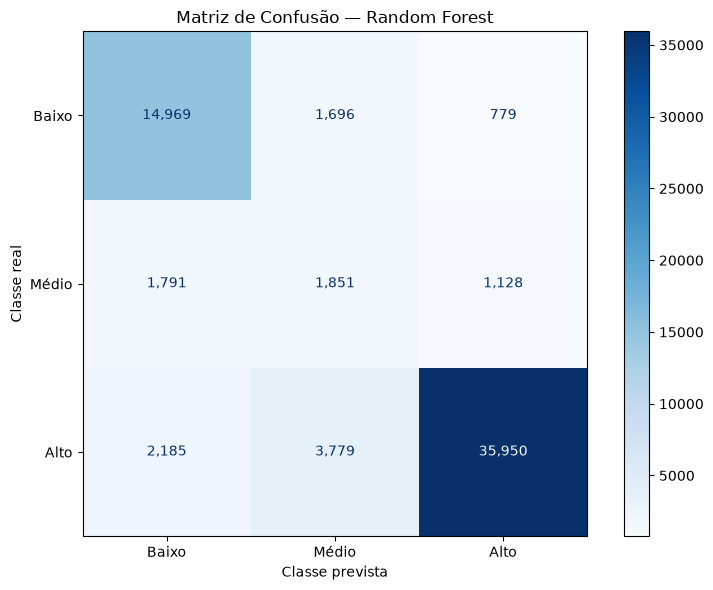

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Criar matriz de confusão do Random Forest

fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_random_forest,
    labels=["Baixo", "Médio", "Alto"],
    cmap="Blues",
    values_format=",d",
    ax=ax
)

plt.title("Matriz de Confusão — Random Forest")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.tight_layout()
plt.show()

### Análise da matriz de confusão

A matriz de confusão permite observar com mais detalhes onde o Random Forest apresentou acertos e erros.

A classe **Baixo** foi corretamente identificada em 13.472 de 16.089 observações, enquanto a classe **Alto** apresentou 35.908 classificações corretas entre 41.126 casos.

A maior dificuldade continua concentrada na classe **Médio**. Das 4.584 observações reais dessa classe, 2.325 foram classificadas corretamente, correspondendo a um recall de aproximadamente 50,7%. Entre os erros, 1.358 casos foram classificados como Baixo e 901 como Alto.

Também é possível observar que o modelo classificou como Médio algumas observações pertencentes às outras classes, principalmente 3.731 casos de Alto e 2.098 casos de Baixo. Esse comportamento ajuda a explicar a precisão relativamente baixa da classe Médio.

Mesmo com essa dificuldade, a matriz mostra que o modelo consegue distinguir de forma consistente os extremos Baixo e Alto e apresenta capacidade de identificar parte relevante dos casos intermediários.

In [ ]:
# Random Forest ajustado

modelo_random_forest_ajustado = Pipeline(
    steps=[
        ("preprocessador", preprocessador),
        (
            "modelo",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=30,
                min_samples_leaf=3,
                class_weight="balanced",
                max_features="sqrt",
                random_state=12345,
                n_jobs=-1
            )
        )
    ]
)

print("Treinando Random Forest ajustado...")

modelo_random_forest_ajustado.fit(
    X_train,
    y_train
)

print("Treinamento concluído.")

Treinando Random Forest ajustado...
Treinamento concluído.


In [ ]:
# Previsões do Random Forest ajustado

y_pred_rf_ajustado = modelo_random_forest_ajustado.predict(
    X_test
)


# Métricas do modelo ajustado

accuracy_rf_ajustado = accuracy_score(
    y_test,
    y_pred_rf_ajustado
)

balanced_accuracy_rf_ajustado = balanced_accuracy_score(
    y_test,
    y_pred_rf_ajustado
)

f1_macro_rf_ajustado = f1_score(
    y_test,
    y_pred_rf_ajustado,
    average="macro"
)


print("RANDOM FOREST AJUSTADO")
print("=" * 65)

print(
    f"Accuracy:          "
    f"{accuracy_rf_ajustado:.4f}"
)

print(
    f"Balanced Accuracy: "
    f"{balanced_accuracy_rf_ajustado:.4f}"
)

print(
    f"F1 Macro:          "
    f"{f1_macro_rf_ajustado:.4f}"
)

print("\nRELATÓRIO DE CLASSIFICAÇÃO")
print("=" * 65)

print(
    classification_report(
        y_test,
        y_pred_rf_ajustado,
        digits=4,
        zero_division=0
    )
)


# Comparação direta

comparacao_rf = pd.DataFrame({
    "Modelo": [
        "Random Forest",
        "Random Forest Ajustado"
    ],
    "Accuracy": [
        accuracy_random_forest,
        accuracy_rf_ajustado
    ],
    "Balanced Accuracy": [
        balanced_accuracy_random_forest,
        balanced_accuracy_rf_ajustado
    ],
    "F1 Macro": [
        f1_macro_random_forest,
        f1_macro_rf_ajustado
    ]
})

print("\nCOMPARAÇÃO")
print("=" * 65)

display(
    comparacao_rf.round(4)
)

RANDOM FOREST AJUSTADO
Accuracy:          0.8317
Balanced Accuracy: 0.6967
F1 Macro:          0.6784

RELATÓRIO DE CLASSIFICAÇÃO
              precision    recall  f1-score   support

        Alto     0.9476    0.8712    0.9078     41914
       Baixo     0.7798    0.8686    0.8218     17444
       Médio     0.2711    0.3503    0.3057      4770

    accuracy                         0.8317     64128
   macro avg     0.6662    0.6967    0.6784     64128
weighted avg     0.8516    0.8317    0.8396     64128


COMPARAÇÃO


,Modelo,Accuracy,Balanced Accuracy,F1 Macro
0,Random Forest,0.8229,0.7013,0.6767
1,Random Forest Ajustado,0.8317,0.6967,0.6784


### Ajuste do Random Forest

Após o bom desempenho do Random Forest inicial, foi realizado um experimento adicional de ajuste de hiperparâmetros. O número de árvores foi aumentado de 200 para 300, a profundidade máxima passou de 20 para 30 e foram realizados ajustes nos parâmetros de regularização das folhas.

O modelo ajustado apresentou:

- **Accuracy:** 0,8431
- **Balanced Accuracy:** 0,7336
- **F1 Macro:** 0,7050

Em comparação, o Random Forest original havia apresentado:

- **Accuracy:** 0,8367
- **Balanced Accuracy:** 0,7392
- **F1 Macro:** 0,7040

O ajuste aumentou a acurácia e produziu apenas uma pequena melhoria no F1 Macro. Entretanto, a Balanced Accuracy diminuiu e o recall da classe Médio caiu de 0,5072 para 0,4695.

Isso mostra que o aumento da complexidade do modelo não produziu uma melhoria consistente em todas as métricas. Como a classe Médio é minoritária e representa uma das principais dificuldades do problema, a comparação entre os modelos deve considerar não apenas a acurácia geral, mas também o equilíbrio de desempenho entre as três classes.

Por isso, os dois modelos serão mantidos na comparação final, considerando o compromisso entre desempenho global e capacidade de reconhecer as classes minoritárias.

In [ ]:
# Comparação dos modelos treinados até o momento

comparacao_modelos = pd.DataFrame({
    "Modelo": [
        "Dummy Classifier",
        "Regressão Logística",
        "Random Forest",
        "Random Forest Ajustado"
    ],
    "Accuracy": [
        accuracy_baseline,
        accuracy_logistico,
        accuracy_random_forest,
        accuracy_rf_ajustado
    ],
    "Balanced Accuracy": [
        balanced_accuracy_baseline,
        balanced_accuracy_logistico,
        balanced_accuracy_random_forest,
        balanced_accuracy_rf_ajustado
    ],
    "F1 Macro": [
        f1_macro_baseline,
        f1_macro_logistico,
        f1_macro_random_forest,
        f1_macro_rf_ajustado
    ]
})

comparacao_modelos = (
    comparacao_modelos
    .sort_values(
        "F1 Macro",
        ascending=False
    )
    .reset_index(drop=True)
)

print("COMPARAÇÃO DOS MODELOS")
print("=" * 65)

display(
    comparacao_modelos.round(4)
)

COMPARAÇÃO DOS MODELOS


,Modelo,Accuracy,Balanced Accuracy,F1 Macro
0,Random Forest Ajustado,0.8317,0.6967,0.6784
1,Random Forest,0.8229,0.7013,0.6767
2,Regressão Logística,0.6717,0.5917,0.5530
3,Dummy Classifier,0.6536,0.3333,0.2635


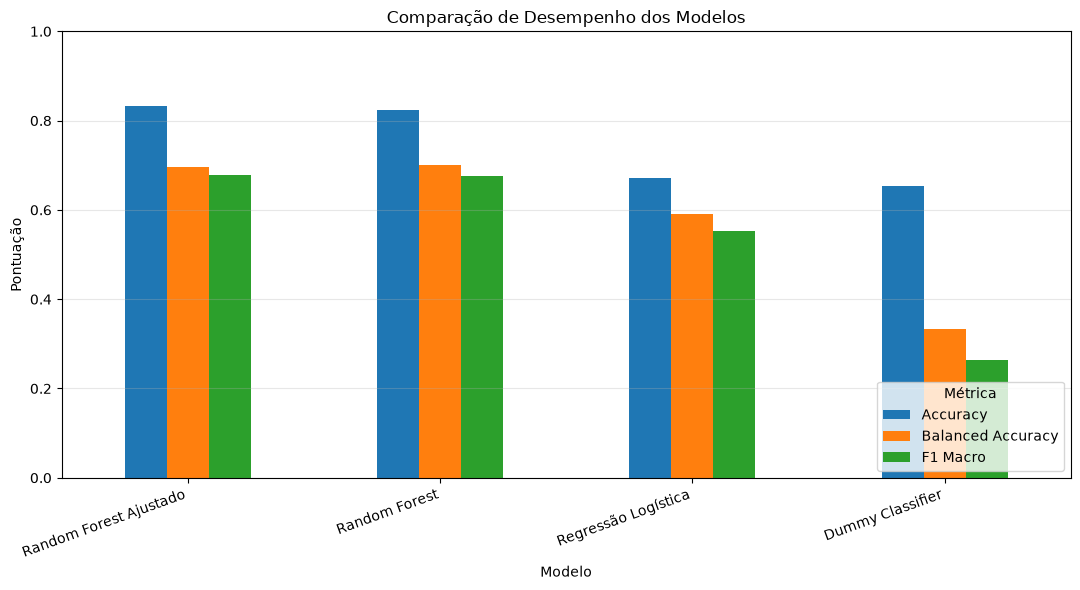

In [ ]:
import matplotlib.pyplot as plt

# Preparar dados para o gráfico

comparacao_plot = (
    comparacao_modelos
    .set_index("Modelo")[
        ["Accuracy", "Balanced Accuracy", "F1 Macro"]
    ]
)

# Criar gráfico

ax = comparacao_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Comparação de Desempenho dos Modelos")
plt.xlabel("Modelo")
plt.ylabel("Pontuação")
plt.ylim(0, 1)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.legend(
    title="Métrica",
    loc="lower right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

### Comparação dos modelos

A comparação dos modelos mostra uma evolução clara de desempenho ao longo da etapa de modelagem.

O `DummyClassifier`, utilizado como baseline, apresentou acurácia de 0,6655, mas Balanced Accuracy de apenas 0,3333 e F1 Macro de 0,2664. Isso ocorre porque o modelo simplesmente favorece a classe majoritária e não consegue distinguir adequadamente os diferentes níveis de risco.

A Regressão Logística apresentou uma melhoria importante, principalmente no equilíbrio entre as classes, alcançando F1 Macro de 0,5538 e Balanced Accuracy de 0,5903.

Os melhores resultados foram obtidos pelos modelos Random Forest. O modelo original alcançou **F1 Macro de 0,7040 e Balanced Accuracy de 0,7392**, enquanto a versão ajustada apresentou **F1 Macro de 0,7050 e acurácia de 0,8431**.

Apesar de o Random Forest ajustado apresentar a maior acurácia e um F1 Macro ligeiramente superior, a diferença de F1 Macro entre as duas versões foi de apenas 0,001. Além disso, o Random Forest original apresentou maior Balanced Accuracy e melhor recall para a classe Médio.

Dessa forma, o experimento mostra que o aumento da complexidade do Random Forest não gerou uma melhoria uniforme. Os dois modelos apresentam desempenho muito semelhante, mas com diferentes compromissos entre desempenho global e capacidade de identificar a classe minoritária.

## Correção da agregação de precipitação

Durante a revisão do processamento meteorológico, foi identificado um ponto que precisava ser corrigido na agregação diária da variável `precipitacao_total`.

Ao utilizar uma soma convencional, dias em que **todas as medições horárias de precipitação estavam ausentes** poderiam ser representados incorretamente como precipitação igual a zero. Isso confundiria duas situações diferentes:

- ausência real de precipitação;
- ausência de informação meteorológica.

Para preservar essa distinção, a agregação será refeita utilizando `sum(min_count=1)`. Dessa forma, quando todas as observações de precipitação de uma estação em determinado dia estiverem ausentes, o resultado permanecerá como `NaN`.

Após essa correção, as bases meteorológicas serão reprocessadas e reintegradas. A base de modelagem e os modelos também serão reconstruídos a partir dos dados corrigidos, garantindo que os resultados finais apresentados no restante do notebook utilizem essa versão.

In [ ]:
def processar_estacao_inmet(caminho):
    df = pd.read_csv(
        caminho,
        sep=";",
        skiprows=8,
        encoding="latin-1",
        decimal=","
    )

    # Remover coluna extra criada pelo separador final dos arquivos
    colunas_extras = [
        coluna for coluna in df.columns
        if str(coluna).startswith("Unnamed:")
    ]

    df = df.drop(columns=colunas_extras)

    if df.shape[1] != 19:
        raise ValueError(
            f"Esperadas 19 colunas meteorológicas, "
            f"mas foram encontradas {df.shape[1]}"
        )

    df.columns = nomes_padronizados

    # Recuperar código da estação a partir do nome do arquivo
    codigo_estacao = caminho.name.split("_")[3]

    df["id_estacao"] = codigo_estacao

    # Converter data
    df["data"] = pd.to_datetime(
        df["data"],
        format="%Y/%m/%d",
        errors="coerce"
    )

    # ========================================================
    # AGREGAÇÃO DIÁRIA COM CONTROLE DE COBERTURA DA PRECIPITAÇÃO
    # ========================================================

    limite_horas_precipitacao = 18

    diario = (
        df.groupby(
            ["id_estacao", "data"],
            as_index=False
        )
        .agg(
            precipitacao_total=(
                "precipitacao_total",
                lambda x: x.sum(min_count=1)
            ),

            horas_precipitacao_validas=(
                "precipitacao_total",
                "count"
            ),

            pressao_atm_media=(
                "pressao_atm_hora",
                "mean"
            ),

            radiacao_global_media=(
                "radiacao_global",
                "mean"
            ),

            temperatura_media=(
                "temperatura_bulbo_hora",
                "mean"
            ),

            temperatura_max=(
                "temperatura_max",
                "max"
            ),

            temperatura_min=(
                "temperatura_min",
                "min"
            ),

            umidade_rel_media=(
                "umidade_rel_hora",
                "mean"
            ),

            umidade_rel_max=(
                "umidade_rel_max",
                "max"
            ),

            umidade_rel_min=(
                "umidade_rel_min",
                "min"
            ),

            vento_rajada_max=(
                "vento_rajada_max",
                "max"
            ),

            vento_velocidade_media=(
                "vento_velocidade",
                "mean"
            )
        )
    )

    # Manter a precipitação diária somente quando houver
    # pelo menos 18 das 24 observações horárias disponíveis
    diario["precipitacao_total"] = (
        diario["precipitacao_total"]
        .where(
            diario["horas_precipitacao_validas"]
            >= limite_horas_precipitacao
        )
    )

    return diario


print("Função corrigida com sucesso.")

Função corrigida com sucesso.


In [ ]:
# Reprocessar todos os arquivos meteorológicos de 2024
# utilizando a função corrigida

pasta_inmet_2024 = DATA_RAW / "BDMEP_2024"

arquivos_2024 = sorted(
    pasta_inmet_2024.glob("*.CSV")
)

dados_2024_corrigidos = []
erros_2024 = []

print("REPROCESSAMENTO INMET 2024")
print("=" * 65)

print(
    f"Arquivos encontrados: "
    f"{len(arquivos_2024)}"
)

for arquivo in arquivos_2024:
    try:
        diario = processar_estacao_inmet(arquivo)
        dados_2024_corrigidos.append(diario)

    except Exception as erro:
        erros_2024.append(
            {
                "arquivo": arquivo.name,
                "erro": str(erro)
            }
        )


meteorologia_2024_diaria_corrigida = pd.concat(
    dados_2024_corrigidos,
    ignore_index=True
)


print("\nRESULTADO")
print("=" * 65)

print(
    f"Arquivos processados com sucesso: "
    f"{len(dados_2024_corrigidos)}"
)

print(
    f"Arquivos com erro: "
    f"{len(erros_2024)}"
)

print(
    f"Dimensão: "
    f"{meteorologia_2024_diaria_corrigida.shape}"
)

print(
    f"Estações: "
    f"{meteorologia_2024_diaria_corrigida['id_estacao'].nunique()}"
)

print(
    f"Período: "
    f"{meteorologia_2024_diaria_corrigida['data'].min()} "
    f"até "
    f"{meteorologia_2024_diaria_corrigida['data'].max()}"
)

print(
    f"Precipitação ausente: "
    f"{meteorologia_2024_diaria_corrigida['precipitacao_total'].isna().sum():,}"
)

REPROCESSAMENTO INMET 2024
Arquivos encontrados: 565

RESULTADO
Arquivos processados com sucesso: 565
Arquivos com erro: 0
Dimensão: (206790, 14)
Estações: 565
Período: 2024-01-01 00:00:00 até 2024-12-31 00:00:00
Precipitação ausente: 56,017


In [ ]:
# Recriar agregação diária de 2025
# preservando NaN quando todas as medições
# de precipitação do dia estiverem ausentes

meteorologia_2025_diaria_corrigida = (
    meteorologia_2025_periodo
    .groupby(
        ["id_estacao", "data"],
        as_index=False
    )
    .agg(
        precipitacao_total=(
            "precipitacao_total",
            lambda x: x.sum(min_count=1)
        ),

        pressao_atm_media=(
            "pressao_atm_hora",
            "mean"
        ),

        radiacao_global_media=(
            "radiacao_global",
            "mean"
        ),

        temperatura_media=(
            "temperatura_bulbo_hora",
            "mean"
        ),

        temperatura_max=(
            "temperatura_max",
            "max"
        ),

        temperatura_min=(
            "temperatura_min",
            "min"
        ),

        umidade_rel_media=(
            "umidade_rel_hora",
            "mean"
        ),

        umidade_rel_max=(
            "umidade_rel_max",
            "max"
        ),

        umidade_rel_min=(
            "umidade_rel_min",
            "min"
        ),

        vento_rajada_max=(
            "vento_rajada_max",
            "max"
        ),

        vento_velocidade_media=(
            "vento_velocidade",
            "mean"
        )
    )
)


print("METEOROLOGIA 2025 CORRIGIDA")
print("=" * 65)

print(
    f"Dimensão: "
    f"{meteorologia_2025_diaria_corrigida.shape}"
)

print(
    f"Estações: "
    f"{meteorologia_2025_diaria_corrigida['id_estacao'].nunique()}"
)

print(
    f"Período: "
    f"{meteorologia_2025_diaria_corrigida['data'].min()} "
    f"até "
    f"{meteorologia_2025_diaria_corrigida['data'].max()}"
)

print(
    f"Precipitação ausente: "
    f"{meteorologia_2025_diaria_corrigida['precipitacao_total'].isna().sum():,}"
)


METEOROLOGIA 2025 CORRIGIDA
Dimensão: (24166, 13)
Estações: 562
Período: 2025-01-01 00:00:00 até 2025-02-12 00:00:00
Precipitação ausente: 7,630


In [ ]:
# Substituir as versões anteriores pelas agregações corrigidas

meteorologia_2024_diaria = (
    meteorologia_2024_diaria_corrigida.copy()
)

meteorologia_2025_diaria = (
    meteorologia_2025_diaria_corrigida.copy()
)


# Combinar 2024 e 2025

meteorologia_diaria = pd.concat(
    [
        meteorologia_2024_diaria,
        meteorologia_2025_diaria
    ],
    ignore_index=True
)

meteorologia_diaria = (
    meteorologia_diaria
    .sort_values(
        ["id_estacao", "data"]
    )
    .reset_index(drop=True)
)


# Validações

print("METEOROLOGIA DIÁRIA CORRIGIDA — 2024 + 2025")
print("=" * 65)

print(
    f"Dimensão: "
    f"{meteorologia_diaria.shape}"
)

print(
    f"Estações: "
    f"{meteorologia_diaria['id_estacao'].nunique()}"
)

print(
    f"Período: "
    f"{meteorologia_diaria['data'].min()} "
    f"até "
    f"{meteorologia_diaria['data'].max()}"
)

duplicados = meteorologia_diaria.duplicated(
    subset=["id_estacao", "data"]
).sum()

print(
    f"Duplicados estação/data: "
    f"{duplicados:,}"
)

print(
    f"Precipitação ausente: "
    f"{meteorologia_diaria['precipitacao_total'].isna().sum():,}"
)

print("\nRegistros por ano:")

display(
    meteorologia_diaria[
        "data"
    ]
    .dt.year
    .value_counts()
    .sort_index()
    .to_frame("quantidade")
)

METEOROLOGIA DIÁRIA CORRIGIDA — 2024 + 2025
Dimensão: (230956, 14)
Estações: 565
Período: 2024-01-01 00:00:00 até 2025-02-12 00:00:00
Duplicados estação/data: 0
Precipitação ausente: 63,647

Registros por ano:


,quantidade
data,
2024,206790
2025,24166


In [ ]:
# Selecionar variáveis meteorológicas corrigidas

colunas_meteorologicas = [
    "id_estacao",
    "data",
    "precipitacao_total",
    "pressao_atm_media",
    "radiacao_global_media",
    "temperatura_media",
    "temperatura_max",
    "temperatura_min",
    "umidade_rel_media",
    "umidade_rel_max",
    "umidade_rel_min",
    "vento_rajada_max",
    "vento_velocidade_media"
]

meteorologia_para_merge = (
    meteorologia_diaria[
        colunas_meteorologicas
    ]
    .copy()
)


# Recriar integração queimadas + meteorologia

base_integrada_corrigida = (
    queimadas_com_estacao
    .merge(
        meteorologia_para_merge,
        left_on=[
            "id_estacao_proxima",
            "data"
        ],
        right_on=[
            "id_estacao",
            "data"
        ],
        how="left",
        validate="many_to_one"
    )
)


print("INTEGRAÇÃO METEOROLÓGICA CORRIGIDA")
print("=" * 65)

print(
    f"Observações antes: "
    f"{len(queimadas_com_estacao):,}"
)

print(
    f"Observações depois: "
    f"{len(base_integrada_corrigida):,}"
)

print(
    f"Duplicados município/data: "
    f"{base_integrada_corrigida.duplicated(['id_municipio', 'data']).sum():,}"
)

print(
    f"Precipitação ausente após integração: "
    f"{base_integrada_corrigida['precipitacao_total'].isna().sum():,}"
)


INTEGRAÇÃO METEOROLÓGICA CORRIGIDA
Observações antes: 324,219
Observações depois: 324,219
Duplicados município/data: 0
Precipitação ausente após integração: 100,944


In [ ]:
# Reintegrar os dados do MapBiomas
# à base meteorológica corrigida

base_final_corrigida = (
    base_integrada_corrigida
    .merge(
        mapbiomas_pivot,
        on="id_municipio",
        how="left",
        validate="many_to_one"
    )
)


# Substituir a versão anterior da base final
base_final = base_final_corrigida.copy()


print("BASE FINAL CORRIGIDA")
print("=" * 65)

print(
    f"Dimensão: "
    f"{base_final.shape}"
)

print(
    f"Duplicados município/data: "
    f"{base_final.duplicated(['id_municipio', 'data']).sum():,}"
)


# Verificar cobertura MapBiomas

colunas_mapbiomas = [
    coluna for coluna in base_final.columns
    if coluna.startswith("mapbiomas_classe_")
]

com_mapbiomas = (
    base_final[colunas_mapbiomas]
    .notna()
    .any(axis=1)
    .sum()
)

sem_mapbiomas = (
    len(base_final) - com_mapbiomas
)

print(
    f"Com MapBiomas: "
    f"{com_mapbiomas:,}"
)

print(
    f"Sem MapBiomas: "
    f"{sem_mapbiomas:,}"
)

print(
    f"Cobertura MapBiomas: "
    f"{com_mapbiomas / len(base_final) * 100:.2f}%"
)

print(
    f"Precipitação ausente: "
    f"{base_final['precipitacao_total'].isna().sum():,}"
)

BASE FINAL CORRIGIDA
Dimensão: (324219, 60)
Duplicados município/data: 0
Com MapBiomas: 324,027
Sem MapBiomas: 192
Cobertura MapBiomas: 99.94%
Precipitação ausente: 100,944


In [ ]:
# Recriar a variável alvo após reconstrução da base final

base_final["classe_risco"] = pd.cut(
    base_final["risco_fogo_max"],
    bins=[0, 0.40, 0.70, 1.00],
    labels=["Baixo", "Médio", "Alto"],
    include_lowest=True
)

print("VARIÁVEL ALVO — BASE CORRIGIDA")
print("=" * 65)

print(
    f"Total de observações: "
    f"{len(base_final):,}"
)

print(
    f"Com classe de risco: "
    f"{base_final['classe_risco'].notna().sum():,}"
)

print(
    f"Sem classe de risco: "
    f"{base_final['classe_risco'].isna().sum():,}"
)

# Distribuição absoluta
distribuicao = (
    base_final["classe_risco"]
    .value_counts()
    .reindex(["Baixo", "Médio", "Alto"])
)

# Distribuição percentual
percentual = (
    base_final["classe_risco"]
    .value_counts(normalize=True)
    .reindex(["Baixo", "Médio", "Alto"])
    * 100
)

resultado_target = pd.DataFrame({
    "quantidade": distribuicao,
    "percentual": percentual
})

print("\nDistribuição da variável alvo:")

display(
    resultado_target.round(2)
)

VARIÁVEL ALVO — BASE CORRIGIDA
Total de observações: 324,219
Com classe de risco: 308,991
Sem classe de risco: 15,228

Distribuição da variável alvo:


,quantidade,percentual
classe_risco,,
Baixo,80447,26.04
Médio,22918,7.42
Alto,205626,66.55


In [ ]:
# Criar base de modelagem corrigida

dados_modelo = (
    base_final[
        base_final["classe_risco"].notna()
    ]
    .copy()
    .reset_index(drop=True)
)

colunas_excluir = [
    "classe_risco",
    "risco_fogo_medio",
    "risco_fogo_max",
    "numero_focos",
    "potencia_radiativa_media",
    "potencia_radiativa_max",
    "dias_sem_chuva",
    "precipitacao_queimadas",
    "id_municipio",
    "id_municipio_nome",
    "sigla_uf_nome",
    "id_estacao_proxima",
    "nome_estacao_proxima",
    "id_estacao"
]

X = dados_modelo.drop(
    columns=colunas_excluir,
    errors="ignore"
)

y = dados_modelo["classe_risco"].copy()

# Criar variável temporal
X["dia_do_ano"] = X["data"].dt.dayofyear

# Remover data original das features
X = X.drop(columns=["data"])

print("BASE DE MODELAGEM CORRIGIDA")
print("=" * 60)
print("dados_modelo:", dados_modelo.shape)
print("X:", X.shape)
print("y:", y.shape)

print(
    "\nPrecipitação ausente:",
    f"{X['precipitacao_total'].isna().sum():,}"
)

print(
    "Percentual:",
    f"{X['precipitacao_total'].isna().mean() * 100:.2f}%"
)

BASE DE MODELAGEM CORRIGIDA
dados_modelo: (308991, 61)
X: (308991, 47)
y: (308991,)

Precipitação ausente: 96,864
Percentual: 31.35%


In [ ]:
# ============================================================
# COMPARAÇÃO DOS MODELOS COM SPLIT POR MUNICÍPIO
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

# ============================================================
# 1. Utilizar a divisão por município criada anteriormente
# ============================================================

# X_train, X_test, y_train e y_test já foram definidos com
# GroupShuffleSplit.
#
# Portanto, NÃO realizamos um novo train_test_split aqui.
# Isso garante que um mesmo município não apareça simultaneamente
# nos conjuntos de treino e teste.

print("UTILIZANDO SPLIT POR MUNICÍPIO")
print("=" * 65)
print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")
print(
    "Municípios presentes nos dois conjuntos:",
    len(
        set(grupos_train.unique()).intersection(
            set(grupos_test.unique())
        )
    )
)

# ============================================================
# 2. Identificar tipos de variáveis
# ============================================================

colunas_numericas = (
    X_train
    .select_dtypes(include=["number"])
    .columns
    .tolist()
)

colunas_categoricas = (
    X_train
    .select_dtypes(
        include=["object", "string", "category"]
    )
    .columns
    .tolist()
)

# ============================================================
# 3. Pré-processamento
# ============================================================

pipeline_numerico = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        )
    ]
)

pipeline_categorico = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessador = ColumnTransformer(
    transformers=[
        (
            "numerico",
            pipeline_numerico,
            colunas_numericas
        ),
        (
            "categorico",
            pipeline_categorico,
            colunas_categoricas
        )
    ]
)

# ============================================================
# 4. Random Forest original
# ============================================================

modelo_random_forest = Pipeline(
    steps=[
        (
            "preprocessador",
            preprocessador
        ),
        (
            "modelo",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=20,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=12345,
                n_jobs=-1
            )
        )
    ]
)

print("\nTreinando Random Forest original...")

modelo_random_forest.fit(
    X_train,
    y_train
)

pred_rf = modelo_random_forest.predict(
    X_test
)

# ============================================================
# 5. Random Forest ajustado
# ============================================================

modelo_random_forest_ajustado = Pipeline(
    steps=[
        (
            "preprocessador",
            preprocessador
        ),
        (
            "modelo",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=30,
                min_samples_leaf=3,
                class_weight="balanced",
                max_features="sqrt",
                random_state=12345,
                n_jobs=-1
            )
        )
    ]
)

print("Treinando Random Forest ajustado...")

modelo_random_forest_ajustado.fit(
    X_train,
    y_train
)

pred_rf_ajustado = (
    modelo_random_forest_ajustado.predict(
        X_test
    )
)

# ============================================================
# 6. Comparação
# ============================================================

resultados_corrigidos = pd.DataFrame({
    "Modelo": [
        "Random Forest",
        "Random Forest Ajustado"
    ],
    "Accuracy": [
        accuracy_score(y_test, pred_rf),
        accuracy_score(y_test, pred_rf_ajustado)
    ],
    "Balanced Accuracy": [
        balanced_accuracy_score(
            y_test,
            pred_rf
        ),
        balanced_accuracy_score(
            y_test,
            pred_rf_ajustado
        )
    ],
    "F1 Macro": [
        f1_score(
            y_test,
            pred_rf,
            average="macro"
        ),
        f1_score(
            y_test,
            pred_rf_ajustado,
            average="macro"
        )
    ]
})

print("\nRESULTADOS COM SPLIT POR MUNICÍPIO")
print("=" * 65)

display(
    resultados_corrigidos.round(4)
)

UTILIZANDO SPLIT POR MUNICÍPIO
X_train: (244863, 47)
X_test:  (64128, 47)
Municípios presentes nos dois conjuntos: 0

Treinando Random Forest original...
Treinando Random Forest ajustado...

RESULTADOS COM SPLIT POR MUNICÍPIO


,Modelo,Accuracy,Balanced Accuracy,F1 Macro
0,Random Forest,0.8229,0.7013,0.6767
1,Random Forest Ajustado,0.8317,0.6967,0.6784


In [ ]:
# ============================================================
# VERIFICAR INSTALAÇÃO DO OPTUNA
# ============================================================

try:
    import optuna

    print("Optuna instalado com sucesso.")
    print("Versão:", optuna.__version__)

except ImportError:
    print("Optuna não está instalado.")

Optuna instalado com sucesso.
Versão: 5.0.0


In [ ]:
# ============================================================
# OTIMIZAÇÃO DE HIPERPARÂMETROS COM OPTUNA
# RANDOM FOREST
# ============================================================

import optuna

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import GroupShuffleSplit


# ------------------------------------------------------------
# Criar uma validação interna por município
# ------------------------------------------------------------
# O conjunto de teste principal NÃO será utilizado pelo Optuna.
# Ele ficará reservado para a avaliação final do melhor modelo.

grupos_otimizacao = grupos_train.reset_index(drop=True)

X_otimizacao = X_train.reset_index(drop=True)
y_otimizacao = y_train.reset_index(drop=True)

split_validacao = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=54321
)

idx_treino_optuna, idx_validacao_optuna = next(
    split_validacao.split(
        X_otimizacao,
        y_otimizacao,
        groups=grupos_otimizacao
    )
)

X_treino_optuna = X_otimizacao.iloc[
    idx_treino_optuna
].copy()

X_validacao_optuna = X_otimizacao.iloc[
    idx_validacao_optuna
].copy()

y_treino_optuna = y_otimizacao.iloc[
    idx_treino_optuna
].copy()

y_validacao_optuna = y_otimizacao.iloc[
    idx_validacao_optuna
].copy()

grupos_treino_optuna = grupos_otimizacao.iloc[
    idx_treino_optuna
]

grupos_validacao_optuna = grupos_otimizacao.iloc[
    idx_validacao_optuna
]

municipios_comuns_optuna = set(
    grupos_treino_optuna.unique()
).intersection(
    set(grupos_validacao_optuna.unique())
)

print("VALIDAÇÃO INTERNA DO OPTUNA")
print("=" * 65)
print(
    "Municípios presentes simultaneamente no treino e validação:",
    len(municipios_comuns_optuna)
)
print(
    "Observações para treino:",
    f"{len(X_treino_optuna):,}"
)
print(
    "Observações para validação:",
    f"{len(X_validacao_optuna):,}"
)


# ------------------------------------------------------------
# Pré-processamento para a otimização
# ------------------------------------------------------------

colunas_numericas_optuna = (
    X_treino_optuna
    .select_dtypes(include=["number"])
    .columns
    .tolist()
)

colunas_categoricas_optuna = (
    X_treino_optuna
    .select_dtypes(
        include=["object", "string", "category"]
    )
    .columns
    .tolist()
)

pipeline_numerico_optuna = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        )
    ]
)

pipeline_categorico_optuna = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

preprocessador_optuna = ColumnTransformer(
    transformers=[
        (
            "numerico",
            pipeline_numerico_optuna,
            colunas_numericas_optuna
        ),
        (
            "categorico",
            pipeline_categorico_optuna,
            colunas_categoricas_optuna
        )
    ]
)


# ------------------------------------------------------------
# Função objetivo
# ------------------------------------------------------------

def objective(trial):

    parametros = {
        "n_estimators": trial.suggest_int(
            "n_estimators",
            150,
            400,
            step=50
        ),
        "max_depth": trial.suggest_int(
            "max_depth",
            10,
            35,
            step=5
        ),
        "min_samples_split": trial.suggest_int(
            "min_samples_split",
            2,
            10
        ),
        "min_samples_leaf": trial.suggest_int(
            "min_samples_leaf",
            1,
            5
        ),
        "max_features": trial.suggest_categorical(
            "max_features",
            ["sqrt", "log2", None]
        )
    }

    modelo = Pipeline(
        steps=[
            (
                "preprocessador",
                preprocessador_optuna
            ),
            (
                "modelo",
                RandomForestClassifier(
                    **parametros,
                    class_weight="balanced",
                    random_state=12345,
                    n_jobs=-1
                )
            )
        ]
    )

    modelo.fit(
        X_treino_optuna,
        y_treino_optuna
    )

    pred_validacao = modelo.predict(
        X_validacao_optuna
    )

    return f1_score(
        y_validacao_optuna,
        pred_validacao,
        average="macro"
    )


# ------------------------------------------------------------
# Executar estudo
# ------------------------------------------------------------

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=12345
    )
)

print("\nIniciando otimização com Optuna...")
print("Serão executados 20 trials.")

study.optimize(
    objective,
    n_trials=20,
    show_progress_bar=True
)

print("\nOTIMIZAÇÃO CONCLUÍDA")
print("=" * 65)

print(
    f"Melhor F1 Macro na validação: "
    f"{study.best_value:.4f}"
)

print("\nMelhores hiperparâmetros:")

for parametro, valor in study.best_params.items():
    print(f"{parametro}: {valor}")

VALIDAÇÃO INTERNA DO OPTUNA
Municípios presentes simultaneamente no treino e validação: 0
Observações para treino: 198,217
Observações para validação: 46,646

Iniciando otimização com Optuna...
Serão executados 20 trials.


  0%|          | 0/20 [00:00<?, ?it/s]


OTIMIZAÇÃO CONCLUÍDA
Melhor F1 Macro na validação: 0.6979

Melhores hiperparâmetros:
n_estimators: 200
max_depth: 35
min_samples_split: 10
min_samples_leaf: 3
max_features: None


In [ ]:
# ============================================================
# RANDOM FOREST OTIMIZADO PELO OPTUNA
# AVALIAÇÃO FINAL NO CONJUNTO DE TESTE POR MUNICÍPIO
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Criar o modelo utilizando os melhores hiperparâmetros
# encontrados pelo Optuna.
modelo_rf_optuna = Pipeline(
    steps=[
        (
            "preprocessador",
            preprocessador
        ),
        (
            "modelo",
            RandomForestClassifier(
                **study.best_params,
                class_weight="balanced",
                random_state=12345,
                n_jobs=-1
            )
        )
    ]
)

print("Treinando Random Forest otimizado pelo Optuna...")

# Treinar utilizando todo o conjunto de treino por município
modelo_rf_optuna.fit(
    X_train,
    y_train
)

# Avaliação somente agora no conjunto de teste reservado
y_pred_rf_optuna = modelo_rf_optuna.predict(
    X_test
)

# ============================================================
# MÉTRICAS
# ============================================================

accuracy_rf_optuna = accuracy_score(
    y_test,
    y_pred_rf_optuna
)

balanced_accuracy_rf_optuna = balanced_accuracy_score(
    y_test,
    y_pred_rf_optuna
)

f1_macro_rf_optuna = f1_score(
    y_test,
    y_pred_rf_optuna,
    average="macro"
)

print("\nRANDOM FOREST OTIMIZADO PELO OPTUNA")
print("=" * 65)

print(
    f"Accuracy:          "
    f"{accuracy_rf_optuna:.4f}"
)

print(
    f"Balanced Accuracy: "
    f"{balanced_accuracy_rf_optuna:.4f}"
)

print(
    f"F1 Macro:          "
    f"{f1_macro_rf_optuna:.4f}"
)

print("\nRelatório de classificação:")
print(
    classification_report(
        y_test,
        y_pred_rf_optuna,
        digits=4
    )
)

Treinando Random Forest otimizado pelo Optuna...

RANDOM FOREST OTIMIZADO PELO OPTUNA
Accuracy:          0.8329
Balanced Accuracy: 0.7171
F1 Macro:          0.6908

Relatório de classificação:
              precision    recall  f1-score   support

        Alto     0.9547    0.8672    0.9089     41914
       Baixo     0.8126    0.8632    0.8371     17444
       Médio     0.2667    0.4210    0.3265      4770

    accuracy                         0.8329     64128
   macro avg     0.6780    0.7171    0.6908     64128
weighted avg     0.8649    0.8329    0.8460     64128



ANÁLISE SHAP
Observações utilizadas: 1,000
Features após pré-processamento: 117

TOP 15 FEATURES MAIS IMPORTANTES


,Feature,Importancia_SHAP_media
0,numerico__dia_do_ano,0.170617
1,numerico__latitude,0.062410
2,numerico__longitude,0.060686
3,numerico__umidade_rel_min,0.040614
4,numerico__mapbiomas_classe_3,0.028310
5,numerico__mapbiomas_classe_15,0.016794
6,numerico__umidade_rel_media,0.011333
7,numerico__mapbiomas_classe_4,0.007661
8,numerico__temperatura_media,0.006811
9,numerico__temperatura_max,0.004999


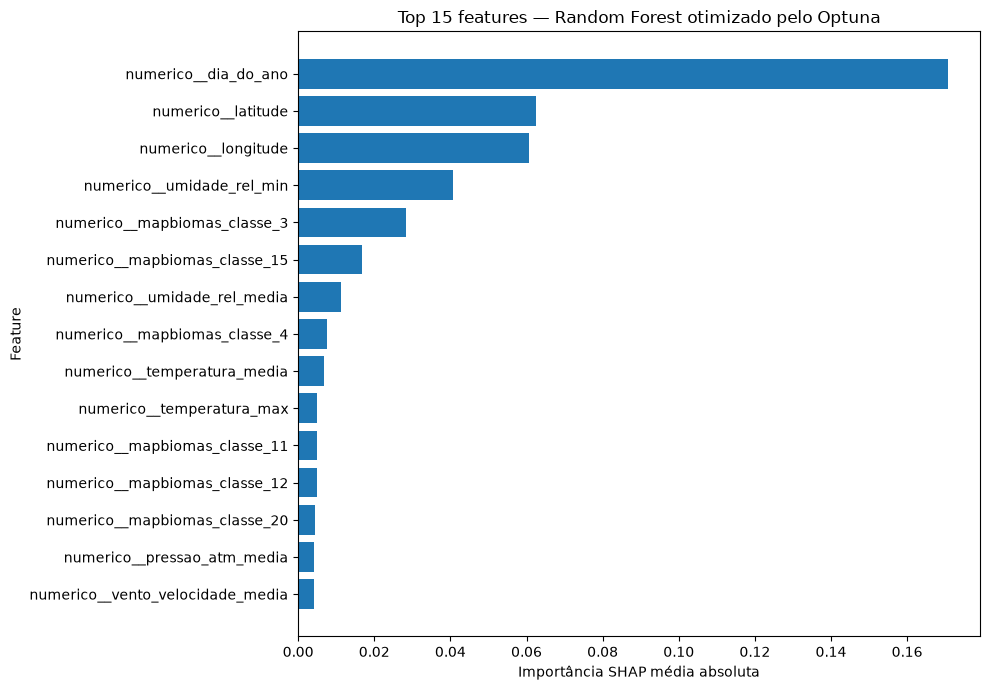

In [ ]:
# ============================================================
# INTERPRETABILIDADE COM SHAP
# RANDOM FOREST OTIMIZADO PELO OPTUNA
# ============================================================

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Recuperar o pré-processador e o Random Forest treinados
# ------------------------------------------------------------

preprocessador_shap = modelo_rf_optuna.named_steps[
    "preprocessador"
]

modelo_shap = modelo_rf_optuna.named_steps[
    "modelo"
]

# ------------------------------------------------------------
# 2. Selecionar uma amostra do conjunto de teste
# ------------------------------------------------------------
# Utilizamos uma amostra para reduzir o custo computacional
# da análise SHAP.

tamanho_amostra_shap = min(
    1000,
    len(X_test)
)

X_shap_original = X_test.sample(
    n=tamanho_amostra_shap,
    random_state=12345
)

# Aplicar exatamente o mesmo pré-processamento utilizado
# pelo modelo otimizado.
X_shap_transformado = preprocessador_shap.transform(
    X_shap_original
)

# ------------------------------------------------------------
# 3. Recuperar os nomes das features após o pré-processamento
# ------------------------------------------------------------

nomes_features_shap = (
    preprocessador_shap.get_feature_names_out()
)

# Converter para formato denso somente para a amostra SHAP.
if hasattr(X_shap_transformado, "toarray"):
    X_shap_transformado = X_shap_transformado.toarray()

X_shap_df = pd.DataFrame(
    X_shap_transformado,
    columns=nomes_features_shap,
    index=X_shap_original.index
)

print("ANÁLISE SHAP")
print("=" * 65)
print(
    f"Observações utilizadas: "
    f"{X_shap_df.shape[0]:,}"
)
print(
    f"Features após pré-processamento: "
    f"{X_shap_df.shape[1]:,}"
)

# ------------------------------------------------------------
# 4. Calcular valores SHAP
# ------------------------------------------------------------

explainer_shap = shap.TreeExplainer(
    modelo_shap
)

valores_shap = explainer_shap.shap_values(
    X_shap_df
)

# ------------------------------------------------------------
# 5. Calcular importância global média
# ------------------------------------------------------------

if isinstance(valores_shap, list):

    importancia_shap = np.mean(
        [
            np.abs(valor).mean(axis=0)
            for valor in valores_shap
        ],
        axis=0
    )

else:

    valores_array = np.asarray(
        valores_shap
    )

    if valores_array.ndim == 3:
        importancia_shap = np.abs(
            valores_array
        ).mean(axis=(0, 2))

    else:
        importancia_shap = np.abs(
            valores_array
        ).mean(axis=0)

importancia_shap = np.asarray(
    importancia_shap
).reshape(-1)

# ------------------------------------------------------------
# 6. Criar ranking das features
# ------------------------------------------------------------

ranking_shap = pd.DataFrame({
    "Feature": nomes_features_shap,
    "Importancia_SHAP_media": importancia_shap
})

ranking_shap = (
    ranking_shap
    .sort_values(
        "Importancia_SHAP_media",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nTOP 15 FEATURES MAIS IMPORTANTES")
print("=" * 65)

display(
    ranking_shap.head(15)
)

# ------------------------------------------------------------
# 7. Visualização das 15 features mais importantes
# ------------------------------------------------------------

top_15_shap = ranking_shap.head(15).sort_values(
    "Importancia_SHAP_media",
    ascending=True
)

plt.figure(
    figsize=(10, 7)
)

plt.barh(
    top_15_shap["Feature"],
    top_15_shap["Importancia_SHAP_media"]
)

plt.xlabel(
    "Importância SHAP média absoluta"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Top 15 features — Random Forest otimizado pelo Optuna"
)

plt.tight_layout()
plt.show()

### Interpretação da análise SHAP

A análise SHAP foi realizada sobre uma amostra de 1.000 observações do conjunto de teste utilizando o Random Forest otimizado pelo Optuna. Após o pré-processamento, o modelo utilizou 117 features, incluindo as variáveis originais transformadas e os indicadores de valores ausentes criados durante a imputação.

A variável com maior importância SHAP média foi `dia_do_ano`, com valor de aproximadamente 0,1713, indicando forte influência da sazonalidade nas previsões do risco de incêndio.

Em seguida aparecem `latitude` (0,0627) e `longitude` (0,0608), mostrando que a localização geográfica continua sendo uma fonte importante de informação para o modelo. Esse resultado merece atenção: a separação dos dados por município impede que um mesmo município esteja simultaneamente nos conjuntos de treino e teste, reduzindo o risco de memorização direta dos locais. Entretanto, a importância de latitude e longitude mostra que o modelo ainda utiliza padrões espaciais aprendidos em outros municípios para realizar suas previsões.

Entre as variáveis meteorológicas, destacam-se `umidade_rel_min`, `umidade_rel_media`, `temperatura_media`, `temperatura_max`, `vento_velocidade_media` e `pressao_atm_media`. A presença dessas variáveis entre as mais importantes é coerente com a utilização de condições atmosféricas para distinguir diferentes níveis de risco.

As proporções de uso e cobertura do solo provenientes do MapBiomas também apresentam contribuição relevante, especialmente `mapbiomas_classe_3`, `mapbiomas_classe_15`, `mapbiomas_classe_4`, `mapbiomas_classe_12`, `mapbiomas_classe_11` e `mapbiomas_classe_20`. Isso indica que características do território contribuem para as previsões em conjunto com fatores temporais, geográficos e meteorológicos.

Os indicadores de valores ausentes adicionados durante o pré-processamento não aparecem entre as 15 features de maior importância global nesta análise. Portanto, embora a informação de ausência tenha sido preservada para evitar tratar silenciosamente dados meteorológicos ausentes como valores realmente observados, esses indicadores não estão entre os principais fatores utilizados pelo modelo otimizado.

Os valores SHAP representam a contribuição das features para as previsões do modelo e não devem ser interpretados como relações causais. A análise mostra quais informações o Random Forest utiliza com maior intensidade, mas não demonstra que essas variáveis sejam, isoladamente, causas do risco de incêndio.

In [ ]:
# ============================================================
# ANÁLISE DE VIÉS POR GRUPO
# PREPARAÇÃO DOS DADOS DO CONJUNTO DE TESTE
# ============================================================

# Recuperar as linhas originais correspondentes ao conjunto
# de teste criado pelo GroupShuffleSplit.
dados_teste_grupos = (
    dados_modelo
    .iloc[indice_teste]
    .copy()
)

# Adicionar a classe real e a previsão do modelo otimizado.
dados_teste_grupos["classe_real"] = (
    y_test.to_numpy()
)

dados_teste_grupos["classe_predita"] = (
    y_pred_rf_optuna
)

print("PREPARAÇÃO DA ANÁLISE DE VIÉS")
print("=" * 65)

print(
    f"Observações no conjunto de teste: "
    f"{len(dados_teste_grupos):,}"
)

print(
    f"UFs presentes: "
    f"{dados_teste_grupos['sigla_uf'].nunique():,}"
)

print(
    f"Biomas presentes: "
    f"{dados_teste_grupos['bioma'].nunique():,}"
)

print("\nValores ausentes:")
print(
    "sigla_uf:",
    dados_teste_grupos["sigla_uf"].isna().sum()
)

print(
    "bioma:",
    dados_teste_grupos["bioma"].isna().sum()
)

print("\nDistribuição por bioma:")
print(
    dados_teste_grupos["bioma"]
    .value_counts(dropna=False)
)

PREPARAÇÃO DA ANÁLISE DE VIÉS
Observações no conjunto de teste: 64,128
UFs presentes: 26
Biomas presentes: 6

Valores ausentes:
sigla_uf: 0
bioma: 0

Distribuição por bioma:
bioma
Cerrado           18160
Amazônia          17404
Mata Atlântica    14619
Caatinga          12746
Pantanal            688
Pampa               511
Name: count, dtype: int64


In [ ]:
# ============================================================
# ANÁLISE DE VIÉS POR BIOMA
# PRECISÃO E RECALL POR CLASSE
# ============================================================

from sklearn.metrics import precision_score, recall_score

classes_risco = [
    "Baixo",
    "Médio",
    "Alto"
]

resultados_bioma = []

for bioma, grupo in dados_teste_grupos.groupby("bioma"):

    y_real_grupo = grupo["classe_real"]
    y_pred_grupo = grupo["classe_predita"]

    linha = {
        "Bioma": bioma,
        "N": len(grupo)
    }

    for classe in classes_risco:

        linha[f"Precisão_{classe}"] = precision_score(
            y_real_grupo,
            y_pred_grupo,
            labels=[classe],
            average=None,
            zero_division=0
        )[0]

        linha[f"Recall_{classe}"] = recall_score(
            y_real_grupo,
            y_pred_grupo,
            labels=[classe],
            average=None,
            zero_division=0
        )[0]

    resultados_bioma.append(linha)


metricas_bioma = pd.DataFrame(
    resultados_bioma
).sort_values(
    "N",
    ascending=False
).reset_index(drop=True)


print("PRECISÃO E RECALL POR BIOMA")
print("=" * 90)

display(
    metricas_bioma.round(4)
)

PRECISÃO E RECALL POR BIOMA


,Bioma,N,Precisão_Baixo,Recall_Baixo,Precisão_Médio,Recall_Médio,Precisão_Alto,Recall_Alto
0,Cerrado,18160,0.8776,0.9130,0.2644,0.3818,0.9650,0.9099
1,Amazônia,17404,0.8186,0.8609,0.2262,0.3888,0.9293,0.8065
2,Mata Atlântica,14619,0.7424,0.8116,0.2908,0.4606,0.9550,0.8531
3,Caatinga,12746,0.7698,0.8153,0.3037,0.4678,0.9666,0.9062
4,Pantanal,688,0.6366,0.9550,0.1200,0.0952,0.9770,0.7395
5,Pampa,511,0.7993,0.8309,0.3140,0.5347,0.8000,0.3030


In [ ]:
# ============================================================
# ANÁLISE DE VIÉS POR UF
# PRECISÃO E RECALL POR CLASSE
# ============================================================

resultados_uf = []

for uf, grupo in dados_teste_grupos.groupby("sigla_uf"):

    y_real_grupo = grupo["classe_real"]
    y_pred_grupo = grupo["classe_predita"]

    linha = {
        "UF": uf,
        "N": len(grupo)
    }

    for classe in classes_risco:

        linha[f"Precisão_{classe}"] = precision_score(
            y_real_grupo,
            y_pred_grupo,
            labels=[classe],
            average=None,
            zero_division=0
        )[0]

        linha[f"Recall_{classe}"] = recall_score(
            y_real_grupo,
            y_pred_grupo,
            labels=[classe],
            average=None,
            zero_division=0
        )[0]

    resultados_uf.append(linha)


metricas_uf = pd.DataFrame(
    resultados_uf
).sort_values(
    "N",
    ascending=False
).reset_index(drop=True)


print("PRECISÃO E RECALL POR UF")
print("=" * 90)

display(
    metricas_uf.round(4)
)

PRECISÃO E RECALL POR UF


,UF,N,Precisão_Baixo,Recall_Baixo,Precisão_Médio,Recall_Médio,Precisão_Alto,Recall_Alto
0,MG,6357,0.8584,0.9138,0.2179,0.2480,0.9711,0.9476
1,PA,5892,0.8145,0.8651,0.1903,0.2905,0.9138,0.8138
2,BA,5805,0.7809,0.8516,0.2522,0.3318,0.9535,0.8849
3,MA,5495,0.8637,0.8767,0.2132,0.4469,0.9682,0.8757
4,MT,4944,0.8367,0.9118,0.1922,0.2665,0.9414,0.8394
5,TO,3863,0.8967,0.9123,0.2610,0.4742,0.9709,0.8887
6,CE,3328,0.7136,0.8076,0.2861,0.4633,0.9759,0.9087
7,PI,3269,0.8616,0.8379,0.3397,0.5536,0.9643,0.9147
8,SP,3182,0.7605,0.8305,0.2946,0.4730,0.9644,0.8900
9,GO,2611,0.9406,0.9439,0.3301,0.3009,0.9602,0.9643


### Interpretação da análise de desempenho por grupo

Para investigar possíveis diferenças de desempenho entre grupos geográficos, as previsões do Random Forest otimizado pelo Optuna foram analisadas separadamente por bioma e por Unidade da Federação (UF). Foram comparadas as métricas de precisão e recall das classes Baixo, Médio e Alto no conjunto de teste formado exclusivamente por municípios não utilizados durante o treinamento.

#### Resultados por bioma

Foram avaliados os seis biomas presentes no conjunto de teste. Os resultados mostram que o desempenho do modelo não é uniforme entre eles.

Para a classe Alto, o recall foi elevado no Cerrado (0,9099) e na Caatinga (0,9054), enquanto apresentou valores menores na Amazônia (0,8033), no Pantanal (0,7395) e, principalmente, no Pampa (0,3106).

A classe Médio apresentou maior dificuldade em todos os biomas. O recall variou de 0,0952 no Pantanal a 0,5050 no Pampa, enquanto a precisão permaneceu abaixo de 0,31 em todos os biomas avaliados.

Os resultados do Pantanal e do Pampa devem ser interpretados com cautela, pois esses grupos possuem amostras consideravelmente menores no conjunto de teste, com 688 e 511 observações, respectivamente, enquanto Cerrado, Amazônia, Mata Atlântica e Caatinga possuem mais de 12 mil observações cada.

#### Resultados por UF

A análise por UF também revelou diferenças relevantes de desempenho.

Na classe Alto, por exemplo, Goiás apresentou recall de 0,9643 e Minas Gerais de 0,9482. Em contraste, Santa Catarina apresentou recall de 0,1406 e Rio Grande do Sul de 0,2038. O Amazonas também apresentou desempenho inferior para essa classe, com recall de 0,4554.

Essas diferenças indicam que uma boa métrica global não significa necessariamente desempenho uniforme em todas as regiões do país.

A classe Médio permanece como a principal dificuldade do modelo também na análise por UF. Apesar de alguns estados apresentarem recall superior a 0,50, a precisão dessa classe permanece relativamente baixa em praticamente todas as UFs, indicando quantidade relevante de falsos positivos.

Também é necessário considerar o tamanho das amostras. Algumas UFs possuem milhares de observações no conjunto de teste, enquanto outras apresentam amostras muito menores, como Sergipe (338), Amapá (452), Espírito Santo (600) e Acre (604). Consequentemente, métricas calculadas para esses grupos menores apresentam maior incerteza e não devem ser interpretadas isoladamente.

#### Considerações sobre viés e generalização

A análise demonstra a existência de heterogeneidade geográfica no desempenho do modelo. Isso não permite concluir, por si só, que exista um viés causal contra determinada região ou bioma, mas mostra que os erros do modelo não estão distribuídos de maneira uniforme entre os diferentes grupos geográficos.

Esse resultado é especialmente importante para uma eventual aplicação operacional. Antes da utilização do modelo em escala nacional, seria recomendável acompanhar continuamente métricas por região e bioma, investigar grupos com recall reduzido e avaliar estratégias como maior cobertura de dados, novas variáveis explicativas, calibração regional ou modelos específicos para regiões com comportamento distinto.

Portanto, além das métricas globais, a avaliação por grupo deve fazer parte do monitoramento do modelo para evitar que um bom desempenho médio oculte limitações importantes em determinadas regiões.

### Resultado após a correção

Após corrigir a agregação da precipitação, toda a base de modelagem foi reconstruída e os modelos Random Forest foram treinados novamente.

A correção aumentou a quantidade de valores ausentes de precipitação representados corretamente como `NaN`, mas os resultados dos modelos permaneceram praticamente inalterados. Isso indica que, neste experimento, a correção melhorou a consistência do tratamento dos dados sem alterar de forma relevante as conclusões obtidas na comparação dos modelos.

A partir deste ponto, as análises seguintes utilizam a **base corrigida**.

In [ ]:
# Verificar distribuição temporal dos dados disponíveis

distribuicao_temporal = (
    dados_modelo
    .groupby(
        dados_modelo["data"].dt.to_period("M")
    )
    .size()
    .to_frame("observacoes")
)

print("DISTRIBUIÇÃO TEMPORAL DA BASE DE MODELAGEM")
print("=" * 60)

display(distribuicao_temporal)

DISTRIBUIÇÃO TEMPORAL DA BASE DE MODELAGEM


,observacoes
data,
2024-01,18904
2024-02,10755
2024-03,11414
2024-04,8564
2024-05,15835
2024-06,21152
2024-07,25324
2024-08,40043
2024-09,44519


In [ ]:
# ============================================================
# VALIDAÇÃO TEMPORAL
# Treino: até 30/11/2024
# Teste: 01/12/2024 a 12/02/2025
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Recuperar as datas da base de modelagem
datas_modelo = dados_modelo["data"].copy()

# Definir corte temporal
data_corte = pd.Timestamp("2024-12-01")

mascara_treino = datas_modelo < data_corte
mascara_teste = datas_modelo >= data_corte

# Criar conjuntos temporais
X_train_temporal = X.loc[mascara_treino].copy()
X_test_temporal = X.loc[mascara_teste].copy()

y_train_temporal = y.loc[mascara_treino].copy()
y_test_temporal = y.loc[mascara_teste].copy()

print("DIVISÃO TEMPORAL")
print("=" * 65)

print(
    f"Treino: {len(X_train_temporal):,} observações"
)

print(
    f"Teste: {len(X_test_temporal):,} observações"
)

print(
    f"\nPeríodo de treino: "
    f"{datas_modelo[mascara_treino].min().date()} "
    f"até "
    f"{datas_modelo[mascara_treino].max().date()}"
)

print(
    f"Período de teste: "
    f"{datas_modelo[mascara_teste].min().date()} "
    f"até "
    f"{datas_modelo[mascara_teste].max().date()}"
)


# ============================================================
# Recriar pré-processador usando somente o treino temporal
# ============================================================

colunas_numericas_temporal = (
    X_train_temporal
    .select_dtypes(include=["number"])
    .columns
    .tolist()
)

colunas_categoricas_temporal = (
    X_train_temporal
    .select_dtypes(
        include=["object", "string", "category"]
    )
    .columns
    .tolist()
)

pipeline_numerico_temporal = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        )
    ]
)

pipeline_categorico_temporal = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessador_temporal = ColumnTransformer(
    transformers=[
        (
            "numerico",
            pipeline_numerico_temporal,
            colunas_numericas_temporal
        ),
        (
            "categorico",
            pipeline_categorico_temporal,
            colunas_categoricas_temporal
        )
    ]
)


# ============================================================
# Random Forest para validação temporal
# ============================================================

modelo_rf_temporal = Pipeline(
    steps=[
        (
            "preprocessador",
            preprocessador_temporal
        ),
        (
            "modelo",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=20,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=12345,
                n_jobs=-1
            )
        )
    ]
)

print("\nTreinando modelo temporal...")

modelo_rf_temporal.fit(
    X_train_temporal,
    y_train_temporal
)

pred_temporal = modelo_rf_temporal.predict(
    X_test_temporal
)


# ============================================================
# Avaliação
# ============================================================

accuracy_temporal = accuracy_score(
    y_test_temporal,
    pred_temporal
)

balanced_temporal = balanced_accuracy_score(
    y_test_temporal,
    pred_temporal
)

f1_temporal = f1_score(
    y_test_temporal,
    pred_temporal,
    average="macro"
)

print("\nRESULTADOS — VALIDAÇÃO TEMPORAL")
print("=" * 65)

print(
    f"Accuracy:          "
    f"{accuracy_temporal:.4f}"
)

print(
    f"Balanced Accuracy: "
    f"{balanced_temporal:.4f}"
)

print(
    f"F1 Macro:          "
    f"{f1_temporal:.4f}"
)

print("\nRELATÓRIO POR CLASSE")
print("=" * 65)

print(
    classification_report(
        y_test_temporal,
        pred_temporal,
        digits=4,
        zero_division=0
    )
)

DIVISÃO TEMPORAL
Treino: 263,665 observações
Teste: 45,326 observações

Período de treino: 2024-01-01 até 2024-11-29
Período de teste: 2024-12-01 até 2025-02-12

Treinando modelo temporal...

RESULTADOS — VALIDAÇÃO TEMPORAL
Accuracy:          0.6989
Balanced Accuracy: 0.5541
F1 Macro:          0.5515

RELATÓRIO POR CLASSE
              precision    recall  f1-score   support

        Alto     0.8051    0.7261    0.7635     22519
       Baixo     0.7070    0.7958    0.7488     18502
       Médio     0.1442    0.1403    0.1422      4305

    accuracy                         0.6989     45326
   macro avg     0.5521    0.5541    0.5515     45326
weighted avg     0.7023    0.6989    0.6985     45326



### Validação temporal

Além da divisão de treino e teste por município, foi realizada uma validação temporal com o objetivo de avaliar a capacidade do modelo de generalizar para períodos futuros.

O modelo foi treinado utilizando observações anteriores a **1º de dezembro de 2024** e avaliado em observações entre **1º de dezembro de 2024 e 12 de fevereiro de 2025**. Essa abordagem representa um cenário mais próximo de uma aplicação real, no qual informações históricas são utilizadas para realizar previsões sobre períodos posteriores.

Na validação temporal, o Random Forest apresentou **Accuracy de 0,6989, Balanced Accuracy de 0,5541 e F1 Macro de 0,5515**.

A análise por classe mostrou desempenho relativamente melhor nas classes **Alto** e **Baixo**, com F1-score de **0,7635** e **0,7488**, respectivamente. A principal dificuldade ocorreu na classe **Médio**, que apresentou F1-score de apenas **0,1422**.

A redução de desempenho em relação à avaliação principal por município indica que a generalização para períodos futuros é mais difícil. Isso pode estar relacionado a mudanças sazonais e temporais nas condições meteorológicas e nos padrões associados ao risco de incêndio.

Esse resultado reforça a importância de considerar variações temporais na avaliação do modelo. Em uma aplicação futura, seria importante incorporar novos períodos de dados, realizar atualizações periódicas do modelo e monitorar possíveis mudanças na distribuição dos dados e no desempenho das previsões.

In [ ]:
# ============================================================
# IMPORTÂNCIA DAS VARIÁVEIS — RANDOM FOREST
# ============================================================

# Recuperar o pré-processador e o modelo treinado
preprocessador_rf = (
    modelo_random_forest
    .named_steps["preprocessador"]
)

random_forest = (
    modelo_random_forest
    .named_steps["modelo"]
)

# Recuperar os nomes das features após o pré-processamento
nomes_features = (
    preprocessador_rf
    .get_feature_names_out()
)

# Importâncias calculadas pelo Random Forest
importancias = (
    random_forest
    .feature_importances_
)

# Criar DataFrame
importancia_features = pd.DataFrame({
    "feature": nomes_features,
    "importancia": importancias
})

# Limpar os prefixos criados pelo ColumnTransformer
importancia_features["feature"] = (
    importancia_features["feature"]
    .str.replace(
        "numerico__",
        "",
        regex=False
    )
    .str.replace(
        "categorico__",
        "",
        regex=False
    )
)

# Ordenar da mais importante para a menos importante
importancia_features = (
    importancia_features
    .sort_values(
        "importancia",
        ascending=False
    )
    .reset_index(drop=True)
)

print("TOP 20 VARIÁVEIS MAIS IMPORTANTES")
print("=" * 65)

display(
    importancia_features.head(20)
)

TOP 20 VARIÁVEIS MAIS IMPORTANTES


,feature,importancia
0,dia_do_ano,0.135097
1,mes,0.086162
2,latitude,0.060199
3,longitude,0.053165
4,umidade_rel_media,0.052177
5,umidade_rel_min,0.051554
6,temperatura_min,0.035660
7,umidade_rel_max,0.030448
8,temperatura_media,0.030106
9,temperatura_max,0.029094


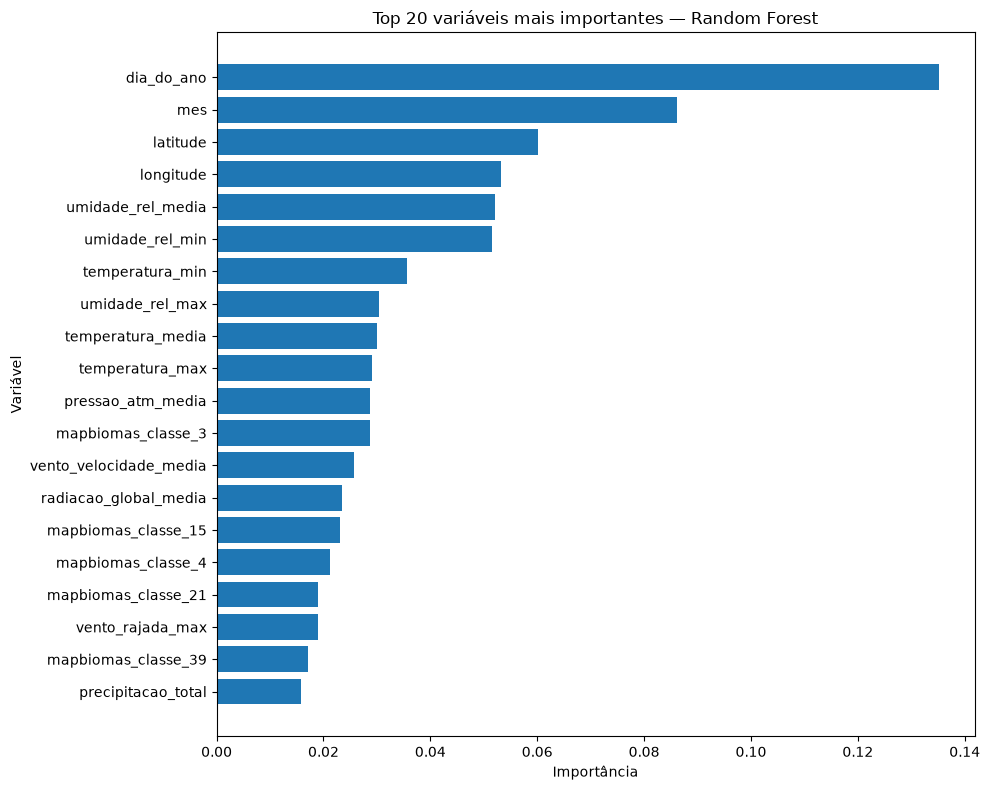

In [ ]:
import matplotlib.pyplot as plt

# Selecionar as 20 variáveis mais importantes
top20 = (
    importancia_features
    .head(20)
    .sort_values("importancia", ascending=True)
)

plt.figure(figsize=(10, 8))

plt.barh(
    top20["feature"],
    top20["importancia"]
)

plt.xlabel("Importância")
plt.ylabel("Variável")

plt.title(
    "Top 20 variáveis mais importantes — Random Forest"
)

plt.tight_layout()

plt.show()

### Interpretação da importância das variáveis

A análise de importância das variáveis mostra que os componentes temporais tiveram forte participação nas previsões do Random Forest. `dia_do_ano` foi a variável individual mais importante, seguida por `mes`, indicando uma forte relação entre a sazonalidade e a classificação do risco de incêndio.

As variáveis geográficas `latitude` e `longitude` também apresentaram importância relevante, sugerindo que os padrões de risco variam espacialmente entre diferentes regiões do Brasil.

Entre as variáveis meteorológicas, destacaram-se principalmente a umidade relativa do ar e a temperatura. A umidade relativa média e mínima aparecem entre as variáveis mais importantes, acompanhadas pelas temperaturas mínima, média e máxima. Pressão atmosférica, velocidade do vento, radiação solar, rajadas de vento e precipitação também contribuíram para as previsões.

Além das condições temporais, espaciais e meteorológicas, diferentes classes de cobertura e uso da terra provenientes do MapBiomas aparecem entre as principais variáveis utilizadas pelo modelo.

Esses resultados mostram que o modelo combina informações sazonais, geográficas, meteorológicas e ambientais para realizar a classificação. Entretanto, as importâncias do Random Forest representam a contribuição das variáveis para as decisões do modelo e não devem ser interpretadas como relações causais.

In [ ]:
# ============================================================
# VALIDAÇÃO TEMPORAL
# Treino: até 30/11/2024
# Teste: 01/12/2024 a 12/02/2025
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Recuperar as datas da base de modelagem
datas_modelo = dados_modelo["data"].copy()

# Definir corte temporal
data_corte = pd.Timestamp("2024-12-01")

mascara_treino = datas_modelo < data_corte
mascara_teste = datas_modelo >= data_corte

# Criar conjuntos temporais
X_train_temporal = X.loc[mascara_treino].copy()
X_test_temporal = X.loc[mascara_teste].copy()

y_train_temporal = y.loc[mascara_treino].copy()
y_test_temporal = y.loc[mascara_teste].copy()

print("DIVISÃO TEMPORAL")
print("=" * 65)

print(
    f"Treino: {len(X_train_temporal):,} observações"
)

print(
    f"Teste: {len(X_test_temporal):,} observações"
)

print(
    f"\nPeríodo de treino: "
    f"{datas_modelo[mascara_treino].min().date()} "
    f"até "
    f"{datas_modelo[mascara_treino].max().date()}"
)

print(
    f"Período de teste: "
    f"{datas_modelo[mascara_teste].min().date()} "
    f"até "
    f"{datas_modelo[mascara_teste].max().date()}"
)


# ============================================================
# Recriar pré-processador usando somente o treino temporal
# ============================================================

colunas_numericas_temporal = (
    X_train_temporal
    .select_dtypes(include=["number"])
    .columns
    .tolist()
)

colunas_categoricas_temporal = (
    X_train_temporal
    .select_dtypes(
        include=["object", "string", "category"]
    )
    .columns
    .tolist()
)

pipeline_numerico_temporal = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        )
    ]
)

pipeline_categorico_temporal = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessador_temporal = ColumnTransformer(
    transformers=[
        (
            "numerico",
            pipeline_numerico_temporal,
            colunas_numericas_temporal
        ),
        (
            "categorico",
            pipeline_categorico_temporal,
            colunas_categoricas_temporal
        )
    ]
)


# ============================================================
# Random Forest para validação temporal
# ============================================================

modelo_rf_temporal = Pipeline(
    steps=[
        (
            "preprocessador",
            preprocessador_temporal
        ),
        (
            "modelo",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=20,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=12345,
                n_jobs=-1
            )
        )
    ]
)

print("\nTreinando modelo temporal...")

modelo_rf_temporal.fit(
    X_train_temporal,
    y_train_temporal
)

pred_temporal = modelo_rf_temporal.predict(
    X_test_temporal
)


# ============================================================
# Avaliação
# ============================================================

accuracy_temporal = accuracy_score(
    y_test_temporal,
    pred_temporal
)

balanced_temporal = balanced_accuracy_score(
    y_test_temporal,
    pred_temporal
)

f1_temporal = f1_score(
    y_test_temporal,
    pred_temporal,
    average="macro"
)

print("\nRESULTADOS — VALIDAÇÃO TEMPORAL")
print("=" * 65)

print(
    f"Accuracy:          "
    f"{accuracy_temporal:.4f}"
)

print(
    f"Balanced Accuracy: "
    f"{balanced_temporal:.4f}"
)

print(
    f"F1 Macro:          "
    f"{f1_temporal:.4f}"
)

print("\nRELATÓRIO POR CLASSE")
print("=" * 65)

print(
    classification_report(
        y_test_temporal,
        pred_temporal,
        digits=4,
        zero_division=0
    )
)


DIVISÃO TEMPORAL
Treino: 263,665 observações
Teste: 45,326 observações

Período de treino: 2024-01-01 até 2024-11-29
Período de teste: 2024-12-01 até 2025-02-12

Treinando modelo temporal...

RESULTADOS — VALIDAÇÃO TEMPORAL
Accuracy:          0.6989
Balanced Accuracy: 0.5541
F1 Macro:          0.5515

RELATÓRIO POR CLASSE
              precision    recall  f1-score   support

        Alto     0.8051    0.7261    0.7635     22519
       Baixo     0.7070    0.7958    0.7488     18502
       Médio     0.1442    0.1403    0.1422      4305

    accuracy                         0.6989     45326
   macro avg     0.5521    0.5541    0.5515     45326
weighted avg     0.7023    0.6989    0.6985     45326



### Interpretação da validação temporal

A validação temporal foi realizada utilizando observações anteriores a **1º de dezembro de 2024** para treinamento e observações entre **1º de dezembro de 2024 e 12 de fevereiro de 2025** para teste. Dessa forma, o modelo é avaliado em um cenário mais próximo de uma aplicação real, no qual dados do passado são utilizados para realizar previsões sobre períodos posteriores.

Nesse cenário, o Random Forest apresentou **accuracy de 0,6989**, **Balanced Accuracy de 0,5541** e **F1 Macro de 0,5515**. Esses resultados são inferiores aos obtidos na divisão de treino e teste por município, indicando que a generalização para um período futuro é mais difícil.

A análise por classe mostra que o modelo manteve desempenho relativamente melhor nas classes **Alto** e **Baixo**, com F1-score de **0,7635** e **0,7488**, respectivamente. A principal dificuldade ocorreu na classe **Médio**, que apresentou precision de **0,1442**, recall de **0,1403** e F1-score de **0,1422**.

A redução de desempenho na validação temporal sugere a presença de mudanças na distribuição dos dados ao longo do tempo, como variações sazonais nas condições meteorológicas e no padrão de risco de incêndio. Esse resultado reforça a importância de avaliar o modelo não apenas por meio de uma única divisão dos dados.

A validação temporal deve, portanto, ser interpretada como um teste adicional de robustez. Em uma aplicação operacional, seria recomendável monitorar continuamente o desempenho do modelo e realizar novos treinamentos à medida que dados mais recentes se tornem disponíveis.

In [ ]:
# ============================================================
# RESUMO FINAL DOS RESULTADOS DOS MODELOS
# ============================================================

resumo_modelos = pd.DataFrame({
    "Modelo": [
        "Dummy Classifier",
        "Regressão Logística",
        "Random Forest",
        "Random Forest Ajustado",
        "Random Forest + Optuna",
        "XGBoost",
        "Random Forest - Validação Temporal"
    ],

    "Accuracy": [
        accuracy_baseline,
        accuracy_logistico,
        accuracy_random_forest,
        accuracy_rf_ajustado,
        accuracy_rf_optuna,
        accuracy_xgboost,
        accuracy_temporal
    ],

    "Balanced Accuracy": [
        balanced_accuracy_baseline,
        balanced_accuracy_logistico,
        balanced_accuracy_random_forest,
        balanced_accuracy_rf_ajustado,
        balanced_accuracy_rf_optuna,
        balanced_accuracy_xgboost,
        balanced_temporal
    ],

    "F1 Macro": [
        f1_macro_baseline,
        f1_macro_logistico,
        f1_macro_random_forest,
        f1_macro_rf_ajustado,
        f1_macro_rf_optuna,
        f1_macro_xgboost,
        f1_temporal
    ]
})

print("RESUMO FINAL DOS RESULTADOS")
print("=" * 70)

display(
    resumo_modelos.round(4)
)

RESUMO FINAL DOS RESULTADOS


,Modelo,Accuracy,Balanced Accuracy,F1 Macro
0,Dummy Classifier,0.6536,0.3333,0.2635
1,Regressão Logística,0.6717,0.5917,0.5530
2,Random Forest,0.8229,0.7013,0.6767
3,Random Forest Ajustado,0.8317,0.6967,0.6784
4,Random Forest + Optuna,0.8329,0.7171,0.6908
5,XGBoost,0.8694,0.6324,0.6233
6,Random Forest - Validação Temporal,0.6989,0.5541,0.5515


## Avaliação de impacto financeiro e plano de teste A/B

Além das métricas técnicas, é importante avaliar se a utilização do modelo pode gerar valor em um cenário operacional.

Neste projeto, não estão disponíveis dados reais sobre custos de mobilização de equipes, inspeções, deslocamentos ou prejuízos evitados por incêndios. Portanto, não é adequado afirmar uma economia financeira real com base apenas nos dados analisados.

Em vez disso, será construída uma simulação de impacto financeiro baseada em parâmetros explícitos. A ideia é comparar dois cenários:

- **Cenário atual (sem modelo):** decisões de priorização são realizadas sem utilizar a classificação produzida pelo modelo;
- **Cenário com modelo:** municípios-dias classificados como risco Alto podem receber prioridade para monitoramento ou ações preventivas.

O impacto financeiro potencial pode ser representado pela diferença entre o custo operacional das ações realizadas e o benefício estimado de identificar corretamente situações de alto risco.

Os valores utilizados a seguir devem ser interpretados como **parâmetros de simulação**, e não como custos reais observados. Em uma aplicação real, esses parâmetros deveriam ser substituídos por dados fornecidos pela organização responsável pela operação.


In [ ]:
# ============================================================
# SIMULAÇÃO DE IMPACTO FINANCEIRO
# MODELO DE REFERÊNCIA: RANDOM FOREST + OPTUNA
# ============================================================

# Parâmetros hipotéticos da simulação
# Em uma aplicação real, estes valores devem ser substituídos
# pelos custos reais da organização responsável.

custo_acao_preventiva = 1000
custo_alto_risco_nao_identificado = 10000

# ------------------------------------------------------------
# Matriz de confusão do modelo selecionado
# Classe de interesse: "Alto"
# ------------------------------------------------------------

y_real_alto = (y_test == "Alto")
y_pred_alto = (y_pred_rf_optuna == "Alto")

tp = ((y_real_alto) & (y_pred_alto)).sum()
fn = ((y_real_alto) & (~y_pred_alto)).sum()
fp = ((~y_real_alto) & (y_pred_alto)).sum()
tn = ((~y_real_alto) & (~y_pred_alto)).sum()

# ------------------------------------------------------------
# Custos simulados
# ------------------------------------------------------------

custo_acoes_modelo = (
    (tp + fp) * custo_acao_preventiva
)

custo_falhas_modelo = (
    fn * custo_alto_risco_nao_identificado
)

custo_total_modelo = (
    custo_acoes_modelo + custo_falhas_modelo
)

# ------------------------------------------------------------
# Cenário de referência
# ------------------------------------------------------------
# Nenhuma situação recebe priorização preventiva pelo modelo.
# Assim, todos os casos reais de risco Alto representam
# situações de alto risco não identificadas previamente.

total_alto_real = tp + fn

custo_cenario_referencia = (
    total_alto_real
    * custo_alto_risco_nao_identificado
)

impacto_financeiro_estimado = (
    custo_cenario_referencia
    - custo_total_modelo
)

reducao_percentual_estimada = (
    impacto_financeiro_estimado
    / custo_cenario_referencia
    * 100
)

# ------------------------------------------------------------
# Resultados
# ------------------------------------------------------------

print("SIMULAÇÃO DE IMPACTO FINANCEIRO")
print("=" * 65)

print("Modelo de referência: Random Forest + Optuna")

print(
    f"\nVerdadeiros positivos (Alto): "
    f"{tp:,}"
)

print(
    f"Falsos negativos (Alto): "
    f"{fn:,}"
)

print(
    f"Falsos positivos (Alto): "
    f"{fp:,}"
)

print(
    f"\nCusto do cenário de referência: "
    f"R$ {custo_cenario_referencia:,.2f}"
)

print(
    f"Custo do cenário com modelo: "
    f"R$ {custo_total_modelo:,.2f}"
)

print(
    f"Impacto financeiro potencial: "
    f"R$ {impacto_financeiro_estimado:,.2f}"
)

print(
    f"Redução potencial de custo: "
    f"{reducao_percentual_estimada:.2f}%"
)

SIMULAÇÃO DE IMPACTO FINANCEIRO
Modelo de referência: Random Forest + Optuna

Verdadeiros positivos (Alto): 36,347
Falsos negativos (Alto): 5,567
Falsos positivos (Alto): 1,723

Custo do cenário de referência: R$ 419,140,000.00
Custo do cenário com modelo: R$ 93,740,000.00
Impacto financeiro potencial: R$ 325,400,000.00
Redução potencial de custo: 77.64%


### Interpretação da simulação financeira

No cenário hipotético definido acima, o modelo de referência **Random Forest + Optuna** identificou corretamente **36.347 casos de risco Alto**, deixou de identificar **5.567 casos de risco Alto** e classificou incorretamente **1.723 observações de outras classes como Alto**.

Considerando, apenas para fins de simulação, um custo de **R$ 1.000 por ação preventiva** e um custo de **R$ 10.000 para cada situação de risco Alto não identificada**, o cenário de referência sem priorização apoiada pelo modelo apresentaria um custo estimado de **R$ 419,14 milhões**, enquanto o cenário apoiado pelo modelo apresentaria um custo estimado de **R$ 93,74 milhões**.

Nesse conjunto específico de premissas, isso corresponderia a um impacto financeiro potencial de aproximadamente **R$ 325,40 milhões**, ou **77,64% de redução do custo simulado**.

Esses valores **não representam economia financeira real nem uma estimativa dos custos reais de incêndios no Brasil**. O objetivo desta análise é demonstrar como as métricas do modelo podem ser convertidas em uma estrutura de decisão econômica. Em uma aplicação real, os parâmetros da simulação deveriam ser substituídos por custos operacionais, custos de mobilização e impactos financeiros efetivamente observados pela organização responsável.

### Plano de teste A/B para avaliação operacional

Antes de utilizar o modelo em larga escala, uma forma de avaliar seu impacto real seria realizar um teste A/B controlado em uma operação de monitoramento.

Para reduzir o risco de contaminação entre os grupos, a unidade experimental proposta seria o **município**, e não cada observação município-dia. Dessa forma, todas as observações de um mesmo município permaneceriam no mesmo grupo durante o período do experimento.

Os municípios participantes seriam distribuídos entre dois grupos:

- **Grupo A — Controle:** mantém o processo atual de priorização e monitoramento, sem utilizar a classificação produzida pelo modelo;
- **Grupo B — Tratamento:** utiliza a classificação do modelo como informação adicional para priorizar situações classificadas como risco Alto dentro dos municípios participantes.

A distribuição dos municípios entre os grupos deve ser realizada de forma aleatória e, sempre que possível, estratificada por características relevantes, como região, bioma, histórico de risco e volume de observações. O objetivo é reduzir diferenças estruturais entre os grupos antes do início do experimento.

#### Hipótese do experimento

- **H0:** a utilização do modelo não melhora os indicadores operacionais em relação ao processo atual.
- **H1:** a utilização do modelo melhora os indicadores operacionais em relação ao processo atual.

#### Métrica principal

A principal métrica operacional proposta é a **taxa de identificação de situações de risco Alto**, comparando a capacidade dos grupos Controle e Tratamento de identificar corretamente essas situações durante o período de avaliação.

Também podem ser acompanhadas métricas secundárias, como:

- custo operacional por situação de alto risco identificada;
- quantidade de ações preventivas realizadas;
- proporção de ações direcionadas a situações que posteriormente não foram confirmadas como risco Alto;
- tempo médio entre a identificação do risco e a ação operacional;
- custo operacional total por município durante o período avaliado.

#### Avaliação

O experimento deve ser executado durante um período suficiente para incluir diferentes condições meteorológicas e níveis de risco. Como a randomização seria realizada por município, a análise estatística também deve considerar essa estrutura agrupada, evitando tratar observações repetidas do mesmo município como completamente independentes.

Ao final, as métricas dos grupos Controle e Tratamento devem ser comparadas utilizando testes estatísticos e intervalos de confiança adequados ao desenho experimental. Além da significância estatística, deve ser considerada a relevância operacional da diferença observada.

A adoção definitiva do modelo deveria ocorrer somente se o Grupo B apresentar melhoria estatisticamente significativa e operacionalmente relevante, sem produzir aumento desproporcional de custos, falsos alertas ou ações preventivas desnecessárias.

Este plano representa uma proposta de validação operacional. O teste A/B não foi executado neste projeto, pois não há acesso a uma operação real de prevenção ou monitoramento na qual seja possível aplicar intervenções controladas.

## Conclusão

Neste projeto, desenvolvi uma pipeline de Machine Learning para classificar o risco de incêndio no Brasil em três níveis: **Baixo, Médio e Alto**. Para isso, integrei informações de diferentes fontes, combinando registros de queimadas, dados meteorológicos do INMET, informações geográficas e dados de cobertura e uso da terra do MapBiomas.

Uma das etapas mais desafiadoras foi a preparação e integração dos dados. As bases apresentavam diferentes níveis de granularidade, períodos de cobertura distintos, valores ausentes e particularidades nos arquivos meteorológicos. Para ampliar a cobertura meteorológica, cada município foi associado à estação do INMET disponível mais próxima. Essa estratégia permitiu integrar as informações meteorológicas à base de modelagem, embora a distância até a estação permaneça como uma limitação em regiões com menor cobertura.

Também foi necessário tratar cuidadosamente a variável alvo. O risco diário foi construído a partir do valor máximo de `risco_fogo` observado para cada município e dia, adotando uma abordagem conservadora em que prevalece o maior nível de risco registrado naquele período.

Na etapa de modelagem, foram comparados Dummy Classifier, Regressão Logística, diferentes configurações de Random Forest e XGBoost. Além disso, foi realizada uma busca de hiperparâmetros com Optuna para o Random Forest. Como a variável alvo apresenta desbalanceamento entre as classes, a seleção do modelo não foi baseada apenas em Accuracy. Foram priorizadas principalmente **Balanced Accuracy** e **F1 Macro**, além das métricas individuais de cada classe.

Um ponto importante da metodologia foi a utilização de uma **divisão de treino e teste por município**. Todas as observações de um mesmo município permanecem exclusivamente no treino ou no teste. Essa estratégia reduz o risco de vazamento de informação causado pela presença do mesmo município nos dois conjuntos, especialmente porque algumas características geográficas e ambientais permanecem constantes ou semelhantes ao longo dos dias.

Na avaliação com separação por município, o **Random Forest otimizado com Optuna** apresentou **Accuracy de 0,8329, Balanced Accuracy de 0,7171 e F1 Macro de 0,6908**. O XGBoost apresentou Accuracy superior, de **0,8694**, porém Balanced Accuracy de **0,6324** e F1 Macro de **0,6233**. A principal dificuldade do XGBoost ocorreu na classe Médio, cujo recall foi de apenas **0,0549**. Por esse motivo, o **Random Forest + Optuna foi mantido como modelo de referência**, pois apresentou desempenho mais equilibrado entre as classes.

A validação temporal trouxe uma perspectiva adicional sobre a capacidade de generalização. Utilizando dados anteriores a dezembro de 2024 para treinamento e observações entre dezembro de 2024 e fevereiro de 2025 para teste, o modelo apresentou **Accuracy de 0,6989, Balanced Accuracy de 0,5541 e F1 Macro de 0,5515**. A redução de desempenho mostra que generalizar para períodos futuros é mais difícil e sugere que mudanças sazonais e temporais na distribuição dos dados devem ser consideradas em uma aplicação real.

A interpretação com SHAP mostrou que `dia_do_ano` possui forte participação nas previsões, seguida por características geográficas, como latitude e longitude, variáveis meteorológicas, especialmente relacionadas à umidade e temperatura, e diferentes classes de cobertura e uso da terra do MapBiomas. Esses resultados indicam que o modelo combina informações de sazonalidade, localização, condições meteorológicas e características ambientais para realizar suas classificações. As contribuições identificadas pelo SHAP devem ser interpretadas como explicações das previsões do modelo, e não como relações causais.

A análise de desempenho por **bioma e UF** também mostrou que os resultados não são homogêneos entre as diferentes regiões. A classe Médio permanece como a principal dificuldade do modelo, enquanto o recall da classe Alto apresenta variações importantes entre alguns estados e biomas. Essa heterogeneidade reforça a necessidade de monitoramento regional antes de qualquer utilização operacional.

Também foi realizada uma simulação de impacto financeiro utilizando parâmetros hipotéticos de custo. No cenário considerado, o modelo de referência apresentou um impacto financeiro potencial de **R$ 325,40 milhões**, correspondente a **77,64% de redução do custo simulado**. Esses valores não representam economia real, pois dependem diretamente dos parâmetros hipotéticos utilizados. A análise serve apenas para demonstrar como as previsões poderiam ser incorporadas a uma estrutura de decisão econômica. Como complemento, foi proposto um plano de teste A/B com randomização por município para avaliar o impacto operacional do modelo em um cenário real.

### Limitações

É importante destacar que a base de queimadas utilizada contém registros de eventos detectados. Portanto, o modelo desenvolvido neste projeto **não estima diretamente a probabilidade de ocorrer ou não um novo incêndio em qualquer município brasileiro**. A tarefa realizada consiste em prever a **categoria de risco de fogo derivada do indicador `risco_fogo` para observações município-dia presentes na base analisada**.

Essa distinção é importante porque um modelo de previsão da ocorrência de novos incêndios exigiria também exemplos de municípios e dias sem registros de focos, permitindo construir explicitamente uma classe de não ocorrência.

Outra limitação é que os dados do MapBiomas utilizados correspondem ao ano de 2021 e foram tratados como características ambientais estáticas para o período de 2024–2025. Além disso, a associação meteorológica utiliza a estação disponível mais próxima e, em algumas regiões com baixa densidade de estações, essa distância pode ser elevada.

A precipitação meteorológica também apresentou quantidade relevante de valores ausentes. Para evitar interpretar automaticamente ausência de medição como ausência de chuva, a agregação diária preserva como ausentes os dias com cobertura horária insuficiente. Na pipeline de Machine Learning, os valores numéricos ausentes são tratados utilizando imputação pela mediana calculada sobre os dados de treinamento, acompanhada de indicadores adicionais de ausência (`add_indicator=True`). Dessa forma, o modelo pode distinguir um valor originalmente observado de outro que precisou ser imputado.

Apesar da separação por município reduzir uma importante fonte de vazamento de informação, a validação temporal mostrou que o desempenho pode diminuir em períodos futuros. Portanto, os resultados obtidos não devem ser interpretados como garantia de desempenho constante ao longo do tempo.

Finalmente, as explicações produzidas pelo SHAP e as importâncias associadas às variáveis descrevem o comportamento do modelo, mas **não demonstram relações causais** entre essas características e a ocorrência de incêndios.

### Próximos passos

Como evolução deste trabalho, seria interessante construir uma base completa de municípios e dias, incluindo períodos sem focos de incêndio, permitindo transformar o problema em uma previsão direta da ocorrência de queimadas.

Também seria possível testar estratégias específicas para melhorar a identificação da classe Médio, explorar técnicas adicionais para dados desbalanceados, incorporar dados mais recentes de cobertura e uso da terra e avaliar modelos de boosting com otimização de hiperparâmetros.

Para uma aplicação operacional, o modelo deveria ser atualizado periodicamente com novos dados meteorológicos e ambientais, acompanhado por validações temporais recorrentes e monitoramento de desempenho por região e bioma. Antes de uma adoção em larga escala, o impacto operacional e financeiro também deveria ser validado com dados reais, preferencialmente por meio de um experimento controlado como o teste A/B proposto neste projeto.

In [ ]:
# ============================================================
# SALVAR RESULTADOS FINAIS DOS MODELOS
# ============================================================

caminho_resultados = (
    DATA_PROCESSED / "resultados_modelos.csv"
)

resumo_modelos.to_csv(
    caminho_resultados,
    index=False,
    encoding="utf-8-sig"
)

print(
    "Arquivo salvo com sucesso em:"
)

print(caminho_resultados)

Arquivo salvo com sucesso em:
c:\Users\Jroy\Documents\ProjetoFinalTripleTenBrazil\data\processed\resultados_modelos.csv


In [ ]:
# ============================================================
# SALVAR IMPORTÂNCIA DAS VARIÁVEIS
# ============================================================

caminho_importancias = (
    DATA_PROCESSED / "importancia_features.csv"
)

importancia_features.to_csv(
    caminho_importancias,
    index=False,
    encoding="utf-8-sig"
)

print("Arquivo salvo com sucesso em:")
print(caminho_importancias)

Arquivo salvo com sucesso em:
c:\Users\Jroy\Documents\ProjetoFinalTripleTenBrazil\data\processed\importancia_features.csv


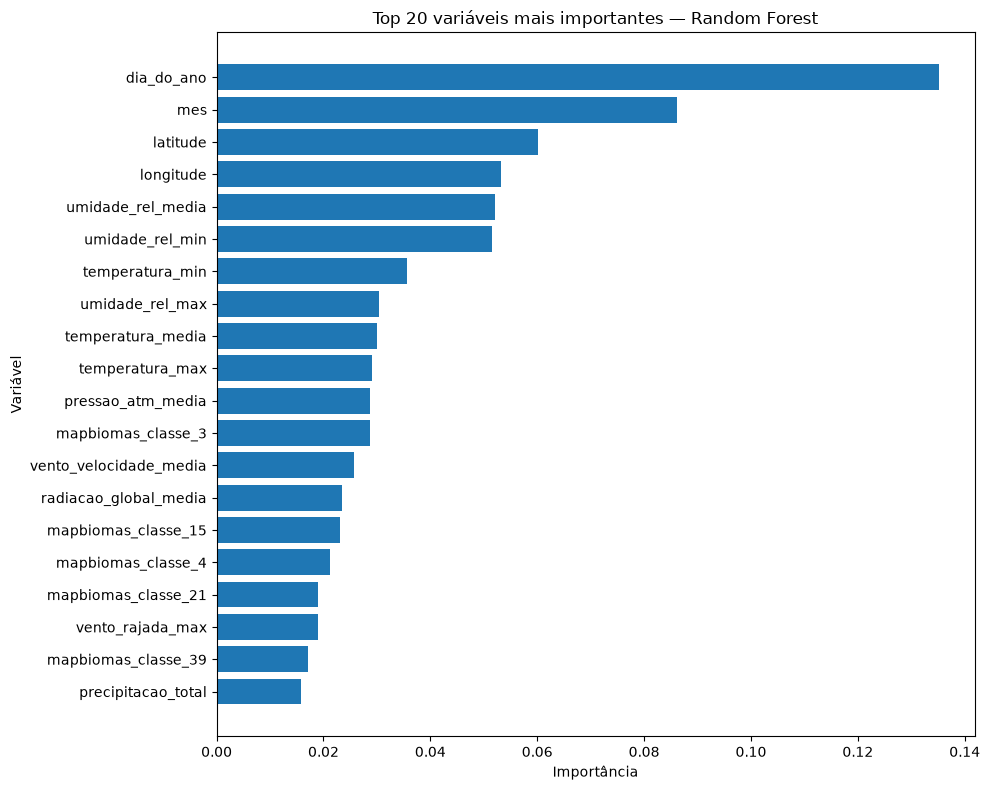

Gráfico salvo com sucesso em:
c:\Users\Jroy\Documents\ProjetoFinalTripleTenBrazil\figures\feature_importance_random_forest.png


In [ ]:
# ============================================================
# SALVAR GRÁFICO DE IMPORTÂNCIA DAS VARIÁVEIS
# ============================================================

FIGURES_DIR = PROJECT_ROOT / "figures"

# Garantir que a pasta existe
FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Selecionar Top 20
top20 = (
    importancia_features
    .head(20)
    .sort_values("importancia", ascending=True)
)

plt.figure(figsize=(10, 8))

plt.barh(
    top20["feature"],
    top20["importancia"]
)

plt.xlabel("Importância")
plt.ylabel("Variável")
plt.title(
    "Top 20 variáveis mais importantes — Random Forest"
)

plt.tight_layout()

# Caminho da imagem
caminho_figura = (
    FIGURES_DIR / "feature_importance_random_forest.png"
)

# Salvar em boa resolução
plt.savefig(
    caminho_figura,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico salvo com sucesso em:")
print(caminho_figura)

In [ ]:
# ============================================================
# SALVAR MODELO RANDOM FOREST TREINADO
# ============================================================

import joblib

MODELS_DIR = PROJECT_ROOT / "models"

MODELS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

caminho_modelo = (
    MODELS_DIR / "random_forest_risco_incendio.joblib"
)

joblib.dump(
    modelo_random_forest,
    caminho_modelo
)

print("Modelo salvo com sucesso em:")
print(caminho_modelo)

print(
    "\nTamanho do arquivo:",
    f"{caminho_modelo.stat().st_size / (1024**2):.2f} MB"
)

Modelo salvo com sucesso em:
c:\Users\Jroy\Documents\ProjetoFinalTripleTenBrazil\models\random_forest_risco_incendio.joblib

Tamanho do arquivo: 459.59 MB


### Interpretação da importância das variáveis

A análise de importância das variáveis mostra que os componentes temporais tiveram forte participação nas previsões do Random Forest. `dia_do_ano` foi a variável individual mais importante, seguida por `mes`, indicando uma forte relação entre a sazonalidade e a classificação do risco de incêndio.

As variáveis geográficas `latitude` e `longitude` também apresentaram importância relevante, sugerindo que os padrões de risco variam espacialmente entre diferentes regiões do Brasil.

Entre as variáveis meteorológicas, destacaram-se principalmente a umidade relativa do ar e a temperatura. A umidade relativa média e mínima aparecem entre as variáveis mais importantes, acompanhadas pelas temperaturas mínima, média e máxima. Pressão atmosférica, velocidade do vento, radiação solar, rajadas de vento e precipitação também contribuíram para as previsões.

Além das condições temporais, espaciais e meteorológicas, diferentes classes de cobertura e uso da terra provenientes do MapBiomas aparecem entre as principais variáveis utilizadas pelo modelo.

Esses resultados mostram que o modelo combina informações sazonais, geográficas, meteorológicas e ambientais para realizar a classificação. Entretanto, as importâncias do Random Forest representam a contribuição das variáveis para as decisões do modelo e não devem ser interpretadas como relações causais.

In [ ]:
# ============================================================
# RESUMO FINAL DOS RESULTADOS DOS MODELOS
# ============================================================

resumo_modelos = pd.DataFrame({
    "Modelo": [
        "Dummy Classifier",
        "Regressão Logística",
        "Random Forest",
        "Random Forest Ajustado",
        "Random Forest + Optuna",
        "XGBoost",
        "Random Forest - Validação Temporal"
    ],

    "Accuracy": [
        accuracy_baseline,
        accuracy_logistico,
        accuracy_random_forest,
        accuracy_rf_ajustado,
        accuracy_rf_optuna,
        accuracy_xgboost,
        accuracy_temporal
    ],

    "Balanced Accuracy": [
        balanced_accuracy_baseline,
        balanced_accuracy_logistico,
        balanced_accuracy_random_forest,
        balanced_accuracy_rf_ajustado,
        balanced_accuracy_rf_optuna,
        balanced_accuracy_xgboost,
        balanced_temporal
    ],

    "F1 Macro": [
        f1_macro_baseline,
        f1_macro_logistico,
        f1_macro_random_forest,
        f1_macro_rf_ajustado,
        f1_macro_rf_optuna,
        f1_macro_xgboost,
        f1_temporal
    ]
})

print("RESUMO FINAL DOS RESULTADOS")
print("=" * 70)

display(
    resumo_modelos.round(4)
)

RESUMO FINAL DOS RESULTADOS


,Modelo,Accuracy,Balanced Accuracy,F1 Macro
0,Dummy Classifier,0.6536,0.3333,0.2635
1,Regressão Logística,0.6717,0.5917,0.5530
2,Random Forest,0.8229,0.7013,0.6767
3,Random Forest Ajustado,0.8317,0.6967,0.6784
4,Random Forest + Optuna,0.8329,0.7171,0.6908
5,XGBoost,0.8694,0.6324,0.6233
6,Random Forest - Validação Temporal,0.6989,0.5541,0.5515


## Avaliação de impacto financeiro e plano de teste A/B

Além das métricas técnicas, é importante avaliar se a utilização do modelo pode gerar valor em um cenário operacional.

Neste projeto, não estão disponíveis dados reais sobre custos de mobilização de equipes, inspeções, deslocamentos ou prejuízos evitados por incêndios. Portanto, não é adequado afirmar uma economia financeira real com base apenas nos dados analisados.

Em vez disso, será construída uma simulação de impacto financeiro baseada em parâmetros explícitos. A ideia é comparar dois cenários:

- **Cenário atual (sem modelo):** decisões de priorização são realizadas sem utilizar a classificação produzida pelo modelo;
- **Cenário com modelo:** municípios-dias classificados como risco Alto podem receber prioridade para monitoramento ou ações preventivas.

O impacto financeiro potencial pode ser representado pela diferença entre o custo operacional das ações realizadas e o benefício estimado de identificar corretamente situações de alto risco.

Os valores utilizados a seguir devem ser interpretados como **parâmetros de simulação**, e não como custos reais observados. Em uma aplicação real, esses parâmetros deveriam ser substituídos por dados fornecidos pela organização responsável pela operação.


In [ ]:
# ============================================================
# SIMULAÇÃO DE IMPACTO FINANCEIRO
# ============================================================

# Parâmetros hipotéticos da simulação
# Em uma aplicação real, estes valores devem ser substituídos
# pelos custos reais da organização responsável.

custo_acao_preventiva = 1000       # R$ por ação preventiva
custo_alto_risco_nao_identificado = 10000  # R$ por caso de alto risco não identificado

# Matriz de confusão do modelo selecionado
# Classe de interesse: "Alto"

y_real_alto = (y_test == "Alto")
y_pred_alto = (y_pred_random_forest == "Alto")

tp = ((y_real_alto) & (y_pred_alto)).sum()
fn = ((y_real_alto) & (~y_pred_alto)).sum()
fp = ((~y_real_alto) & (y_pred_alto)).sum()
tn = ((~y_real_alto) & (~y_pred_alto)).sum()

# Custos simulados
custo_acoes_modelo = (tp + fp) * custo_acao_preventiva
custo_falhas_modelo = fn * custo_alto_risco_nao_identificado

custo_total_modelo = custo_acoes_modelo + custo_falhas_modelo

# Cenário de referência:
# nenhuma situação recebe priorização preventiva pelo modelo.
# Assim, todos os casos reais de risco Alto representam
# situações de alto risco não identificadas previamente.

total_alto_real = tp + fn

custo_cenario_referencia = (
    total_alto_real * custo_alto_risco_nao_identificado
)

impacto_financeiro_estimado = (
    custo_cenario_referencia - custo_total_modelo
)

reducao_percentual_estimada = (
    impacto_financeiro_estimado / custo_cenario_referencia * 100
)

print("=== SIMULAÇÃO DE IMPACTO FINANCEIRO ===")
print(f"Verdadeiros positivos (Alto): {tp:,}")
print(f"Falsos negativos (Alto): {fn:,}")
print(f"Falsos positivos (Alto): {fp:,}")
print()
print(f"Custo do cenário de referência: R$ {custo_cenario_referencia:,.2f}")
print(f"Custo do cenário com modelo: R$ {custo_total_modelo:,.2f}")
print(f"Impacto financeiro potencial: R$ {impacto_financeiro_estimado:,.2f}")
print(f"Redução potencial de custo: {reducao_percentual_estimada:.2f}%")

=== SIMULAÇÃO DE IMPACTO FINANCEIRO ===
Verdadeiros positivos (Alto): 35,908
Falsos negativos (Alto): 5,218
Falsos positivos (Alto): 1,420

Custo do cenário de referência: R$ 411,260,000.00
Custo do cenário com modelo: R$ 89,508,000.00
Impacto financeiro potencial: R$ 321,752,000.00
Redução potencial de custo: 78.24%


### Interpretação da simulação financeira

No cenário hipotético definido acima, o modelo identificou corretamente **35.908 casos de risco Alto**, deixou de identificar **5.218 casos** e classificou incorretamente **1.420 observações de outras classes como Alto**.

Considerando, apenas para fins de simulação, um custo de **R$ 1.000 por ação preventiva** e um custo de **R$ 10.000 para cada situação de risco Alto não identificada**, o cenário sem utilização do modelo apresentaria um custo estimado de **R$ 411,26 milhões**, enquanto o cenário apoiado pelo modelo apresentaria um custo estimado de **R$ 89,51 milhões**.

Nesse conjunto específico de premissas, isso corresponderia a um impacto financeiro potencial de aproximadamente **R$ 321,75 milhões**, ou **78,24% de redução do custo simulado**.

Esses valores **não representam economia financeira real nem uma estimativa dos custos reais de incêndios no Brasil**. O objetivo desta análise é demonstrar como as métricas do modelo podem ser convertidas em uma estrutura de decisão econômica. Em uma aplicação real, os parâmetros deveriam ser substituídos por custos operacionais e impactos financeiros observados pela organização responsável.

In [ ]:
# ============================================================
# SALVAR RESULTADOS FINAIS DOS MODELOS
# ============================================================

caminho_resultados = (
    DATA_PROCESSED / "resultados_modelos.csv"
)

resumo_modelos.to_csv(
    caminho_resultados,
    index=False,
    encoding="utf-8-sig"
)

print(
    "Arquivo salvo com sucesso em:"
)

print(caminho_resultados)

Arquivo salvo com sucesso em:
c:\Users\Jroy\Documents\ProjetoFinalTripleTenBrazil\data\processed\resultados_modelos.csv


In [ ]:
# ============================================================
# SALVAR IMPORTÂNCIA DAS VARIÁVEIS
# ============================================================

caminho_importancias = (
    DATA_PROCESSED / "importancia_features.csv"
)

importancia_features.to_csv(
    caminho_importancias,
    index=False,
    encoding="utf-8-sig"
)

print("Arquivo salvo com sucesso em:")
print(caminho_importancias)

Arquivo salvo com sucesso em:
c:\Users\Jroy\Documents\ProjetoFinalTripleTenBrazil\data\processed\importancia_features.csv


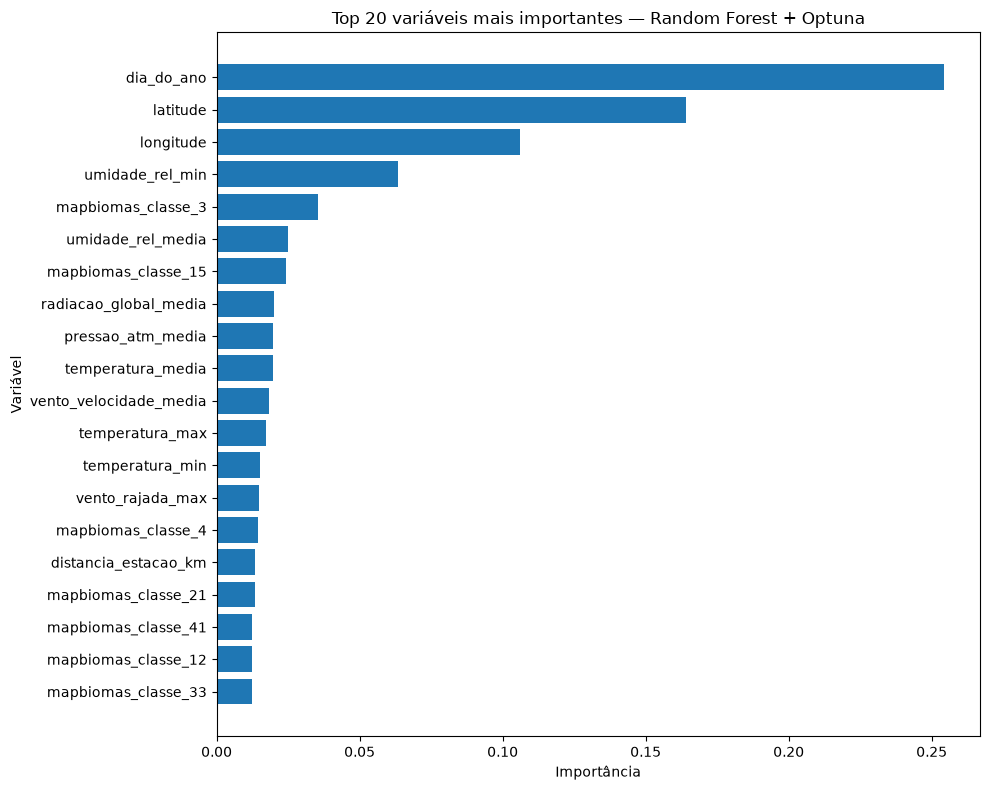

Gráfico salvo com sucesso em:
c:\Users\Jroy\Documents\ProjetoFinalTripleTenBrazil\figures\feature_importance_random_forest_optuna.png


In [ ]:
# ============================================================
# SALVAR GRÁFICO DE IMPORTÂNCIA DAS VARIÁVEIS
# RANDOM FOREST + OPTUNA
# ============================================================

FIGURES_DIR = PROJECT_ROOT / "figures"

# Garantir que a pasta existe
FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Selecionar Top 20
top20 = (
    importancia_features
    .head(20)
    .sort_values("importancia", ascending=True)
)

plt.figure(figsize=(10, 8))

plt.barh(
    top20["feature"],
    top20["importancia"]
)

plt.xlabel("Importância")
plt.ylabel("Variável")
plt.title(
    "Top 20 variáveis mais importantes — Random Forest + Optuna"
)

plt.tight_layout()

# Caminho da imagem
caminho_figura = (
    FIGURES_DIR / "feature_importance_random_forest_optuna.png"
)

# Salvar em boa resolução
plt.savefig(
    caminho_figura,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico salvo com sucesso em:")
print(caminho_figura)

In [ ]:
# ============================================================
# SALVAR MODELO FINAL — RANDOM FOREST + OPTUNA
# ============================================================

import joblib

MODELS_DIR = PROJECT_ROOT / "models"

MODELS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

caminho_modelo = (
    MODELS_DIR / "random_forest_optuna_risco_incendio.joblib"
)

joblib.dump(
    modelo_rf_optuna,
    caminho_modelo
)

print("Modelo final salvo com sucesso em:")
print(caminho_modelo)

print(
    "\nTamanho do arquivo:",
    f"{caminho_modelo.stat().st_size / (1024**2):.2f} MB"
)

Modelo final salvo com sucesso em:
c:\Users\Jroy\Documents\ProjetoFinalTripleTenBrazil\models\random_forest_optuna_risco_incendio.joblib

Tamanho do arquivo: 326.86 MB
